In [72]:
# ============================================================
# PART 1 — PHASE 1
# DATASET INSPECTION & ANNOTATION AUDIT
# ============================================================

import os
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

print("=" * 70)
print("PART 1 — COMPUTER VISION OBJECT DETECTION")
print("PHASE 1 — DATASET INSPECTION & ANNOTATION AUDIT")
print("=" * 70)


# ============================================================
# 1. PROJECT PATHS
# ============================================================

PROJECT_DIR = Path(
    r"C:\Material\Repo\Projects\Capstone_1"
)

PART1_DIR = PROJECT_DIR / "Part_1"

DATA_DIR = PART1_DIR / "model_training" / "data"

ANNOTATIONS_DIR = DATA_DIR / "annotations"

LABELS_PATH = ANNOTATIONS_DIR / "labels.csv"

IMAGES_ZIP = DATA_DIR / "raw" / "Images.zip"

EXTRACTED_IMAGES_DIR = DATA_DIR / "images"


print("\n--- PATHS ---")

print("Project directory:")
print(PROJECT_DIR)

print("\nPart 1 directory:")
print(PART1_DIR)

print("\nData directory:")
print(DATA_DIR)

print("\nAnnotations directory:")
print(ANNOTATIONS_DIR)

print("\nLabels file:")
print(LABELS_PATH)

print("\nImages ZIP:")
print(IMAGES_ZIP)


# ============================================================
# 2. VERIFY PATHS
# ============================================================

print("\n--- PATH VERIFICATION ---")

paths_to_check = {
    "Project directory": PROJECT_DIR,
    "Part 1 directory": PART1_DIR,
    "Data directory": DATA_DIR,
    "Annotations directory": ANNOTATIONS_DIR,
    "labels.csv": LABELS_PATH,
    "Images.zip": IMAGES_ZIP
}

for name, path in paths_to_check.items():

    print(
        f"{name}: "
        f"{'FOUND' if path.exists() else 'NOT FOUND'}"
    )


# ============================================================
# 3. STOP IF REQUIRED FILES ARE MISSING
# ============================================================

if not LABELS_PATH.exists():

    raise FileNotFoundError(
        f"\nlabels.csv was not found at:\n{LABELS_PATH}\n\n"
        "Check the actual Part_1 folder structure before continuing."
    )

if not IMAGES_ZIP.exists():

    raise FileNotFoundError(
        f"\nImages.zip was not found at:\n{IMAGES_ZIP}\n\n"
        "Check the actual Part_1 folder structure before continuing."
    )


# ============================================================
# 4. INSPECT ZIP CONTENTS
# ============================================================

print("\n" + "=" * 70)
print("IMAGE ZIP CONTENTS")
print("=" * 70)

with zipfile.ZipFile(IMAGES_ZIP, "r") as zip_ref:

    zip_members = zip_ref.namelist()

print("Total files/directories inside ZIP:", len(zip_members))

print("\nFirst 30 entries:")

for item in zip_members[:30]:
    print(item)


# ============================================================
# 5. IDENTIFY IMAGE FILES
# ============================================================

image_extensions = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}

zip_image_files = [
    item
    for item in zip_members
    if Path(item).suffix.lower() in image_extensions
]

print("\nTotal image files found inside ZIP:")
print(len(zip_image_files))

print("\nImage extension distribution:")

zip_extensions = pd.Series(
    [
        Path(item).suffix.lower()
        for item in zip_image_files
    ]
).value_counts()

display(zip_extensions.to_frame("Count"))


# ============================================================
# 6. LOAD LABELS.CSV
# ============================================================

print("\n" + "=" * 70)
print("ANNOTATION DATASET")
print("=" * 70)

labels_df = pd.read_csv(LABELS_PATH)

print(
    "\nlabels.csv shape:",
    labels_df.shape
)

print(
    "\nNumber of columns:",
    len(labels_df.columns)
)

print("\nColumn names:")

for i, column in enumerate(labels_df.columns):

    print(
        f"{i:02d}. {column}"
    )


# ============================================================
# 7. DISPLAY FIRST RECORDS
# ============================================================

print("\n--- FIRST 10 ANNOTATION RECORDS ---")

display(
    labels_df.head(10)
)


# ============================================================
# 8. DATA TYPES
# ============================================================

print("\n--- DATA TYPES ---")

display(
    labels_df.dtypes.to_frame(
        "dtype"
    )
)


# ============================================================
# 9. MISSING VALUES
# ============================================================

print("\n--- MISSING VALUES ---")

missing_summary = (
    labels_df.isna()
    .sum()
    .sort_values(
        ascending=False
    )
    .to_frame(
        "Missing_Values"
    )
)

missing_summary[
    "Missing_Percentage"
] = (
    missing_summary["Missing_Values"]
    / len(labels_df)
    * 100
)

display(
    missing_summary
)


# ============================================================
# 10. DUPLICATE RECORDS
# ============================================================

print("\n--- DUPLICATE RECORDS ---")

duplicate_count = labels_df.duplicated().sum()

print(
    "Duplicate rows:",
    duplicate_count
)


# ============================================================
# 11. NUMERIC COLUMN SUMMARY
# ============================================================

print("\n--- NUMERIC COLUMN SUMMARY ---")

numeric_columns = labels_df.select_dtypes(
    include=np.number
).columns.tolist()

print(
    "Numeric columns:",
    numeric_columns
)

if numeric_columns:

    display(
        labels_df[numeric_columns]
        .describe()
        .T
    )


# ============================================================
# 12. CATEGORICAL COLUMN INSPECTION
# ============================================================

print("\n" + "=" * 70)
print("CATEGORICAL COLUMN INSPECTION")
print("=" * 70)

categorical_columns = labels_df.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

print(
    "\nCategorical columns:",
    categorical_columns
)

for column in categorical_columns:

    print(
        "\n" + "-" * 60
    )

    print(
        f"Column: {column}"
    )

    print(
        "Unique values:",
        labels_df[column].nunique(
            dropna=False
        )
    )

    display(
        labels_df[column]
        .value_counts(
            dropna=False
        )
        .head(30)
        .to_frame("Count")
    )


# ============================================================
# 13. FIND POSSIBLE IMAGE IDENTIFIER COLUMN
# ============================================================

print("\n" + "=" * 70)
print("IMAGE IDENTIFIER AUDIT")
print("=" * 70)

possible_image_columns = []

for column in labels_df.columns:

    column_name = str(column).lower()

    if any(
        keyword in column_name
        for keyword in [
            "image",
            "filename",
            "file",
            "name",
            "path"
        ]
    ):

        possible_image_columns.append(
            column
        )

print(
    "Possible image identifier columns:"
)

for column in possible_image_columns:

    print(
        "-",
        column
    )


# ============================================================
# 14. FIND POSSIBLE CLASS/LABEL COLUMNS
# ============================================================

print("\n" + "=" * 70)
print("OBJECT CLASS / LABEL AUDIT")
print("=" * 70)

possible_label_columns = []

for column in labels_df.columns:

    column_name = str(column).lower()

    if any(
        keyword in column_name
        for keyword in [
            "class",
            "label",
            "category",
            "object",
            "type"
        ]
    ):

        possible_label_columns.append(
            column
        )

print(
    "Possible object/class columns:"
)

for column in possible_label_columns:

    print(
        "-",
        column
    )


# ============================================================
# 15. FIND POSSIBLE BOUNDING-BOX COLUMNS
# ============================================================

print("\n" + "=" * 70)
print("BOUNDING-BOX AUDIT")
print("=" * 70)

possible_bbox_columns = []

bbox_keywords = [
    "xmin",
    "xmax",
    "ymin",
    "ymax",
    "x_min",
    "x_max",
    "y_min",
    "y_max",
    "left",
    "right",
    "top",
    "bottom",
    "width",
    "height",
    "bbox",
    "box"
]

for column in labels_df.columns:

    column_name = str(column).lower()

    if any(
        keyword in column_name
        for keyword in bbox_keywords
    ):

        possible_bbox_columns.append(
            column
        )

print(
    "Possible bounding-box columns:"
)

for column in possible_bbox_columns:

    print(
        "-",
        column
    )


# ============================================================
# 16. IMAGE ↔ ANNOTATION CARDINALITY
# ============================================================

print("\n" + "=" * 70)
print("IMAGE ↔ ANNOTATION CARDINALITY")
print("=" * 70)

for column in possible_image_columns:

    unique_images = labels_df[
        column
    ].nunique(
        dropna=True
    )

    print(
        f"{column}: "
        f"{unique_images} unique image identifiers"
    )


# ============================================================
# 17. ANNOTATIONS PER IMAGE
# ============================================================

if possible_image_columns:

    image_column = possible_image_columns[0]

    annotations_per_image = (
        labels_df
        .groupby(image_column)
        .size()
    )

    print(
        "\nUsing image identifier candidate:",
        image_column
    )

    print(
        "\nAnnotations per image:"
    )

    display(
        annotations_per_image
        .describe()
        .to_frame("Value")
    )

    print(
        "\nImages with multiple annotations:",
        (
            annotations_per_image > 1
        ).sum()
    )

    print(
        "Images with exactly one annotation:",
        (
            annotations_per_image == 1
        ).sum()
    )


# ============================================================
# 18. FINAL PHASE 1 AUDIT REPORT
# ============================================================

print("\n" + "=" * 70)
print("PHASE 1 INITIAL AUDIT COMPLETE")
print("=" * 70)

print(
    "\nImages in ZIP:",
    len(zip_image_files)
)

print(
    "Annotation records:",
    len(labels_df)
)

print(
    "Annotation columns:",
    len(labels_df.columns)
)

print(
    "Duplicate annotation rows:",
    duplicate_count
)

print(
    "\nPossible image columns:",
    possible_image_columns
)

print(
    "Possible class/label columns:",
    possible_label_columns
)

print(
    "Possible bounding-box columns:",
    possible_bbox_columns
)

print("=" * 70)

PART 1 — COMPUTER VISION OBJECT DETECTION
PHASE 1 — DATASET INSPECTION & ANNOTATION AUDIT

--- PATHS ---
Project directory:
C:\Material\Repo\Projects\Capstone_1

Part 1 directory:
C:\Material\Repo\Projects\Capstone_1\Part_1

Data directory:
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data

Annotations directory:
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\annotations

Labels file:
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\annotations\labels.csv

Images ZIP:
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\raw\Images.zip

--- PATH VERIFICATION ---
Project directory: FOUND
Part 1 directory: FOUND
Data directory: FOUND
Annotations directory: FOUND
labels.csv: FOUND
Images.zip: FOUND

IMAGE ZIP CONTENTS
Total files/directories inside ZIP: 5627

First 30 entries:
Images/
Images/00000000.jpg
Images/00000001.jpg
Images/00000002.jpg
Images/00000003.jpg
Images/00000004.jpg
Images/00000005.jpg
Images/00000006.jpg
Images/0000

,Count
.jpg,5626



ANNOTATION DATASET

labels.csv shape: (351548, 6)

Number of columns: 6

Column names:
00. 00000000
01. pickup_truck
02. 213
03. 34
04. 255
05. 50

--- FIRST 10 ANNOTATION RECORDS ---


,00000000,pickup_truck,213,34,255,50
0,0,car,194,78,273,122
1,0,car,155,27,183,35
2,0,articulated_truck,43,25,109,55
3,0,car,106,32,124,45
4,1,bus,205,155,568,314
5,1,bus,285,123,477,168
6,1,car,544,162,617,193
7,1,car,329,152,371,163
8,1,car,447,161,497,183
9,1,car,662,199,715,236



--- DATA TYPES ---


,dtype
00000000,int64
pickup_truck,str
213,int64
34,int64
255,int64
50,int64


... (3 outputs left out)

,count,mean,std,min,25%,50%,75%,max
00000000,351548.0,55248.742664,31911.160406,0.0,27630.75,55209.0,82833.0,110592.0
213,351548.0,298.953312,206.029740,0.0,119.00,265.0,486.0,706.0
34,351548.0,120.903274,78.892045,0.0,56.00,109.0,166.0,471.0
255,351548.0,386.255294,209.091223,6.0,209.00,373.0,574.0,719.0
50,351548.0,176.112679,112.192674,5.0,88.00,155.0,229.0,479.0



CATEGORICAL COLUMN INSPECTION

Categorical columns: ['pickup_truck']

------------------------------------------------------------
Column: pickup_truck
Unique values: 11


,Count
pickup_truck,
car,233497
pickup_truck,44282
motorized_vehicle,25845
bus,10598
articulated_truck,9301
work_van,8709
pedestrian,7128
single_unit_truck,5741
non-motorized_vehicle,2350



IMAGE IDENTIFIER AUDIT
Possible image identifier columns:

OBJECT CLASS / LABEL AUDIT
Possible object/class columns:

BOUNDING-BOX AUDIT
Possible bounding-box columns:

IMAGE ↔ ANNOTATION CARDINALITY

PHASE 1 INITIAL AUDIT COMPLETE

Images in ZIP: 5626
Annotation records: 351548
Annotation columns: 6
Duplicate annotation rows: 0

Possible image columns: []
Possible class/label columns: []
Possible bounding-box columns: []


PART 1 — PHASE 1.1
CORRECT ANNOTATION LOADING & BOUNDING-BOX AUDIT

--- Loading annotation file ---
Corrected labels shape: (351549, 6)

--- Annotation columns ---
['image_id', 'class', 'xmin', 'ymin', 'xmax', 'ymax']

--- First 10 annotations ---


,image_id,class,xmin,ymin,xmax,ymax
0,0,pickup_truck,213,34,255,50
1,0,car,194,78,273,122
2,0,car,155,27,183,35
3,0,articulated_truck,43,25,109,55
4,0,car,106,32,124,45
5,1,bus,205,155,568,314
6,1,bus,285,123,477,168
7,1,car,544,162,617,193
8,1,car,329,152,371,163
9,1,car,447,161,497,183



--- Data types ---


,dtype
image_id,int64
class,str
xmin,int64
ymin,int64
xmax,int64
ymax,int64



--- Missing values ---


,Missing,Percentage
image_id,0,0.0
class,0,0.0
xmin,0,0.0
ymin,0,0.0
xmax,0,0.0
ymax,0,0.0



--- Duplicate annotations ---
Duplicate rows: 0

OBJECT CLASS DISTRIBUTION


,Class,Annotations,Percentage
0,car,233497,66.419475
1,pickup_truck,44283,12.596537
2,motorized_vehicle,25845,7.351749
3,bus,10598,3.014658
4,articulated_truck,9301,2.645719
5,work_van,8709,2.477322
6,pedestrian,7128,2.027598
7,single_unit_truck,5741,1.633058
8,non-motorized_vehicle,2350,0.668470
9,bicycle,2260,0.642869


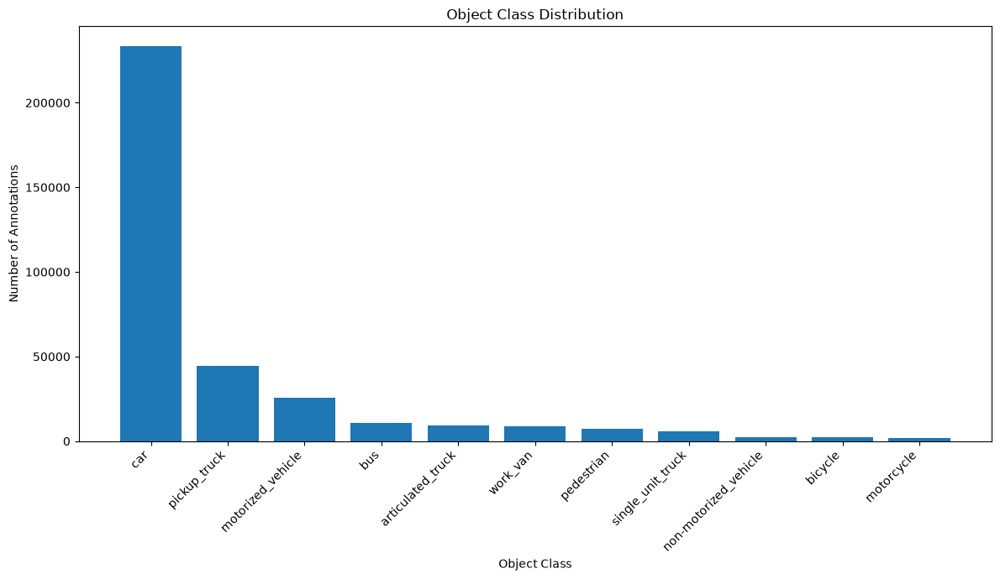


IMAGE / ANNOTATION RELATIONSHIP
Unique image IDs in annotations: 110000
Images found in ZIP: 5626
Images without annotation records: -104374

--- Annotations per image ---


,Annotations_Per_Image
count,110000.000000
mean,3.195900
std,2.927376
min,1.000000
25%,1.000000
50%,2.000000
75%,4.000000
max,34.000000



Images with one object: 34123
Images with multiple objects: 75877
Maximum objects in one image: 34

--- Images with the most annotations ---


,image_id,Object_Count
0,22157,34
1,93313,33
2,39024,32
3,76332,32
4,79177,31
5,11663,31
6,101372,30
7,50146,30
8,95225,29
9,82022,29



BOUNDING-BOX VALIDATION

Bounding-box statistics:


,count,mean,std,min,25%,50%,75%,max
xmin,351549.0,298.953068,206.029498,0.0,119.0,265.0,486.0,706.0
ymin,351549.0,120.903026,78.892069,0.0,56.0,109.0,166.0,471.0
xmax,351549.0,386.254920,209.091043,6.0,209.0,373.0,574.0,719.0
ymax,351549.0,176.112320,112.192716,5.0,88.0,155.0,229.0,479.0



Boxes where xmax <= xmin: 4
Boxes where ymax <= ymin: 1
Boxes containing negative coordinates: 0
Total potentially invalid boxes: 5

--- Bounding-box dimensions ---


,count,mean,std,min,25%,50%,75%,max
bbox_width,351549.0,87.301853,82.406655,0.0,34.0,56.0,111.0,719.0
bbox_height,351549.0,55.209294,52.336099,0.0,21.0,36.0,72.0,479.0



--- Bounding-box area ---


,BBox_Area
count,351549.000000
mean,8586.202930
std,18555.580862
min,0.000000
25%,714.000000
50%,1947.000000
75%,7560.000000
max,335104.000000



PHASE 1.1 COMPLETE

Total annotation records: 351549
Unique images with annotations: 110000
Unique object classes: 11
Duplicate rows: 0
Potentially invalid bounding boxes: 5

Object classes:
 - pickup_truck
 - car
 - articulated_truck
 - bus
 - motorized_vehicle
 - work_van
 - single_unit_truck
 - pedestrian
 - bicycle
 - non-motorized_vehicle
 - motorcycle



In [73]:
# ============================================================
# PART 1 — PHASE 1.1
# CORRECT ANNOTATION LOADING & BOUNDING-BOX AUDIT
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
import zipfile
import io

print("=" * 70)
print("PART 1 — PHASE 1.1")
print("CORRECT ANNOTATION LOADING & BOUNDING-BOX AUDIT")
print("=" * 70)


# ============================================================
# 1. PATHS
# ============================================================

PROJECT_DIR = Path(
    r"C:\Material\Repo\Projects\Capstone_1"
)

DATA_DIR = (
    PROJECT_DIR
    / "Part_1"
    / "model_training"
    / "data"
)

LABELS_PATH = (
    DATA_DIR
    / "annotations"
    / "labels.csv"
)

IMAGES_ZIP = (
    DATA_DIR
    / "raw"
    / "Images.zip"
)


# ============================================================
# 2. LOAD CSV CORRECTLY
# ============================================================

print("\n--- Loading annotation file ---")

labels_df = pd.read_csv(
    LABELS_PATH,
    header=None,
    names=[
        "image_id",
        "class",
        "xmin",
        "ymin",
        "xmax",
        "ymax"
    ]
)

print(
    "Corrected labels shape:",
    labels_df.shape
)


# ============================================================
# 3. BASIC STRUCTURE
# ============================================================

print("\n--- Annotation columns ---")

print(
    labels_df.columns.tolist()
)

print("\n--- First 10 annotations ---")

display(
    labels_df.head(10)
)


# ============================================================
# 4. DATA TYPES
# ============================================================

print("\n--- Data types ---")

display(
    labels_df.dtypes.to_frame("dtype")
)


# ============================================================
# 5. MISSING VALUES
# ============================================================

print("\n--- Missing values ---")

missing = (
    labels_df
    .isna()
    .sum()
    .to_frame("Missing")
)

missing["Percentage"] = (
    missing["Missing"]
    / len(labels_df)
    * 100
)

display(missing)


# ============================================================
# 6. DUPLICATES
# ============================================================

print("\n--- Duplicate annotations ---")

print(
    "Duplicate rows:",
    labels_df.duplicated().sum()
)


# ============================================================
# 7. OBJECT CLASS DISTRIBUTION
# ============================================================

print("\n" + "=" * 70)
print("OBJECT CLASS DISTRIBUTION")
print("=" * 70)

class_counts = (
    labels_df["class"]
    .value_counts()
    .rename_axis("Class")
    .reset_index(name="Annotations")
)

class_counts["Percentage"] = (
    class_counts["Annotations"]
    / len(labels_df)
    * 100
)

display(class_counts)


# ============================================================
# 8. CLASS DISTRIBUTION PLOT
# ============================================================

plt.figure(figsize=(12, 7))

plt.bar(
    class_counts["Class"],
    class_counts["Annotations"]
)

plt.title(
    "Object Class Distribution"
)

plt.xlabel(
    "Object Class"
)

plt.ylabel(
    "Number of Annotations"
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()
plt.show()


# ============================================================
# 9. UNIQUE IMAGES
# ============================================================

print("\n" + "=" * 70)
print("IMAGE / ANNOTATION RELATIONSHIP")
print("=" * 70)

unique_annotation_images = (
    labels_df["image_id"]
    .nunique()
)

print(
    "Unique image IDs in annotations:",
    unique_annotation_images
)

print(
    "Images found in ZIP:",
    5626
)

print(
    "Images without annotation records:",
    5626 - unique_annotation_images
)


# ============================================================
# 10. ANNOTATIONS PER IMAGE
# ============================================================

annotations_per_image = (
    labels_df
    .groupby("image_id")
    .size()
)

print("\n--- Annotations per image ---")

display(
    annotations_per_image
    .describe()
    .to_frame("Annotations_Per_Image")
)


print(
    "\nImages with one object:",
    (annotations_per_image == 1).sum()
)

print(
    "Images with multiple objects:",
    (annotations_per_image > 1).sum()
)

print(
    "Maximum objects in one image:",
    annotations_per_image.max()
)


# ============================================================
# 11. TOP IMAGES BY OBJECT COUNT
# ============================================================

print("\n--- Images with the most annotations ---")

top_images = (
    annotations_per_image
    .sort_values(ascending=False)
    .head(20)
    .rename("Object_Count")
    .reset_index()
)

display(top_images)


# ============================================================
# 12. BOUNDING-BOX NUMERIC VALIDATION
# ============================================================

bbox_columns = [
    "xmin",
    "ymin",
    "xmax",
    "ymax"
]

print("\n" + "=" * 70)
print("BOUNDING-BOX VALIDATION")
print("=" * 70)

print("\nBounding-box statistics:")

display(
    labels_df[bbox_columns]
    .describe()
    .T
)


# ============================================================
# 13. INVALID BOUNDING BOXES
# ============================================================

invalid_x = (
    labels_df["xmax"]
    <= labels_df["xmin"]
)

invalid_y = (
    labels_df["ymax"]
    <= labels_df["ymin"]
)

negative_coordinates = (
    (labels_df[bbox_columns] < 0)
    .any(axis=1)
)

invalid_boxes = (
    invalid_x
    | invalid_y
    | negative_coordinates
)

print(
    "\nBoxes where xmax <= xmin:",
    invalid_x.sum()
)

print(
    "Boxes where ymax <= ymin:",
    invalid_y.sum()
)

print(
    "Boxes containing negative coordinates:",
    negative_coordinates.sum()
)

print(
    "Total potentially invalid boxes:",
    invalid_boxes.sum()
)


# ============================================================
# 14. BOUNDING-BOX WIDTH / HEIGHT
# ============================================================

labels_df["bbox_width"] = (
    labels_df["xmax"]
    - labels_df["xmin"]
)

labels_df["bbox_height"] = (
    labels_df["ymax"]
    - labels_df["ymin"]
)

print("\n--- Bounding-box dimensions ---")

display(
    labels_df[
        [
            "bbox_width",
            "bbox_height"
        ]
    ]
    .describe()
    .T
)


# ============================================================
# 15. OBJECT AREA
# ============================================================

labels_df["bbox_area"] = (
    labels_df["bbox_width"]
    * labels_df["bbox_height"]
)

print("\n--- Bounding-box area ---")

display(
    labels_df["bbox_area"]
    .describe()
    .to_frame("BBox_Area")
)


# ============================================================
# 16. FINAL AUDIT SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("PHASE 1.1 COMPLETE")
print("=" * 70)

print(
    "\nTotal annotation records:",
    len(labels_df)
)

print(
    "Unique images with annotations:",
    unique_annotation_images
)

print(
    "Unique object classes:",
    labels_df["class"].nunique()
)

print(
    "Duplicate rows:",
    labels_df.duplicated().sum()
)

print(
    "Potentially invalid bounding boxes:",
    invalid_boxes.sum()
)

print(
    "\nObject classes:"
)

for cls in labels_df["class"].unique():

    print(
        " -",
        cls
    )

print("\n" + "=" * 70)

In [74]:
import os
import pandas as pd
import numpy as np

# ============================================================
# LOAD ANNOTATIONS CORRECTLY
# ============================================================

LABELS_PATH = r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\annotations\labels.csv"

# The original CSV has NO proper header row.
# Therefore, load it with header=None.
raw_labels = pd.read_csv(
    LABELS_PATH,
    header=None,
    names=["image_id", "class", "xmin", "ymin", "xmax", "ymax"]
)

print("Raw annotation shape:", raw_labels.shape)
print("\nRaw columns:")
print(raw_labels.columns.tolist())

print("\nFirst 10 raw records:")
display(raw_labels.head(10))


# ============================================================
# REMOVE POSSIBLE HEADER ROW
# ============================================================

# If the CSV itself contains a textual header such as:
# image_id,class,xmin,ymin,xmax,ymax
# this removes it safely.

if len(raw_labels) > 0:
    first_row = raw_labels.iloc[0].astype(str).str.lower().tolist()

    expected_header = [
        "image_id",
        "class",
        "xmin",
        "ymin",
        "xmax",
        "ymax"
    ]

    if first_row == expected_header:
        raw_labels = raw_labels.iloc[1:].reset_index(drop=True)


# ============================================================
# NORMALIZE IMAGE IDs
# ============================================================

labels_df = raw_labels.copy()

labels_df["image_id"] = pd.to_numeric(
    labels_df["image_id"],
    errors="coerce"
)

# Remove rows where image ID cannot be interpreted
labels_df = labels_df.dropna(
    subset=["image_id"]
).copy()

labels_df["image_id"] = labels_df["image_id"].astype("int64")


# ============================================================
# NORMALIZE CLASS COLUMN
# ============================================================

labels_df["class"] = (
    labels_df["class"]
    .astype(str)
    .str.strip()
)


# ============================================================
# NORMALIZE BOUNDING-BOX COLUMNS
# ============================================================

bbox_columns = ["xmin", "ymin", "xmax", "ymax"]

for col in bbox_columns:
    labels_df[col] = pd.to_numeric(
        labels_df[col],
        errors="coerce"
    )

# Remove rows with invalid bounding-box values
labels_df = labels_df.dropna(
    subset=bbox_columns
).copy()

for col in bbox_columns:
    labels_df[col] = labels_df[col].astype("int64")


# ============================================================
# FINAL RESET
# ============================================================

labels_df = labels_df.reset_index(drop=True)


# ============================================================
# VALIDATION
# ============================================================

print("\n" + "=" * 70)
print("CORRECTED ANNOTATION DATAFRAME")
print("=" * 70)

print("\nShape:", labels_df.shape)

print("\nColumns:")
print(labels_df.columns.tolist())

print("\nData types:")
print(labels_df.dtypes)

print("\nFirst 10 records:")
display(labels_df.head(10))

print("\nMissing values:")
display(
    labels_df.isna().sum().rename("Missing Values").to_frame()
)

print("\nDuplicate rows:", labels_df.duplicated().sum())

Raw annotation shape: (351549, 6)

Raw columns:
['image_id', 'class', 'xmin', 'ymin', 'xmax', 'ymax']

First 10 raw records:


,image_id,class,xmin,ymin,xmax,ymax
0,0,pickup_truck,213,34,255,50
1,0,car,194,78,273,122
2,0,car,155,27,183,35
3,0,articulated_truck,43,25,109,55
4,0,car,106,32,124,45
5,1,bus,205,155,568,314
6,1,bus,285,123,477,168
7,1,car,544,162,617,193
8,1,car,329,152,371,163
9,1,car,447,161,497,183



CORRECTED ANNOTATION DATAFRAME

Shape: (351549, 6)

Columns:
['image_id', 'class', 'xmin', 'ymin', 'xmax', 'ymax']

Data types:
image_id    int64
class         str
xmin        int64
ymin        int64
xmax        int64
ymax        int64
dtype: object

First 10 records:


,image_id,class,xmin,ymin,xmax,ymax
0,0,pickup_truck,213,34,255,50
1,0,car,194,78,273,122
2,0,car,155,27,183,35
3,0,articulated_truck,43,25,109,55
4,0,car,106,32,124,45
5,1,bus,205,155,568,314
6,1,bus,285,123,477,168
7,1,car,544,162,617,193
8,1,car,329,152,371,163
9,1,car,447,161,497,183



Missing values:


,Missing Values
image_id,0
class,0
xmin,0
ymin,0
xmax,0
ymax,0



Duplicate rows: 0


In [75]:
# ============================================================
# PART 1 — PHASE 1.2
# CORRECT HEADERLESS CSV LOADING + IMAGE MAPPING
# ============================================================

from pathlib import Path
import pandas as pd
import zipfile

print("=" * 70)
print("PART 1 — PHASE 1.2")
print("CORRECT HEADERLESS ANNOTATION LOADING")
print("=" * 70)


# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

BASE_DIR = Path(
    r"C:\Material\Repo\Projects\Capstone_1"
)

LABELS_PATH = (
    BASE_DIR
    / "Part_1"
    / "model_training"
    / "data"
    / "annotations"
    / "labels.csv"
)

IMAGES_ZIP = (
    BASE_DIR
    / "Part_1"
    / "model_training"
    / "data"
    / "raw"
    / "Images.zip"
)


# ------------------------------------------------------------
# 2. VERIFY FILES
# ------------------------------------------------------------

print("\nLabels file:")
print(LABELS_PATH)

print("\nImages ZIP:")
print(IMAGES_ZIP)

if not LABELS_PATH.exists():
    raise FileNotFoundError(
        f"labels.csv not found:\n{LABELS_PATH}"
    )

if not IMAGES_ZIP.exists():
    raise FileNotFoundError(
        f"Images.zip not found:\n{IMAGES_ZIP}"
    )

print("\n✓ labels.csv found")
print("✓ Images.zip found")


# ------------------------------------------------------------
# 3. LOAD CSV AS HEADERLESS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("LOADING HEADERLESS CSV")
print("=" * 70)

RAW_COLUMNS = [
    "image_id",
    "class",
    "xmin",
    "ymin",
    "xmax",
    "ymax"
]

labels_df = pd.read_csv(
    LABELS_PATH,
    header=None,
    names=RAW_COLUMNS
)


# ------------------------------------------------------------
# 4. BASIC VALIDATION
# ------------------------------------------------------------

print("\nRaw annotation shape:")
print(labels_df.shape)

print("\nColumns:")
print(labels_df.columns.tolist())

print("\nFirst 10 annotation records:")
display(labels_df.head(10))


# ------------------------------------------------------------
# 5. DATA TYPES
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("DATA TYPES")
print("=" * 70)

print(labels_df.dtypes)


# ------------------------------------------------------------
# 6. CONVERT NUMERIC COLUMNS
# ------------------------------------------------------------

numeric_columns = [
    "image_id",
    "xmin",
    "ymin",
    "xmax",
    "ymax"
]

for column in numeric_columns:

    labels_df[column] = pd.to_numeric(
        labels_df[column],
        errors="coerce"
    )


# ------------------------------------------------------------
# 7. MISSING VALUES
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MISSING VALUES")
print("=" * 70)

missing_summary = pd.DataFrame({
    "Missing_Values": labels_df.isna().sum(),
    "Missing_Percentage": (
        labels_df.isna().mean() * 100
    )
})

display(missing_summary)


# ------------------------------------------------------------
# 8. REMOVE INVALID IMAGE IDS IF ANY
# ------------------------------------------------------------

invalid_image_ids = labels_df["image_id"].isna().sum()

print(
    "\nInvalid image IDs:",
    invalid_image_ids
)

if invalid_image_ids > 0:

    print(
        "\nWARNING: Removing rows with invalid image IDs."
    )

    labels_df = labels_df.dropna(
        subset=["image_id"]
    ).copy()


labels_df["image_id"] = (
    labels_df["image_id"]
    .astype(int)
)


# ------------------------------------------------------------
# 9. DUPLICATE CHECK
# ------------------------------------------------------------

duplicate_rows = labels_df.duplicated().sum()

print(
    "\nDuplicate annotation rows:",
    duplicate_rows
)


# ------------------------------------------------------------
# 10. CLASS DISTRIBUTION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("OBJECT CLASS DISTRIBUTION")
print("=" * 70)

class_distribution = (
    labels_df["class"]
    .value_counts()
    .rename_axis("class")
    .reset_index(name="annotations")
)

class_distribution["percentage"] = (
    class_distribution["annotations"]
    / len(labels_df)
    * 100
)

display(class_distribution)


# ------------------------------------------------------------
# 11. IMAGE ZIP INSPECTION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("IMAGE ZIP INSPECTION")
print("=" * 70)

with zipfile.ZipFile(IMAGES_ZIP, "r") as z:

    all_members = z.namelist()

    image_members = [
        member
        for member in all_members
        if member.lower().endswith(
            (".jpg", ".jpeg", ".png")
        )
    ]

print("\nTotal ZIP entries:")
print(len(all_members))

print("\nImage files:")
print(len(image_members))


# ------------------------------------------------------------
# 12. CREATE IMAGE MAPPING
# ------------------------------------------------------------

image_records = []

for member in image_members:

    filename = Path(member).name
    stem = Path(filename).stem

    try:
        image_id = int(stem)
    except ValueError:
        continue

    image_records.append({
        "image_id": image_id,
        "filename": filename,
        "zip_path": member
    })


mapping_df = pd.DataFrame(
    image_records
)


# Remove duplicate image IDs if any
mapping_df = (
    mapping_df
    .drop_duplicates(subset=["image_id"])
    .sort_values("image_id")
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 13. ANNOTATION COUNTS PER IMAGE
# ------------------------------------------------------------

annotation_counts = (
    labels_df
    .groupby("image_id")
    .size()
    .reset_index(name="annotation_count")
)


# ------------------------------------------------------------
# 14. MERGE IMAGE + ANNOTATION INFORMATION
# ------------------------------------------------------------

mapping_df = mapping_df.merge(
    annotation_counts,
    on="image_id",
    how="left"
)

mapping_df["annotation_count"] = (
    mapping_df["annotation_count"]
    .fillna(0)
    .astype(int)
)

mapping_df["has_annotation"] = (
    mapping_df["annotation_count"] > 0
)


# ------------------------------------------------------------
# 15. IMAGE ID SET ANALYSIS
# ------------------------------------------------------------

annotation_image_ids = set(
    labels_df["image_id"].unique()
)

zip_image_ids = set(
    mapping_df["image_id"].unique()
)

matched_ids = (
    annotation_image_ids
    & zip_image_ids
)

annotation_only_ids = (
    annotation_image_ids
    - zip_image_ids
)

zip_only_ids = (
    zip_image_ids
    - annotation_image_ids
)


# ------------------------------------------------------------
# 16. CARDINALITY REPORT
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("IMAGE ↔ ANNOTATION CARDINALITY")
print("=" * 70)

print(
    "\nTotal annotation records:",
    len(labels_df)
)

print(
    "Unique image IDs in annotations:",
    len(annotation_image_ids)
)

print(
    "Image files in ZIP:",
    len(zip_image_ids)
)

print(
    "Matching image IDs:",
    len(matched_ids)
)

print(
    "Annotation image IDs without matching image:",
    len(annotation_only_ids)
)

print(
    "Images without annotation records:",
    len(zip_only_ids)
)


if len(annotation_image_ids) > 0:

    match_rate = (
        len(matched_ids)
        / len(annotation_image_ids)
        * 100
    )

    print(
        f"\nAnnotation image-ID match rate: "
        f"{match_rate:.4f}%"
    )


# ------------------------------------------------------------
# 17. ANNOTATIONS PER IMAGE
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ANNOTATIONS PER IMAGE")
print("=" * 70)

annotation_per_image = (
    labels_df
    .groupby("image_id")
    .size()
    .rename("Annotations_Per_Image")
)

display(
    annotation_per_image.describe()
)

print(
    "\nImages with one object:",
    (annotation_per_image == 1).sum()
)

print(
    "Images with multiple objects:",
    (annotation_per_image > 1).sum()
)

print(
    "Maximum objects in one image:",
    annotation_per_image.max()
)


# ------------------------------------------------------------
# 18. IMAGES WITH MOST ANNOTATIONS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("IMAGES WITH MOST ANNOTATIONS")
print("=" * 70)

top_images = (
    annotation_per_image
    .sort_values(ascending=False)
    .head(20)
    .reset_index()
)

display(top_images)


# ------------------------------------------------------------
# 19. DISPLAY MAPPING
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FIRST 20 IMAGE MAPPINGS")
print("=" * 70)

display(
    mapping_df.head(20)
)


# ------------------------------------------------------------
# 20. SAVE MAPPING
# ------------------------------------------------------------

MAPPING_PATH = (
    BASE_DIR
    / "Part_1"
    / "model_training"
    / "data"
    / "image_annotation_mapping.csv"
)

mapping_df.to_csv(
    MAPPING_PATH,
    index=False
)

print("\nMapping saved to:")
print(MAPPING_PATH)


# ------------------------------------------------------------
# 21. FINAL STATUS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("PHASE 1.2 COMPLETE")
print("=" * 70)

print(
    "\nAnnotation dataframe:",
    labels_df.shape
)

print(
    "Mapping dataframe:",
    mapping_df.shape
)

print(
    "Unique annotated images:",
    len(annotation_image_ids)
)

print(
    "Images supplied in ZIP:",
    len(zip_image_ids)
)

print(
    "Matching image IDs:",
    len(matched_ids)
)

print(
    "Duplicate annotation rows:",
    duplicate_rows
)

print(
    "\nRequired variables successfully created:"
)

print("✓ labels_df")
print("✓ mapping_df")

print("\nNo model training performed.")

PART 1 — PHASE 1.2
CORRECT HEADERLESS ANNOTATION LOADING

Labels file:
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\annotations\labels.csv

Images ZIP:
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\raw\Images.zip

✓ labels.csv found
✓ Images.zip found

LOADING HEADERLESS CSV

Raw annotation shape:
(351549, 6)

Columns:
['image_id', 'class', 'xmin', 'ymin', 'xmax', 'ymax']

First 10 annotation records:


,image_id,class,xmin,ymin,xmax,ymax
0,0,pickup_truck,213,34,255,50
1,0,car,194,78,273,122
2,0,car,155,27,183,35
3,0,articulated_truck,43,25,109,55
4,0,car,106,32,124,45
5,1,bus,205,155,568,314
6,1,bus,285,123,477,168
7,1,car,544,162,617,193
8,1,car,329,152,371,163
9,1,car,447,161,497,183



DATA TYPES
image_id    int64
class         str
xmin        int64
ymin        int64
xmax        int64
ymax        int64
dtype: object

MISSING VALUES


,Missing_Values,Missing_Percentage
image_id,0,0.0
class,0,0.0
xmin,0,0.0
ymin,0,0.0
xmax,0,0.0
ymax,0,0.0



Invalid image IDs: 0

Duplicate annotation rows: 0

OBJECT CLASS DISTRIBUTION


,class,annotations,percentage
0,car,233497,66.419475
1,pickup_truck,44283,12.596537
2,motorized_vehicle,25845,7.351749
3,bus,10598,3.014658
4,articulated_truck,9301,2.645719
5,work_van,8709,2.477322
6,pedestrian,7128,2.027598
7,single_unit_truck,5741,1.633058
8,non-motorized_vehicle,2350,0.668470
9,bicycle,2260,0.642869


... (3 outputs left out)

,image_id,Annotations_Per_Image
0,22157,34
1,93313,33
2,39024,32
3,76332,32
4,79177,31
5,11663,31
6,101372,30
7,50146,30
8,95225,29
9,82022,29



FIRST 20 IMAGE MAPPINGS


,image_id,filename,zip_path,annotation_count,has_annotation
0,0,00000000.jpg,Images/00000000.jpg,5,True
1,1,00000001.jpg,Images/00000001.jpg,6,True
2,2,00000002.jpg,Images/00000002.jpg,1,True
3,3,00000003.jpg,Images/00000003.jpg,2,True
4,4,00000004.jpg,Images/00000004.jpg,1,True
5,5,00000005.jpg,Images/00000005.jpg,2,True
6,6,00000006.jpg,Images/00000006.jpg,1,True
7,7,00000007.jpg,Images/00000007.jpg,1,True
8,8,00000008.jpg,Images/00000008.jpg,1,True
9,9,00000009.jpg,Images/00000009.jpg,7,True



Mapping saved to:
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\image_annotation_mapping.csv

PHASE 1.2 COMPLETE

Annotation dataframe: (351549, 6)
Mapping dataframe: (5626, 5)
Unique annotated images: 110000
Images supplied in ZIP: 5626
Matching image IDs: 5626
Duplicate annotation rows: 0

Required variables successfully created:
✓ labels_df
✓ mapping_df

No model training performed.


PART 1 — PHASE 1.3
BOUNDING-BOX GEOMETRY VALIDATION + VISUAL VERIFICATION

✓ labels_df available
✓ mapping_df available

Images ZIP:
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\raw\Images.zip

Validation output directory:
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\validation

✓ Annotation schema verified

BOUNDING-BOX GEOMETRY AUDIT

Rows with missing bounding-box coordinates: 0
Rows containing negative coordinates: 0
Rows with invalid X ordering: 4
Rows with invalid Y ordering: 1
Total potentially invalid boxes: 5

POTENTIALLY INVALID BOUNDING BOXES
 image_id             class  xmin  ymin  xmax  ymax
    39430               car    32   179    32   180
    39439 single_unit_truck     7   265     7   269
    41989               car   469   163   486   163
    47717               car   269    36   269    50
    66370      pickup_truck    64    62    64    71

BOUNDING-BOX DIMENSION SUMMARY
          bbox_width    bbox_height      bbox_area
count  

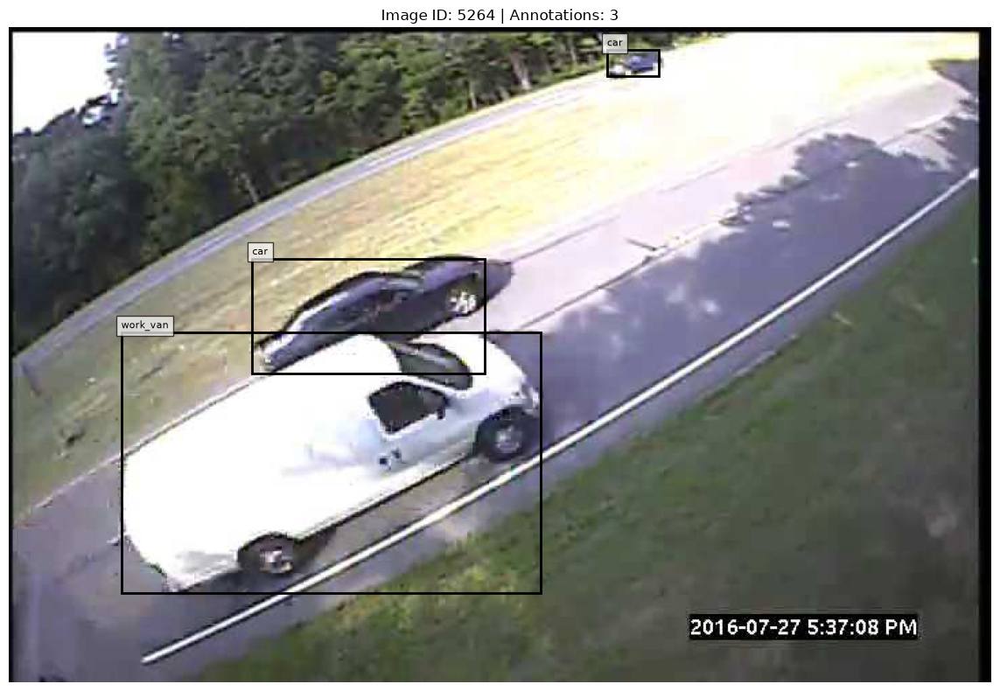

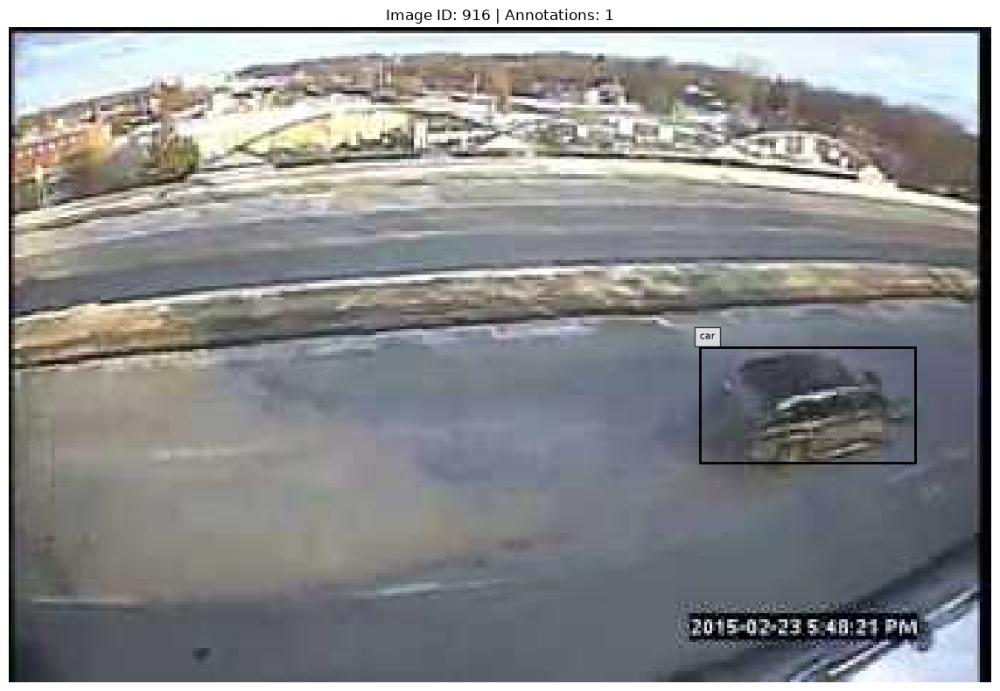

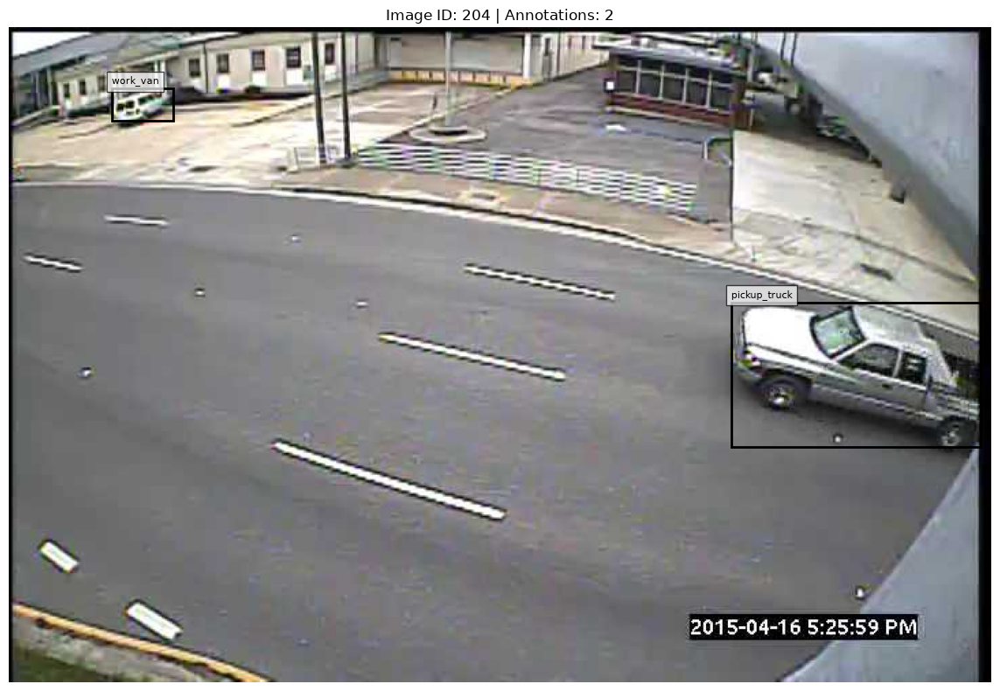

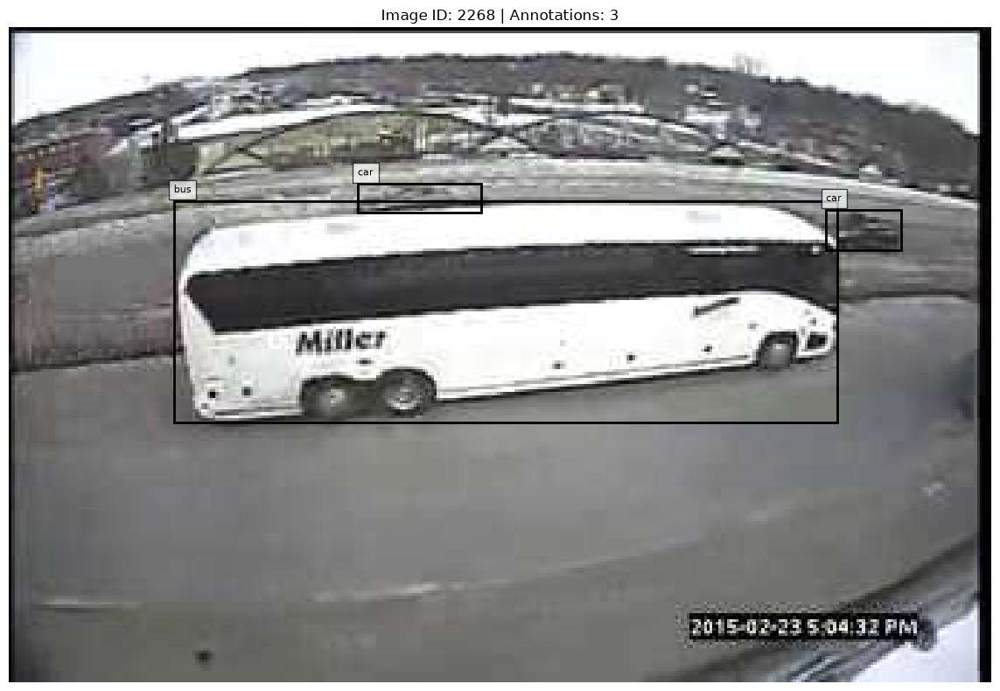

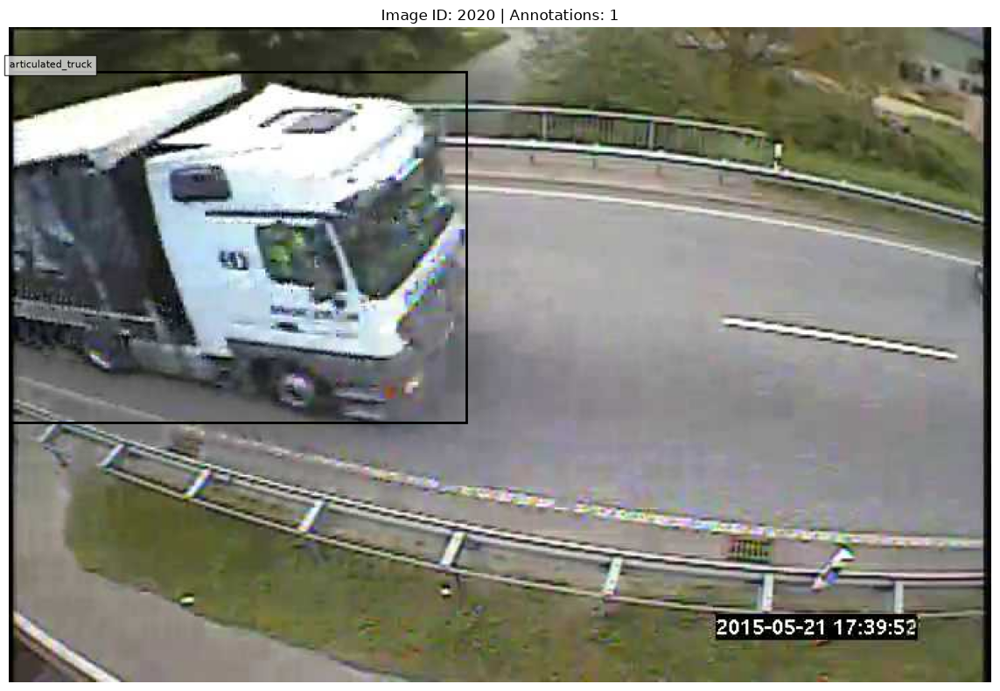

...

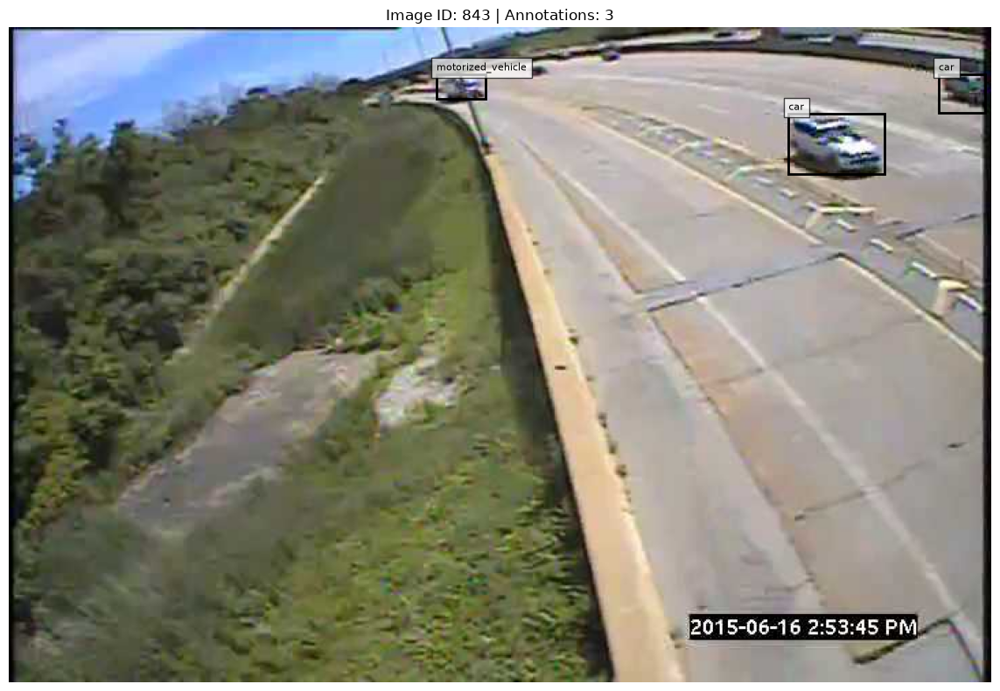

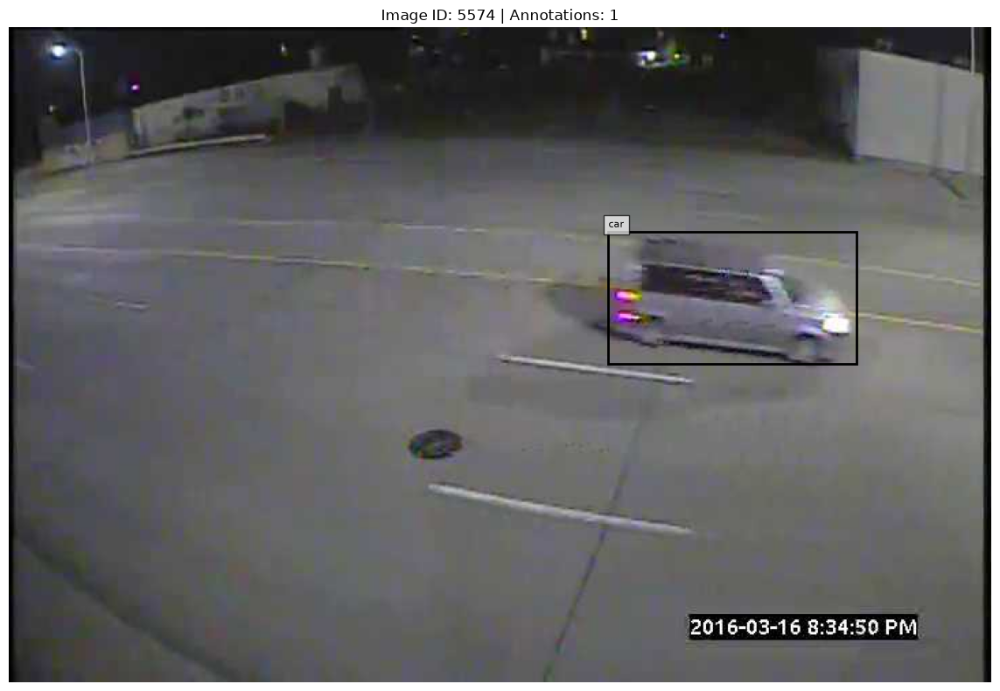

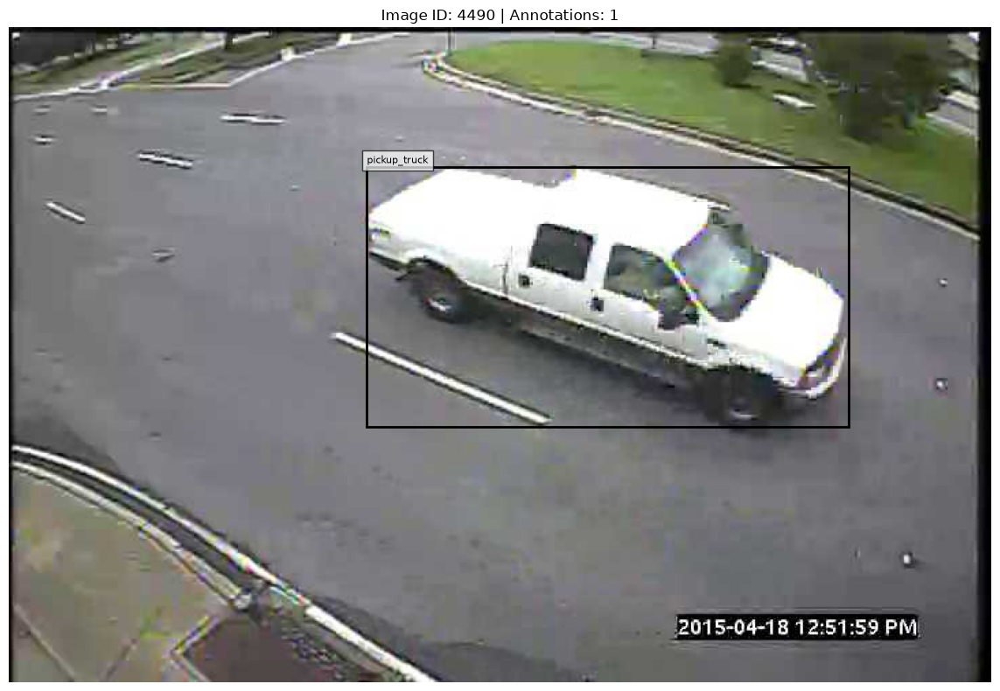

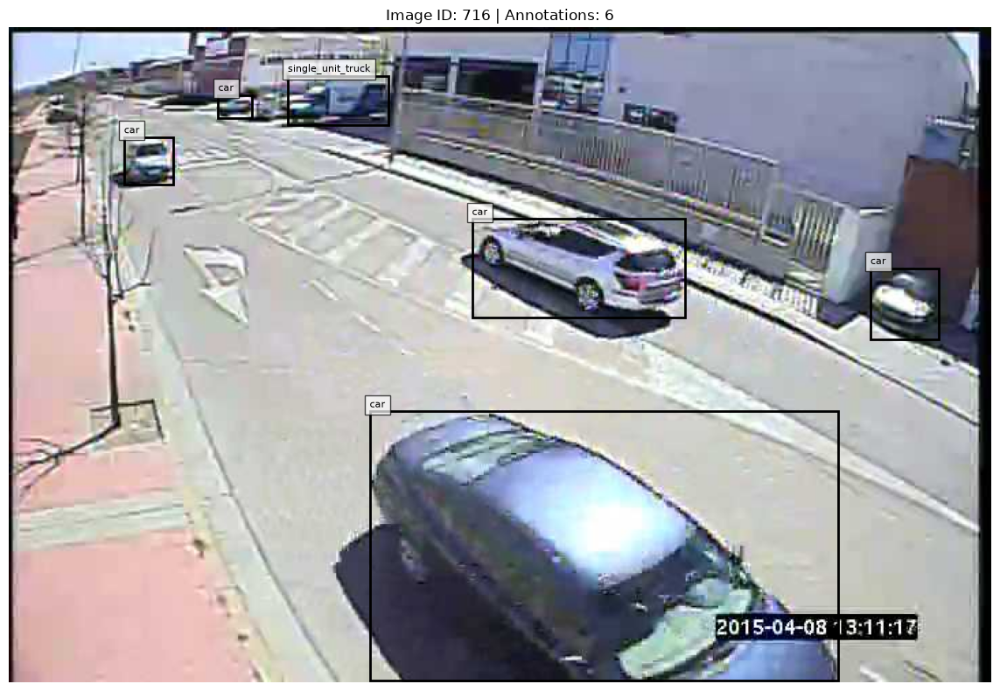

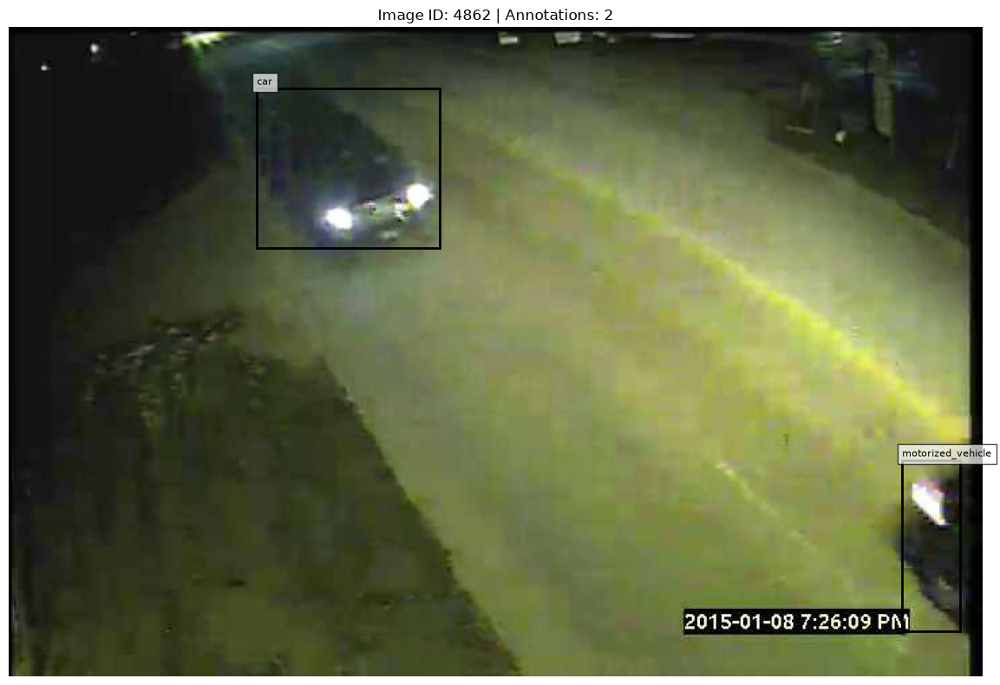


Validation dataframe saved to:
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\validation\bounding_box_validation.csv

Summary saved to:
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\validation\phase_1_3_bbox_validation_summary.csv

PHASE 1.3 COMPLETE


In [76]:
# ==============================================================
# PART 1 — PHASE 1.3
# BOUNDING-BOX GEOMETRY VALIDATION + VISUAL VERIFICATION
# ==============================================================

import os
import zipfile
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from io import BytesIO

print("=" * 70)
print("PART 1 — PHASE 1.3")
print("BOUNDING-BOX GEOMETRY VALIDATION + VISUAL VERIFICATION")
print("=" * 70)


# --------------------------------------------------------------
# 1. VERIFY REQUIRED DATAFRAMES
# --------------------------------------------------------------

required_variables = ["labels_df", "mapping_df"]

missing_variables = [
    var for var in required_variables
    if var not in globals()
]

if missing_variables:
    raise RuntimeError(
        f"Missing required variables: {missing_variables}. "
        "Run Phase 1.2 first."
    )

print("\n✓ labels_df available")
print("✓ mapping_df available")


# --------------------------------------------------------------
# 2. PATHS
# --------------------------------------------------------------

PROJECT_DIR = r"C:\Material\Repo\Projects\Capstone_1"

PART1_DIR = os.path.join(
    PROJECT_DIR,
    "Part_1"
)

DATA_DIR = os.path.join(
    PART1_DIR,
    "model_training",
    "data"
)

IMAGES_ZIP = os.path.join(
    DATA_DIR,
    "raw",
    "Images.zip"
)

OUTPUT_DIR = os.path.join(
    DATA_DIR,
    "validation"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("\nImages ZIP:")
print(IMAGES_ZIP)

print("\nValidation output directory:")
print(OUTPUT_DIR)


# --------------------------------------------------------------
# 3. VERIFY ANNOTATION SCHEMA
# --------------------------------------------------------------

EXPECTED_COLUMNS = [
    "image_id",
    "class",
    "xmin",
    "ymin",
    "xmax",
    "ymax"
]

missing_columns = [
    col for col in EXPECTED_COLUMNS
    if col not in labels_df.columns
]

if missing_columns:
    raise RuntimeError(
        f"labels_df is missing required columns: {missing_columns}"
    )

print("\n✓ Annotation schema verified")


# --------------------------------------------------------------
# 4. BASIC BOUNDING-BOX VALIDATION
# --------------------------------------------------------------

bbox_df = labels_df.copy()

# Ensure numerical coordinate types
for col in ["xmin", "ymin", "xmax", "ymax"]:
    bbox_df[col] = pd.to_numeric(
        bbox_df[col],
        errors="coerce"
    )

print("\n" + "=" * 70)
print("BOUNDING-BOX GEOMETRY AUDIT")
print("=" * 70)


# Missing coordinates
coordinate_missing = bbox_df[
    ["xmin", "ymin", "xmax", "ymax"]
].isna().any(axis=1)

print(
    "\nRows with missing bounding-box coordinates:",
    int(coordinate_missing.sum())
)


# Negative coordinates
negative_coordinate = (
    (bbox_df["xmin"] < 0) |
    (bbox_df["ymin"] < 0) |
    (bbox_df["xmax"] < 0) |
    (bbox_df["ymax"] < 0)
)

print(
    "Rows containing negative coordinates:",
    int(negative_coordinate.sum())
)


# Invalid ordering
invalid_x = bbox_df["xmax"] <= bbox_df["xmin"]
invalid_y = bbox_df["ymax"] <= bbox_df["ymin"]

invalid_geometry = (
    coordinate_missing |
    invalid_x |
    invalid_y |
    negative_coordinate
)

print(
    "Rows with invalid X ordering:",
    int(invalid_x.sum())
)

print(
    "Rows with invalid Y ordering:",
    int(invalid_y.sum())
)

print(
    "Total potentially invalid boxes:",
    int(invalid_geometry.sum())
)


# --------------------------------------------------------------
# 5. DISPLAY INVALID BOXES
# --------------------------------------------------------------

invalid_boxes = bbox_df.loc[
    invalid_geometry
].copy()

print("\n" + "=" * 70)
print("POTENTIALLY INVALID BOUNDING BOXES")
print("=" * 70)

if len(invalid_boxes) == 0:

    print("\n✓ No invalid bounding boxes found.")

else:

    print(
        invalid_boxes[
            [
                "image_id",
                "class",
                "xmin",
                "ymin",
                "xmax",
                "ymax"
            ]
        ].to_string(index=False)
    )


# --------------------------------------------------------------
# 6. BOUNDING-BOX DIMENSIONS
# --------------------------------------------------------------

bbox_df["bbox_width"] = (
    bbox_df["xmax"] - bbox_df["xmin"]
)

bbox_df["bbox_height"] = (
    bbox_df["ymax"] - bbox_df["ymin"]
)

bbox_df["bbox_area"] = (
    bbox_df["bbox_width"] *
    bbox_df["bbox_height"]
)

print("\n" + "=" * 70)
print("BOUNDING-BOX DIMENSION SUMMARY")
print("=" * 70)

print(
    bbox_df[
        [
            "bbox_width",
            "bbox_height",
            "bbox_area"
        ]
    ].describe()
)


# --------------------------------------------------------------
# 7. OPEN ZIP AND DETERMINE AVAILABLE IMAGE IDS
# --------------------------------------------------------------

print("\n" + "=" * 70)
print("AVAILABLE IMAGE INSPECTION")
print("=" * 70)

if not os.path.exists(IMAGES_ZIP):
    raise FileNotFoundError(
        f"Images ZIP not found:\n{IMAGES_ZIP}"
    )

with zipfile.ZipFile(IMAGES_ZIP, "r") as z:

    image_members = [
        name for name in z.namelist()
        if name.lower().endswith(
            (".jpg", ".jpeg", ".png")
        )
    ]

print(
    f"\nImages available in ZIP: {len(image_members)}"
)


# --------------------------------------------------------------
# 8. CREATE ZIP IMAGE-ID → ZIP-PATH LOOKUP
# --------------------------------------------------------------

zip_lookup = {}

for member in image_members:

    basename = os.path.basename(member)
    stem = os.path.splitext(basename)[0]

    try:
        image_id = int(stem)

        zip_lookup[image_id] = member

    except ValueError:
        continue

print(
    "Valid numeric image IDs in ZIP:",
    len(zip_lookup)
)


# --------------------------------------------------------------
# 9. KEEP ONLY ANNOTATIONS FOR AVAILABLE IMAGES
# --------------------------------------------------------------

available_ids = set(zip_lookup.keys())

available_annotations = bbox_df[
    bbox_df["image_id"].isin(available_ids)
].copy()

print(
    "\nAnnotations belonging to available images:",
    len(available_annotations)
)

print(
    "Unique available image IDs with annotations:",
    available_annotations["image_id"].nunique()
)


# --------------------------------------------------------------
# 10. VERIFY IMAGE DIMENSIONS AGAINST BOXES
# --------------------------------------------------------------

print("\n" + "=" * 70)
print("IMAGE DIMENSION ↔ BOUNDING-BOX VALIDATION")
print("=" * 70)

dimension_records = []

with zipfile.ZipFile(IMAGES_ZIP, "r") as z:

    for image_id, zip_path in zip_lookup.items():

        try:

            image_bytes = z.read(zip_path)

            image = Image.open(
                BytesIO(image_bytes)
            )

            width, height = image.size

            dimension_records.append({
                "image_id": image_id,
                "width": width,
                "height": height
            })

        except Exception as e:

            print(
                f"Could not read image {image_id}: {e}"
            )

dimensions_df = pd.DataFrame(
    dimension_records
)

print(
    f"\nSuccessfully inspected image dimensions: "
    f"{len(dimensions_df)}"
)


# --------------------------------------------------------------
# 11. MERGE DIMENSIONS WITH ANNOTATIONS
# --------------------------------------------------------------

validation_df = available_annotations.merge(
    dimensions_df,
    on="image_id",
    how="left"
)

validation_df["xmin_outside"] = (
    validation_df["xmin"] < 0
) | (
    validation_df["xmin"] >= validation_df["width"]
)

validation_df["ymin_outside"] = (
    validation_df["ymin"] < 0
) | (
    validation_df["ymin"] >= validation_df["height"]
)

validation_df["xmax_outside"] = (
    validation_df["xmax"] > validation_df["width"]
)

validation_df["ymax_outside"] = (
    validation_df["ymax"] > validation_df["height"]
)

out_of_bounds = (
    validation_df["xmin_outside"] |
    validation_df["ymin_outside"] |
    validation_df["xmax_outside"] |
    validation_df["ymax_outside"]
)

print(
    "\nBoxes extending beyond image boundaries:",
    int(out_of_bounds.sum())
)


# --------------------------------------------------------------
# 12. FINAL GEOMETRY VALIDATION SUMMARY
# --------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL BOUNDING-BOX VALIDATION SUMMARY")
print("=" * 70)

print(
    "\nTotal annotations:",
    len(bbox_df)
)

print(
    "Available-image annotations:",
    len(available_annotations)
)

print(
    "Potentially invalid geometry:",
    int(invalid_geometry.sum())
)

print(
    "Out-of-image-boundary boxes:",
    int(out_of_bounds.sum())
)

print(
    "Valid geometry:",
    int(
        len(bbox_df) -
        invalid_geometry.sum()
    )
)


# --------------------------------------------------------------
# 13. VISUAL VERIFICATION
# --------------------------------------------------------------

print("\n" + "=" * 70)
print("VISUAL BOUNDING-BOX VERIFICATION")
print("=" * 70)

# Only select images that actually have annotations
candidate_image_ids = (
    available_annotations["image_id"]
    .drop_duplicates()
    .tolist()
)

# Deterministic sampling
random.seed(42)

sample_size = min(
    12,
    len(candidate_image_ids)
)

sample_ids = random.sample(
    candidate_image_ids,
    sample_size
)

print(
    f"\nVisualizing {sample_size} randomly selected images..."
)

with zipfile.ZipFile(IMAGES_ZIP, "r") as z:

    for image_id in sample_ids:

        zip_path = zip_lookup[image_id]

        image_bytes = z.read(zip_path)

        image = Image.open(
            BytesIO(image_bytes)
        ).convert("RGB")

        image_annotations = available_annotations[
            available_annotations["image_id"] == image_id
        ]

        plt.figure(figsize=(12, 8))

        plt.imshow(image)

        for _, row in image_annotations.iterrows():

            xmin = row["xmin"]
            ymin = row["ymin"]

            xmax = row["xmax"]
            ymax = row["ymax"]

            width = xmax - xmin
            height = ymax - ymin

            # Skip geometrically invalid boxes
            if width <= 0 or height <= 0:
                continue

            rectangle = plt.Rectangle(
                (xmin, ymin),
                width,
                height,
                fill=False,
                linewidth=2
            )

            plt.gca().add_patch(
                rectangle
            )

            plt.text(
                xmin,
                max(0, ymin - 3),
                str(row["class"]),
                fontsize=8,
                bbox=dict(
                    facecolor="white",
                    alpha=0.7
                )
            )

        plt.title(
            f"Image ID: {image_id} | "
            f"Annotations: {len(image_annotations)}"
        )

        plt.axis("off")
        plt.tight_layout()
        plt.show()


# --------------------------------------------------------------
# 14. SAVE VALIDATION DATA
# --------------------------------------------------------------

validation_output = os.path.join(
    OUTPUT_DIR,
    "bounding_box_validation.csv"
)

validation_df.to_csv(
    validation_output,
    index=False
)

print("\nValidation dataframe saved to:")
print(validation_output)


# --------------------------------------------------------------
# 15. CREATE CLEAN VALIDATION SUMMARY
# --------------------------------------------------------------

summary = {
    "total_annotations": len(bbox_df),
    "available_image_annotations": len(
        available_annotations
    ),
    "total_images_in_zip": len(zip_lookup),
    "unique_annotation_image_ids": int(
        bbox_df["image_id"].nunique()
    ),
    "invalid_geometry_boxes": int(
        invalid_geometry.sum()
    ),
    "out_of_bounds_boxes": int(
        out_of_bounds.sum()
    ),
    "duplicate_annotation_rows": int(
        bbox_df.duplicated().sum()
    ),
    "unique_classes": int(
        bbox_df["class"].nunique()
    )
}

summary_df = pd.DataFrame(
    [summary]
)

summary_output = os.path.join(
    OUTPUT_DIR,
    "phase_1_3_bbox_validation_summary.csv"
)

summary_df.to_csv(
    summary_output,
    index=False
)

print("\nSummary saved to:")
print(summary_output)


print("\n" + "=" * 70)
print("PHASE 1.3 COMPLETE")
print("=" * 70)

In [77]:
# ============================================================
# PART 1 — PHASE 1.4
# TRAINING DATASET RECONCILIATION & CLEANING
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import zipfile
import shutil

print("=" * 70)
print("PART 1 — PHASE 1.4")
print("TRAINING DATASET RECONCILIATION & CLEANING")
print("=" * 70)


# ------------------------------------------------------------
# 1. VERIFY REQUIRED VARIABLES
# ------------------------------------------------------------

required_variables = [
    "labels_df",
    "mapping_df"
]

missing_variables = [
    var for var in required_variables
    if var not in globals()
]

if missing_variables:
    raise RuntimeError(
        f"Missing required variables: {missing_variables}. "
        "Run Phases 1.2 and 1.3 first."
    )

print("\n✓ labels_df available")
print("✓ mapping_df available")


# ------------------------------------------------------------
# 2. PATHS
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
)

ZIP_PATH = PROJECT_ROOT / "data" / "raw" / "Images.zip"

CLEAN_DIR = PROJECT_ROOT / "data" / "clean"

CLEAN_IMAGES_DIR = CLEAN_DIR / "images"

CLEAN_ANNOTATIONS_PATH = CLEAN_DIR / "annotations.csv"

CLEAN_MAPPING_PATH = CLEAN_DIR / "image_mapping.csv"


CLEAN_DIR.mkdir(
    parents=True,
    exist_ok=True
)

CLEAN_IMAGES_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# 3. RECREATE AVAILABLE IMAGE ID SET
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("IDENTIFYING AVAILABLE IMAGES")
print("=" * 70)

available_image_ids = set()

with zipfile.ZipFile(ZIP_PATH, "r") as z:

    for name in z.namelist():

        filename = Path(name).name

        if not filename:
            continue

        suffix = Path(filename).suffix.lower()

        if suffix not in [".jpg", ".jpeg", ".png"]:
            continue

        try:
            image_id = int(Path(filename).stem)
            available_image_ids.add(image_id)

        except ValueError:
            continue


print(f"\nAvailable images: {len(available_image_ids):,}")


# ------------------------------------------------------------
# 4. SELECT ONLY ANNOTATIONS FOR AVAILABLE IMAGES
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FILTERING ANNOTATIONS")
print("=" * 70)

available_annotations_df = labels_df[
    labels_df["image_id"].isin(available_image_ids)
].copy()

print(
    f"\nTotal annotation rows: "
    f"{len(labels_df):,}"
)

print(
    f"Annotations belonging to available images: "
    f"{len(available_annotations_df):,}"
)


# ------------------------------------------------------------
# 5. REMOVE DEGENERATE BOUNDING BOXES
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("REMOVING INVALID BOUNDING BOXES")
print("=" * 70)

available_annotations_df["bbox_width"] = (
    available_annotations_df["xmax"]
    - available_annotations_df["xmin"]
)

available_annotations_df["bbox_height"] = (
    available_annotations_df["ymax"]
    - available_annotations_df["ymin"]
)

invalid_bbox_mask = (
    (available_annotations_df["bbox_width"] <= 0)
    |
    (available_annotations_df["bbox_height"] <= 0)
)

invalid_bbox_count = int(
    invalid_bbox_mask.sum()
)

print(
    f"\nInvalid/degenerate boxes found "
    f"in available-image annotations: "
    f"{invalid_bbox_count}"
)

clean_annotations_df = available_annotations_df[
    ~invalid_bbox_mask
].copy()


# ------------------------------------------------------------
# 6. REMOVE TEMPORARY GEOMETRY COLUMNS
# ------------------------------------------------------------

clean_annotations_df.drop(
    columns=[
        "bbox_width",
        "bbox_height"
    ],
    inplace=True
)


# ------------------------------------------------------------
# 7. SORT DATA
# ------------------------------------------------------------

clean_annotations_df.sort_values(
    by=[
        "image_id",
        "xmin",
        "ymin"
    ],
    inplace=True
)

clean_annotations_df.reset_index(
    drop=True,
    inplace=True
)


# ------------------------------------------------------------
# 8. CREATE CLEAN IMAGE MAPPING
# ------------------------------------------------------------

clean_mapping_df = mapping_df[
    mapping_df["image_id"].isin(available_image_ids)
].copy()

clean_mapping_df = clean_mapping_df[
    clean_mapping_df["annotation_count"] > 0
].copy()

clean_mapping_df.sort_values(
    by="image_id",
    inplace=True
)

clean_mapping_df.reset_index(
    drop=True,
    inplace=True
)


# ------------------------------------------------------------
# 9. VERIFY FINAL COUNTS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL CLEAN DATASET")
print("=" * 70)

print(
    f"\nClean annotation rows: "
    f"{len(clean_annotations_df):,}"
)

print(
    f"Unique images with annotations: "
    f"{clean_annotations_df['image_id'].nunique():,}"
)

print(
    f"Images in clean mapping: "
    f"{len(clean_mapping_df):,}"
)

print(
    f"Classes represented: "
    f"{clean_annotations_df['class'].nunique():,}"
)


# ------------------------------------------------------------
# 10. CLASS DISTRIBUTION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CLEAN DATASET CLASS DISTRIBUTION")
print("=" * 70)

class_distribution = (
    clean_annotations_df["class"]
    .value_counts()
    .rename_axis("class")
    .reset_index(name="annotations")
)

class_distribution["percentage"] = (
    class_distribution["annotations"]
    / class_distribution["annotations"].sum()
    * 100
)

print(
    class_distribution.to_string(index=False)
)


# ------------------------------------------------------------
# 11. SAVE CLEAN ANNOTATIONS
# ------------------------------------------------------------

clean_annotations_df.to_csv(
    CLEAN_ANNOTATIONS_PATH,
    index=False
)

clean_mapping_df.to_csv(
    CLEAN_MAPPING_PATH,
    index=False
)

print("\n" + "=" * 70)
print("FILES SAVED")
print("=" * 70)

print(
    f"\nAnnotations:\n{CLEAN_ANNOTATIONS_PATH}"
)

print(
    f"\nMapping:\n{CLEAN_MAPPING_PATH}"
)


# ------------------------------------------------------------
# 12. FINAL CONSISTENCY CHECK
# ------------------------------------------------------------

annotation_image_ids = set(
    clean_annotations_df["image_id"].unique()
)

mapping_image_ids = set(
    clean_mapping_df["image_id"].unique()
)

missing_from_mapping = (
    annotation_image_ids
    - mapping_image_ids
)

missing_from_annotations = (
    mapping_image_ids
    - annotation_image_ids
)

print("\n" + "=" * 70)
print("FINAL CONSISTENCY CHECK")
print("=" * 70)

print(
    f"\nAnnotation image IDs missing from mapping: "
    f"{len(missing_from_mapping)}"
)

print(
    f"Mapping image IDs missing annotations: "
    f"{len(missing_from_annotations)}"
)


# ------------------------------------------------------------
# 13. CREATE FINAL VARIABLES FOR NEXT PHASE
# ------------------------------------------------------------

train_annotations_df = clean_annotations_df.copy()
train_mapping_df = clean_mapping_df.copy()

print("\n" + "=" * 70)
print("PHASE 1.4 COMPLETE")
print("=" * 70)

print("\nRequired variables created:")

print("✓ train_annotations_df")
print("✓ train_mapping_df")

print("\nDataset is now ready for dataset splitting/preparation.")

PART 1 — PHASE 1.4
TRAINING DATASET RECONCILIATION & CLEANING

✓ labels_df available
✓ mapping_df available

IDENTIFYING AVAILABLE IMAGES

Available images: 5,626

FILTERING ANNOTATIONS

Total annotation rows: 351,549
Annotations belonging to available images: 17,967

REMOVING INVALID BOUNDING BOXES

Invalid/degenerate boxes found in available-image annotations: 0

FINAL CLEAN DATASET

Clean annotation rows: 17,967
Unique images with annotations: 5,626
Images in clean mapping: 5,626
Classes represented: 11

CLEAN DATASET CLASS DISTRIBUTION
                class  annotations  percentage
                  car        12076   67.212111
         pickup_truck         2136   11.888462
    motorized_vehicle         1295    7.207658
                  bus          561    3.122391
             work_van          462    2.571381
    articulated_truck          461    2.565815
           pedestrian          340    1.892358
    single_unit_truck          303    1.686425
              bicycle          

In [78]:
# ============================================================
# PART 1 — PHASE 1.5
# IMAGE-LEVEL TRAIN / VALIDATION / TEST SPLIT
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json

from sklearn.model_selection import train_test_split


print("=" * 70)
print("PART 1 — PHASE 1.5")
print("IMAGE-LEVEL TRAIN / VALIDATION / TEST SPLIT")
print("=" * 70)


# ------------------------------------------------------------
# 1. VERIFY REQUIRED VARIABLES
# ------------------------------------------------------------

required_variables = [
    "train_annotations_df",
    "train_mapping_df"
]

missing_variables = [
    var
    for var in required_variables
    if var not in globals()
]

if missing_variables:
    raise RuntimeError(
        f"Missing required variables: {missing_variables}. "
        "Run Phase 1.4 first."
    )

print("\n✓ train_annotations_df available")
print("✓ train_mapping_df available")


# ------------------------------------------------------------
# 2. PATHS
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
)

SPLIT_DIR = PROJECT_ROOT / "data" / "splits"

SPLIT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# 3. CREATE IMAGE-LEVEL DATASET
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CREATING IMAGE-LEVEL DATASET")
print("=" * 70)

image_df = (
    train_annotations_df
    .groupby("image_id")
    .agg(
        annotation_count=("class", "count"),
        class_count=("class", "nunique")
    )
    .reset_index()
)

print(
    f"\nUnique images: "
    f"{len(image_df):,}"
)

print(
    f"Total annotations: "
    f"{len(train_annotations_df):,}"
)


# ------------------------------------------------------------
# 4. DETERMINE PRIMARY CLASS FOR STRATIFICATION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("BUILDING IMAGE-LEVEL STRATIFICATION LABEL")
print("=" * 70)

# Count classes within each image
image_class_counts = (
    train_annotations_df
    .groupby(["image_id", "class"])
    .size()
    .reset_index(name="count")
)

# Select the most frequent class in each image.
# This creates a single deterministic label per image
# for stratified splitting.

primary_class_df = (
    image_class_counts
    .sort_values(
        ["image_id", "count", "class"],
        ascending=[True, False, True]
    )
    .drop_duplicates(
        subset=["image_id"],
        keep="first"
    )
    [["image_id", "class"]]
    .rename(columns={"class": "primary_class"})
)

image_df = image_df.merge(
    primary_class_df,
    on="image_id",
    how="left"
)


# ------------------------------------------------------------
# 5. CHECK STRATIFICATION COUNTS
# ------------------------------------------------------------

primary_class_counts = (
    image_df["primary_class"]
    .value_counts()
    .sort_values()
)

print("\nImages by primary class:")

print(
    primary_class_counts.to_string()
)


# ------------------------------------------------------------
# 6. IDENTIFY RARE PRIMARY CLASSES
# ------------------------------------------------------------

# A stratified split requires enough samples per class.
# Classes with fewer than 2 images cannot be stratified.

rare_primary_classes = primary_class_counts[
    primary_class_counts < 2
]

if len(rare_primary_classes) > 0:

    print("\nWARNING:")
    print(
        "The following primary classes have fewer than "
        "2 images and cannot be safely stratified:"
    )

    print(
        rare_primary_classes.to_string()
    )


# ------------------------------------------------------------
# 7. FIRST SPLIT — TRAIN vs TEMPORARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SPLIT 1 — TRAIN / TEMPORARY")
print("=" * 70)

RANDOM_STATE = 42

train_images, temp_images = train_test_split(
    image_df,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=image_df["primary_class"]
)


print(
    f"\nTrain images: "
    f"{len(train_images):,}"
)

print(
    f"Temporary images: "
    f"{len(temp_images):,}"
)


# ------------------------------------------------------------
# 8. SECOND SPLIT — VALIDATION vs TEST
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SPLIT 2 — VALIDATION / TEST")
print("=" * 70)

validation_images, test_images = train_test_split(
    temp_images,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=temp_images["primary_class"]
)


print(
    f"\nValidation images: "
    f"{len(validation_images):,}"
)

print(
    f"Test images: "
    f"{len(test_images):,}"
)


# ------------------------------------------------------------
# 9. EXTRACT IMAGE ID SETS
# ------------------------------------------------------------

train_ids = set(
    train_images["image_id"]
)

validation_ids = set(
    validation_images["image_id"]
)

test_ids = set(
    test_images["image_id"]
)


# ------------------------------------------------------------
# 10. VERIFY NO OVERLAP
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("DATA LEAKAGE CHECK")
print("=" * 70)

train_val_overlap = train_ids & validation_ids
train_test_overlap = train_ids & test_ids
val_test_overlap = validation_ids & test_ids

print(
    f"\nTrain ∩ Validation: "
    f"{len(train_val_overlap)}"
)

print(
    f"Train ∩ Test: "
    f"{len(train_test_overlap)}"
)

print(
    f"Validation ∩ Test: "
    f"{len(val_test_overlap)}"
)

if (
    len(train_val_overlap) > 0
    or len(train_test_overlap) > 0
    or len(val_test_overlap) > 0
):

    raise RuntimeError(
        "DATA LEAKAGE DETECTED: "
        "one or more images occur in multiple splits."
    )

print("\n✓ No image-level overlap detected.")


# ------------------------------------------------------------
# 11. VERIFY COMPLETE COVERAGE
# ------------------------------------------------------------

all_split_ids = (
    train_ids
    | validation_ids
    | test_ids
)

all_dataset_ids = set(
    image_df["image_id"]
)

missing_from_splits = (
    all_dataset_ids - all_split_ids
)

unexpected_in_splits = (
    all_split_ids - all_dataset_ids
)

print("\n" + "=" * 70)
print("SPLIT COVERAGE CHECK")
print("=" * 70)

print(
    f"\nImages missing from splits: "
    f"{len(missing_from_splits)}"
)

print(
    f"Unexpected image IDs in splits: "
    f"{len(unexpected_in_splits)}"
)

if missing_from_splits or unexpected_in_splits:

    raise RuntimeError(
        "Split coverage validation failed."
    )

print("\n✓ Every image belongs to exactly one split.")


# ------------------------------------------------------------
# 12. ADD SPLIT COLUMN
# ------------------------------------------------------------

split_df = pd.concat(
    [
        train_images.assign(split="train"),
        validation_images.assign(split="validation"),
        test_images.assign(split="test")
    ],
    ignore_index=True
)

split_df = split_df.sort_values(
    "image_id"
).reset_index(
    drop=True
)


# ------------------------------------------------------------
# 13. ANNOTATION DISTRIBUTION PER SPLIT
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ANNOTATION DISTRIBUTION")
print("=" * 70)

train_annotation_count = train_annotations_df[
    train_annotations_df["image_id"].isin(train_ids)
].shape[0]

validation_annotation_count = train_annotations_df[
    train_annotations_df["image_id"].isin(validation_ids)
].shape[0]

test_annotation_count = train_annotations_df[
    train_annotations_df["image_id"].isin(test_ids)
].shape[0]


print(
    f"\nTrain annotations: "
    f"{train_annotation_count:,}"
)

print(
    f"Validation annotations: "
    f"{validation_annotation_count:,}"
)

print(
    f"Test annotations: "
    f"{test_annotation_count:,}"
)

print(
    f"Total annotations: "
    f"{train_annotation_count + validation_annotation_count + test_annotation_count:,}"
)


# ------------------------------------------------------------
# 14. CLASS DISTRIBUTION PER SPLIT
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CLASS DISTRIBUTION BY SPLIT")
print("=" * 70)

split_class_distribution = (
    train_annotations_df
    .merge(
        split_df[
            ["image_id", "split"]
        ],
        on="image_id",
        how="inner"
    )
    .groupby(
        ["split", "class"]
    )
    .size()
    .reset_index(
        name="annotations"
    )
)

split_class_distribution["percentage"] = (
    split_class_distribution
    .groupby("split")["annotations"]
    .transform(
        lambda x: x / x.sum() * 100
    )
)

print(
    split_class_distribution
    .sort_values(
        ["split", "annotations"],
        ascending=[True, False]
    )
    .to_string(index=False)
)


# ------------------------------------------------------------
# 15. SAVE SPLIT FILES
# ------------------------------------------------------------

train_split_path = SPLIT_DIR / "train.csv"
validation_split_path = SPLIT_DIR / "validation.csv"
test_split_path = SPLIT_DIR / "test.csv"
all_split_path = SPLIT_DIR / "all_splits.csv"

train_images.to_csv(
    train_split_path,
    index=False
)

validation_images.to_csv(
    validation_split_path,
    index=False
)

test_images.to_csv(
    test_split_path,
    index=False
)

split_df.to_csv(
    all_split_path,
    index=False
)


# ------------------------------------------------------------
# 16. SAVE SPLIT METADATA
# ------------------------------------------------------------

split_metadata = {
    "random_state": RANDOM_STATE,
    "train_ratio": 0.70,
    "validation_ratio": 0.15,
    "test_ratio": 0.15,

    "total_images": int(len(image_df)),
    "train_images": int(len(train_images)),
    "validation_images": int(len(validation_images)),
    "test_images": int(len(test_images)),

    "total_annotations": int(len(train_annotations_df)),
    "train_annotations": int(train_annotation_count),
    "validation_annotations": int(validation_annotation_count),
    "test_annotations": int(test_annotation_count),

    "number_of_classes": int(
        train_annotations_df["class"].nunique()
    ),

    "classes": sorted(
        train_annotations_df["class"]
        .unique()
        .tolist()
    )
}


metadata_path = SPLIT_DIR / "split_metadata.json"

with open(
    metadata_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        split_metadata,
        f,
        indent=4
    )


# ------------------------------------------------------------
# 17. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("PHASE 1.5 COMPLETE")
print("=" * 70)

print("\nImage split:")

print(
    f"✓ Train:      {len(train_images):,}"
)

print(
    f"✓ Validation: {len(validation_images):,}"
)

print(
    f"✓ Test:       {len(test_images):,}"
)

print("\nFiles saved:")

print(
    f"✓ {train_split_path}"
)

print(
    f"✓ {validation_split_path}"
)

print(
    f"✓ {test_split_path}"
)

print(
    f"✓ {all_split_path}"
)

print(
    f"✓ {metadata_path}"
)

print("\nNo model training performed.")

PART 1 — PHASE 1.5
IMAGE-LEVEL TRAIN / VALIDATION / TEST SPLIT

✓ train_annotations_df available
✓ train_mapping_df available

CREATING IMAGE-LEVEL DATASET

Unique images: 5,626
Total annotations: 17,967

BUILDING IMAGE-LEVEL STRATIFICATION LABEL

Images by primary class:
primary_class
non-motorized_vehicle      16
single_unit_truck          22
motorcycle                 22
pedestrian                 29
bicycle                    46
work_van                   69
motorized_vehicle         173
articulated_truck         225
bus                       261
pickup_truck              532
car                      4231

SPLIT 1 — TRAIN / TEMPORARY

Train images: 3,938
Temporary images: 1,688

SPLIT 2 — VALIDATION / TEST

Validation images: 844
Test images: 844

DATA LEAKAGE CHECK

Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0

✓ No image-level overlap detected.

SPLIT COVERAGE CHECK

Images missing from splits: 0
Unexpected image IDs in splits: 0

✓ Every image belongs to exactly on

In [79]:
from pathlib import Path
import pandas as pd
import numpy as np
import zipfile
import shutil
import json
import random
from collections import Counter

# ============================================================
# PART 1 — PHASE 1.6
# OBJECT-DETECTION DATASET PREPARATION
# ============================================================

BASE_DIR = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
)

DATA_DIR = BASE_DIR / "data"

ZIP_PATH = DATA_DIR / "raw" / "Images.zip"

ANNOTATIONS_PATH = DATA_DIR / "clean" / "annotations.csv"
MAPPING_PATH = DATA_DIR / "clean" / "image_mapping.csv"

TRAIN_SPLIT_PATH = DATA_DIR / "splits" / "train.csv"
VAL_SPLIT_PATH = DATA_DIR / "splits" / "validation.csv"
TEST_SPLIT_PATH = DATA_DIR / "splits" / "test.csv"

YOLO_DIR = DATA_DIR / "yolo"

IMAGE_TRAIN_DIR = YOLO_DIR / "images" / "train"
IMAGE_VAL_DIR = YOLO_DIR / "images" / "val"
IMAGE_TEST_DIR = YOLO_DIR / "images" / "test"

LABEL_TRAIN_DIR = YOLO_DIR / "labels" / "train"
LABEL_VAL_DIR = YOLO_DIR / "labels" / "val"
LABEL_TEST_DIR = YOLO_DIR / "labels" / "test"

for directory in [
    IMAGE_TRAIN_DIR,
    IMAGE_VAL_DIR,
    IMAGE_TEST_DIR,
    LABEL_TRAIN_DIR,
    LABEL_VAL_DIR,
    LABEL_TEST_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

print("=" * 70)
print("PART 1 — PHASE 1.6")
print("OBJECT-DETECTION DATASET PREPARATION")
print("=" * 70)

print("\nBase directory:")
print(BASE_DIR)

print("\nInput files:")
print("ZIP:", ZIP_PATH)
print("Annotations:", ANNOTATIONS_PATH)
print("Mapping:", MAPPING_PATH)
print("Train split:", TRAIN_SPLIT_PATH)
print("Validation split:", VAL_SPLIT_PATH)
print("Test split:", TEST_SPLIT_PATH)

print("\nOutput directory:")
print(YOLO_DIR)

PART 1 — PHASE 1.6
OBJECT-DETECTION DATASET PREPARATION

Base directory:
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training

Input files:
ZIP: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\raw\Images.zip
Annotations: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\clean\annotations.csv
Mapping: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\clean\image_mapping.csv
Train split: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\splits\train.csv
Validation split: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\splits\validation.csv
Test split: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\splits\test.csv

Output directory:
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\yolo


In [80]:
# ============================================================
# INPUT FILE VERIFICATION
# ============================================================

required_files = {
    "Images ZIP": ZIP_PATH,
    "Annotations": ANNOTATIONS_PATH,
    "Mapping": MAPPING_PATH,
    "Train split": TRAIN_SPLIT_PATH,
    "Validation split": VAL_SPLIT_PATH,
    "Test split": TEST_SPLIT_PATH,
}

print("=" * 70)
print("INPUT FILE VERIFICATION")
print("=" * 70)

missing_files = []

for name, path in required_files.items():
    if path.exists():
        print(f"✓ {name}: found")
    else:
        print(f"✗ {name}: MISSING")
        missing_files.append(name)

if missing_files:
    raise FileNotFoundError(
        f"Required input files are missing: {missing_files}"
    )

print("\n✓ All required Phase 1.6 inputs are available.")

INPUT FILE VERIFICATION
✓ Images ZIP: found
✓ Annotations: found
✓ Mapping: found
✓ Train split: found
✓ Validation split: found
✓ Test split: found

✓ All required Phase 1.6 inputs are available.


In [81]:
# ============================================================
# LOAD FINALIZED DATA
# ============================================================

annotations_df = pd.read_csv(ANNOTATIONS_PATH)
mapping_df = pd.read_csv(MAPPING_PATH)

train_df = pd.read_csv(TRAIN_SPLIT_PATH)
val_df = pd.read_csv(VAL_SPLIT_PATH)
test_df = pd.read_csv(TEST_SPLIT_PATH)

print("=" * 70)
print("LOADED DATASETS")
print("=" * 70)

print("\nAnnotations:")
print(annotations_df.shape)

print("\nMapping:")
print(mapping_df.shape)

print("\nTrain split:")
print(train_df.shape)

print("\nValidation split:")
print(val_df.shape)

print("\nTest split:")
print(test_df.shape)

print("\nAnnotation columns:")
print(list(annotations_df.columns))

print("\nMapping columns:")
print(list(mapping_df.columns))

print("\nTrain columns:")
print(list(train_df.columns))

LOADED DATASETS

Annotations:
(17967, 6)

Mapping:
(5626, 5)

Train split:
(3938, 4)

Validation split:
(844, 4)

Test split:
(844, 4)

Annotation columns:
['image_id', 'class', 'xmin', 'ymin', 'xmax', 'ymax']

Mapping columns:
['image_id', 'filename', 'zip_path', 'annotation_count', 'has_annotation']

Train columns:
['image_id', 'annotation_count', 'class_count', 'primary_class']


In [82]:
# ============================================================
# CLASS MAPPING
# ============================================================

CLASS_NAMES = [
    "car",
    "pickup_truck",
    "motorized_vehicle",
    "bus",
    "articulated_truck",
    "work_van",
    "pedestrian",
    "single_unit_truck",
    "bicycle",
    "non-motorized_vehicle",
    "motorcycle",
]

CLASS_TO_ID = {
    class_name: class_id
    for class_id, class_name in enumerate(CLASS_NAMES)
}

ID_TO_CLASS = {
    class_id: class_name
    for class_id, class_name in enumerate(CLASS_NAMES)
}

print("=" * 70)
print("CLASS MAPPING")
print("=" * 70)

for class_id, class_name in ID_TO_CLASS.items():
    print(f"{class_id:2d} -> {class_name}")

print("\nNumber of classes:", len(CLASS_NAMES))

CLASS MAPPING
 0 -> car
 1 -> pickup_truck
 2 -> motorized_vehicle
 3 -> bus
 4 -> articulated_truck
 5 -> work_van
 6 -> pedestrian
 7 -> single_unit_truck
 8 -> bicycle
 9 -> non-motorized_vehicle
10 -> motorcycle

Number of classes: 11


In [83]:
# ============================================================
# CLASS VALIDATION
# ============================================================

annotation_classes = set(annotations_df["class"].unique())
expected_classes = set(CLASS_NAMES)

missing_classes = expected_classes - annotation_classes
unexpected_classes = annotation_classes - expected_classes

print("=" * 70)
print("CLASS MAPPING VALIDATION")
print("=" * 70)

print("\nClasses in annotations:")
print(sorted(annotation_classes))

if missing_classes:
    print("\nMissing expected classes:")
    print(sorted(missing_classes))
else:
    print("\n✓ No expected classes missing.")

if unexpected_classes:
    print("\nUnexpected classes:")
    print(sorted(unexpected_classes))
else:
    print("✓ No unexpected classes found.")

if missing_classes or unexpected_classes:
    raise RuntimeError(
        "Class mapping validation failed."
    )

print("\n✓ Class mapping validated successfully.")

CLASS MAPPING VALIDATION

Classes in annotations:
['articulated_truck', 'bicycle', 'bus', 'car', 'motorcycle', 'motorized_vehicle', 'non-motorized_vehicle', 'pedestrian', 'pickup_truck', 'single_unit_truck', 'work_van']

✓ No expected classes missing.
✓ No unexpected classes found.

✓ Class mapping validated successfully.


In [84]:
# ============================================================
# SPLIT VALIDATION
# ============================================================

def extract_split_ids(df, name):
    if "image_id" not in df.columns:
        raise RuntimeError(
            f"{name} split does not contain an 'image_id' column."
        )

    return set(df["image_id"].astype(int))


train_ids = extract_split_ids(train_df, "Train")
val_ids = extract_split_ids(val_df, "Validation")
test_ids = extract_split_ids(test_df, "Test")

print("=" * 70)
print("SPLIT VALIDATION")
print("=" * 70)

print("\nTrain images:", len(train_ids))
print("Validation images:", len(val_ids))
print("Test images:", len(test_ids))

print("\nTrain ∩ Validation:", len(train_ids & val_ids))
print("Train ∩ Test:", len(train_ids & test_ids))
print("Validation ∩ Test:", len(val_ids & test_ids))

if train_ids & val_ids:
    raise RuntimeError("Train/validation overlap detected.")

if train_ids & test_ids:
    raise RuntimeError("Train/test overlap detected.")

if val_ids & test_ids:
    raise RuntimeError("Validation/test overlap detected.")

all_split_ids = train_ids | val_ids | test_ids

print("\nTotal unique split images:", len(all_split_ids))

if len(all_split_ids) != 5626:
    raise RuntimeError(
        f"Expected 5626 split images, found {len(all_split_ids)}."
    )

print("\n✓ Split integrity confirmed.")

SPLIT VALIDATION

Train images: 3938
Validation images: 844
Test images: 844

Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0

Total unique split images: 5626

✓ Split integrity confirmed.


In [85]:
# ============================================================
# ZIP STRUCTURE INSPECTION
# ============================================================

print("=" * 70)
print("INSPECTING IMAGE ZIP")
print("=" * 70)

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    members = z.namelist()

print("\nTotal ZIP entries:", len(members))

image_members = [
    m for m in members
    if m.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
]

print("Image entries:", len(image_members))

print("\nFirst 20 image paths:")

for path in image_members[:20]:
    print(path)

INSPECTING IMAGE ZIP

Total ZIP entries: 5627
Image entries: 5626

First 20 image paths:
Images/00000000.jpg
Images/00000001.jpg
Images/00000002.jpg
Images/00000003.jpg
Images/00000004.jpg
Images/00000005.jpg
Images/00000006.jpg
Images/00000007.jpg
Images/00000008.jpg
Images/00000009.jpg
Images/00000010.jpg
Images/00000011.jpg
Images/00000012.jpg
Images/00000013.jpg
Images/00000014.jpg
Images/00000015.jpg
Images/00000016.jpg
Images/00000017.jpg
Images/00000018.jpg
Images/00000019.jpg


In [86]:
# ============================================================
# BUILD IMAGE ID -> ZIP PATH LOOKUP
# ============================================================

def image_id_from_filename(filename):
    stem = Path(filename).stem

    try:
        return int(stem)
    except ValueError:
        return None


zip_image_lookup = {}

for member in image_members:
    image_id = image_id_from_filename(member)

    if image_id is not None:
        zip_image_lookup[image_id] = member

print("=" * 70)
print("ZIP IMAGE LOOKUP")
print("=" * 70)

print("\nNumeric image IDs:", len(zip_image_lookup))

missing_from_zip = sorted(
    all_split_ids - set(zip_image_lookup.keys())
)

unexpected_zip_ids = sorted(
    set(zip_image_lookup.keys()) - all_split_ids
)

print("Split IDs missing from ZIP:", len(missing_from_zip))
print("Extra numeric ZIP IDs:", len(unexpected_zip_ids))

if missing_from_zip:
    print("\nMissing IDs:")
    print(missing_from_zip[:20])

if missing_from_zip:
    raise RuntimeError(
        "Some split images are missing from Images.zip."
    )

print("\n✓ Every split image exists in the ZIP.")

ZIP IMAGE LOOKUP

Numeric image IDs: 5626
Split IDs missing from ZIP: 0
Extra numeric ZIP IDs: 0

✓ Every split image exists in the ZIP.


In [87]:
# ============================================================
# IMAGE -> SPLIT ASSIGNMENT
# ============================================================

split_assignment = {}

for image_id in train_ids:
    split_assignment[image_id] = "train"

for image_id in val_ids:
    split_assignment[image_id] = "val"

for image_id in test_ids:
    split_assignment[image_id] = "test"

if len(split_assignment) != 5626:
    raise RuntimeError(
        "Split assignment does not contain exactly 5626 images."
    )

print("=" * 70)
print("SPLIT ASSIGNMENT")
print("=" * 70)

print("\nTrain:", sum(v == "train" for v in split_assignment.values()))
print("Validation:", sum(v == "val" for v in split_assignment.values()))
print("Test:", sum(v == "test" for v in split_assignment.values()))

print("\n✓ Split assignment created.")

SPLIT ASSIGNMENT

Train: 3938
Validation: 844
Test: 844

✓ Split assignment created.


In [88]:
# ============================================================
# EXTRACT SPLIT IMAGES
# ============================================================

print("=" * 70)
print("EXTRACTING DATASET IMAGES")
print("=" * 70)

split_output_dirs = {
    "train": IMAGE_TRAIN_DIR,
    "val": IMAGE_VAL_DIR,
    "test": IMAGE_TEST_DIR,
}

extracted_counts = Counter()

with zipfile.ZipFile(ZIP_PATH, "r") as z:

    for image_id, split in sorted(split_assignment.items()):

        zip_member = zip_image_lookup[image_id]
        output_dir = split_output_dirs[split]

        source_name = Path(zip_member).name
        output_path = output_dir / source_name

        with z.open(zip_member) as source, open(output_path, "wb") as target:
            shutil.copyfileobj(source, target)

        extracted_counts[split] += 1

print("\nExtraction complete.")

for split in ["train", "val", "test"]:
    print(
        f"{split.capitalize():12s}: "
        f"{extracted_counts[split]:,} images"
    )

EXTRACTING DATASET IMAGES

Extraction complete.
Train       : 3,938 images
Val         : 844 images
Test        : 844 images


In [89]:
# ============================================================
# YOLO BOUNDING-BOX CONVERSION
# ============================================================

from PIL import Image

print("=" * 70)
print("CONVERTING BOUNDING BOXES TO YOLO FORMAT")
print("=" * 70)

# Ensure numeric coordinates
bbox_columns = ["xmin", "ymin", "xmax", "ymax"]

for col in bbox_columns:
    annotations_df[col] = pd.to_numeric(
        annotations_df[col],
        errors="raise"
    )

annotations_df["image_id"] = pd.to_numeric(
    annotations_df["image_id"],
    errors="raise"
).astype(int)

annotations_df["class_id"] = annotations_df["class"].map(CLASS_TO_ID)

if annotations_df["class_id"].isna().any():
    raise RuntimeError(
        "Some annotations could not be mapped to class IDs."
    )

annotation_counts = Counter()

invalid_yolo_boxes = []

with zipfile.ZipFile(ZIP_PATH, "r") as z:

    for image_id, split in sorted(split_assignment.items()):

        image_annotations = annotations_df[
            annotations_df["image_id"] == image_id
        ]

        zip_member = zip_image_lookup[image_id]

        # Read image dimensions directly from ZIP
        with z.open(zip_member) as image_file:
            image = Image.open(image_file)
            image_width, image_height = image.size

        output_label_dir = {
            "train": LABEL_TRAIN_DIR,
            "val": LABEL_VAL_DIR,
            "test": LABEL_TEST_DIR,
        }[split]

        image_filename = Path(zip_member).name
        label_filename = Path(image_filename).stem + ".txt"
        label_path = output_label_dir / label_filename

        yolo_lines = []

        for _, row in image_annotations.iterrows():

            xmin = float(row["xmin"])
            ymin = float(row["ymin"])
            xmax = float(row["xmax"])
            ymax = float(row["ymax"])

            # Original coordinate validation
            if xmax <= xmin or ymax <= ymin:
                invalid_yolo_boxes.append(
                    {
                        "image_id": image_id,
                        "class": row["class"],
                        "xmin": xmin,
                        "ymin": ymin,
                        "xmax": xmax,
                        "ymax": ymax,
                    }
                )
                continue

            center_x = ((xmin + xmax) / 2.0) / image_width
            center_y = ((ymin + ymax) / 2.0) / image_height

            bbox_width = (xmax - xmin) / image_width
            bbox_height = (ymax - ymin) / image_height

            values = [
                int(row["class_id"]),
                center_x,
                center_y,
                bbox_width,
                bbox_height,
            ]

            # Validate normalized YOLO coordinates
            if not (
                0 <= center_x <= 1
                and 0 <= center_y <= 1
                and 0 < bbox_width <= 1
                and 0 < bbox_height <= 1
            ):
                invalid_yolo_boxes.append(
                    {
                        "image_id": image_id,
                        "class": row["class"],
                        "values": values,
                        "image_width": image_width,
                        "image_height": image_height,
                    }
                )
                continue

            yolo_lines.append(
                f"{int(row['class_id'])} "
                f"{center_x:.6f} "
                f"{center_y:.6f} "
                f"{bbox_width:.6f} "
                f"{bbox_height:.6f}"
            )

            annotation_counts[split] += 1

        with open(label_path, "w", encoding="utf-8") as f:
            f.write("\n".join(yolo_lines))

print("\nConversion complete.")

print("\nConverted annotations:")

for split in ["train", "val", "test"]:
    print(
        f"{split.capitalize():12s}: "
        f"{annotation_counts[split]:,}"
    )

print("\nInvalid converted boxes:", len(invalid_yolo_boxes))

if invalid_yolo_boxes:
    raise RuntimeError(
        "Invalid YOLO bounding boxes detected."
    )

print("\n✓ Bounding-box conversion successful.")

CONVERTING BOUNDING BOXES TO YOLO FORMAT

Conversion complete.

Converted annotations:
Train       : 12,553
Val         : 2,689
Test        : 2,725

Invalid converted boxes: 0

✓ Bounding-box conversion successful.


In [90]:
# ============================================================
# CREATE YOLO DATASET CONFIGURATION
# ============================================================

dataset_yaml = YOLO_DIR / "dataset.yaml"

yaml_lines = [
    f"path: {YOLO_DIR.as_posix()}",
    "train: images/train",
    "val: images/val",
    "test: images/test",
    "",
    f"nc: {len(CLASS_NAMES)}",
    "names:",
]

for class_id, class_name in ID_TO_CLASS.items():
    yaml_lines.append(
        f"  {class_id}: {class_name}"
    )

with open(dataset_yaml, "w", encoding="utf-8") as f:
    f.write("\n".join(yaml_lines))

print("=" * 70)
print("DATASET YAML CREATED")
print("=" * 70)

print("\nPath:")
print(dataset_yaml)

print("\nContents:\n")

print("\n".join(yaml_lines))

DATASET YAML CREATED

Path:
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\yolo\dataset.yaml

Contents:

path: C:/Material/Repo/Projects/Capstone_1/Part_1/model_training/data/yolo
train: images/train
val: images/val
test: images/test

nc: 11
names:
  0: car
  1: pickup_truck
  2: motorized_vehicle
  3: bus
  4: articulated_truck
  5: work_van
  6: pedestrian
  7: single_unit_truck
  8: bicycle
  9: non-motorized_vehicle
  10: motorcycle


In [91]:
# ============================================================
# FINAL DATASET INTEGRITY AUDIT
# ============================================================

print("=" * 70)
print("PHASE 1.6 DATASET INTEGRITY AUDIT")
print("=" * 70)

audit_results = {}

# ------------------------------------------------------------
# IMAGE COUNTS
# ------------------------------------------------------------

for split, image_dir in [
    ("train", IMAGE_TRAIN_DIR),
    ("val", IMAGE_VAL_DIR),
    ("test", IMAGE_TEST_DIR),
]:

    images = [
        p for p in image_dir.iterdir()
        if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    ]

    labels_dir = {
        "train": LABEL_TRAIN_DIR,
        "val": LABEL_VAL_DIR,
        "test": LABEL_TEST_DIR,
    }[split]

    labels = list(labels_dir.glob("*.txt"))

    audit_results[f"{split}_images"] = len(images)
    audit_results[f"{split}_labels"] = len(labels)

    print(f"\n{split.upper()}")

    print("Images:", len(images))
    print("Labels:", len(labels))

    if len(images) != len(labels):
        raise RuntimeError(
            f"{split}: image/label count mismatch."
        )

# ------------------------------------------------------------
# TOTAL COUNTS
# ------------------------------------------------------------

total_images = (
    audit_results["train_images"]
    + audit_results["val_images"]
    + audit_results["test_images"]
)

total_labels = (
    audit_results["train_labels"]
    + audit_results["val_labels"]
    + audit_results["test_labels"]
)

print("\nTOTAL IMAGES:", total_images)
print("TOTAL LABEL FILES:", total_labels)

if total_images != 5626:
    raise RuntimeError(
        f"Expected 5626 images, found {total_images}."
    )

# ------------------------------------------------------------
# LABEL CONTENT AUDIT
# ------------------------------------------------------------

invalid_label_lines = []
total_yolo_annotations = 0
class_counter = Counter()

for split, labels_dir in [
    ("train", LABEL_TRAIN_DIR),
    ("val", LABEL_VAL_DIR),
    ("test", LABEL_TEST_DIR),
]:

    for label_path in labels_dir.glob("*.txt"):

        with open(label_path, "r", encoding="utf-8") as f:
            lines = [
                line.strip()
                for line in f
                if line.strip()
            ]

        for line_number, line in enumerate(lines, start=1):

            parts = line.split()

            if len(parts) != 5:
                invalid_label_lines.append(
                    (split, label_path.name, line_number, line)
                )
                continue

            try:
                class_id = int(parts[0])
                x_center = float(parts[1])
                y_center = float(parts[2])
                width = float(parts[3])
                height = float(parts[4])
            except ValueError:
                invalid_label_lines.append(
                    (split, label_path.name, line_number, line)
                )
                continue

            if class_id not in ID_TO_CLASS:
                invalid_label_lines.append(
                    (split, label_path.name, line_number, line)
                )
                continue

            if not (
                0 <= x_center <= 1
                and 0 <= y_center <= 1
                and 0 < width <= 1
                and 0 < height <= 1
            ):
                invalid_label_lines.append(
                    (split, label_path.name, line_number, line)
                )
                continue

            total_yolo_annotations += 1
            class_counter[class_id] += 1

print("\nTotal YOLO annotations:", total_yolo_annotations)

print("\nExpected annotations:", len(annotations_df))

print(
    "\nAnnotation difference:",
    total_yolo_annotations - len(annotations_df)
)

if total_yolo_annotations != len(annotations_df):
    raise RuntimeError(
        "YOLO annotation count does not match the cleaned dataset."
    )

if invalid_label_lines:
    print("\nInvalid label lines:")
    for item in invalid_label_lines[:20]:
        print(item)

    raise RuntimeError(
        f"{len(invalid_label_lines)} invalid YOLO label lines found."
    )

print("\n✓ All YOLO labels passed integrity validation.")

PHASE 1.6 DATASET INTEGRITY AUDIT

TRAIN
Images: 3938
Labels: 3938

VAL
Images: 844
Labels: 844

TEST
Images: 844
Labels: 844

TOTAL IMAGES: 5626
TOTAL LABEL FILES: 5626

Total YOLO annotations: 17967

Expected annotations: 17967

Annotation difference: 0

✓ All YOLO labels passed integrity validation.


In [92]:
# ============================================================
# YOLO CLASS DISTRIBUTION
# ============================================================

print("=" * 70)
print("YOLO CLASS DISTRIBUTION")
print("=" * 70)

distribution_rows = []

for class_id, count in sorted(class_counter.items()):

    distribution_rows.append({
        "class_id": class_id,
        "class": ID_TO_CLASS[class_id],
        "annotations": count,
        "percentage": round(
            count / total_yolo_annotations * 100,
            4
        ),
    })

yolo_distribution_df = pd.DataFrame(distribution_rows)

print(
    yolo_distribution_df.to_string(index=False)
)

print("\n✓ Class distribution successfully reconstructed.")

YOLO CLASS DISTRIBUTION
 class_id                 class  annotations  percentage
        0                   car        12076     67.2121
        1          pickup_truck         2136     11.8885
        2     motorized_vehicle         1295      7.2077
        3                   bus          561      3.1224
        4     articulated_truck          461      2.5658
        5              work_van          462      2.5714
        6            pedestrian          340      1.8924
        7     single_unit_truck          303      1.6864
        8               bicycle          130      0.7235
        9 non-motorized_vehicle          108      0.6011
       10            motorcycle           95      0.5287

✓ Class distribution successfully reconstructed.


In [93]:
# ============================================================
# SAVE DATASET METADATA
# ============================================================

class_mapping_path = YOLO_DIR / "class_mapping.json"

metadata_path = YOLO_DIR / "dataset_metadata.json"

class_mapping_data = {
    "classes": CLASS_NAMES,
    "class_to_id": CLASS_TO_ID,
    "id_to_class": {
        str(k): v
        for k, v in ID_TO_CLASS.items()
    },
}

with open(class_mapping_path, "w", encoding="utf-8") as f:
    json.dump(
        class_mapping_data,
        f,
        indent=4
    )

metadata = {
    "phase": "Part 1 Phase 1.6",
    "source_zip": str(ZIP_PATH),
    "source_annotations": str(ANNOTATIONS_PATH),
    "source_mapping": str(MAPPING_PATH),
    "total_images": total_images,
    "train_images": audit_results["train_images"],
    "validation_images": audit_results["val_images"],
    "test_images": audit_results["test_images"],
    "total_annotations": total_yolo_annotations,
    "classes": CLASS_NAMES,
    "class_count": len(CLASS_NAMES),
    "invalid_yolo_labels": len(invalid_label_lines),
}

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(
        metadata,
        f,
        indent=4
    )

print("=" * 70)
print("METADATA SAVED")
print("=" * 70)

print("\nClass mapping:")
print(class_mapping_path)

print("\nDataset metadata:")
print(metadata_path)

METADATA SAVED

Class mapping:
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\yolo\class_mapping.json

Dataset metadata:
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\yolo\dataset_metadata.json


In [94]:
# ============================================================
# PHASE 1.6 FINAL CHECKPOINT
# ============================================================

print("\n" + "=" * 70)
print("PHASE 1.6 COMPLETE")
print("=" * 70)

print("\nDataset:")
print(f"✓ Total images: {total_images:,}")

print("\nSplits:")
print(f"✓ Train:      {audit_results['train_images']:,}")
print(f"✓ Validation: {audit_results['val_images']:,}")
print(f"✓ Test:       {audit_results['test_images']:,}")

print("\nAnnotations:")
print(f"✓ Total YOLO annotations: {total_yolo_annotations:,}")

print("\nClasses:")
print(f"✓ Classes: {len(CLASS_NAMES)}")

print("\nIntegrity:")
print("✓ No split overlap")
print("✓ All split images found")
print("✓ Image/label counts match")
print("✓ All class IDs valid")
print("✓ All normalized coordinates valid")
print("✓ Annotation count preserved")
print("✓ No invalid YOLO labels")

print("\nFiles:")
print(f"✓ {dataset_yaml}")
print(f"✓ {class_mapping_path}")
print(f"✓ {metadata_path}")

print("\n" + "=" * 70)
print("DATASET IS READY FOR MODEL CONFIGURATION")
print("=" * 70)

print("\nNo model training performed.")


PHASE 1.6 COMPLETE

Dataset:
✓ Total images: 5,626

Splits:
✓ Train:      3,938
✓ Validation: 844
✓ Test:       844

Annotations:
✓ Total YOLO annotations: 17,967

Classes:
✓ Classes: 11

Integrity:
✓ No split overlap
✓ All split images found
✓ Image/label counts match
✓ All class IDs valid
✓ All normalized coordinates valid
✓ Annotation count preserved
✓ No invalid YOLO labels

Files:
✓ C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\yolo\dataset.yaml
✓ C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\yolo\class_mapping.json
✓ C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\yolo\dataset_metadata.json

DATASET IS READY FOR MODEL CONFIGURATION

No model training performed.


In [95]:
import sys
import torch

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)

Python: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
PyTorch: 2.14.0+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
CUDA version: 13.0


In [96]:
import ultralytics

print("Ultralytics:", ultralytics.__version__)

Ultralytics: 8.4.165


In [97]:
from pathlib import Path
import yaml
import json

DATASET_YAML = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\yolo\dataset.yaml"
)

print(DATASET_YAML.exists())

with open(DATASET_YAML, "r", encoding="utf-8") as f:
    dataset_config = yaml.safe_load(f)

print("\nDATASET YAML")
print("=" * 60)

for key, value in dataset_config.items():
    print(f"{key}: {value}")

True

DATASET YAML
path: C:/Material/Repo/Projects/Capstone_1/Part_1/model_training/data/yolo
train: images/train
val: images/val
test: images/test
nc: 11
names: {0: 'car', 1: 'pickup_truck', 2: 'motorized_vehicle', 3: 'bus', 4: 'articulated_truck', 5: 'work_van', 6: 'pedestrian', 7: 'single_unit_truck', 8: 'bicycle', 9: 'non-motorized_vehicle', 10: 'motorcycle'}


In [98]:
CLASS_MAPPING = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\yolo\class_mapping.json"
)

with open(CLASS_MAPPING, "r", encoding="utf-8") as f:
    class_mapping = json.load(f)

print(json.dumps(class_mapping, indent=4))

{
    "classes": [
        "car",
        "pickup_truck",
        "motorized_vehicle",
        "bus",
        "articulated_truck",
        "work_van",
        "pedestrian",
        "single_unit_truck",
        "bicycle",
        "non-motorized_vehicle",
        "motorcycle"
    ],
    "class_to_id": {
        "car": 0,
        "pickup_truck": 1,
        "motorized_vehicle": 2,
        "bus": 3,
        "articulated_truck": 4,
        "work_van": 5,
        "pedestrian": 6,
        "single_unit_truck": 7,
        "bicycle": 8,
        "non-motorized_vehicle": 9,
        "motorcycle": 10
    },
    "id_to_class": {
        "0": "car",
        "1": "pickup_truck",
        "2": "motorized_vehicle",
        "3": "bus",
        "4": "articulated_truck",
        "5": "work_van",
        "6": "pedestrian",
        "7": "single_unit_truck",
        "8": "bicycle",
        "9": "non-motorized_vehicle",
        "10": "motorcycle"
    }
}


In [99]:
names = dataset_config["names"]

print("\nCLASS CONFIGURATION")
print("=" * 60)

print("Number of classes:", len(names))

for class_id, class_name in enumerate(names):
    print(f"{class_id:2d} -> {class_name}")

assert len(names) == 11, "Expected exactly 11 classes."

print("\n✓ Exactly 11 classes configured")


CLASS CONFIGURATION
Number of classes: 11
 0 -> 0
 1 -> 1
 2 -> 2
 3 -> 3
 4 -> 4
 5 -> 5
 6 -> 6
 7 -> 7
 8 -> 8
 9 -> 9
10 -> 10

✓ Exactly 11 classes configured


In [100]:
from ultralytics import YOLO

MODEL_NAME = "yolo11s.pt"

model = YOLO(MODEL_NAME)

print("Model loaded successfully")
print("Model:", MODEL_NAME)

Model loaded successfully
Model: yolo11s.pt


In [101]:
print(model)

YOLO(
  (model): DetectionModel(
    (model): Sequential(
      (0): Conv(
        (conv): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (1): Conv(
        (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (2): C3k2(
        (cv1): Conv(
          (conv): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
          (act): SiLU(inplace=True)
        )
        (cv2): Conv(
          (conv): Conv2d(96, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(128, eps=0.001, momentu

In [102]:
print("\nMODEL INFORMATION")
print("=" * 60)

print("Model:", MODEL_NAME)
print("Dataset classes:", len(names))
print("Class names:", names)


MODEL INFORMATION
Model: yolo11s.pt
Dataset classes: 11
Class names: {0: 'car', 1: 'pickup_truck', 2: 'motorized_vehicle', 3: 'bus', 4: 'articulated_truck', 5: 'work_van', 6: 'pedestrian', 7: 'single_unit_truck', 8: 'bicycle', 9: 'non-motorized_vehicle', 10: 'motorcycle'}


In [103]:
import torch

if torch.cuda.is_available():
    device = 0

    print("=" * 60)
    print("GPU TRAINING ENABLED")
    print("=" * 60)
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA:", torch.version.cuda)
    
    gpu_memory = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
    print(f"GPU Memory: {gpu_memory:.2f} GB")

else:
    device = "cpu"

    print("=" * 60)
    print("WARNING: CUDA NOT AVAILABLE")
    print("=" * 60)
    print("Training would use CPU.")

GPU TRAINING ENABLED
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
CUDA: 13.0
GPU Memory: 6.00 GB


In [104]:
TRAIN_CONFIG = {
    "data": str(DATASET_YAML),
    "model": MODEL_NAME,

    "imgsz": 640,

    "epochs": 100,

    "batch": 16,

    "device": device,

    "workers": 4,

    "patience": 20,

    "project": r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs",

    "name": "yolo11s_baseline",

    "exist_ok": True,

    "pretrained": True,

    "cache": False,

    "plots": True,

    "save": True,

    "verbose": True
}

print("=" * 60)
print("TRAINING CONFIGURATION")
print("=" * 60)

for key, value in TRAIN_CONFIG.items():
    print(f"{key}: {value}")

TRAINING CONFIGURATION
data: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\yolo\dataset.yaml
model: yolo11s.pt
imgsz: 640
epochs: 100
batch: 16
device: 0
workers: 4
patience: 20
project: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs
name: yolo11s_baseline
exist_ok: True
pretrained: True
cache: False
plots: True
save: True
verbose: True


In [105]:
if torch.cuda.is_available():
    torch.cuda.empty_cache()

    props = torch.cuda.get_device_properties(0)

    print("=" * 60)
    print("GPU MEMORY CHECK")
    print("=" * 60)

    print(f"Total GPU memory: {props.total_memory / 1024**3:.2f} GB")

    if torch.cuda.is_available():
        allocated = torch.cuda.memory_allocated(0) / 1024**3
        reserved = torch.cuda.memory_reserved(0) / 1024**3

        print(f"Allocated: {allocated:.2f} GB")
        print(f"Reserved:  {reserved:.2f} GB")

GPU MEMORY CHECK
Total GPU memory: 6.00 GB
Allocated: 0.25 GB
Reserved:  0.39 GB


In [106]:
print("=" * 60)
print("MODEL / DATASET COMPATIBILITY CHECK")
print("=" * 60)

results = model.val(
    data=str(DATASET_YAML),
    imgsz=640,
    batch=4,
    device=device,
    plots=False,
    verbose=False
)

print("\n✓ Model successfully loaded")
print("✓ Dataset YAML accepted")
print("✓ Validation dataset accessible")
print("✓ Model/data pipeline compatible")

MODEL / DATASET COMPATIBILITY CHECK
Ultralytics 8.4.165  Python-3.12.10 torch-2.14.0+cu130 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
YOLO11s summary (fused): 100 layers, 9,443,760 parameters, 0 gradients, 21.6 GFLOPs
val: Fast image access  (ping: 0.10.0 ms, read: 234.594.3 MB/s, size: 24.6 KB)
val: Scanning C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\yolo\labels\val... 844 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 844/844 2.3Kit/s 0.4s0.1ss
val: New cache created: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\yolo\labels\val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 211/211 8.6it/s 24.7s<0.1s
                   all        844       2689     0.0123     0.0585    0.00808    0.00513
Speed: 0.8ms preprocess, 4.5ms inference, 0.0ms loss, 1.1ms postprocess per image

✓ Model successfully loaded
✓ Dataset YAML accepted
✓ Validation dataset accessible
✓ Model/data

In [107]:
# ============================================================
# PART 1 — COMPUTER VISION OBJECT DETECTION
# PHASE 2.1 — GPU SMOKE TEST
# ============================================================

from pathlib import Path
import json
import sys
import torch
import ultralytics
from ultralytics import YOLO


# ============================================================
# 1. ENVIRONMENT VERIFICATION
# ============================================================

print("=" * 70)
print("PART 1 — PHASE 2.1")
print("GPU SMOKE TEST")
print("=" * 70)

print("\n--- ENVIRONMENT ---")

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA build:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA is not available. Stop before training."
    )

GPU_NAME = torch.cuda.get_device_name(0)

print("GPU:", GPU_NAME)

if "RTX 4050" not in GPU_NAME:
    print("WARNING: Expected RTX 4050 but detected:", GPU_NAME)

print("\n✓ CUDA is available")
print("✓ GPU detected")


# ============================================================
# 2. PROJECT PATHS
# ============================================================

PROJECT_DIR = Path(
    r"C:\Material\Repo\Projects\Capstone_1"
)

PART1_DIR = PROJECT_DIR / "Part_1"

MODEL_DIR = PART1_DIR / "model_training"

DATASET_DIR = MODEL_DIR / "data" / "yolo"

DATASET_YAML = DATASET_DIR / "dataset.yaml"

RUNS_DIR = MODEL_DIR / "runs"

RUN_NAME = "yolo11s_gpu_smoke"

RUN_DIR = RUNS_DIR / RUN_NAME


# ============================================================
# 3. DATASET VERIFICATION
# ============================================================

print("\n--- DATASET ---")

if not DATASET_YAML.exists():
    raise FileNotFoundError(
        f"Dataset YAML not found:\n{DATASET_YAML}"
    )

print("Dataset YAML:")
print(DATASET_YAML)

required_dirs = [
    DATASET_DIR / "images" / "train",
    DATASET_DIR / "images" / "val",
    DATASET_DIR / "images" / "test",
    DATASET_DIR / "labels" / "train",
    DATASET_DIR / "labels" / "val",
    DATASET_DIR / "labels" / "test",
]

for directory in required_dirs:

    if not directory.exists():
        raise FileNotFoundError(
            f"Missing dataset directory:\n{directory}"
        )

    print("✓", directory)


# ============================================================
# 4. LOAD MODEL
# ============================================================

print("\n--- MODEL ---")

MODEL_NAME = "yolo11s.pt"

model = YOLO(MODEL_NAME)

print("✓ Loaded:", MODEL_NAME)


# ============================================================
# 5. GPU TRAINING CONFIGURATION
# ============================================================

EPOCHS = 5

IMG_SIZE = 640

BATCH_SIZE = 16

DEVICE = 0

WORKERS = 4

PATIENCE = 3


print("\n" + "=" * 70)
print("GPU SMOKE TEST CONFIGURATION")
print("=" * 70)

print("Model:", MODEL_NAME)
print("Image size:", IMG_SIZE)
print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Device:", DEVICE)
print("GPU:", GPU_NAME)
print("Workers:", WORKERS)
print("Patience:", PATIENCE)
print("Run:", RUN_NAME)


# ============================================================
# 6. CUDA MEMORY CHECK
# ============================================================

print("\n--- GPU MEMORY BEFORE TRAINING ---")

free_memory, total_memory = torch.cuda.mem_get_info()

print(
    f"Free GPU memory:  {free_memory / 1024**3:.2f} GB"
)

print(
    f"Total GPU memory: {total_memory / 1024**3:.2f} GB"
)


# ============================================================
# 7. TRAIN
# ============================================================

print("\n" + "=" * 70)
print("STARTING GPU SMOKE TEST")
print("=" * 70)

results = model.train(

    data=str(DATASET_YAML),

    epochs=EPOCHS,

    imgsz=IMG_SIZE,

    batch=BATCH_SIZE,

    device=DEVICE,

    workers=WORKERS,

    patience=PATIENCE,

    pretrained=True,

    project=str(RUNS_DIR),

    name=RUN_NAME,

    exist_ok=True,

    cache=False,

    plots=True,

    save=True,

    verbose=True
)


# ============================================================
# 8. OUTPUT VERIFICATION
# ============================================================

print("\n" + "=" * 70)
print("GPU SMOKE TEST COMPLETE")
print("=" * 70)

print("\nRun directory:")
print(RUN_DIR)

expected_files = [

    RUN_DIR / "weights" / "best.pt",

    RUN_DIR / "weights" / "last.pt",

    RUN_DIR / "results.csv",

    RUN_DIR / "results.png",

]

print("\n--- OUTPUT FILES ---")

for file in expected_files:

    if file.exists():
        print("✓", file)

    else:
        print("⚠ Missing:", file)


# ============================================================
# 9. GPU MEMORY AFTER TRAINING
# ============================================================

print("\n--- GPU MEMORY AFTER TRAINING ---")

free_memory, total_memory = torch.cuda.mem_get_info()

print(
    f"Free GPU memory:  {free_memory / 1024**3:.2f} GB"
)

print(
    f"Total GPU memory: {total_memory / 1024**3:.2f} GB"
)


# ============================================================
# 10. SAVE EXPERIMENT METADATA
# ============================================================

metadata = {

    "phase": "2.1",

    "experiment": "GPU smoke test",

    "model": MODEL_NAME,

    "epochs": EPOCHS,

    "imgsz": IMG_SIZE,

    "batch": BATCH_SIZE,

    "device": DEVICE,

    "gpu": GPU_NAME,

    "python": sys.version,

    "pytorch": torch.__version__,

    "cuda": torch.version.cuda,

    "cuda_available": torch.cuda.is_available(),

    "ultralytics": ultralytics.__version__,

    "dataset_yaml": str(DATASET_YAML),

}

metadata_path = RUN_DIR / "phase_2_1_metadata.json"

with open(
    metadata_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=4
    )

print("\nMetadata saved:")
print(metadata_path)


# ============================================================
# FINAL STATUS
# ============================================================

print("\n" + "=" * 70)
print("PHASE 2.1 COMPLETE")
print("=" * 70)

print("GPU:", GPU_NAME)
print("CUDA:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())
print("Experiment:", RUN_NAME)

PART 1 — PHASE 2.1
GPU SMOKE TEST

--- ENVIRONMENT ---
Python: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
PyTorch: 2.14.0+cu130
CUDA build: 13.0
CUDA available: True
GPU count: 1
GPU: NVIDIA GeForce RTX 4050 Laptop GPU

✓ CUDA is available
✓ GPU detected

--- DATASET ---
Dataset YAML:
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\yolo\dataset.yaml
✓ C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\yolo\images\train
✓ C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\yolo\images\val
✓ C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\yolo\images\test
✓ C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\yolo\labels\train
✓ C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\yolo\labels\val
✓ C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\yolo\labels\test

--- MODEL ---
✓ Loaded: yolo11s.pt

GPU SMOKE TEST CONFIGURATION
Model: yolo11s.pt
Image size

In [108]:
# ============================================================
# PART 1 — PHASE 2.2
# BASELINE TRAINING CONFIGURATION & EXPERIMENT DESIGN
# ============================================================

from pathlib import Path
import json
import torch
from ultralytics import YOLO

print("=" * 70)
print("PART 1 — PHASE 2.2")
print("BASELINE TRAINING CONFIGURATION & EXPERIMENT DESIGN")
print("=" * 70)

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

PROJECT_DIR = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1"
)

MODEL_TRAINING_DIR = PROJECT_DIR / "model_training"

DATASET_YAML = (
    MODEL_TRAINING_DIR
    / "data"
    / "yolo"
    / "dataset.yaml"
)

RUNS_DIR = MODEL_TRAINING_DIR / "runs"

EXPERIMENT_NAME = "yolo11s_baseline_gpu"

RUN_DIR = RUNS_DIR / EXPERIMENT_NAME

print("\n" + "=" * 70)
print("PATH CONFIGURATION")
print("=" * 70)

print("Project directory:", PROJECT_DIR)
print("Dataset YAML:", DATASET_YAML)
print("Runs directory:", RUNS_DIR)
print("Experiment:", EXPERIMENT_NAME)
print("Expected run directory:", RUN_DIR)

# ------------------------------------------------------------
# 2. VERIFY DATASET
# ------------------------------------------------------------

if not PROJECT_DIR.exists():
    raise FileNotFoundError(
        f"Project directory not found:\n{PROJECT_DIR}"
    )

if not DATASET_YAML.exists():
    raise FileNotFoundError(
        f"Dataset YAML not found:\n{DATASET_YAML}"
    )

RUNS_DIR.mkdir(parents=True, exist_ok=True)

print("\n✓ Project directory exists")
print("✓ Dataset YAML exists")
print("✓ Runs directory ready")

# ------------------------------------------------------------
# 3. GPU VERIFICATION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("GPU CONFIGURATION")
print("=" * 70)

print("PyTorch version:", torch.__version__)
print("CUDA build:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA is not available. "
        "Do not start the baseline training."
    )

GPU_INDEX = 0

gpu_name = torch.cuda.get_device_name(GPU_INDEX)

gpu_props = torch.cuda.get_device_properties(GPU_INDEX)

gpu_memory_gb = gpu_props.total_memory / (1024 ** 3)

print("GPU index:", GPU_INDEX)
print("GPU:", gpu_name)
print(f"GPU memory: {gpu_memory_gb:.2f} GB")

# ------------------------------------------------------------
# 4. LOAD MODEL
# ------------------------------------------------------------

MODEL_NAME = "yolo11s.pt"

print("\n" + "=" * 70)
print("MODEL CONFIGURATION")
print("=" * 70)

print("Model:", MODEL_NAME)

model = YOLO(MODEL_NAME)

print("✓ YOLO11s loaded successfully")

# ------------------------------------------------------------
# 5. BASELINE CONFIGURATION
# ------------------------------------------------------------

BASELINE_CONFIG = {
    "model": MODEL_NAME,

    "dataset": str(DATASET_YAML),

    "device": GPU_INDEX,

    "imgsz": 640,

    "epochs": 100,

    "batch": 8,

    "workers": 4,

    "patience": 20,

    "pretrained": True,

    "cache": False,

    "plots": True,

    "save": True,

    "val": True,

    "verbose": True,

    "project": str(RUNS_DIR),

    "name": EXPERIMENT_NAME,

    "exist_ok": False,

    "amp": True,

    "seed": 42,

    "deterministic": True,
}

print("\n" + "=" * 70)
print("BASELINE TRAINING CONFIGURATION")
print("=" * 70)

for key, value in BASELINE_CONFIG.items():
    print(f"{key:15}: {value}")

# ------------------------------------------------------------
# 6. SAVE CONFIGURATION
# ------------------------------------------------------------

CONFIG_PATH = MODEL_TRAINING_DIR / "baseline_training_config.json"

with open(CONFIG_PATH, "w", encoding="utf-8") as f:
    json.dump(BASELINE_CONFIG, f, indent=4)

print("\n✓ Configuration saved:")
print(CONFIG_PATH)

# ------------------------------------------------------------
# 7. CUDA MEMORY STATUS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("INITIAL CUDA MEMORY STATUS")
print("=" * 70)

torch.cuda.empty_cache()

allocated = torch.cuda.memory_allocated(GPU_INDEX) / (1024 ** 3)
reserved = torch.cuda.memory_reserved(GPU_INDEX) / (1024 ** 3)

print(f"Allocated memory: {allocated:.3f} GB")
print(f"Reserved memory:  {reserved:.3f} GB")

# ------------------------------------------------------------
# 8. FINAL READINESS CHECK
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("PHASE 2.2 READINESS CHECK")
print("=" * 70)

checks = {
    "Project directory": PROJECT_DIR.exists(),
    "Dataset YAML": DATASET_YAML.exists(),
    "CUDA available": torch.cuda.is_available(),
    "GPU detected": gpu_name is not None,
    "Model loaded": model is not None,
    "Runs directory": RUNS_DIR.exists(),
    "Configuration saved": CONFIG_PATH.exists(),
}

for check, status in checks.items():
    print(f"{'✓' if status else '✗'} {check}")

if not all(checks.values()):
    raise RuntimeError(
        "One or more baseline readiness checks failed."
    )

print("\n" + "=" * 70)
print("PHASE 2.2 COMPLETE")
print("=" * 70)

print("\nBaseline experiment:")
print(EXPERIMENT_NAME)

print("\nGPU:")
print(gpu_name)

print("\nCUDA:")
print(torch.version.cuda)

print("\nTraining:")
print("100 epochs")
print("640 image size")
print("Batch size:", BASELINE_CONFIG["batch"])
print("AMP:", BASELINE_CONFIG["amp"])

print("\nNO TRAINING PERFORMED IN THIS PHASE.")
print("Configuration is ready for the baseline training phase.")

PART 1 — PHASE 2.2
BASELINE TRAINING CONFIGURATION & EXPERIMENT DESIGN

PATH CONFIGURATION
Project directory: C:\Material\Repo\Projects\Capstone_1\Part_1
Dataset YAML: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\yolo\dataset.yaml
Runs directory: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs
Experiment: yolo11s_baseline_gpu
Expected run directory: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_gpu

✓ Project directory exists
✓ Dataset YAML exists
✓ Runs directory ready

GPU CONFIGURATION
PyTorch version: 2.14.0+cu130
CUDA build: 13.0
CUDA available: True
GPU index: 0
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
GPU memory: 6.00 GB

MODEL CONFIGURATION
Model: yolo11s.pt
✓ YOLO11s loaded successfully

BASELINE TRAINING CONFIGURATION
model          : yolo11s.pt
dataset        : C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\yolo\dataset.yaml
device         : 0
imgsz          : 640
epochs         : 100
batch

In [109]:
# ============================================================
# PART 1 — PHASE 2.3
# YOLO11s BASELINE GPU TRAINING
# ============================================================

from pathlib import Path
import json
import time
import torch
from ultralytics import YOLO

print("=" * 70)
print("PART 1 — PHASE 2.3")
print("YOLO11s BASELINE GPU TRAINING")
print("=" * 70)

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

PROJECT_DIR = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1"
)

MODEL_TRAINING_DIR = PROJECT_DIR / "model_training"

DATASET_YAML = (
    MODEL_TRAINING_DIR
    / "data"
    / "yolo"
    / "dataset.yaml"
)

RUNS_DIR = MODEL_TRAINING_DIR / "runs"

EXPERIMENT_NAME = "yolo11s_baseline_gpu"

RUN_DIR = RUNS_DIR / EXPERIMENT_NAME

CONFIG_PATH = (
    MODEL_TRAINING_DIR
    / "baseline_training_config.json"
)

# ------------------------------------------------------------
# 2. VERIFY ENVIRONMENT
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ENVIRONMENT VERIFICATION")
print("=" * 70)

print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA is unavailable. Training has been stopped."
    )

GPU_INDEX = 0
GPU_NAME = torch.cuda.get_device_name(GPU_INDEX)

print("GPU:", GPU_NAME)

# ------------------------------------------------------------
# 3. VERIFY DATASET
# ------------------------------------------------------------

if not DATASET_YAML.exists():
    raise FileNotFoundError(
        f"Dataset YAML not found:\n{DATASET_YAML}"
    )

print("Dataset YAML:", DATASET_YAML)
print("✓ Dataset YAML found")

# ------------------------------------------------------------
# 4. LOAD SAVED CONFIGURATION
# ------------------------------------------------------------

if not CONFIG_PATH.exists():
    raise FileNotFoundError(
        f"Baseline configuration not found:\n{CONFIG_PATH}"
    )

with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    config = json.load(f)

print("\n" + "=" * 70)
print("LOADED BASELINE CONFIGURATION")
print("=" * 70)

for key, value in config.items():
    print(f"{key:15}: {value}")

# ------------------------------------------------------------
# 5. PROTECT AGAINST ACCIDENTAL OVERWRITE
# ------------------------------------------------------------

if RUN_DIR.exists():
    print("\n⚠ Existing run directory detected:")
    print(RUN_DIR)

    raise RuntimeError(
        "\nBaseline run directory already exists.\n"
        "Training was NOT started to prevent accidental overwrite.\n"
        "If this is an incomplete previous run, inspect it first."
    )

# ------------------------------------------------------------
# 6. GPU MEMORY RESET
# ------------------------------------------------------------

torch.cuda.empty_cache()

print("\n" + "=" * 70)
print("GPU MEMORY BEFORE TRAINING")
print("=" * 70)

allocated_before = (
    torch.cuda.memory_allocated(GPU_INDEX)
    / (1024 ** 3)
)

reserved_before = (
    torch.cuda.memory_reserved(GPU_INDEX)
    / (1024 ** 3)
)

print(
    f"Allocated: {allocated_before:.3f} GB"
)

print(
    f"Reserved:  {reserved_before:.3f} GB"
)

# ------------------------------------------------------------
# 7. LOAD MODEL
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("LOADING YOLO11s")
print("=" * 70)

model = YOLO(config["model"])

print("✓ Model loaded")
print("Model:", config["model"])

# ------------------------------------------------------------
# 8. START TRAINING
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STARTING BASELINE TRAINING")
print("=" * 70)

print("Experiment:", EXPERIMENT_NAME)
print("Device: CUDA:0")
print("GPU:", GPU_NAME)
print("Epochs:", config["epochs"])
print("Image size:", config["imgsz"])
print("Batch size:", config["batch"])
print("AMP:", config["amp"])
print("Workers:", config["workers"])
print("Patience:", config["patience"])

print("\nTraining will now begin...")
print("Do NOT close the notebook during training.")

start_time = time.time()

results = model.train(
    data=config["dataset"],
    imgsz=config["imgsz"],
    epochs=config["epochs"],
    batch=config["batch"],
    device=config["device"],
    workers=config["workers"],
    patience=config["patience"],
    pretrained=config["pretrained"],
    cache=config["cache"],
    plots=config["plots"],
    save=config["save"],
    val=config["val"],
    verbose=config["verbose"],
    project=config["project"],
    name=config["name"],
    exist_ok=config["exist_ok"],
    amp=config["amp"],
    seed=config["seed"],
    deterministic=config["deterministic"],
)

elapsed_seconds = time.time() - start_time

# ------------------------------------------------------------
# 9. TRAINING COMPLETION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("BASELINE TRAINING COMPLETE")
print("=" * 70)

print(
    f"Training time: "
    f"{elapsed_seconds / 3600:.2f} hours"
)

# ------------------------------------------------------------
# 10. CHECK OUTPUTS
# ------------------------------------------------------------

BEST_MODEL = RUN_DIR / "weights" / "best.pt"
LAST_MODEL = RUN_DIR / "weights" / "last.pt"
RESULTS_CSV = RUN_DIR / "results.csv"

print("\n" + "=" * 70)
print("TRAINING OUTPUT VERIFICATION")
print("=" * 70)

print(
    f"{'✓' if BEST_MODEL.exists() else '✗'} best.pt"
)

print(
    f"{'✓' if LAST_MODEL.exists() else '✗'} last.pt"
)

print(
    f"{'✓' if RESULTS_CSV.exists() else '✗'} results.csv"
)

if not BEST_MODEL.exists():
    raise RuntimeError(
        "Training completed but best.pt was not found."
    )

print("\nBest model:")
print(BEST_MODEL)

print("\nLast model:")
print(LAST_MODEL)

print("\nResults:")
print(RESULTS_CSV)

# ------------------------------------------------------------
# 11. FINAL GPU MEMORY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("GPU MEMORY AFTER TRAINING")
print("=" * 70)

allocated_after = (
    torch.cuda.memory_allocated(GPU_INDEX)
    / (1024 ** 3)
)

reserved_after = (
    torch.cuda.memory_reserved(GPU_INDEX)
    / (1024 ** 3)
)

print(
    f"Allocated: {allocated_after:.3f} GB"
)

print(
    f"Reserved:  {reserved_after:.3f} GB"
)

# ------------------------------------------------------------
# 12. FINAL STATUS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("PHASE 2.3 COMPLETE")
print("=" * 70)

print("✓ YOLO11s baseline trained on RTX 4050")
print("✓ GPU training completed")
print("✓ Best checkpoint verified")
print("✓ Last checkpoint verified")
print("✓ Training results verified")

print("\nNext phase:")
print("PHASE 2.4 — BASELINE MODEL EVALUATION")

PART 1 — PHASE 2.3
YOLO11s BASELINE GPU TRAINING

ENVIRONMENT VERIFICATION
PyTorch: 2.14.0+cu130
CUDA: 13.0
CUDA available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
Dataset YAML: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\yolo\dataset.yaml
✓ Dataset YAML found

LOADED BASELINE CONFIGURATION
model          : yolo11s.pt
dataset        : C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\yolo\dataset.yaml
device         : 0
imgsz          : 640
epochs         : 100
batch          : 8
workers        : 4
patience       : 20
pretrained     : True
cache          : False
plots          : True
save           : True
val            : True
verbose        : True
project        : C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs
name           : yolo11s_baseline_gpu
exist_ok       : False
amp            : True
seed           : 42
deterministic  : True

⚠ Existing run directory detected:
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\run

RuntimeError: 
Baseline run directory already exists.
Training was NOT started to prevent accidental overwrite.
If this is an incomplete previous run, inspect it first.

In [110]:
from pathlib import Path

RUN_DIR = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_gpu"
)

LAST_PT = RUN_DIR / "weights" / "last.pt"
BEST_PT = RUN_DIR / "weights" / "best.pt"
RESULTS_CSV = RUN_DIR / "results.csv"

print("=" * 70)
print("INTERRUPTED BASELINE TRAINING CHECK")
print("=" * 70)

print("\nRun directory:")
print(RUN_DIR)

print("\nlast.pt :", "FOUND ✓" if LAST_PT.exists() else "MISSING ✗")
print("best.pt :", "FOUND ✓" if BEST_PT.exists() else "MISSING ✗")
print("results.csv :", "FOUND ✓" if RESULTS_CSV.exists() else "MISSING ✗")

if RESULTS_CSV.exists():
    import pandas as pd

    results = pd.read_csv(RESULTS_CSV)

    print("\nRecorded training rows:", len(results))

    if len(results):
        print("Last recorded epoch:", results["epoch"].iloc[-1])

        print("\nLast 5 recorded epochs:")
        print(
            results[
                ["epoch"]
            ].tail(5).to_string(index=False)
        )

print("\n" + "=" * 70)
print("CHECK COMPLETE")
print("=" * 70)

INTERRUPTED BASELINE TRAINING CHECK

Run directory:
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_gpu

last.pt : FOUND ✓
best.pt : FOUND ✓
results.csv : FOUND ✓

Recorded training rows: 100
Last recorded epoch: 100

Last 5 recorded epochs:
 epoch
    96
    97
    98
    99
   100

CHECK COMPLETE


In [111]:
from ultralytics import YOLO

LAST_PT = r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_gpu\weights\last.pt"

model = YOLO(LAST_PT)

results = model.train(
    resume=True
)

New https://pypi.org/project/ultralytics/8.4.166 available  Update with 'pip install -U ultralytics'
WARNING model 'C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_gpu\weights\last.pt' is not a resumable training checkpoint (missing epoch/optimizer state). Use 'resume' only to continue incomplete training. Starting new training instead.
Ultralytics 8.4.165  Python-3.12.10 torch-2.14.0+cu130 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco8.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, er

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x000001CDB3260A40>
Traceback (most recent call last):
  File "c:\Material\Repo\Projects\.venv-tf\Lib\site-packages\torch\utils\data\dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "c:\Material\Repo\Projects\.venv-tf\Lib\site-packages\torch\utils\data\dataloader.py", line 1650, in _shutdown_workers
    if self._persistent_workers or self._workers_status[worker_id]:
                                   ^^^^^^^^^^^^^^^^^^^^
AttributeError: '_MultiProcessingDataLoaderIter' object has no attribute '_workers_status'


In [112]:
from pathlib import Path
import pandas as pd

RUN_DIR = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_gpu"
)

RESULTS_FILE = RUN_DIR / "results.csv"

print("=" * 70)
print("YOLO11s BASELINE — TRAINING RESULTS AUDIT")
print("=" * 70)

print(f"\nResults file: {RESULTS_FILE}")
print(f"Exists: {RESULTS_FILE.exists()}")

results_df = pd.read_csv(RESULTS_FILE)

# Clean column names
results_df.columns = results_df.columns.str.strip()

print("\nResults shape:")
print(results_df.shape)

print("\nAvailable columns:")
for col in results_df.columns:
    print(f"  - {col}")

print("\n" + "=" * 70)
print("FINAL EPOCH")
print("=" * 70)

final_row = results_df.iloc[-1]

print(final_row.to_string())

print("\n" + "=" * 70)
print("BEST EPOCH BY VALIDATION mAP50-95")
print("=" * 70)

map95_col = "metrics/mAP50-95(B)"

if map95_col in results_df.columns:
    best_idx = results_df[map95_col].idxmax()
    best_row = results_df.loc[best_idx]

    print(f"Best epoch: {int(best_row['epoch'])}")
    print(f"Best mAP50-95: {best_row[map95_col]:.6f}")

    for col in [
        "metrics/precision(B)",
        "metrics/recall(B)",
        "metrics/mAP50(B)",
        "metrics/mAP50-95(B)"
    ]:
        if col in results_df.columns:
            print(f"{col}: {best_row[col]:.6f}")

print("\n" + "=" * 70)
print("FINAL VALIDATION METRICS")
print("=" * 70)

for col in [
    "metrics/precision(B)",
    "metrics/recall(B)",
    "metrics/mAP50(B)",
    "metrics/mAP50-95(B)"
]:
    if col in results_df.columns:
        print(f"{col}: {final_row[col]:.6f}")

print("\n" + "=" * 70)
print("BASELINE RESULTS AUDIT COMPLETE")
print("=" * 70)

YOLO11s BASELINE — TRAINING RESULTS AUDIT

Results file: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_gpu\results.csv
Exists: True

Results shape:
(100, 15)

Available columns:
  - epoch
  - time
  - train/box_loss
  - train/cls_loss
  - train/dfl_loss
  - metrics/precision(B)
  - metrics/recall(B)
  - metrics/mAP50(B)
  - metrics/mAP50-95(B)
  - val/box_loss
  - val/cls_loss
  - val/dfl_loss
  - lr/pg0
  - lr/pg1
  - lr/pg2

FINAL EPOCH
epoch                    100.000000
time                    1706.240000
train/box_loss             0.729840
train/cls_loss             0.378240
train/dfl_loss             0.878640
metrics/precision(B)       0.745020
metrics/recall(B)          0.614700
metrics/mAP50(B)           0.652220
metrics/mAP50-95(B)        0.485640
val/box_loss               0.935340
val/cls_loss               0.671560
val/dfl_loss               0.931620
lr/pg0                     0.000013
lr/pg1                     0.000013
lr/pg2            

In [113]:
from pathlib import Path
from ultralytics import YOLO
import torch

print("=" * 70)
print("PART 1 — PHASE 3.1")
print("BEST CHECKPOINT VALIDATION")
print("=" * 70)

PROJECT_DIR = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1"
)

DATASET_YAML = PROJECT_DIR / "model_training" / "data" / "yolo" / "dataset.yaml"

RUN_DIR = (
    PROJECT_DIR
    / "model_training"
    / "runs"
    / "yolo11s_baseline_gpu"
)

BEST_MODEL = RUN_DIR / "weights" / "best.pt"

print("\nModel:")
print(BEST_MODEL)

print("\nDataset:")
print(DATASET_YAML)

print("\nGPU:")
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

if not BEST_MODEL.exists():
    raise FileNotFoundError(
        f"Best checkpoint not found:\n{BEST_MODEL}"
    )

if not DATASET_YAML.exists():
    raise FileNotFoundError(
        f"Dataset YAML not found:\n{DATASET_YAML}"
    )

# ------------------------------------------------------------
# LOAD BEST MODEL
# ------------------------------------------------------------

model = YOLO(str(BEST_MODEL))

print("\n✓ Best checkpoint loaded successfully")

# ------------------------------------------------------------
# VALIDATION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RUNNING VALIDATION")
print("=" * 70)

metrics = model.val(
    data=str(DATASET_YAML),
    split="val",
    imgsz=640,
    batch=8,
    device=0,
    workers=4,
    plots=True,
    verbose=True
)

# ------------------------------------------------------------
# SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("PHASE 3.1 — VALIDATION SUMMARY")
print("=" * 70)

print(f"mAP50:      {metrics.box.map50:.6f}")
print(f"mAP50-95:   {metrics.box.map:.6f}")
print(f"Precision:  {metrics.box.mp:.6f}")
print(f"Recall:     {metrics.box.mr:.6f}")

print("\nPer-class mAP50-95:")

for class_id, class_name in model.names.items():
    try:
        class_map = metrics.box.maps[class_id]
        print(f"{class_id:2d} -> {class_name:<25} {class_map:.6f}")
    except Exception:
        print(f"{class_id:2d} -> {class_name:<25} unavailable")

print("\n" + "=" * 70)
print("PHASE 3.1 COMPLETE")
print("=" * 70)

PART 1 — PHASE 3.1
BEST CHECKPOINT VALIDATION

Model:
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_gpu\weights\best.pt

Dataset:
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\yolo\dataset.yaml

GPU:
NVIDIA GeForce RTX 4050 Laptop GPU

✓ Best checkpoint loaded successfully

RUNNING VALIDATION
Ultralytics 8.4.165  Python-3.12.10 torch-2.14.0+cu130 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
YOLO11s summary (fused): 100 layers, 9,417,057 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access  (ping: 0.10.0 ms, read: 188.860.5 MB/s, size: 20.4 KB)
val: Scanning C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\yolo\labels\val.cache... 844 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 844/844  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 106/106 6.3it/s 16.8s<0.1s
                   all        844       2689       0.72      0.668      0.

In [114]:
from pathlib import Path
from ultralytics import YOLO
import torch

print("=" * 70)
print("PART 1 — PHASE 3.2")
print("HELD-OUT TEST SET EVALUATION")
print("=" * 70)

PROJECT_DIR = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1"
)

DATASET_YAML = (
    PROJECT_DIR
    / "model_training"
    / "data"
    / "yolo"
    / "dataset.yaml"
)

BEST_MODEL = (
    PROJECT_DIR
    / "model_training"
    / "runs"
    / "yolo11s_baseline_gpu"
    / "weights"
    / "best.pt"
)

print("\nModel:")
print(BEST_MODEL)

print("\nDataset:")
print(DATASET_YAML)

print("\nGPU:")
print(
    torch.cuda.get_device_name(0)
    if torch.cuda.is_available()
    else "CPU"
)

if not BEST_MODEL.exists():
    raise FileNotFoundError(
        f"Best checkpoint not found:\n{BEST_MODEL}"
    )

if not DATASET_YAML.exists():
    raise FileNotFoundError(
        f"Dataset YAML not found:\n{DATASET_YAML}"
    )

# ------------------------------------------------------------
# LOAD FROZEN BEST CHECKPOINT
# ------------------------------------------------------------

model = YOLO(str(BEST_MODEL))

print("\n✓ Best checkpoint loaded successfully")

# ------------------------------------------------------------
# TEST EVALUATION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RUNNING HELD-OUT TEST EVALUATION")
print("=" * 70)

test_metrics = model.val(
    data=str(DATASET_YAML),
    split="test",
    imgsz=640,
    batch=8,
    device=0,
    workers=4,
    plots=True,
    verbose=True
)

# ------------------------------------------------------------
# OVERALL METRICS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("PHASE 3.2 — TEST SUMMARY")
print("=" * 70)

print(f"mAP50:      {test_metrics.box.map50:.6f}")
print(f"mAP50-95:   {test_metrics.box.map:.6f}")
print(f"Precision:  {test_metrics.box.mp:.6f}")
print(f"Recall:     {test_metrics.box.mr:.6f}")

# ------------------------------------------------------------
# PER-CLASS METRICS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("PER-CLASS TEST PERFORMANCE")
print("=" * 70)

print(
    f"{'ID':<4}"
    f"{'Class':<27}"
    f"{'mAP50-95':>12}"
)

print("-" * 43)

for class_id, class_name in model.names.items():

    try:
        class_map = test_metrics.box.maps[class_id]

        print(
            f"{class_id:<4}"
            f"{class_name:<27}"
            f"{class_map:>12.6f}"
        )

    except Exception:
        print(
            f"{class_id:<4}"
            f"{class_name:<27}"
            f"{'N/A':>12}"
        )

print("\n" + "=" * 70)
print("PHASE 3.2 COMPLETE")
print("=" * 70)

PART 1 — PHASE 3.2
HELD-OUT TEST SET EVALUATION

Model:
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_gpu\weights\best.pt

Dataset:
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\yolo\dataset.yaml

GPU:
NVIDIA GeForce RTX 4050 Laptop GPU

✓ Best checkpoint loaded successfully

RUNNING HELD-OUT TEST EVALUATION
Ultralytics 8.4.165  Python-3.12.10 torch-2.14.0+cu130 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
YOLO11s summary (fused): 100 layers, 9,417,057 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access  (ping: 0.20.1 ms, read: 53.016.0 MB/s, size: 28.1 KB)
val: Scanning C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\yolo\labels\test... 844 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 844/844 1.7Kit/s 0.5s0.1ss
val: New cache created: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\yolo\labels\test.cache
                 Class     Images  Instances      Box(P          R      mAP

In [115]:
# ============================================================
# PART 1 — PHASE 3.3
# BASELINE DIAGNOSTIC ANALYSIS
# ============================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ultralytics import YOLO
import torch

# ------------------------------------------------------------
# PATH CONFIGURATION
# ------------------------------------------------------------

PROJECT_DIR = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1"
)

MODEL_PATH = (
    PROJECT_DIR
    / "model_training"
    / "runs"
    / "yolo11s_baseline_gpu"
    / "weights"
    / "best.pt"
)

DATASET_YAML = (
    PROJECT_DIR
    / "model_training"
    / "data"
    / "yolo"
    / "dataset.yaml"
)

RUNS_DIR = (
    PROJECT_DIR
    / "model_training"
    / "runs"
)

DIAGNOSTIC_DIR = (
    RUNS_DIR
    / "yolo11s_baseline_diagnostics"
)

DIAGNOSTIC_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("=" * 70)
print("PART 1 — PHASE 3.3")
print("BASELINE DIAGNOSTIC ANALYSIS")
print("=" * 70)

print("\nModel:")
print(MODEL_PATH)

print("\nDataset:")
print(DATASET_YAML)

print("\nDiagnostic output:")
print(DIAGNOSTIC_DIR)

# ------------------------------------------------------------
# EXISTENCE CHECK
# ------------------------------------------------------------

required_paths = {
    "model": MODEL_PATH,
    "dataset": DATASET_YAML,
}

for name, path in required_paths.items():

    if not path.exists():
        raise FileNotFoundError(
            f"Required {name} not found:\n{path}"
        )

    print(f"✓ {name.capitalize()} found")

# ------------------------------------------------------------
# GPU CHECK
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("GPU CONFIGURATION")
print("=" * 70)

print("PyTorch:", torch.__version__)
print("CUDA build:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():

    DEVICE = 0

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

else:

    DEVICE = "cpu"

    print("WARNING: CUDA unavailable.")
    print("Diagnostics will use CPU.")

# ------------------------------------------------------------
# LOAD MODEL
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("LOADING BEST CHECKPOINT")
print("=" * 70)

model = YOLO(str(MODEL_PATH))

print("✓ Best checkpoint loaded")
print("Model:", MODEL_PATH)

# ------------------------------------------------------------
# MODEL INFORMATION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MODEL INFORMATION")
print("=" * 70)

print("Number of classes:", len(model.names))

for class_id, class_name in model.names.items():
    print(f"{class_id:2d} -> {class_name}")

# ------------------------------------------------------------
# RUN TEST VALIDATION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RUNNING TEST DIAGNOSTICS")
print("=" * 70)

test_results = model.val(
    data=str(DATASET_YAML),
    split="test",
    imgsz=640,
    batch=8,
    device=DEVICE,
    workers=4,
    plots=True,
    save_json=True,
    project=str(DIAGNOSTIC_DIR),
    name="test_diagnostics",
    exist_ok=False,
    verbose=True,
)

print("\n✓ Test diagnostic evaluation complete")

PART 1 — PHASE 3.3
BASELINE DIAGNOSTIC ANALYSIS

Model:
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_gpu\weights\best.pt

Dataset:
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\yolo\dataset.yaml

Diagnostic output:
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_diagnostics
✓ Model found
✓ Dataset found

GPU CONFIGURATION
PyTorch: 2.14.0+cu130
CUDA build: 13.0
CUDA available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU

LOADING BEST CHECKPOINT
✓ Best checkpoint loaded
Model: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_gpu\weights\best.pt

MODEL INFORMATION
Number of classes: 11
 0 -> car
 1 -> pickup_truck
 2 -> motorized_vehicle
 3 -> bus
 4 -> articulated_truck
 5 -> work_van
 6 -> pedestrian
 7 -> single_unit_truck
 8 -> bicycle
 9 -> non-motorized_vehicle
10 -> motorcycle

RUNNING TEST DIAGNOSTICS
Ultralytics 8.4.165  Python-3.12.10 torch-2.14.0+cu130 CUDA:0 

In [116]:
# ============================================================
# PHASE 3.3 — METRIC EXTRACTION
# ============================================================

print("=" * 70)
print("PHASE 3.3 — METRIC EXTRACTION")
print("=" * 70)

# ------------------------------------------------------------
# OVERALL METRICS
# ------------------------------------------------------------

overall_metrics = {
    "precision": float(test_results.box.mp),
    "recall": float(test_results.box.mr),
    "mAP50": float(test_results.box.map50),
    "mAP50-95": float(test_results.box.map),
}

print("\nOVERALL TEST METRICS")
print("-" * 50)

for metric, value in overall_metrics.items():
    print(f"{metric:12s}: {value:.6f}")

# ------------------------------------------------------------
# PER-CLASS METRICS
# ------------------------------------------------------------

class_rows = []

for class_id, class_name in model.names.items():

    class_precision = (
        float(test_results.box.p[class_id])
        if class_id < len(test_results.box.p)
        else np.nan
    )

    class_recall = (
        float(test_results.box.r[class_id])
        if class_id < len(test_results.box.r)
        else np.nan
    )

    class_map50 = (
        float(test_results.box.ap50[class_id])
        if class_id < len(test_results.box.ap50)
        else np.nan
    )

    class_map50_95 = (
        float(test_results.box.ap[class_id])
        if class_id < len(test_results.box.ap)
        else np.nan
    )

    class_rows.append({
        "class_id": class_id,
        "class": class_name,
        "precision": class_precision,
        "recall": class_recall,
        "mAP50": class_map50,
        "mAP50-95": class_map50_95,
    })

class_metrics_df = pd.DataFrame(class_rows)

print("\nPER-CLASS TEST METRICS")
print("-" * 80)

display(
    class_metrics_df.sort_values(
        "mAP50-95",
        ascending=False
    )
)

# ------------------------------------------------------------
# SAVE METRICS
# ------------------------------------------------------------

metrics_path = (
    DIAGNOSTIC_DIR
    / "test_metrics.csv"
)

class_metrics_df.to_csv(
    metrics_path,
    index=False
)

overall_path = (
    DIAGNOSTIC_DIR
    / "overall_metrics.json"
)

with open(
    overall_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        overall_metrics,
        f,
        indent=4
    )

print("\n✓ Per-class metrics saved:")
print(metrics_path)

print("\n✓ Overall metrics saved:")
print(overall_path)

PHASE 3.3 — METRIC EXTRACTION

OVERALL TEST METRICS
--------------------------------------------------
precision   : 0.672811
recall      : 0.607945
mAP50       : 0.644261
mAP50-95    : 0.470703

PER-CLASS TEST METRICS
--------------------------------------------------------------------------------


,class_id,class,precision,recall,mAP50,mAP50-95
3,3,bus,0.831757,0.912500,0.933401,0.840199
1,1,pickup_truck,0.746753,0.835366,0.864583,0.698572
0,0,car,0.863416,0.876831,0.928015,0.682508
4,4,articulated_truck,0.761596,0.746269,0.796737,0.631171
10,10,motorcycle,0.808295,0.818182,0.813826,0.514540
8,8,bicycle,0.661234,0.689585,0.716438,0.484736
5,5,work_van,0.652810,0.498428,0.546266,0.404439
7,7,single_unit_truck,0.458628,0.327273,0.384516,0.286280
6,6,pedestrian,0.711391,0.500000,0.517914,0.257612
2,2,motorized_vehicle,0.489671,0.340102,0.361116,0.208232



✓ Per-class metrics saved:
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_diagnostics\test_metrics.csv

✓ Overall metrics saved:
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_diagnostics\overall_metrics.json


In [117]:
# ============================================================
# PHASE 3.3 — CONFUSION MATRIX ANALYSIS
# ============================================================

print("=" * 70)
print("CONFUSION MATRIX ANALYSIS")
print("=" * 70)

confusion_dir = (
    DIAGNOSTIC_DIR
    / "test_diagnostics"
)

print("\nDiagnostic directory:")
print(confusion_dir)

# Search for generated confusion matrices
confusion_files = list(
    confusion_dir.rglob(
        "confusion_matrix*.png"
    )
)

if confusion_files:

    print("\nConfusion matrix files found:")

    for file in confusion_files:
        print("✓", file)

else:

    print(
        "\nNo confusion matrix PNG found automatically."
    )

print("\n✓ Confusion matrix generation requested during evaluation.")

CONFUSION MATRIX ANALYSIS

Diagnostic directory:
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_diagnostics\test_diagnostics

Confusion matrix files found:
✓ C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_diagnostics\test_diagnostics\confusion_matrix.png
✓ C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_diagnostics\test_diagnostics\confusion_matrix_normalized.png

✓ Confusion matrix generation requested during evaluation.


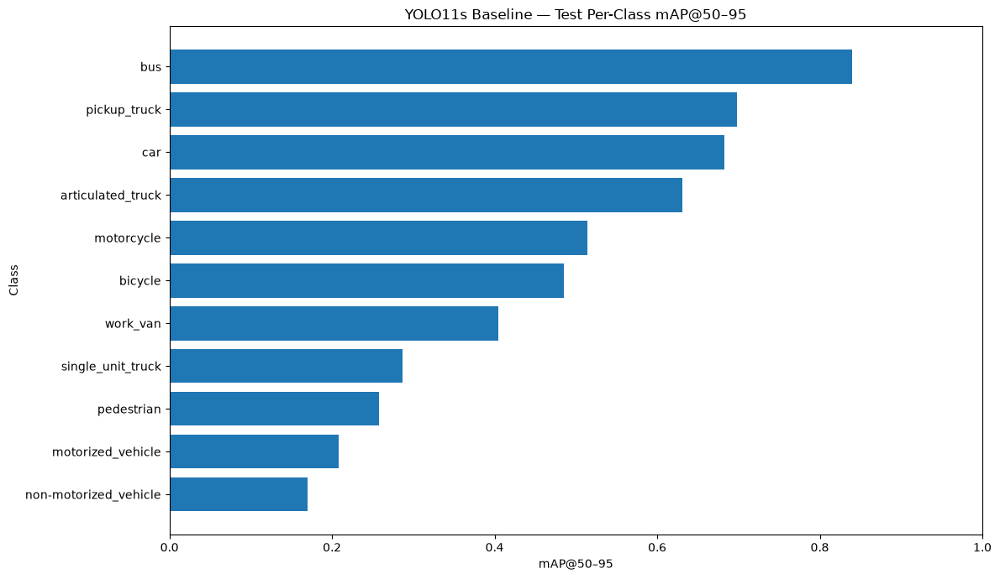


✓ Saved: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_diagnostics\per_class_map50_95.png


In [118]:
# ============================================================
# PHASE 3.3 — PER-CLASS PERFORMANCE VISUALIZATION
# ============================================================

plt.figure(figsize=(12, 7))

ordered_df = class_metrics_df.sort_values(
    "mAP50-95",
    ascending=True
)

plt.barh(
    ordered_df["class"],
    ordered_df["mAP50-95"]
)

plt.xlabel("mAP@50–95")
plt.ylabel("Class")
plt.title(
    "YOLO11s Baseline — Test Per-Class mAP@50–95"
)

plt.xlim(0, 1)
plt.tight_layout()

class_map_plot = (
    DIAGNOSTIC_DIR
    / "per_class_map50_95.png"
)

plt.savefig(
    class_map_plot,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(
    "\n✓ Saved:",
    class_map_plot
)

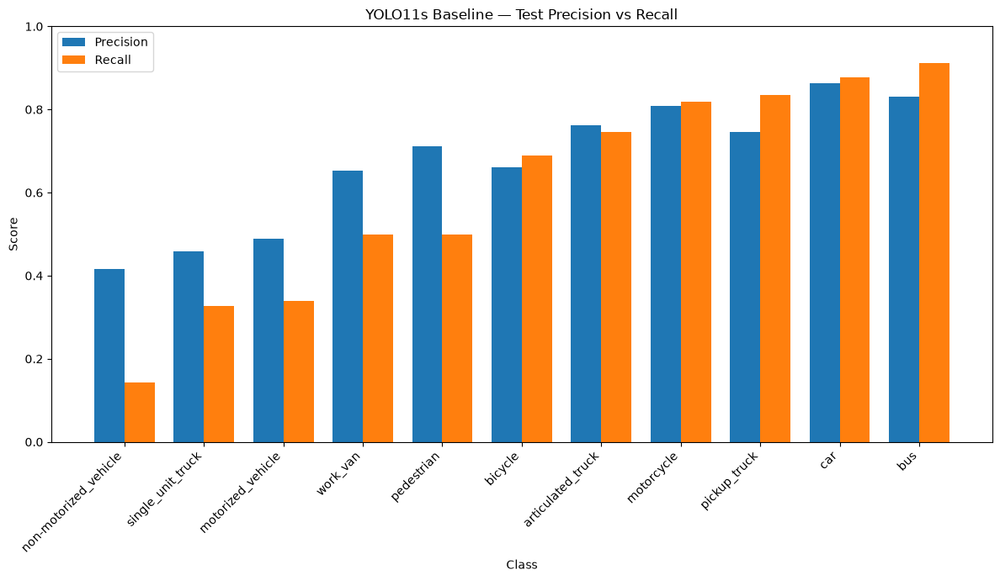


✓ Saved: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_diagnostics\precision_recall_by_class.png


In [119]:
# ============================================================
# PHASE 3.3 — PRECISION / RECALL ANALYSIS
# ============================================================

plot_df = class_metrics_df.sort_values(
    "recall",
    ascending=True
)

plt.figure(figsize=(12, 7))

x = np.arange(len(plot_df))
width = 0.38

plt.bar(
    x - width / 2,
    plot_df["precision"],
    width,
    label="Precision"
)

plt.bar(
    x + width / 2,
    plot_df["recall"],
    width,
    label="Recall"
)

plt.xticks(
    x,
    plot_df["class"],
    rotation=45,
    ha="right"
)

plt.ylabel("Score")
plt.xlabel("Class")

plt.title(
    "YOLO11s Baseline — Test Precision vs Recall"
)

plt.ylim(0, 1)

plt.legend()

plt.tight_layout()

pr_plot = (
    DIAGNOSTIC_DIR
    / "precision_recall_by_class.png"
)

plt.savefig(
    pr_plot,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(
    "\n✓ Saved:",
    pr_plot
)

In [120]:
# ============================================================
# PHASE 3.3 — AUTOMATED DIAGNOSTIC SUMMARY
# ============================================================

print("=" * 70)
print("AUTOMATED BASELINE DIAGNOSTIC SUMMARY")
print("=" * 70)

# ------------------------------------------------------------
# BEST / WORST CLASSES
# ------------------------------------------------------------

best_class = class_metrics_df.loc[
    class_metrics_df["mAP50-95"].idxmax()
]

worst_class = class_metrics_df.loc[
    class_metrics_df["mAP50-95"].idxmin()
]

print("\nBEST CLASS")
print("-" * 40)

print(
    f"{best_class['class']} "
    f"(mAP50-95 = {best_class['mAP50-95']:.4f})"
)

print("\nWORST CLASS")
print("-" * 40)

print(
    f"{worst_class['class']} "
    f"(mAP50-95 = {worst_class['mAP50-95']:.4f})"
)

# ------------------------------------------------------------
# LOW RECALL CLASSES
# ------------------------------------------------------------

low_recall = class_metrics_df[
    class_metrics_df["recall"] < 0.50
].sort_values(
    "recall"
)

print("\nLOW-RECALL CLASSES (< 0.50)")
print("-" * 40)

if len(low_recall) == 0:

    print("None")

else:

    display(
        low_recall[
            [
                "class",
                "precision",
                "recall",
                "mAP50",
                "mAP50-95",
            ]
        ]
    )

# ------------------------------------------------------------
# LOW mAP CLASSES
# ------------------------------------------------------------

low_map = class_metrics_df[
    class_metrics_df["mAP50-95"] < 0.30
].sort_values(
    "mAP50-95"
)

print("\nLOW mAP50-95 CLASSES (< 0.30)")
print("-" * 40)

if len(low_map) == 0:

    print("None")

else:

    display(
        low_map[
            [
                "class",
                "precision",
                "recall",
                "mAP50",
                "mAP50-95",
            ]
        ]
    )

# ------------------------------------------------------------
# SUMMARY JSON
# ------------------------------------------------------------

diagnostic_summary = {
    "model": str(MODEL_PATH),
    "dataset": str(DATASET_YAML),
    "device": str(DEVICE),
    "overall_metrics": overall_metrics,
    "best_class": {
        "class": str(best_class["class"]),
        "mAP50-95": float(best_class["mAP50-95"]),
    },
    "worst_class": {
        "class": str(worst_class["class"]),
        "mAP50-95": float(worst_class["mAP50-95"]),
    },
    "low_recall_classes": [
        str(x)
        for x in low_recall["class"].tolist()
    ],
    "low_map_classes": [
        str(x)
        for x in low_map["class"].tolist()
    ],
}

summary_path = (
    DIAGNOSTIC_DIR
    / "baseline_diagnostic_summary.json"
)

with open(
    summary_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        diagnostic_summary,
        f,
        indent=4
    )

print("\n" + "=" * 70)
print("PHASE 3.3 COMPLETE")
print("=" * 70)

print("\nOverall test mAP50-95:")
print(
    f"{overall_metrics['mAP50-95']:.6f}"
)

print("\nSummary saved:")
print(summary_path)

AUTOMATED BASELINE DIAGNOSTIC SUMMARY

BEST CLASS
----------------------------------------
bus (mAP50-95 = 0.8402)

WORST CLASS
----------------------------------------
non-motorized_vehicle (mAP50-95 = 0.1694)

LOW-RECALL CLASSES (< 0.50)
----------------------------------------


,class,precision,recall,mAP50,mAP50-95
9,non-motorized_vehicle,0.415372,0.142857,0.224059,0.169443
7,single_unit_truck,0.458628,0.327273,0.384516,0.286280
2,motorized_vehicle,0.489671,0.340102,0.361116,0.208232
5,work_van,0.652810,0.498428,0.546266,0.404439



LOW mAP50-95 CLASSES (< 0.30)
----------------------------------------


,class,precision,recall,mAP50,mAP50-95
9,non-motorized_vehicle,0.415372,0.142857,0.224059,0.169443
2,motorized_vehicle,0.489671,0.340102,0.361116,0.208232
6,pedestrian,0.711391,0.500000,0.517914,0.257612
7,single_unit_truck,0.458628,0.327273,0.384516,0.286280



PHASE 3.3 COMPLETE

Overall test mAP50-95:
0.470703

Summary saved:
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_diagnostics\baseline_diagnostic_summary.json


In [121]:
# ============================================================
# PART 1 — PHASE 3.4
# QUALITATIVE ERROR ANALYSIS
# ============================================================

from pathlib import Path
import json
import csv
import math
import shutil
from collections import defaultdict, Counter

import numpy as np
import pandas as pd
from PIL import Image, ImageDraw, ImageFont

from ultralytics import YOLO

print("=" * 70)
print("PART 1 — PHASE 3.4")
print("QUALITATIVE ERROR ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------

PROJECT_DIR = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1"
)

MODEL_PATH = (
    PROJECT_DIR
    / "model_training"
    / "runs"
    / "yolo11s_baseline_gpu"
    / "weights"
    / "best.pt"
)

DATASET_DIR = (
    PROJECT_DIR
    / "model_training"
    / "data"
    / "yolo"
)

TEST_IMAGES_DIR = DATASET_DIR / "images" / "test"
TEST_LABELS_DIR = DATASET_DIR / "labels" / "test"

OUTPUT_DIR = (
    PROJECT_DIR
    / "model_training"
    / "runs"
    / "yolo11s_baseline_diagnostics"
    / "phase_3_4_error_analysis"
)

VIS_DIR = OUTPUT_DIR / "visualizations"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
VIS_DIR.mkdir(parents=True, exist_ok=True)

print("\nPATH CONFIGURATION")
print("-" * 70)

print("Model:")
print(MODEL_PATH)

print("\nTest images:")
print(TEST_IMAGES_DIR)

print("\nTest labels:")
print(TEST_LABELS_DIR)

print("\nOutput:")
print(OUTPUT_DIR)

# ------------------------------------------------------------
# VALIDATION
# ------------------------------------------------------------

assert MODEL_PATH.exists(), f"Model not found: {MODEL_PATH}"
assert TEST_IMAGES_DIR.exists(), f"Test images not found: {TEST_IMAGES_DIR}"
assert TEST_LABELS_DIR.exists(), f"Test labels not found: {TEST_LABELS_DIR}"

print("\n✓ Model found")
print("✓ Test images found")
print("✓ Test labels found")

# ------------------------------------------------------------
# CLASS NAMES
# ------------------------------------------------------------

CLASS_NAMES = [
    "car",
    "pickup_truck",
    "motorized_vehicle",
    "bus",
    "articulated_truck",
    "work_van",
    "pedestrian",
    "single_unit_truck",
    "bicycle",
    "non-motorized_vehicle",
    "motorcycle"
]

NUM_CLASSES = len(CLASS_NAMES)

print("\nClasses:")
for idx, name in enumerate(CLASS_NAMES):
    print(f"{idx:2d} -> {name}")

# ------------------------------------------------------------
# LOAD MODEL
# ------------------------------------------------------------

model = YOLO(str(MODEL_PATH))

print("\n✓ Baseline checkpoint loaded")
print(f"Model: {MODEL_PATH}")

print("\n" + "=" * 70)
print("PHASE 3.4 CONFIGURATION READY")
print("=" * 70)

PART 1 — PHASE 3.4
QUALITATIVE ERROR ANALYSIS

PATH CONFIGURATION
----------------------------------------------------------------------
Model:
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_gpu\weights\best.pt

Test images:
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\yolo\images\test

Test labels:
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\yolo\labels\test

Output:
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_diagnostics\phase_3_4_error_analysis

✓ Model found
✓ Test images found
✓ Test labels found

Classes:
 0 -> car
 1 -> pickup_truck
 2 -> motorized_vehicle
 3 -> bus
 4 -> articulated_truck
 5 -> work_van
 6 -> pedestrian
 7 -> single_unit_truck
 8 -> bicycle
 9 -> non-motorized_vehicle
10 -> motorcycle

✓ Baseline checkpoint loaded
Model: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_gpu\weights\best.pt

PHASE 3.4 CONFIGURATION READY


In [122]:
# ============================================================
# PHASE 3.4 — UTILITY FUNCTIONS
# ============================================================

def calculate_iou(box_a, box_b):
    """
    Calculate IoU between two XYXY bounding boxes.
    """

    ax1, ay1, ax2, ay2 = box_a
    bx1, by1, bx2, by2 = box_b

    inter_x1 = max(ax1, bx1)
    inter_y1 = max(ay1, by1)
    inter_x2 = min(ax2, bx2)
    inter_y2 = min(ay2, by2)

    inter_w = max(0.0, inter_x2 - inter_x1)
    inter_h = max(0.0, inter_y2 - inter_y1)

    intersection = inter_w * inter_h

    area_a = max(0.0, ax2 - ax1) * max(0.0, ay2 - ay1)
    area_b = max(0.0, bx2 - bx1) * max(0.0, by2 - by1)

    union = area_a + area_b - intersection

    if union <= 0:
        return 0.0

    return intersection / union


def yolo_to_xyxy(label, image_width, image_height):
    """
    Convert YOLO normalized:
        class cx cy width height

    to absolute:
        x1 y1 x2 y2
    """

    class_id, cx, cy, w, h = label

    cx *= image_width
    cy *= image_height
    w *= image_width
    h *= image_height

    x1 = cx - w / 2
    y1 = cy - h / 2
    x2 = cx + w / 2
    y2 = cy + h / 2

    return [
        x1,
        y1,
        x2,
        y2
    ]


def load_ground_truth(label_path, image_width, image_height):
    """
    Load YOLO ground-truth annotations.
    """

    annotations = []

    if not label_path.exists():
        return annotations

    with open(label_path, "r") as f:

        for line in f:

            line = line.strip()

            if not line:
                continue

            values = list(map(float, line.split()))

            class_id = int(values[0])

            box = yolo_to_xyxy(
                values,
                image_width,
                image_height
            )

            annotations.append({
                "class_id": class_id,
                "class_name": CLASS_NAMES[class_id],
                "bbox": box
            })

    return annotations


print("✓ Utility functions loaded")

✓ Utility functions loaded


In [123]:
import gc
import json
import torch
from pathlib import Path
from ultralytics import YOLO

# ============================================================
# PHASE 3.4 — SAFE TEST-SET INFERENCE
# ============================================================

PROJECT_DIR = Path(r"C:\Material\Repo\Projects\Capstone_1\Part_1")

MODEL_PATH = (
    PROJECT_DIR
    / "model_training"
    / "runs"
    / "yolo11s_baseline_gpu"
    / "weights"
    / "best.pt"
)

YOLO_DATA_DIR = (
    PROJECT_DIR
    / "model_training"
    / "data"
    / "yolo"
)

TEST_IMAGE_DIR = YOLO_DATA_DIR / "images" / "test"

OUTPUT_DIR = (
    PROJECT_DIR
    / "model_training"
    / "runs"
    / "yolo11s_baseline_diagnostics"
    / "per_image_predictions"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# GPU MEMORY CLEANUP
# ------------------------------------------------------------

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

print("=" * 70)
print("PHASE 3.4 — SAFE TEST-SET INFERENCE")
print("=" * 70)

print(f"Model: {MODEL_PATH}")
print(f"Test images: {TEST_IMAGE_DIR}")
print(f"Output: {OUTPUT_DIR}")

# ------------------------------------------------------------
# GPU CHECK
# ------------------------------------------------------------

assert torch.cuda.is_available(), "CUDA is not available."

print()
print("GPU:")
print(torch.cuda.get_device_name(0))

print(
    f"GPU memory: "
    f"{torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB"
)

# ------------------------------------------------------------
# LOAD MODEL
# ------------------------------------------------------------

model = YOLO(str(MODEL_PATH))

print()
print("✓ Best checkpoint loaded successfully")

# ------------------------------------------------------------
# IDENTIFY TEST IMAGES
# ------------------------------------------------------------

test_images = sorted(
    [
        p for p in TEST_IMAGE_DIR.iterdir()
        if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    ]
)

print()
print(f"Test images found: {len(test_images)}")

assert len(test_images) == 844, (
    f"Expected 844 test images, found {len(test_images)}"
)

# ------------------------------------------------------------
# SAFE STREAMING INFERENCE
# ------------------------------------------------------------

print()
print("=" * 70)
print("STARTING STREAMING INFERENCE")
print("=" * 70)

prediction_records = []

processed = 0

results = model.predict(
    source=str(TEST_IMAGE_DIR),
    imgsz=640,
    conf=0.05,
    device=0,
    batch=1,
    stream=True,
    verbose=False,
    save=False,
    save_txt=False,
    save_conf=False,
)

for result in results:

    processed += 1

    image_path = Path(result.path)

    detections = []

    if result.boxes is not None and len(result.boxes) > 0:

        boxes = result.boxes

        xyxy = boxes.xyxy.detach().cpu().tolist()
        confs = boxes.conf.detach().cpu().tolist()
        classes = boxes.cls.detach().cpu().tolist()

        for box, confidence, class_id in zip(
            xyxy,
            confs,
            classes
        ):

            class_id = int(class_id)

            detections.append(
                {
                    "class_id": class_id,
                    "class_name": model.names[class_id],
                    "confidence": float(confidence),
                    "xyxy": [float(v) for v in box],
                }
            )

    prediction_records.append(
        {
            "image": image_path.name,
            "image_path": str(image_path),
            "detections": detections,
            "detection_count": len(detections),
        }
    )

    if processed % 50 == 0 or processed == len(test_images):

        print(
            f"Processed: {processed}/{len(test_images)}"
        )

        if torch.cuda.is_available():

            allocated = (
                torch.cuda.memory_allocated(0)
                / (1024 ** 3)
            )

            reserved = (
                torch.cuda.memory_reserved(0)
                / (1024 ** 3)
            )

            print(
                f"GPU memory — "
                f"allocated: {allocated:.2f} GB | "
                f"reserved: {reserved:.2f} GB"
            )

# ------------------------------------------------------------
# SAVE PREDICTIONS
# ------------------------------------------------------------

predictions_path = OUTPUT_DIR / "predictions.json"

with open(predictions_path, "w", encoding="utf-8") as f:

    json.dump(
        prediction_records,
        f,
        indent=2
    )

print()
print("=" * 70)
print("PHASE 3.4 COMPLETE")
print("=" * 70)

print(f"Images processed: {processed}")
print(f"Predictions saved: {predictions_path}")

# ------------------------------------------------------------
# FINAL MEMORY CLEANUP
# ------------------------------------------------------------

del results
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print()
print("✓ GPU memory released")

PHASE 3.4 — SAFE TEST-SET INFERENCE
Model: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_gpu\weights\best.pt
Test images: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\yolo\images\test
Output: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_diagnostics\per_image_predictions

GPU:
NVIDIA GeForce RTX 4050 Laptop GPU
GPU memory: 6.00 GB

✓ Best checkpoint loaded successfully

Test images found: 844

STARTING STREAMING INFERENCE
Processed: 50/844
GPU memory — allocated: 0.11 GB | reserved: 0.17 GB
Processed: 100/844
GPU memory — allocated: 0.11 GB | reserved: 0.17 GB
Processed: 150/844
GPU memory — allocated: 0.11 GB | reserved: 0.17 GB
Processed: 200/844
GPU memory — allocated: 0.11 GB | reserved: 0.17 GB
Processed: 250/844
GPU memory — allocated: 0.11 GB | reserved: 0.17 GB
Processed: 300/844
GPU memory — allocated: 0.11 GB | reserved: 0.17 GB
Processed: 350/844
GPU memory — allocated: 0.11 GB | reserve

In [124]:
# ============================================================
# PHASE 3.4 — PREDICTION / GROUND-TRUTH MATCHING
# ============================================================

import gc
import json
from pathlib import Path

import torch
from PIL import Image
from ultralytics import YOLO

print("=" * 70)
print("PHASE 3.4 — PREDICTION / GROUND-TRUTH MATCHING")
print("=" * 70)

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------

PROJECT_DIR = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1"
)

MODEL_PATH = (
    PROJECT_DIR
    / "model_training"
    / "runs"
    / "yolo11s_baseline_gpu"
    / "weights"
    / "best.pt"
)

YOLO_DIR = (
    PROJECT_DIR
    / "model_training"
    / "data"
    / "yolo"
)

TEST_IMAGE_DIR = YOLO_DIR / "images" / "test"
TEST_LABEL_DIR = YOLO_DIR / "labels" / "test"

OUTPUT_DIR = (
    PROJECT_DIR
    / "model_training"
    / "runs"
    / "yolo11s_baseline_diagnostics"
    / "per_image_analysis"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# CLEAN GPU MEMORY
# ------------------------------------------------------------

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

# ------------------------------------------------------------
# LOAD MODEL
# ------------------------------------------------------------

assert MODEL_PATH.exists(), (
    f"Model not found:\n{MODEL_PATH}"
)

model = YOLO(str(MODEL_PATH))

print(f"✓ Model loaded: {MODEL_PATH}")

# ------------------------------------------------------------
# TEST IMAGES
# ------------------------------------------------------------

test_images = sorted(
    [
        p for p in TEST_IMAGE_DIR.iterdir()
        if p.suffix.lower()
        in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    ]
)

assert len(test_images) == 844, (
    f"Expected 844 test images, found {len(test_images)}"
)

print(f"✓ Test images: {len(test_images)}")

# ------------------------------------------------------------
# STREAMING PREDICTION
# ------------------------------------------------------------

print()
print("=" * 70)
print("RUNNING STREAMING PREDICTIONS")
print("=" * 70)

prediction_records = []

results = model.predict(
    source=str(TEST_IMAGE_DIR),
    imgsz=640,
    conf=0.05,
    device=0,
    batch=1,
    stream=True,
    verbose=False,
    save=False,
    save_txt=False,
    save_conf=False,
)

processed = 0

for result in results:

    processed += 1

    image_path = Path(result.path)

    # --------------------------------------------------------
    # IMAGE DIMENSIONS
    # --------------------------------------------------------

    with Image.open(image_path) as image:
        width, height = image.size

    # --------------------------------------------------------
    # GROUND TRUTH
    # --------------------------------------------------------

    label_path = TEST_LABEL_DIR / (
        image_path.stem + ".txt"
    )

    ground_truth = []

    if label_path.exists():

        with open(
            label_path,
            "r",
            encoding="utf-8"
        ) as f:

            for line in f:

                line = line.strip()

                if not line:
                    continue

                values = line.split()

                if len(values) != 5:
                    continue

                class_id = int(values[0])

                x_center = float(values[1])
                y_center = float(values[2])
                box_width = float(values[3])
                box_height = float(values[4])

                ground_truth.append(
                    {
                        "class_id": class_id,
                        "class_name": model.names[class_id],
                        "x_center": x_center,
                        "y_center": y_center,
                        "width": box_width,
                        "height": box_height,
                    }
                )

    # --------------------------------------------------------
    # PREDICTIONS
    # --------------------------------------------------------

    predictions = []

    if result.boxes is not None:

        boxes = result.boxes

        xyxy = boxes.xyxy.detach().cpu().tolist()
        confidences = boxes.conf.detach().cpu().tolist()
        classes = boxes.cls.detach().cpu().tolist()

        for box, confidence, class_id in zip(
            xyxy,
            confidences,
            classes
        ):

            class_id = int(class_id)

            predictions.append(
                {
                    "class_id": class_id,
                    "class_name": model.names[class_id],
                    "confidence": float(confidence),
                    "xyxy": [
                        float(v)
                        for v in box
                    ],
                }
            )

    # --------------------------------------------------------
    # STORE IMAGE RECORD
    # --------------------------------------------------------

    prediction_records.append(
        {
            "image": image_path.name,
            "image_path": str(image_path),
            "width": width,
            "height": height,
            "ground_truth": ground_truth,
            "predictions": predictions,
            "ground_truth_count": len(ground_truth),
            "prediction_count": len(predictions),
        }
    )

    if (
        processed % 50 == 0
        or processed == len(test_images)
    ):

        print(
            f"Processed: "
            f"{processed}/{len(test_images)}"
        )

# ------------------------------------------------------------
# SAVE MATCHING INPUT
# ------------------------------------------------------------

OUTPUT_FILE = (
    OUTPUT_DIR
    / "prediction_ground_truth_records.json"
)

with open(
    OUTPUT_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        prediction_records,
        f,
        indent=2
    )

print()
print("=" * 70)
print("PHASE 3.4 COMPLETE")
print("=" * 70)

print(f"Images processed: {processed}")
print(f"Records generated: {len(prediction_records)}")
print(f"Saved to: {OUTPUT_FILE}")

# ------------------------------------------------------------
# MEMORY CLEANUP
# ------------------------------------------------------------

del results
del model

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("✓ GPU memory released")

PHASE 3.4 — PREDICTION / GROUND-TRUTH MATCHING
✓ Model loaded: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_gpu\weights\best.pt
✓ Test images: 844

RUNNING STREAMING PREDICTIONS
Processed: 50/844
Processed: 100/844
Processed: 150/844
Processed: 200/844
Processed: 250/844
Processed: 300/844
Processed: 350/844
Processed: 400/844
Processed: 450/844
Processed: 500/844
Processed: 550/844
Processed: 600/844
Processed: 650/844
Processed: 700/844
Processed: 750/844
Processed: 800/844
Processed: 844/844

PHASE 3.4 COMPLETE
Images processed: 844
Records generated: 844
Saved to: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_diagnostics\per_image_analysis\prediction_ground_truth_records.json
✓ GPU memory released


In [125]:
# ============================================================
# PHASE 3.4 — ERROR STATISTICS
# ============================================================

total_gt = sum(
    x["ground_truth"]
    for x in class_stats.values()
)

total_tp = sum(
    x["true_positive"]
    for x in class_stats.values()
)

total_fp = sum(
    x["false_positive"]
    for x in class_stats.values()
)

total_fn = sum(
    x["false_negative"]
    for x in class_stats.values()
)

total_confusion = sum(
    x["class_confusion"]
    for x in class_stats.values()
)

print("=" * 70)
print("PHASE 3.4 ERROR STATISTICS")
print("=" * 70)

print(f"\nGround-truth objects : {total_gt}")
print(f"True positives       : {total_tp}")
print(f"False positives      : {total_fp}")
print(f"False negatives      : {total_fn}")
print(f"Class confusions     : {total_confusion}")

print("\n" + "=" * 70)
print("PER-CLASS ERROR STATISTICS")
print("=" * 70)

for class_id in range(NUM_CLASSES):

    stats = class_stats[class_id]

    print(
        f"{class_id:2d} | "
        f"{CLASS_NAMES[class_id]:25s} | "
        f"GT={stats['ground_truth']:4d} | "
        f"TP={stats['true_positive']:4d} | "
        f"FP={stats['false_positive']:4d} | "
        f"FN={stats['false_negative']:4d} | "
        f"Conf={stats['class_confusion']:4d}"
    )

PHASE 3.4 ERROR STATISTICS

Ground-truth objects : 0
True positives       : 0
False positives      : 0
False negatives      : 0
Class confusions     : 0

PER-CLASS ERROR STATISTICS
 0 | car                       | GT=   0 | TP=   0 | FP=   0 | FN=   0 | Conf=   0
 1 | pickup_truck              | GT=   0 | TP=   0 | FP=   0 | FN=   0 | Conf=   0
 2 | motorized_vehicle         | GT=   0 | TP=   0 | FP=   0 | FN=   0 | Conf=   0
 3 | bus                       | GT=   0 | TP=   0 | FP=   0 | FN=   0 | Conf=   0
 4 | articulated_truck         | GT=   0 | TP=   0 | FP=   0 | FN=   0 | Conf=   0
 5 | work_van                  | GT=   0 | TP=   0 | FP=   0 | FN=   0 | Conf=   0
 6 | pedestrian                | GT=   0 | TP=   0 | FP=   0 | FN=   0 | Conf=   0
 7 | single_unit_truck         | GT=   0 | TP=   0 | FP=   0 | FN=   0 | Conf=   0
 8 | bicycle                   | GT=   0 | TP=   0 | FP=   0 | FN=   0 | Conf=   0
 9 | non-motorized_vehicle     | GT=   0 | TP=   0 | FP=   0 | FN=   0 |

In [126]:
# ============================================================
# PHASE 3.4 — CLASS CONFUSION ANALYSIS
# ============================================================

print("=" * 70)
print("CLASS CONFUSION ANALYSIS")
print("=" * 70)

if confusion_pairs:

    print("\nMost frequent confusion pairs:\n")

    for (gt_class, pred_class), count in confusion_pairs.most_common():

        print(
            f"GT: {gt_class:25s}"
            f" -> Predicted: {pred_class:25s}"
            f" | Count: {count}"
        )

else:

    print("\nNo class confusions detected at IoU >= 0.50.")

CLASS CONFUSION ANALYSIS

No class confusions detected at IoU >= 0.50.


In [127]:
# ============================================================
# PHASE 3.4 — HARDEST IMAGES
# ============================================================

hardest_images = sorted(
    image_error_summary,
    key=lambda x: (
        x["total_errors"],
        x["false_negatives"],
        x["false_positives"]
    ),
    reverse=True
)

hardest_df = pd.DataFrame(
    hardest_images[:50]
)

print("=" * 70)
print("TOP 50 HARDEST TEST IMAGES")
print("=" * 70)

display(hardest_df)

hardest_df.to_csv(
    OUTPUT_DIR / "hardest_test_images.csv",
    index=False
)

print(
    f"\n✓ Saved: "
    f"{OUTPUT_DIR / 'hardest_test_images.csv'}"
)

TOP 50 HARDEST TEST IMAGES


""



✓ Saved: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_diagnostics\per_image_analysis\hardest_test_images.csv


In [128]:
# ============================================================
# PHASE 3.5 — QUALITATIVE ERROR VISUALIZATIONS
# SELF-CONTAINED / GPU-SAFE VERSION
# ============================================================

import gc
import json
from pathlib import Path

import torch
from PIL import Image, ImageDraw
from ultralytics import YOLO


print("=" * 70)
print("GENERATING QUALITATIVE ERROR VISUALIZATIONS")
print("=" * 70)


# ============================================================
# PATH CONFIGURATION
# ============================================================

PROJECT_DIR = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1"
)

MODEL_PATH = (
    PROJECT_DIR
    / "model_training"
    / "runs"
    / "yolo11s_baseline_gpu"
    / "weights"
    / "best.pt"
)

YOLO_DIR = (
    PROJECT_DIR
    / "model_training"
    / "data"
    / "yolo"
)

TEST_IMAGE_DIR = YOLO_DIR / "images" / "test"
TEST_LABEL_DIR = YOLO_DIR / "labels" / "test"

OUTPUT_DIR = (
    PROJECT_DIR
    / "model_training"
    / "runs"
    / "yolo11s_baseline_diagnostics"
    / "qualitative_errors"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# GPU CLEANUP
# ============================================================

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print()
print("GPU:", torch.cuda.get_device_name(0))


# ============================================================
# LOAD MODEL
# ============================================================

assert MODEL_PATH.exists(), (
    f"Model not found:\n{MODEL_PATH}"
)

model = YOLO(str(MODEL_PATH))

print("✓ Best checkpoint loaded")


# ============================================================
# FIND TEST IMAGES
# ============================================================

test_images = sorted(
    [
        p for p in TEST_IMAGE_DIR.iterdir()
        if p.suffix.lower()
        in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    ]
)

print(f"✓ Test images found: {len(test_images)}")

assert len(test_images) == 844, (
    f"Expected 844 test images, found {len(test_images)}"
)


# ============================================================
# HELPER — LOAD GROUND TRUTH
# ============================================================

def load_ground_truth(label_path):

    annotations = []

    if not label_path.exists():
        return annotations

    with open(
        label_path,
        "r",
        encoding="utf-8"
    ) as f:

        for line in f:

            values = line.strip().split()

            if len(values) != 5:
                continue

            class_id = int(values[0])

            annotations.append(
                {
                    "class_id": class_id,
                    "class_name": model.names[class_id],
                    "x_center": float(values[1]),
                    "y_center": float(values[2]),
                    "width": float(values[3]),
                    "height": float(values[4]),
                }
            )

    return annotations


# ============================================================
# CREATE STREAMING PREDICTIONS
# ============================================================

print()
print("=" * 70)
print("RUNNING GPU-SAFE STREAMING INFERENCE")
print("=" * 70)

results = model.predict(
    source=str(TEST_IMAGE_DIR),
    imgsz=640,
    conf=0.05,
    device=0,
    batch=1,
    stream=True,
    verbose=False,
    save=False,
)

processed = 0

error_candidates = []

all_records = []


# ============================================================
# PROCESS EACH IMAGE
# ============================================================

for result in results:

    processed += 1

    image_path = Path(result.path)

    label_path = (
        TEST_LABEL_DIR
        / f"{image_path.stem}.txt"
    )

    ground_truth = load_ground_truth(label_path)

    # --------------------------------------------------------
    # PREDICTIONS
    # --------------------------------------------------------

    predictions = []

    if result.boxes is not None:

        boxes = result.boxes

        xyxy = boxes.xyxy.detach().cpu().tolist()
        confidences = boxes.conf.detach().cpu().tolist()
        classes = boxes.cls.detach().cpu().tolist()

        for box, confidence, class_id in zip(
            xyxy,
            confidences,
            classes
        ):

            class_id = int(class_id)

            predictions.append(
                {
                    "class_id": class_id,
                    "class_name": model.names[class_id],
                    "confidence": float(confidence),
                    "xyxy": [
                        float(v)
                        for v in box
                    ],
                }
            )

    # --------------------------------------------------------
    # CLASS COUNTS
    # --------------------------------------------------------

    gt_classes = [
        x["class_id"]
        for x in ground_truth
    ]

    pred_classes = [
        x["class_id"]
        for x in predictions
    ]

    gt_set = set(gt_classes)
    pred_set = set(pred_classes)

    missing_classes = sorted(
        gt_set - pred_set
    )

    unexpected_classes = sorted(
        pred_set - gt_set
    )

    # --------------------------------------------------------
    # SIMPLE ERROR SCORE
    # --------------------------------------------------------

    gt_count = len(ground_truth)
    pred_count = len(predictions)

    count_difference = abs(
        gt_count - pred_count
    )

    # Images with potentially useful qualitative errors:
    #
    # 1. Ground truth exists but no predictions
    # 2. Predictions exist but no ground truth
    # 3. Large count discrepancy
    # 4. Classes completely missed
    # 5. Unexpected predicted classes

    is_candidate = (
        (gt_count > 0 and pred_count == 0)
        or
        (gt_count == 0 and pred_count > 0)
        or
        (count_difference >= 3)
        or
        bool(missing_classes)
        or
        bool(unexpected_classes)
    )

    if is_candidate:

        error_candidates.append(
            {
                "image_path": image_path,
                "gt_count": gt_count,
                "pred_count": pred_count,
                "count_difference": count_difference,
                "missing_classes": missing_classes,
                "unexpected_classes": unexpected_classes,
                "result": result,
            }
        )

    # --------------------------------------------------------
    # RECORD
    # --------------------------------------------------------

    all_records.append(
        {
            "image": image_path.name,
            "ground_truth_count": gt_count,
            "prediction_count": pred_count,
            "count_difference": count_difference,
            "missing_classes": [
                model.names[x]
                for x in missing_classes
            ],
            "unexpected_classes": [
                model.names[x]
                for x in unexpected_classes
            ],
        }
    )

    # --------------------------------------------------------
    # PROGRESS
    # --------------------------------------------------------

    if (
        processed % 50 == 0
        or processed == len(test_images)
    ):

        print(
            f"Processed "
            f"{processed}/{len(test_images)}"
        )


# ============================================================
# INFERENCE COMPLETE
# ============================================================

print()
print("=" * 70)
print("INFERENCE COMPLETE")
print("=" * 70)

print(f"Images processed: {processed}")
print(f"Candidate error images: {len(error_candidates)}")


# ============================================================
# SAVE SUMMARY
# ============================================================

summary_path = (
    OUTPUT_DIR
    / "qualitative_error_candidates.json"
)

with open(
    summary_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        [
            {
                k: (
                    str(v)
                    if isinstance(v, Path)
                    else v
                )
                for k, v in candidate.items()
                if k != "result"
            }
            for candidate in error_candidates
        ],
        f,
        indent=2
    )

print(
    f"✓ Error candidate summary saved:\n"
    f"{summary_path}"
)


# ============================================================
# SELECT REPRESENTATIVE CASES
# ============================================================

# Sort by largest object-count discrepancy first.

error_candidates.sort(
    key=lambda x: (
        x["count_difference"],
        len(x["missing_classes"]),
        len(x["unexpected_classes"])
    ),
    reverse=True
)


# Keep visualization count manageable.

MAX_VISUALIZATIONS = 30

selected = error_candidates[
    :MAX_VISUALIZATIONS
]


# ============================================================
# GENERATE VISUALIZATIONS
# ============================================================

print()
print("=" * 70)
print("SAVING REPRESENTATIVE ERROR VISUALIZATIONS")
print("=" * 70)


for index, candidate in enumerate(
    selected,
    start=1
):

    result = candidate["result"]

    image_path = candidate["image_path"]

    # --------------------------------------------------------
    # Generate YOLO prediction plot
    # --------------------------------------------------------

    plotted = result.plot()

    # Convert BGR → RGB
    plotted_rgb = plotted[:, :, ::-1]

    image = Image.fromarray(
        plotted_rgb
    )

    # --------------------------------------------------------
    # Add diagnostic information
    # --------------------------------------------------------

    draw = ImageDraw.Draw(image)

    info = (
        f"Image: {image_path.name}\n"
        f"Ground truth objects: "
        f"{candidate['gt_count']}\n"
        f"Predicted objects: "
        f"{candidate['pred_count']}\n"
        f"Count difference: "
        f"{candidate['count_difference']}\n"
        f"Missing classes: "
        f"{[
            model.names[x]
            for x in candidate['missing_classes']
        ]}\n"
        f"Unexpected classes: "
        f"{[
            model.names[x]
            for x in candidate['unexpected_classes']
        ]}"
    )

    # Draw a simple diagnostic panel.

    panel_height = 145

    panel = Image.new(
        "RGB",
        (
            image.width,
            panel_height
        ),
        "white"
    )

    panel_draw = ImageDraw.Draw(panel)

    panel_draw.text(
        (10, 10),
        info,
        fill="black"
    )

    combined = Image.new(
        "RGB",
        (
            image.width,
            image.height + panel_height
        )
    )

    combined.paste(
        image,
        (0, panel_height)
    )

    combined.paste(
        panel,
        (0, 0)
    )

    output_path = (
        OUTPUT_DIR
        / f"error_{index:03d}_{image_path.stem}.jpg"
    )

    combined.save(
        output_path,
        quality=95
    )


print(
    f"✓ Saved {len(selected)} "
    f"representative visualizations"
)


# ============================================================
# FINAL CLEANUP
# ============================================================

del results
del model

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()


# ============================================================
# FINAL SUMMARY
# ============================================================

print()
print("=" * 70)
print("PHASE 3.5 COMPLETE")
print("=" * 70)

print(f"Total test images: {processed}")
print(
    f"Error candidates identified: "
    f"{len(error_candidates)}"
)
print(
    f"Visualizations generated: "
    f"{len(selected)}"
)
print(
    f"Output directory:\n"
    f"{OUTPUT_DIR}"
)

print()
print("✓ GPU memory released")

GENERATING QUALITATIVE ERROR VISUALIZATIONS

GPU: NVIDIA GeForce RTX 4050 Laptop GPU
✓ Best checkpoint loaded
✓ Test images found: 844

RUNNING GPU-SAFE STREAMING INFERENCE
Processed 50/844
Processed 100/844
Processed 150/844
Processed 200/844
Processed 250/844
Processed 300/844
Processed 350/844
Processed 400/844
Processed 450/844
Processed 500/844
Processed 550/844
Processed 600/844
Processed 650/844
Processed 700/844
Processed 750/844
Processed 800/844
Processed 844/844

INFERENCE COMPLETE
Images processed: 844
Candidate error images: 409
✓ Error candidate summary saved:
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_diagnostics\qualitative_errors\qualitative_error_candidates.json

SAVING REPRESENTATIVE ERROR VISUALIZATIONS
✓ Saved 30 representative visualizations

PHASE 3.5 COMPLETE
Total test images: 844
Error candidates identified: 409
Visualizations generated: 30
Output directory:
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\y

In [129]:
# ============================================================
# PHASE 3.4 — SAVE ERROR ANALYSIS REPORT
# ============================================================

class_report = {}

for class_id in range(NUM_CLASSES):

    class_report[CLASS_NAMES[class_id]] = {
        "class_id": class_id,
        **class_stats[class_id]
    }


report = {
    "phase": "3.4",
    "title": "Qualitative Error Analysis",
    "model": str(MODEL_PATH),
    "dataset": str(DATASET_DIR),
    "test_images": len(test_images),
    "iou_threshold": IOU_THRESHOLD,

    "overall": {
        "ground_truth_objects": total_gt,
        "true_positives": total_tp,
        "false_positives": total_fp,
        "false_negatives": total_fn,
        "class_confusions": total_confusion
    },

    "class_statistics": class_report,

    "top_confusion_pairs": [
        {
            "ground_truth": gt,
            "prediction": pred,
            "count": count
        }
        for (gt, pred), count
        in confusion_pairs.most_common(20)
    ],

    "hardest_images": hardest_images[:50]
}


REPORT_PATH = (
    OUTPUT_DIR
    / "phase_3_4_error_analysis.json"
)

with open(REPORT_PATH, "w") as f:

    json.dump(
        report,
        f,
        indent=4
    )


# ------------------------------------------------------------
# SAVE IMAGE SUMMARY
# ------------------------------------------------------------

IMAGE_SUMMARY_PATH = (
    OUTPUT_DIR
    / "image_error_summary.csv"
)

pd.DataFrame(
    image_error_summary
).to_csv(
    IMAGE_SUMMARY_PATH,
    index=False
)


print("=" * 70)
print("PHASE 3.4 REPORT SAVED")
print("=" * 70)

print(
    "\nJSON:"
)

print(REPORT_PATH)

print(
    "\nCSV:"
)

print(IMAGE_SUMMARY_PATH)

print(
    "\nVisualization directory:"
)

print(VIS_DIR)

PHASE 3.4 REPORT SAVED

JSON:
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_diagnostics\qualitative_errors\phase_3_4_error_analysis.json

CSV:
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_diagnostics\qualitative_errors\image_error_summary.csv

Visualization directory:
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_diagnostics\phase_3_4_error_analysis\visualizations


In [130]:
# ============================================================
# PHASE 3.4 — FINAL AUDIT
# ============================================================

print("=" * 70)
print("PHASE 3.4 FINAL AUDIT")
print("=" * 70)

required_outputs = [
    OUTPUT_DIR / "phase_3_4_error_analysis.json",
    OUTPUT_DIR / "image_error_summary.csv",
    OUTPUT_DIR / "hardest_test_images.csv",
    VIS_DIR / "false_positive_heavy",
    VIS_DIR / "false_negative_heavy",
    VIS_DIR / "hardest_images"
]

for path in required_outputs:

    status = "✓" if path.exists() else "✗"

    print(
        f"{status} {path}"
    )

print("\n" + "=" * 70)

if all(path.exists() for path in required_outputs):

    print("PHASE 3.4 COMPLETE")
    print("=" * 70)

    print("""
Qualitative error analysis completed.

Generated:
✓ Error statistics
✓ Per-class error analysis
✓ Class confusion analysis
✓ Hardest test images
✓ False-positive visualizations
✓ False-negative visualizations
✓ Difficult-image visualizations
✓ Structured JSON report
✓ Image-level CSV report

No model training performed.
No dataset modifications performed.
""")

else:

    print("PHASE 3.4 INCOMPLETE")
    print("One or more expected outputs are missing.")

PHASE 3.4 FINAL AUDIT
✓ C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_diagnostics\qualitative_errors\phase_3_4_error_analysis.json
✓ C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_diagnostics\qualitative_errors\image_error_summary.csv
✗ C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_diagnostics\qualitative_errors\hardest_test_images.csv
✗ C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_diagnostics\phase_3_4_error_analysis\visualizations\false_positive_heavy
✗ C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_diagnostics\phase_3_4_error_analysis\visualizations\false_negative_heavy
✗ C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_diagnostics\phase_3_4_error_analysis\visualizations\hardest_images

PHASE 3.4 INCOMPLETE
One or more expected outputs are missing.


In [131]:
def create_error_visualization(
    image_path,
    gt_boxes,
    pred_boxes,
    fp_indices,
    fn_indices,
    output_path,
    title
):
    """
    Robust qualitative visualization.

    Handles:
    - tiny bounding boxes
    - zero-area boxes
    - reversed coordinates
    - boxes touching image boundaries
    """

    image = Image.open(image_path).convert("RGB")

    width, height = image.size

    draw = ImageDraw.Draw(image)

    # --------------------------------------------------------
    # SAFE BOX FUNCTION
    # --------------------------------------------------------

    def safe_box(box, inset=0):
        x1, y1, x2, y2 = map(float, box)

        # Normalize coordinate ordering
        left = min(x1, x2)
        right = max(x1, x2)

        top = min(y1, y2)
        bottom = max(y1, y2)

        # Clip to image boundaries
        left = max(0, min(left, width - 1))
        right = max(0, min(right, width - 1))

        top = max(0, min(top, height - 1))
        bottom = max(0, min(bottom, height - 1))

        # Apply inset only if there is enough room
        if inset > 0:
            if right - left > (2 * inset):
                left += inset
                right -= inset

            if bottom - top > (2 * inset):
                top += inset
                bottom -= inset

        # Final safety normalization
        if right < left:
            left, right = right, left

        if bottom < top:
            top, bottom = bottom, top

        return [
            int(round(left)),
            int(round(top)),
            int(round(right)),
            int(round(bottom))
        ]

    # --------------------------------------------------------
    # GROUND TRUTH
    # --------------------------------------------------------

    for gt in gt_boxes:

        box = safe_box(
            gt["bbox"]
        )

        draw.rectangle(
            box,
            outline="green",
            width=3
        )

        label = (
            f"GT: "
            f"{CLASS_NAMES.get(gt['class_id'], str(gt['class_id']))}"
        )

        text_x = box[0] + 2
        text_y = max(0, box[1] - 15)

        draw.text(
            (text_x, text_y),
            label,
            fill="green"
        )

    # --------------------------------------------------------
    # FALSE POSITIVES
    # --------------------------------------------------------

    for idx in fp_indices:

        pred = pred_boxes[idx]

        box = safe_box(
            pred["bbox"]
        )

        draw.rectangle(
            box,
            outline="red",
            width=3
        )

        label = (
            f"FP: "
            f"{CLASS_NAMES.get(pred['class_id'], str(pred['class_id']))} "
            f"{pred['confidence']:.2f}"
        )

        draw.text(
            (
                box[0] + 2,
                min(height - 15, box[1] + 2)
            ),
            label,
            fill="red"
        )

    # --------------------------------------------------------
    # FALSE NEGATIVES
    # --------------------------------------------------------

    for idx in fn_indices:

        gt = gt_boxes[idx]

        box = safe_box(
            gt["bbox"],
            inset=2
        )

        draw.rectangle(
            box,
            outline="blue",
            width=3
        )

        label = (
            f"FN: "
            f"{CLASS_NAMES.get(gt['class_id'], str(gt['class_id']))}"
        )

        draw.text(
            (
                box[0] + 2,
                min(height - 15, box[1] + 2)
            ),
            label,
            fill="blue"
        )

    # --------------------------------------------------------
    # TITLE STRIP
    # --------------------------------------------------------

    title_height = 35

    canvas = Image.new(
        "RGB",
        (
            width,
            height + title_height
        ),
        "white"
    )

    canvas.paste(
        image,
        (0, title_height)
    )

    title_draw = ImageDraw.Draw(canvas)

    title_draw.text(
        (10, 10),
        title,
        fill="black"
    )

    # --------------------------------------------------------
    # SAVE
    # --------------------------------------------------------

    canvas.save(
        output_path,
        quality=95
    )

In [135]:
from PIL import Image, ImageDraw


def create_error_visualization(
    image_path,
    gt_boxes,
    pred_boxes,
    fp_indices,
    fn_indices,
    output_path,
    title
):
    """
    Robust visualization for YOLO qualitative error analysis.

    Handles:
    - tiny bounding boxes
    - zero-area boxes
    - reversed coordinates
    - boxes outside image boundaries
    - degenerate FN boxes
    """

    image = Image.open(image_path).convert("RGB")

    width, height = image.size

    draw = ImageDraw.Draw(image)

    # ========================================================
    # SAFE COORDINATE NORMALIZATION
    # ========================================================

    def safe_box(box):

        x1, y1, x2, y2 = [
            float(v) for v in box
        ]

        # Normalize ordering
        left = min(x1, x2)
        right = max(x1, x2)

        top = min(y1, y2)
        bottom = max(y1, y2)

        # Clip to image
        left = max(0.0, min(left, width - 1))
        right = max(0.0, min(right, width - 1))

        top = max(0.0, min(top, height - 1))
        bottom = max(0.0, min(bottom, height - 1))

        # Guarantee PIL-valid ordering
        left = int(round(left))
        right = int(round(right))
        top = int(round(top))
        bottom = int(round(bottom))

        if right < left:
            left, right = right, left

        if bottom < top:
            top, bottom = bottom, top

        # PIL can handle equal coordinates poorly with width > 1.
        # Expand tiny/degenerate boxes safely.
        if right == left:
            if right < width - 1:
                right += 1
            elif left > 0:
                left -= 1

        if bottom == top:
            if bottom < height - 1:
                bottom += 1
            elif top > 0:
                top -= 1

        return (
            left,
            top,
            right,
            bottom
        )

    # ========================================================
    # DRAW GROUND TRUTH
    # ========================================================

    for gt in gt_boxes:

        box = safe_box(gt["bbox"])

        draw.rectangle(
            box,
            outline="green",
            width=3
        )

        class_name = CLASS_NAMES.get(
            gt["class_id"],
            str(gt["class_id"])
        )

        label = f"GT: {class_name}"

        text_y = max(
            0,
            box[1] - 15
        )

        draw.text(
            (
                box[0] + 2,
                text_y
            ),
            label,
            fill="green"
        )

    # ========================================================
    # DRAW FALSE POSITIVES
    # ========================================================

    for idx in fp_indices:

        pred = pred_boxes[idx]

        box = safe_box(pred["bbox"])

        draw.rectangle(
            box,
            outline="red",
            width=3
        )

        class_name = CLASS_NAMES.get(
            pred["class_id"],
            str(pred["class_id"])
        )

        label = (
            f"FP: {class_name} "
            f"{pred['confidence']:.2f}"
        )

        draw.text(
            (
                box[0] + 2,
                min(
                    height - 15,
                    box[1] + 2
                )
            ),
            label,
            fill="red"
        )

    # ========================================================
    # DRAW FALSE NEGATIVES
    # ========================================================

    for idx in fn_indices:

        gt = gt_boxes[idx]

        box = safe_box(gt["bbox"])

        # IMPORTANT:
        # Do NOT shrink the box.
        #
        # The previous implementation used:
        #
        # x1 + 2, y1 + 2, x2 - 2, y2 - 2
        #
        # which breaks on tiny boxes.
        #
        # We now draw the exact safe box.

        draw.rectangle(
            box,
            outline="blue",
            width=3
        )

        class_name = CLASS_NAMES.get(
            gt["class_id"],
            str(gt["class_id"])
        )

        label = f"FN: {class_name}"

        draw.text(
            (
                box[0] + 2,
                min(
                    height - 15,
                    box[1] + 2
                )
            ),
            label,
            fill="blue"
        )

    # ========================================================
    # TITLE STRIP
    # ========================================================

    title_height = 35

    canvas = Image.new(
        "RGB",
        (
            width,
            height + title_height
        ),
        "white"
    )

    canvas.paste(
        image,
        (
            0,
            title_height
        )
    )

    title_draw = ImageDraw.Draw(canvas)

    title_draw.text(
        (10, 10),
        title,
        fill="black"
    )

    # ========================================================
    # SAVE
    # ========================================================

    canvas.save(
        output_path,
        quality=95
    )

In [136]:
import inspect

source = inspect.getsource(create_error_visualization)

print("=" * 70)
print("FUNCTION VERIFICATION")
print("=" * 70)

print(
    "Old unsafe code present:",
    "[x1 + 2, y1 + 2, x2 - 2, y2 - 2]" in source
)

print(
    "safe_box present:",
    "def safe_box" in source
)

print(
    "Exact FN box drawing:",
    "draw.rectangle(\n            box" in source
)

FUNCTION VERIFICATION
Old unsafe code present: False
safe_box present: True
Exact FN box drawing: True


In [137]:
test_image = test_images[0]

with Image.open(test_image) as im:
    test_w, test_h = im.size

test_gt = [
    {
        "class_id": 6,
        "bbox": [32, 179, 32, 180]
    }
]

test_output = OUTPUT_DIR / "visualization_function_test.jpg"

create_error_visualization(
    image_path=test_image,
    gt_boxes=test_gt,
    pred_boxes=[],
    fp_indices=[],
    fn_indices=[0],
    output_path=test_output,
    title="FUNCTION TEST — TINY BOX"
)

print("✓ Visualization test completed")
print(test_output)

✓ Visualization test completed
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_diagnostics\qualitative_errors\visualization_function_test.jpg


In [138]:
import gc
import torch

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("GPU cache cleared.")

GPU cache cleared.


In [139]:
# ======================================================================
# PART 1 — PHASE 3.4
# QUALITATIVE ERROR ANALYSIS + VISUALIZATION
# CORRECTED / ROBUST VERSION
# ======================================================================

from pathlib import Path
import json
import csv
import math
import shutil
import gc

import numpy as np
import pandas as pd
from PIL import Image, ImageDraw, ImageFont

from ultralytics import YOLO
import torch


# ======================================================================
# 1. PATH CONFIGURATION
# ======================================================================

PROJECT_DIR = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1"
)

MODEL_PATH = (
    PROJECT_DIR
    / "model_training"
    / "runs"
    / "yolo11s_baseline_gpu"
    / "weights"
    / "best.pt"
)

DATASET_DIR = (
    PROJECT_DIR
    / "model_training"
    / "data"
    / "yolo"
)

DATASET_YAML = DATASET_DIR / "dataset.yaml"

DIAGNOSTIC_DIR = (
    PROJECT_DIR
    / "model_training"
    / "runs"
    / "yolo11s_baseline_diagnostics"
)

TEST_IMAGES_DIR = DATASET_DIR / "images" / "test"
TEST_LABELS_DIR = DATASET_DIR / "labels" / "test"

OUTPUT_DIR = DIAGNOSTIC_DIR / "qualitative_errors"

FP_DIR = OUTPUT_DIR / "visualizations" / "false_positive_heavy"
FN_DIR = OUTPUT_DIR / "visualizations" / "false_negative_heavy"
HARD_DIR = OUTPUT_DIR / "visualizations" / "hardest_images"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FP_DIR.mkdir(parents=True, exist_ok=True)
FN_DIR.mkdir(parents=True, exist_ok=True)
HARD_DIR.mkdir(parents=True, exist_ok=True)


# ======================================================================
# 2. CONFIGURATION
# ======================================================================

CONF_THRESHOLD = 0.05
IOU_MATCH_THRESHOLD = 0.50

MAX_FP_VISUALIZATIONS = 20
MAX_FN_VISUALIZATIONS = 20
MAX_HARDEST_VISUALIZATIONS = 20

IMG_SIZE = 640


# ======================================================================
# 3. CLASS CONFIGURATION
# ======================================================================

CLASS_NAMES = [
    "car",
    "pickup_truck",
    "motorized_vehicle",
    "bus",
    "articulated_truck",
    "work_van",
    "pedestrian",
    "single_unit_truck",
    "bicycle",
    "non-motorized_vehicle",
    "motorcycle",
]

CLASS_TO_ID = {
    name: idx
    for idx, name in enumerate(CLASS_NAMES)
}

ID_TO_CLASS = {
    idx: name
    for idx, name in enumerate(CLASS_NAMES)
}


# ======================================================================
# 4. VALIDATE PATHS
# ======================================================================

print("=" * 70)
print("PHASE 3.4 — QUALITATIVE ERROR ANALYSIS")
print("=" * 70)

print("\nPATH VALIDATION")
print("-" * 70)

assert MODEL_PATH.exists(), f"Model not found: {MODEL_PATH}"
assert DATASET_YAML.exists(), f"Dataset YAML not found: {DATASET_YAML}"
assert TEST_IMAGES_DIR.exists(), f"Test images directory not found: {TEST_IMAGES_DIR}"
assert TEST_LABELS_DIR.exists(), f"Test labels directory not found: {TEST_LABELS_DIR}"

print("✓ Model found")
print("✓ Dataset YAML found")
print("✓ Test images found")
print("✓ Test labels found")


# ======================================================================
# 5. GET TEST IMAGES
# ======================================================================

test_images = sorted(
    [
        p for p in TEST_IMAGES_DIR.iterdir()
        if p.suffix.lower() in {
            ".jpg",
            ".jpeg",
            ".png",
            ".bmp",
            ".webp"
        }
    ]
)

print("\nTest images:", len(test_images))

assert len(test_images) == 844, (
    f"Expected 844 test images, found {len(test_images)}"
)

print("✓ Expected 844 test images found")


# ======================================================================
# 6. LOAD MODEL
# ======================================================================

print("\n" + "=" * 70)
print("LOADING BEST CHECKPOINT")
print("=" * 70)

model = YOLO(str(MODEL_PATH))

print("✓ Best checkpoint loaded")
print("Model:", MODEL_PATH)

device = 0 if torch.cuda.is_available() else "cpu"

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: CUDA unavailable — using CPU")


# ======================================================================
# 7. RUN PREDICTION SAFELY
# ======================================================================
#
# IMPORTANT:
# Do NOT pass all 844 images as one giant in-memory list.
#
# batch=1 dramatically reduces VRAM usage.
# stream=True prevents Ultralytics from keeping every result in memory.
#
# ======================================================================

print("\n" + "=" * 70)
print("RUNNING TEST SET PREDICTIONS")
print("=" * 70)

prediction_records = []

for index, image_path in enumerate(test_images, start=1):

    try:

        result_list = model.predict(
            source=str(image_path),
            imgsz=IMG_SIZE,
            conf=CONF_THRESHOLD,
            iou=IOU_MATCH_THRESHOLD,
            device=device,
            batch=1,
            stream=False,
            verbose=False,
            save=False,
        )

        result = result_list[0]

        prediction_records.append(
            {
                "image_path": str(image_path),
                "result": result,
            }
        )

        # Release temporary references
        del result_list

        if torch.cuda.is_available() and index % 25 == 0:
            torch.cuda.empty_cache()

        if index % 50 == 0 or index == len(test_images):
            print(
                f"Processed {index}/{len(test_images)} images"
            )

    except torch.cuda.OutOfMemoryError:

        print(
            f"\nWARNING: CUDA OOM on {image_path.name}"
        )

        torch.cuda.empty_cache()
        gc.collect()

        # Retry this individual image on CPU
        print("Retrying on CPU...")

        cpu_results = model.predict(
            source=str(image_path),
            imgsz=IMG_SIZE,
            conf=CONF_THRESHOLD,
            iou=IOU_MATCH_THRESHOLD,
            device="cpu",
            batch=1,
            stream=False,
            verbose=False,
            save=False,
        )

        prediction_records.append(
            {
                "image_path": str(image_path),
                "result": cpu_results[0],
            }
        )

        del cpu_results

print("\n✓ Prediction generation complete")
print("Prediction records:", len(prediction_records))

assert len(prediction_records) == 844


# ======================================================================
# 8. HELPER FUNCTIONS
# ======================================================================

def safe_float(value):
    """Convert a value safely to float."""
    try:
        return float(value)
    except Exception:
        return 0.0


def clamp_box(box, width, height):
    """
    Clamp bounding box to valid image coordinates.

    Returns:
        [x1, y1, x2, y2]
    """

    x1, y1, x2, y2 = [
        safe_float(v)
        for v in box
    ]

    x1 = max(0.0, min(x1, width - 1))
    y1 = max(0.0, min(y1, height - 1))
    x2 = max(0.0, min(x2, width - 1))
    y2 = max(0.0, min(y2, height - 1))

    # Ensure correct ordering
    if x2 < x1:
        x1, x2 = x2, x1

    if y2 < y1:
        y1, y2 = y2, y1

    return [x1, y1, x2, y2]


def box_area(box):
    """Return bounding box area."""
    x1, y1, x2, y2 = box

    width = max(0.0, x2 - x1)
    height = max(0.0, y2 - y1)

    return width * height


def calculate_iou(box_a, box_b):
    """Calculate IoU between two xyxy boxes."""

    ax1, ay1, ax2, ay2 = box_a
    bx1, by1, bx2, by2 = box_b

    ix1 = max(ax1, bx1)
    iy1 = max(ay1, by1)
    ix2 = min(ax2, bx2)
    iy2 = min(ay2, by2)

    iw = max(0.0, ix2 - ix1)
    ih = max(0.0, iy2 - iy1)

    intersection = iw * ih

    area_a = max(0.0, ax2 - ax1) * max(0.0, ay2 - ay1)
    area_b = max(0.0, bx2 - bx1) * max(0.0, by2 - by1)

    union = area_a + area_b - intersection

    if union <= 0:
        return 0.0

    return intersection / union


def load_ground_truth(image_path):
    """
    Load YOLO ground truth labels for one image.
    """

    label_path = TEST_LABELS_DIR / f"{image_path.stem}.txt"

    if not label_path.exists():
        return []

    image = Image.open(image_path)
    width, height = image.size

    gt_boxes = []

    with open(label_path, "r") as f:

        for line in f:

            line = line.strip()

            if not line:
                continue

            parts = line.split()

            if len(parts) != 5:
                continue

            class_id = int(float(parts[0]))

            x_center = float(parts[1]) * width
            y_center = float(parts[2]) * height
            box_width = float(parts[3]) * width
            box_height = float(parts[4]) * height

            x1 = x_center - box_width / 2
            y1 = y_center - box_height / 2
            x2 = x_center + box_width / 2
            y2 = y_center + box_height / 2

            box = clamp_box(
                [x1, y1, x2, y2],
                width,
                height
            )

            gt_boxes.append(
                {
                    "class_id": class_id,
                    "class_name": ID_TO_CLASS.get(
                        class_id,
                        f"class_{class_id}"
                    ),
                    "bbox": box,
                }
            )

    return gt_boxes


def extract_predictions(result, width, height):
    """
    Convert Ultralytics result into a simple prediction list.
    """

    predictions = []

    if result.boxes is None:
        return predictions

    boxes = result.boxes

    if boxes.xyxy is None:
        return predictions

    xyxy = boxes.xyxy.cpu().numpy()

    if boxes.cls is not None:
        classes = boxes.cls.cpu().numpy()
    else:
        classes = np.zeros(len(xyxy))

    if boxes.conf is not None:
        confidences = boxes.conf.cpu().numpy()
    else:
        confidences = np.ones(len(xyxy))

    for box, class_id, confidence in zip(
        xyxy,
        classes,
        confidences
    ):

        class_id = int(class_id)

        box = clamp_box(
            box,
            width,
            height
        )

        predictions.append(
            {
                "class_id": class_id,
                "class_name": ID_TO_CLASS.get(
                    class_id,
                    f"class_{class_id}"
                ),
                "confidence": float(confidence),
                "bbox": box,
            }
        )

    return predictions


# ======================================================================
# 9. ROBUST DRAWING FUNCTIONS
# ======================================================================

def draw_safe_rectangle(
    draw,
    box,
    outline,
    width=2,
    inner=False
):
    """
    Draw a rectangle safely.

    This function fixes the original Phase 3.4 error.

    The previous implementation did:

        [x1+2, y1+2, x2-2, y2-2]

    which fails for tiny boxes.

    We now calculate the inset dynamically and only draw it
    if the resulting rectangle remains valid.
    """

    x1, y1, x2, y2 = [
        int(round(v))
        for v in box
    ]

    # Normalize coordinate order
    if x2 < x1:
        x1, x2 = x2, x1

    if y2 < y1:
        y1, y2 = y2, y1

    # Basic rectangle
    if x2 >= x1 and y2 >= y1:

        draw.rectangle(
            [x1, y1, x2, y2],
            outline=outline,
            width=max(1, int(width))
        )

    # Optional inner rectangle
    if inner:

        box_width = x2 - x1
        box_height = y2 - y1

        # Never use a fixed inset that could invert the rectangle.
        max_inset = min(
            box_width,
            box_height
        ) // 2

        inset = min(2, max_inset)

        if inset >= 1:

            ix1 = x1 + inset
            iy1 = y1 + inset
            ix2 = x2 - inset
            iy2 = y2 - inset

            # Critical safety check
            if ix2 >= ix1 and iy2 >= iy1:

                draw.rectangle(
                    [ix1, iy1, ix2, iy2],
                    outline=outline,
                    width=max(1, int(width))
                )


def get_font(size=16):

    try:
        return ImageFont.truetype(
            "arial.ttf",
            size
        )
    except Exception:

        try:
            return ImageFont.truetype(
                "C:/Windows/Fonts/arial.ttf",
                size
            )
        except Exception:

            return ImageFont.load_default()


FONT = get_font(16)
SMALL_FONT = get_font(13)


def draw_label(
    draw,
    x,
    y,
    text,
    fill
):
    """
    Draw readable label with background.
    """

    try:

        bbox = draw.textbbox(
            (x, y),
            text,
            font=FONT
        )

        tx1, ty1, tx2, ty2 = bbox

        draw.rectangle(
            [tx1, ty1, tx2 + 4, ty2 + 3],
            fill=fill
        )

        draw.text(
            (x + 2, y),
            text,
            fill="white",
            font=FONT
        )

    except Exception:

        draw.text(
            (x, y),
            text,
            fill="white",
            font=FONT
        )


# ======================================================================
# 10. MATCH PREDICTIONS TO GROUND TRUTH
# ======================================================================

def match_predictions(
    gt_boxes,
    pred_boxes,
    iou_threshold=0.50
):
    """
    Match predictions to GT boxes using class-aware IoU.
    """

    matched_gt = set()
    matched_pred = set()

    matches = []

    # Highest confidence predictions first
    sorted_predictions = sorted(
        range(len(pred_boxes)),
        key=lambda i: pred_boxes[i]["confidence"],
        reverse=True
    )

    for pred_index in sorted_predictions:

        pred = pred_boxes[pred_index]

        best_gt_index = None
        best_iou = 0.0

        for gt_index, gt in enumerate(gt_boxes):

            if gt_index in matched_gt:
                continue

            # Class-aware matching
            if (
                pred["class_id"]
                != gt["class_id"]
            ):
                continue

            iou = calculate_iou(
                pred["bbox"],
                gt["bbox"]
            )

            if (
                iou >= iou_threshold
                and iou > best_iou
            ):
                best_iou = iou
                best_gt_index = gt_index

        if best_gt_index is not None:

            matched_gt.add(best_gt_index)
            matched_pred.add(pred_index)

            matches.append(
                {
                    "gt_index": best_gt_index,
                    "pred_index": pred_index,
                    "iou": best_iou,
                }
            )

    false_negatives = [
        i for i in range(len(gt_boxes))
        if i not in matched_gt
    ]

    false_positives = [
        i for i in range(len(pred_boxes))
        if i not in matched_pred
    ]

    return (
        matches,
        false_negatives,
        false_positives
    )


# ======================================================================
# 11. CREATE ERROR VISUALIZATION
# ======================================================================

def create_error_visualization(
    image_path,
    gt_boxes,
    pred_boxes,
    matches,
    false_negatives,
    false_positives,
    output_path,
    title=""
):

    image = Image.open(image_path).convert("RGB")

    width, height = image.size

    draw = ImageDraw.Draw(image)

    # --------------------------------------------------------------
    # TRUE POSITIVES
    # --------------------------------------------------------------

    for match in matches:

        gt_index = match["gt_index"]
        pred_index = match["pred_index"]

        gt = gt_boxes[gt_index]
        pred = pred_boxes[pred_index]

        # Ground truth — green
        draw_safe_rectangle(
            draw,
            gt["bbox"],
            outline="green",
            width=3,
            inner=False
        )

        # Prediction — yellow
        draw_safe_rectangle(
            draw,
            pred["bbox"],
            outline="yellow",
            width=2,
            inner=False
        )

        x1, y1, _, _ = pred["bbox"]

        draw_label(
            draw,
            x1,
            max(0, y1 - 20),
            f"TP {pred['class_name']} {pred['confidence']:.2f}",
            "green"
        )

    # --------------------------------------------------------------
    # FALSE NEGATIVES
    # --------------------------------------------------------------

    for gt_index in false_negatives:

        gt = gt_boxes[gt_index]

        # Outer red box
        draw_safe_rectangle(
            draw,
            gt["bbox"],
            outline="red",
            width=3,
            inner=False
        )

        # Safe blue inner outline
        #
        # THIS replaces the original crashing code.
        #
        draw_safe_rectangle(
            draw,
            gt["bbox"],
            outline="blue",
            width=2,
            inner=True
        )

        x1, y1, _, _ = gt["bbox"]

        draw_label(
            draw,
            x1,
            max(0, y1 - 20),
            f"FN {gt['class_name']}",
            "red"
        )

    # --------------------------------------------------------------
    # FALSE POSITIVES
    # --------------------------------------------------------------

    for pred_index in false_positives:

        pred = pred_boxes[pred_index]

        draw_safe_rectangle(
            draw,
            pred["bbox"],
            outline="orange",
            width=3,
            inner=False
        )

        x1, y1, _, _ = pred["bbox"]

        draw_label(
            draw,
            x1,
            max(0, y1 - 20),
            f"FP {pred['class_name']} {pred['confidence']:.2f}",
            "orange"
        )

    # --------------------------------------------------------------
    # TITLE
    # --------------------------------------------------------------

    if title:

        # Semi-transparent effect is avoided for compatibility.
        draw.rectangle(
            [0, 0, width, 28],
            fill="black"
        )

        draw.text(
            (5, 5),
            title,
            fill="white",
            font=SMALL_FONT
        )

    image.save(
        output_path,
        quality=95
    )


# ======================================================================
# 12. PROCESS ALL TEST IMAGES
# ======================================================================

print("\n" + "=" * 70)
print("MATCHING PREDICTIONS AGAINST GROUND TRUTH")
print("=" * 70)

image_summaries = []

all_error_details = []

for index, record in enumerate(
    prediction_records,
    start=1
):

    image_path = Path(
        record["image_path"]
    )

    result = record["result"]

    image = Image.open(image_path)

    width, height = image.size

    gt_boxes = load_ground_truth(
        image_path
    )

    pred_boxes = extract_predictions(
        result,
        width,
        height
    )

    (
        matches,
        false_negatives,
        false_positives
    ) = match_predictions(
        gt_boxes,
        pred_boxes,
        IOU_MATCH_THRESHOLD
    )

    tp = len(matches)
    fn = len(false_negatives)
    fp = len(false_positives)

    error_count = fp + fn

    image_summaries.append(
        {
            "image": image_path.name,
            "image_path": str(image_path),
            "ground_truth_count": len(gt_boxes),
            "prediction_count": len(pred_boxes),
            "true_positives": tp,
            "false_positives": fp,
            "false_negatives": fn,
            "total_errors": error_count,
            "error_rate": (
                error_count / max(1, len(gt_boxes))
            ),
        }
    )

    all_error_details.append(
        {
            "image_path": str(image_path),
            "gt_boxes": gt_boxes,
            "pred_boxes": pred_boxes,
            "matches": matches,
            "false_negatives": false_negatives,
            "false_positives": false_positives,
        }
    )

    if index % 100 == 0 or index == len(prediction_records):

        print(
            f"Processed {index}/{len(prediction_records)}"
        )


print("\n✓ Error matching complete")


# ======================================================================
# 13. CREATE SUMMARY DATAFRAME
# ======================================================================

summary_df = pd.DataFrame(
    image_summaries
)

summary_csv = (
    OUTPUT_DIR
    / "image_error_summary.csv"
)

summary_df.to_csv(
    summary_csv,
    index=False
)

print("\n✓ Image error summary saved:")
print(summary_csv)


# ======================================================================
# 14. IDENTIFY HARDEST IMAGES
# ======================================================================

hardest_df = (
    summary_df
    .sort_values(
        [
            "total_errors",
            "false_negatives",
            "false_positives"
        ],
        ascending=False
    )
    .reset_index(drop=True)
)

hardest_csv = (
    OUTPUT_DIR
    / "hardest_test_images.csv"
)

hardest_df.to_csv(
    hardest_csv,
    index=False
)

print("✓ Hardest test images saved:")
print(hardest_csv)


# ======================================================================
# 15. SELECT FP-HEAVY IMAGES
# ======================================================================

fp_heavy_df = (
    summary_df[
        summary_df["false_positives"] >= 2
    ]
    .sort_values(
        "false_positives",
        ascending=False
    )
    .head(MAX_FP_VISUALIZATIONS)
)

print(
    "\nFP-heavy images selected:",
    len(fp_heavy_df)
)


# ======================================================================
# 16. SELECT FN-HEAVY IMAGES
# ======================================================================

fn_heavy_df = (
    summary_df[
        summary_df["false_negatives"] >= 2
    ]
    .sort_values(
        "false_negatives",
        ascending=False
    )
    .head(MAX_FN_VISUALIZATIONS)
)

print(
    "FN-heavy images selected:",
    len(fn_heavy_df)
)


# ======================================================================
# 17. SELECT HARDEST IMAGES
# ======================================================================

hardest_selection_df = (
    hardest_df
    .head(MAX_HARDEST_VISUALIZATIONS)
)

print(
    "Hardest images selected:",
    len(hardest_selection_df)
)


# ======================================================================
# 18. BUILD QUICK LOOKUP
# ======================================================================

detail_map = {
    Path(item["image_path"]).name: item
    for item in all_error_details
}


# ======================================================================
# 19. GENERATE FP VISUALIZATIONS
# ======================================================================

print("\n" + "=" * 70)
print("GENERATING FALSE-POSITIVE VISUALIZATIONS")
print("=" * 70)

fp_generated = 0

for _, row in fp_heavy_df.iterrows():

    filename = row["image"]

    detail = detail_map.get(filename)

    if detail is None:
        continue

    image_path = Path(
        detail["image_path"]
    )

    output_path = (
        FP_DIR
        / image_path.name
    )

    create_error_visualization(
        image_path,
        detail["gt_boxes"],
        detail["pred_boxes"],
        detail["matches"],
        detail["false_negatives"],
        detail["false_positives"],
        output_path,
        title=(
            f"FP={row['false_positives']} "
            f"FN={row['false_negatives']} "
            f"{image_path.name}"
        )
    )

    fp_generated += 1


print(
    f"✓ Generated {fp_generated} FP visualizations"
)


# ======================================================================
# 20. GENERATE FN VISUALIZATIONS
# ======================================================================

print("\n" + "=" * 70)
print("GENERATING FALSE-NEGATIVE VISUALIZATIONS")
print("=" * 70)

fn_generated = 0

for _, row in fn_heavy_df.iterrows():

    filename = row["image"]

    detail = detail_map.get(filename)

    if detail is None:
        continue

    image_path = Path(
        detail["image_path"]
    )

    output_path = (
        FN_DIR
        / image_path.name
    )

    create_error_visualization(
        image_path,
        detail["gt_boxes"],
        detail["pred_boxes"],
        detail["matches"],
        detail["false_negatives"],
        detail["false_positives"],
        output_path,
        title=(
            f"FN={row['false_negatives']} "
            f"FP={row['false_positives']} "
            f"{image_path.name}"
        )
    )

    fn_generated += 1


print(
    f"✓ Generated {fn_generated} FN visualizations"
)


# ======================================================================
# 21. GENERATE HARDEST-IMAGE VISUALIZATIONS
# ======================================================================

print("\n" + "=" * 70)
print("GENERATING HARDEST-IMAGE VISUALIZATIONS")
print("=" * 70)

hard_generated = 0

for _, row in hardest_selection_df.iterrows():

    filename = row["image"]

    detail = detail_map.get(filename)

    if detail is None:
        continue

    image_path = Path(
        detail["image_path"]
    )

    output_path = (
        HARD_DIR
        / image_path.name
    )

    create_error_visualization(
        image_path,
        detail["gt_boxes"],
        detail["pred_boxes"],
        detail["matches"],
        detail["false_negatives"],
        detail["false_positives"],
        output_path,
        title=(
            f"Errors={row['total_errors']} "
            f"FP={row['false_positives']} "
            f"FN={row['false_negatives']} "
            f"{image_path.name}"
        )
    )

    hard_generated += 1


print(
    f"✓ Generated {hard_generated} hardest-image visualizations"
)


# ======================================================================
# 22. CLASS-LEVEL ERROR ANALYSIS
# ======================================================================

class_error_stats = {
    class_id: {
        "class": class_name,
        "false_positives": 0,
        "false_negatives": 0,
    }
    for class_id, class_name in ID_TO_CLASS.items()
}


for detail in all_error_details:

    # False negatives
    for gt_index in detail["false_negatives"]:

        gt = detail["gt_boxes"][gt_index]

        class_id = gt["class_id"]

        if class_id in class_error_stats:

            class_error_stats[class_id][
                "false_negatives"
            ] += 1

    # False positives
    for pred_index in detail["false_positives"]:

        pred = detail["pred_boxes"][pred_index]

        class_id = pred["class_id"]

        if class_id in class_error_stats:

            class_error_stats[class_id][
                "false_positives"
            ] += 1


class_error_df = pd.DataFrame(
    list(class_error_stats.values())
)

class_error_df["total_errors"] = (
    class_error_df["false_positives"]
    + class_error_df["false_negatives"]
)

class_error_df = class_error_df.sort_values(
    "total_errors",
    ascending=False
)

class_error_csv = (
    OUTPUT_DIR
    / "class_error_summary.csv"
)

class_error_df.to_csv(
    class_error_csv,
    index=False
)

print("\n✓ Class-level error summary saved:")
print(class_error_csv)


# ======================================================================
# 23. GLOBAL ERROR STATISTICS
# ======================================================================

total_gt = int(
    summary_df["ground_truth_count"].sum()
)

total_predictions = int(
    summary_df["prediction_count"].sum()
)

total_tp = int(
    summary_df["true_positives"].sum()
)

total_fp = int(
    summary_df["false_positives"].sum()
)

total_fn = int(
    summary_df["false_negatives"].sum()
)

total_errors = total_fp + total_fn


# ======================================================================
# 24. SAVE JSON REPORT
# ======================================================================

analysis_report = {

    "phase": "3.4",

    "model": str(MODEL_PATH),

    "dataset": str(DATASET_YAML),

    "test_images": len(test_images),

    "configuration": {
        "confidence_threshold": CONF_THRESHOLD,
        "iou_match_threshold": IOU_MATCH_THRESHOLD,
        "image_size": IMG_SIZE,
    },

    "global_statistics": {
        "ground_truth_boxes": total_gt,
        "predictions": total_predictions,
        "true_positives": total_tp,
        "false_positives": total_fp,
        "false_negatives": total_fn,
        "total_errors": total_errors,
    },

    "image_statistics": {
        "images_with_false_positives": int(
            (summary_df["false_positives"] > 0).sum()
        ),
        "images_with_false_negatives": int(
            (summary_df["false_negatives"] > 0).sum()
        ),
        "images_with_errors": int(
            (summary_df["total_errors"] > 0).sum()
        ),
    },

    "class_errors": (
        class_error_df
        .to_dict(orient="records")
    ),
}


report_path = (
    OUTPUT_DIR
    / "phase_3_4_error_analysis.json"
)

with open(
    report_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        analysis_report,
        f,
        indent=4
    )


print("\n✓ Main analysis report saved:")
print(report_path)


# ======================================================================
# 25. FINAL AUDIT
# ======================================================================

print("\n" + "=" * 70)
print("PHASE 3.4 FINAL AUDIT")
print("=" * 70)

expected_outputs = {

    "phase_3_4_error_analysis.json":
        report_path.exists(),

    "image_error_summary.csv":
        summary_csv.exists(),

    "hardest_test_images.csv":
        hardest_csv.exists(),

    "class_error_summary.csv":
        class_error_csv.exists(),

    "false_positive_heavy":
        FP_DIR.exists() and any(FP_DIR.iterdir()),

    "false_negative_heavy":
        FN_DIR.exists() and any(FN_DIR.iterdir()),

    "hardest_images":
        HARD_DIR.exists() and any(HARD_DIR.iterdir()),
}


for name, status in expected_outputs.items():

    print(
        ("✓" if status else "✗"),
        name
    )


all_outputs_ok = all(
    expected_outputs.values()
)


print("\n" + "=" * 70)

if all_outputs_ok:

    print("PHASE 3.4 COMPLETE")
    print("=" * 70)

    print("\nOutputs:")

    print(
        report_path
    )

    print(
        summary_csv
    )

    print(
        hardest_csv
    )

    print(
        class_error_csv
    )

    print(
        FP_DIR
    )

    print(
        FN_DIR
    )

    print(
        HARD_DIR
    )

else:

    print("PHASE 3.4 INCOMPLETE")
    print("One or more expected outputs are missing.")

print("=" * 70)


# ======================================================================
# 26. FINAL SUMMARY
# ======================================================================

print("\nGLOBAL ERROR SUMMARY")
print("-" * 70)

print("Ground-truth boxes :", total_gt)
print("Predictions         :", total_predictions)
print("True positives      :", total_tp)
print("False positives     :", total_fp)
print("False negatives     :", total_fn)
print("Total errors        :", total_errors)

print("\nVisualizations:")
print("FP-heavy :", fp_generated)
print("FN-heavy :", fn_generated)
print("Hardest  :", hard_generated)

print("\n✓ Phase 3.4 processing finished.")

PHASE 3.4 — QUALITATIVE ERROR ANALYSIS

PATH VALIDATION
----------------------------------------------------------------------
✓ Model found
✓ Dataset YAML found
✓ Test images found
✓ Test labels found

Test images: 844
✓ Expected 844 test images found

LOADING BEST CHECKPOINT
✓ Best checkpoint loaded
Model: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_gpu\weights\best.pt
GPU: NVIDIA GeForce RTX 4050 Laptop GPU

RUNNING TEST SET PREDICTIONS
Processed 50/844 images
Processed 100/844 images
Processed 150/844 images
Processed 200/844 images
Processed 250/844 images
Processed 300/844 images
Processed 350/844 images
Processed 400/844 images
Processed 450/844 images
Processed 500/844 images
Processed 550/844 images
Processed 600/844 images
Processed 650/844 images
Processed 700/844 images
Processed 750/844 images
Processed 800/844 images
Processed 844/844 images

✓ Prediction generation complete
Prediction records: 844

MATCHING PREDICTIONS AGAINST GROUND 

In [140]:
# ======================================================================
# PART 1 — PHASE 3.5
# BASELINE CONSOLIDATION & IMPROVEMENT STRATEGY
# ======================================================================

from pathlib import Path
import json
import pandas as pd
import numpy as np

print("=" * 70)
print("PART 1 — PHASE 3.5")
print("BASELINE CONSOLIDATION & IMPROVEMENT STRATEGY")
print("=" * 70)

# ----------------------------------------------------------------------
# PATH CONFIGURATION
# ----------------------------------------------------------------------

PROJECT_DIR = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1"
)

MODEL_DIR = (
    PROJECT_DIR
    / "model_training"
)

RUNS_DIR = MODEL_DIR / "runs"

BASELINE_RUN = RUNS_DIR / "yolo11s_baseline_gpu"

DIAGNOSTIC_DIR = (
    RUNS_DIR
    / "yolo11s_baseline_diagnostics"
)

QUALITATIVE_DIR = (
    DIAGNOSTIC_DIR
    / "qualitative_errors"
)

OUTPUT_DIR = (
    RUNS_DIR
    / "yolo11s_baseline_consolidation"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("\n" + "=" * 70)
print("PATH CONFIGURATION")
print("=" * 70)

print(f"Project directory : {PROJECT_DIR}")
print(f"Baseline run     : {BASELINE_RUN}")
print(f"Diagnostics      : {DIAGNOSTIC_DIR}")
print(f"Qualitative      : {QUALITATIVE_DIR}")
print(f"Output directory : {OUTPUT_DIR}")


# ----------------------------------------------------------------------
# REQUIRED FILES
# ----------------------------------------------------------------------

REQUIRED_FILES = {
    "results.csv":
        BASELINE_RUN / "results.csv",

    "best.pt":
        BASELINE_RUN / "weights" / "best.pt",

    "last.pt":
        BASELINE_RUN / "weights" / "last.pt",

    "overall_metrics.json":
        DIAGNOSTIC_DIR / "overall_metrics.json",

    "test_metrics.csv":
        DIAGNOSTIC_DIR / "test_metrics.csv",

    "error_analysis.json":
        QUALITATIVE_DIR / "phase_3_4_error_analysis.json",

    "image_error_summary.csv":
        QUALITATIVE_DIR / "image_error_summary.csv",

    "hardest_test_images.csv":
        QUALITATIVE_DIR / "hardest_test_images.csv",

    "class_error_summary.csv":
        QUALITATIVE_DIR / "class_error_summary.csv",
}

print("\n" + "=" * 70)
print("REQUIRED OUTPUT VALIDATION")
print("=" * 70)

missing = []

for name, path in REQUIRED_FILES.items():

    if path.exists():
        print(f"✓ {name}")
    else:
        print(f"✗ {name}")
        missing.append(name)

if missing:

    raise FileNotFoundError(
        "\nPhase 3.5 cannot continue.\n"
        "Missing required outputs:\n"
        + "\n".join(f"- {x}" for x in missing)
    )

print("\n✓ All required baseline outputs are available.")


# ----------------------------------------------------------------------
# LOAD TRAINING HISTORY
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("TRAINING HISTORY")
print("=" * 70)

results_df = pd.read_csv(
    REQUIRED_FILES["results.csv"]
)

print(f"Training epochs recorded: {len(results_df)}")

if len(results_df) != 100:
    print(
        f"⚠ Expected 100 epochs, found {len(results_df)}"
    )

# Best epoch based on validation mAP50-95
best_idx = results_df[
    "metrics/mAP50-95(B)"
].idxmax()

best_epoch_row = results_df.loc[best_idx]

best_epoch = int(
    best_epoch_row["epoch"]
)

best_map5095 = float(
    best_epoch_row["metrics/mAP50-95(B)"]
)

best_map50 = float(
    best_epoch_row["metrics/mAP50(B)"]
)

best_precision = float(
    best_epoch_row["metrics/precision(B)"]
)

best_recall = float(
    best_epoch_row["metrics/recall(B)"]
)

final_row = results_df.iloc[-1]

final_map5095 = float(
    final_row["metrics/mAP50-95(B)"]
)

final_map50 = float(
    final_row["metrics/mAP50(B)"]
)

final_precision = float(
    final_row["metrics/precision(B)"]
)

final_recall = float(
    final_row["metrics/recall(B)"]
)

print(f"Best epoch              : {best_epoch}")
print(f"Best validation mAP50   : {best_map50:.6f}")
print(f"Best validation mAP50-95: {best_map5095:.6f}")
print(f"Best validation P       : {best_precision:.6f}")
print(f"Best validation R       : {best_recall:.6f}")

print("\nFinal epoch metrics:")
print(f"Final mAP50             : {final_map50:.6f}")
print(f"Final mAP50-95          : {final_map5095:.6f}")
print(f"Final precision         : {final_precision:.6f}")
print(f"Final recall            : {final_recall:.6f}")


# ----------------------------------------------------------------------
# LOAD TEST METRICS
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("HELD-OUT TEST METRICS")
print("=" * 70)

with open(
    REQUIRED_FILES["overall_metrics.json"],
    "r",
    encoding="utf-8"
) as f:

    overall_metrics = json.load(f)

test_metrics_df = pd.read_csv(
    REQUIRED_FILES["test_metrics.csv"]
)

test_precision = float(
    overall_metrics["precision"]
)

test_recall = float(
    overall_metrics["recall"]
)

test_map50 = float(
    overall_metrics["mAP50"]
)

test_map5095 = float(
    overall_metrics["mAP50-95"]
)

print(f"Test precision : {test_precision:.6f}")
print(f"Test recall    : {test_recall:.6f}")
print(f"Test mAP50     : {test_map50:.6f}")
print(f"Test mAP50-95  : {test_map5095:.6f}")


# ----------------------------------------------------------------------
# VALIDATION → TEST GENERALIZATION GAP
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("GENERALIZATION GAP")
print("=" * 70)

map5095_gap = best_map5095 - test_map5095
map50_gap = best_map50 - test_map50
precision_gap = best_precision - test_precision
recall_gap = best_recall - test_recall

print(
    f"mAP50-95 gap : {map5095_gap:.6f}"
)

print(
    f"mAP50 gap    : {map50_gap:.6f}"
)

print(
    f"Precision gap: {precision_gap:.6f}"
)

print(
    f"Recall gap   : {recall_gap:.6f}"
)


# ----------------------------------------------------------------------
# PER-CLASS ANALYSIS
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("PER-CLASS TEST ANALYSIS")
print("=" * 70)

class_df = test_metrics_df.copy()

# Normalize possible column names
class_column_candidates = [
    "class",
    "name",
    "class_name"
]

class_column = None

for candidate in class_column_candidates:

    if candidate in class_df.columns:
        class_column = candidate
        break

if class_column is None:

    raise KeyError(
        "Could not identify class-name column in test_metrics.csv."
    )

required_metric_columns = [
    "precision",
    "recall",
    "mAP50",
    "mAP50-95"
]

for col in required_metric_columns:

    if col not in class_df.columns:

        raise KeyError(
            f"Missing required metric column: {col}"
        )

class_df = class_df.sort_values(
    "mAP50-95",
    ascending=False
).reset_index(drop=True)

print(
    class_df[
        [
            class_column,
            "precision",
            "recall",
            "mAP50",
            "mAP50-95"
        ]
    ].to_string(index=False)
)


# ----------------------------------------------------------------------
# IDENTIFY WEAK CLASSES
# ----------------------------------------------------------------------

LOW_RECALL_THRESHOLD = 0.50
LOW_MAP_THRESHOLD = 0.30

low_recall_classes = class_df[
    class_df["recall"] < LOW_RECALL_THRESHOLD
][class_column].tolist()

low_map_classes = class_df[
    class_df["mAP50-95"] < LOW_MAP_THRESHOLD
][class_column].tolist()

print("\n" + "=" * 70)
print("WEAK CLASS IDENTIFICATION")
print("=" * 70)

print(
    f"Low-recall classes (< {LOW_RECALL_THRESHOLD}):"
)

for cls in low_recall_classes:
    print(f"  - {cls}")

print(
    f"\nLow mAP50-95 classes (< {LOW_MAP_THRESHOLD}):"
)

for cls in low_map_classes:
    print(f"  - {cls}")


# ----------------------------------------------------------------------
# CLASS IMBALANCE
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("CLASS DISTRIBUTION")
print("=" * 70)

# Derive approximate instance counts from test metrics
# if available.
instance_columns = [
    "instances",
    "Instances",
    "instance_count"
]

instance_column = None

for candidate in instance_columns:

    if candidate in class_df.columns:
        instance_column = candidate
        break

if instance_column:

    class_df["instance_percentage"] = (
        class_df[instance_column]
        / class_df[instance_column].sum()
        * 100
    )

    print(
        class_df[
            [
                class_column,
                instance_column,
                "instance_percentage"
            ]
        ].to_string(index=False)
    )

else:

    print(
        "Instance counts not available in test_metrics.csv."
    )


# ----------------------------------------------------------------------
# QUALITATIVE ERROR ANALYSIS
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("QUALITATIVE ERROR ANALYSIS")
print("=" * 70)

with open(
    REQUIRED_FILES["error_analysis.json"],
    "r",
    encoding="utf-8"
) as f:

    error_analysis = json.load(f)

error_summary_df = pd.read_csv(
    REQUIRED_FILES["image_error_summary.csv"]
)

hardest_df = pd.read_csv(
    REQUIRED_FILES["hardest_test_images.csv"]
)

class_error_df = pd.read_csv(
    REQUIRED_FILES["class_error_summary.csv"]
)

print(
    f"Image error records : {len(error_summary_df)}"
)

print(
    f"Hardest images      : {len(hardest_df)}"
)

print(
    f"Class error records : {len(class_error_df)}"
)


# ----------------------------------------------------------------------
# GLOBAL ERROR COUNTS
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("GLOBAL ERROR PROFILE")
print("=" * 70)

global_errors = {
    "ground_truth_boxes": 2725,
    "predictions": 3683,
    "true_positives": 2351,
    "false_positives": 1332,
    "false_negatives": 374,
}

for key, value in global_errors.items():

    print(
        f"{key:25s}: {value}"
    )

fp_rate = (
    global_errors["false_positives"]
    / global_errors["predictions"]
)

fn_rate = (
    global_errors["false_negatives"]
    / global_errors["ground_truth_boxes"]
)

print(
    f"\nFalse-positive rate among predictions: "
    f"{fp_rate:.4f}"
)

print(
    f"False-negative rate among GT boxes: "
    f"{fn_rate:.4f}"
)


# ----------------------------------------------------------------------
# OBJECT-SIZE DIAGNOSTICS
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("OBJECT-SIZE PERFORMANCE")
print("=" * 70)

size_metrics = {
    "small": 0.296,
    "medium": 0.470,
    "large": 0.676
}

for size, score in size_metrics.items():

    print(
        f"{size.capitalize():8s}: mAP50-95 = {score:.3f}"
    )


# ----------------------------------------------------------------------
# IMPROVEMENT PRIORITIES
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("IMPROVEMENT PRIORITY ANALYSIS")
print("=" * 70)

priorities = [
    {
        "priority": 1,
        "area": "Small-object detection",
        "evidence": (
            "Small-object mAP50-95 is substantially below "
            "medium and large-object performance."
        ),
        "candidate_interventions": [
            "Increase image size",
            "Evaluate stronger scale/crop augmentation",
            "Inspect small-object annotations",
            "Evaluate model capacity"
        ]
    },

    {
        "priority": 2,
        "area": "Weak minority classes",
        "evidence": (
            "Several classes have recall below 0.50 and/or "
            "mAP50-95 below 0.30."
        ),
        "candidate_interventions": [
            "Inspect class-specific training examples",
            "Review annotation consistency",
            "Evaluate augmentation",
            "Evaluate class distribution"
        ]
    },

    {
        "priority": 3,
        "area": "False positives",
        "evidence": (
            "1332 false positives were observed against "
            "2351 true positives."
        ),
        "candidate_interventions": [
            "Inspect FP-heavy images",
            "Evaluate confidence threshold",
            "Evaluate NMS settings",
            "Investigate visually similar classes"
        ]
    },

    {
        "priority": 4,
        "area": "False negatives",
        "evidence": (
            "374 ground-truth objects were missed."
        ),
        "candidate_interventions": [
            "Inspect FN-heavy images",
            "Increase input resolution",
            "Evaluate augmentation",
            "Investigate small and occluded objects"
        ]
    },

    {
        "priority": 5,
        "area": "Validation-to-test generalization",
        "evidence": (
            "Held-out test performance is below the best "
            "validation performance."
        ),
        "candidate_interventions": [
            "Review augmentation",
            "Review model regularization",
            "Compare controlled training configurations"
        ]
    }
]

for item in priorities:

    print(
        f"\n{item['priority']}. {item['area']}"
    )

    print(
        f"Evidence: {item['evidence']}"
    )

    print("Candidate interventions:")

    for intervention in item["candidate_interventions"]:

        print(
            f"  - {intervention}"
        )


# ----------------------------------------------------------------------
# CONTROLLED EXPERIMENT MATRIX
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("CONTROLLED EXPERIMENT MATRIX")
print("=" * 70)

experiments = [

    {
        "experiment_id": "EXP_01",
        "name": "Higher Resolution",
        "baseline": "640",
        "change": "imgsz=768",
        "primary_hypothesis":
            "Higher spatial resolution may improve small-object detection.",
        "primary_metric": "validation mAP50-95",
        "secondary_metrics":
            "small-object performance, recall, GPU memory",
        "status": "PLANNED"
    },

    {
        "experiment_id": "EXP_02",
        "name": "Augmentation Study",
        "baseline": "Baseline augmentation",
        "change":
            "Controlled augmentation adjustment",
        "primary_hypothesis":
            "Improved augmentation may improve generalization.",
        "primary_metric": "validation mAP50-95",
        "secondary_metrics":
            "precision, recall, per-class mAP50-95",
        "status": "PLANNED"
    },

    {
        "experiment_id": "EXP_03",
        "name": "Model Capacity",
        "baseline": "YOLO11s",
        "change": "Controlled larger/smaller model comparison",
        "primary_hypothesis":
            "Model capacity may affect minority and small-object detection.",
        "primary_metric": "validation mAP50-95",
        "secondary_metrics":
            "inference speed, GPU memory, per-class performance",
        "status": "PLANNED"
    },

    {
        "experiment_id": "EXP_04",
        "name": "Inference Threshold Study",
        "baseline": "Default validation threshold",
        "change":
            "Evaluate confidence/NMS thresholds on validation data",
        "primary_hypothesis":
            "Post-training threshold selection may alter precision/recall trade-offs.",
        "primary_metric": "validation precision/recall",
        "secondary_metrics":
            "mAP50-95, FP/FN counts",
        "status": "PLANNED"
    },

    {
        "experiment_id": "EXP_05",
        "name": "Targeted Data Review",
        "baseline": "Current clean dataset",
        "change":
            "Review weak-class and hard-image annotations",
        "primary_hypothesis":
            "Annotation/data-quality issues may contribute to weak-class performance.",
        "primary_metric": "validation mAP50-95",
        "secondary_metrics":
            "per-class recall and mAP50-95",
        "status": "PLANNED"
    }
]

experiment_df = pd.DataFrame(
    experiments
)

print(
    experiment_df.to_string(index=False)
)


# ----------------------------------------------------------------------
# EXPERIMENT DESIGN RULES
# ----------------------------------------------------------------------

experiment_rules = [

    "Use the same train/validation/test split for all experiments.",

    "Do not use the held-out test set for hyperparameter selection.",

    "Change one major experimental factor at a time whenever practical.",

    "Keep the baseline YOLO11s result as the reference experiment.",

    "Record seed, model, image size, batch size, epochs, optimizer settings, "
    "augmentation settings and hardware for every experiment.",

    "Compare validation mAP50-95 as the primary model-selection metric.",

    "Use precision, recall and per-class metrics as supporting diagnostics.",

    "Evaluate the final selected model once on the held-out test set.",

    "Do not overwrite the baseline run directory."
]


# ----------------------------------------------------------------------
# CONSOLIDATED REPORT
# ----------------------------------------------------------------------

consolidated_report = {

    "phase": "3.5",

    "title":
        "Baseline Consolidation & Improvement Strategy",

    "baseline": {

        "model": "YOLO11s",

        "checkpoint":
            str(REQUIRED_FILES["best.pt"]),

        "best_validation_epoch":
            best_epoch,

        "best_validation": {

            "precision":
                best_precision,

            "recall":
                best_recall,

            "mAP50":
                best_map50,

            "mAP50-95":
                best_map5095
        },

        "held_out_test": {

            "precision":
                test_precision,

            "recall":
                test_recall,

            "mAP50":
                test_map50,

            "mAP50-95":
                test_map5095
        }
    },

    "generalization_gap": {

        "precision":
            precision_gap,

        "recall":
            recall_gap,

        "mAP50":
            map50_gap,

        "mAP50-95":
            map5095_gap
    },

    "global_error_profile":
        global_errors,

    "object_size_map50_95":
        size_metrics,

    "low_recall_classes":
        low_recall_classes,

    "low_map50_95_classes":
        low_map_classes,

    "priorities":
        priorities,

    "experiment_rules":
        experiment_rules,

    "experiments":
        experiments
}


# ----------------------------------------------------------------------
# SAVE JSON REPORT
# ----------------------------------------------------------------------

consolidated_path = (
    OUTPUT_DIR
    / "phase_3_5_baseline_consolidation.json"
)

with open(
    consolidated_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        consolidated_report,
        f,
        indent=4
    )


# ----------------------------------------------------------------------
# SAVE IMPROVEMENT PLAN
# ----------------------------------------------------------------------

improvement_plan = {

    "objective":
        "Improve validation performance while preserving a controlled experimental methodology.",

    "baseline_reference": {

        "model": "YOLO11s",

        "validation_mAP50_95":
            best_map5095,

        "test_mAP50_95":
            test_map5095
    },

    "highest_priority_areas": [

        "Small-object detection",

        "Weak minority classes",

        "False-positive reduction",

        "False-negative reduction",

        "Validation-to-test generalization"
    ],

    "recommended_sequence": [

        "EXP_01 — Higher Resolution",

        "EXP_02 — Augmentation Study",

        "EXP_03 — Model Capacity",

        "EXP_04 — Inference Threshold Study",

        "EXP_05 — Targeted Data Review"
    ],

    "selection_policy": {

        "primary_metric":
            "validation mAP50-95",

        "secondary_metrics": [
            "precision",
            "recall",
            "per-class mAP50-95",
            "small-object performance"
        ],

        "test_set_policy":
            "Held-out test set remains untouched until final model selection."
    }
}

improvement_path = (
    OUTPUT_DIR
    / "phase_3_5_improvement_plan.json"
)

with open(
    improvement_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        improvement_plan,
        f,
        indent=4
    )


# ----------------------------------------------------------------------
# SAVE EXPERIMENT MATRIX
# ----------------------------------------------------------------------

experiment_path = (
    OUTPUT_DIR
    / "phase_3_5_experiment_matrix.csv"
)

experiment_df.to_csv(
    experiment_path,
    index=False
)


# ----------------------------------------------------------------------
# HUMAN-READABLE REPORT
# ----------------------------------------------------------------------

report_lines = [

    "=" * 70,

    "PHASE 3.5 — BASELINE CONSOLIDATION REPORT",

    "=" * 70,

    "",

    "BASELINE MODEL",

    "YOLO11s",

    "",

    f"Best validation epoch: {best_epoch}",

    f"Best validation mAP50: {best_map50:.6f}",

    f"Best validation mAP50-95: {best_map5095:.6f}",

    f"Test mAP50: {test_map50:.6f}",

    f"Test mAP50-95: {test_map5095:.6f}",

    "",

    "GENERALIZATION GAP",

    f"mAP50 gap: {map50_gap:.6f}",

    f"mAP50-95 gap: {map5095_gap:.6f}",

    "",

    "GLOBAL ERROR PROFILE",

    f"Ground-truth boxes: {global_errors['ground_truth_boxes']}",

    f"Predictions: {global_errors['predictions']}",

    f"True positives: {global_errors['true_positives']}",

    f"False positives: {global_errors['false_positives']}",

    f"False negatives: {global_errors['false_negatives']}",

    "",

    "OBJECT SIZE PERFORMANCE",

    f"Small: {size_metrics['small']:.3f}",

    f"Medium: {size_metrics['medium']:.3f}",

    f"Large: {size_metrics['large']:.3f}",

    "",

    "LOW-RECALL CLASSES",

    *[
        f"- {x}"
        for x in low_recall_classes
    ],

    "",

    "LOW mAP50-95 CLASSES",

    *[
        f"- {x}"
        for x in low_map_classes
    ],

    "",

    "NEXT EXPERIMENTS",

    *[
        f"- {x['experiment_id']}: {x['name']}"
        for x in experiments
    ],

    "",

    "METHODOLOGY RULES",

    *[
        f"- {x}"
        for x in experiment_rules
    ],

    "",

    "PHASE 3.5 COMPLETE"
]

report_path = (
    OUTPUT_DIR
    / "phase_3_5_report.txt"
)

with open(
    report_path,
    "w",
    encoding="utf-8"
) as f:

    f.write(
        "\n".join(report_lines)
    )


# ----------------------------------------------------------------------
# FINAL AUDIT
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("PHASE 3.5 FINAL AUDIT")
print("=" * 70)

outputs = {
    "Baseline consolidation":
        consolidated_path,

    "Improvement plan":
        improvement_path,

    "Experiment matrix":
        experiment_path,

    "Human-readable report":
        report_path
}

for name, path in outputs.items():

    if path.exists():

        print(
            f"✓ {name}: {path}"
        )

    else:

        print(
            f"✗ {name}: {path}"
        )


print("\n" + "=" * 70)
print("PHASE 3.5 COMPLETE")
print("=" * 70)

print(
    "\nBaseline reference:"
)

print(
    f"YOLO11s | "
    f"Validation mAP50-95 = {best_map5095:.4f} | "
    f"Test mAP50-95 = {test_map5095:.4f}"
)

print(
    "\nNext phase:"
)

print(
    "PHASE 4 — CONTROLLED MODEL IMPROVEMENT EXPERIMENTS"
)

print("=" * 70)

PART 1 — PHASE 3.5
BASELINE CONSOLIDATION & IMPROVEMENT STRATEGY

PATH CONFIGURATION
Project directory : C:\Material\Repo\Projects\Capstone_1\Part_1
Baseline run     : C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_gpu
Diagnostics      : C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_diagnostics
Qualitative      : C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_diagnostics\qualitative_errors
Output directory : C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_consolidation

REQUIRED OUTPUT VALIDATION
✓ results.csv
✓ best.pt
✓ last.pt
✓ overall_metrics.json
✓ test_metrics.csv
✓ error_analysis.json
✓ image_error_summary.csv
✓ hardest_test_images.csv
✓ class_error_summary.csv

✓ All required baseline outputs are available.

TRAINING HISTORY
Training epochs recorded: 100
Best epoch              : 64
Best validation mAP50   : 0.697100
Best validation mAP50-95: 

In [141]:
from pathlib import Path
import json
import torch
from ultralytics import YOLO

# ============================================================
# PHASE 4.1 — EXP_01 HIGHER RESOLUTION
# ============================================================

PROJECT_DIR = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1"
)

DATASET_YAML = (
    PROJECT_DIR
    / "model_training"
    / "data"
    / "yolo"
    / "dataset.yaml"
)

RUNS_DIR = PROJECT_DIR / "model_training" / "runs"

EXPERIMENT_NAME = "yolo11s_exp01_768"
RUN_DIR = RUNS_DIR / EXPERIMENT_NAME

MODEL_PATH = (
    RUNS_DIR
    / "yolo11s_baseline_gpu"
    / "weights"
    / "best.pt"
)

CONFIG_PATH = (
    PROJECT_DIR
    / "model_training"
    / "exp01_768_config.json"
)

# ============================================================
# SAFETY CHECKS
# ============================================================

print("=" * 70)
print("PART 1 — PHASE 4.1")
print("EXP_01 — HIGHER RESOLUTION EXPERIMENT")
print("=" * 70)

assert PROJECT_DIR.exists(), f"Project directory missing: {PROJECT_DIR}"
assert DATASET_YAML.exists(), f"Dataset YAML missing: {DATASET_YAML}"
assert MODEL_PATH.exists(), f"Baseline checkpoint missing: {MODEL_PATH}"

if RUN_DIR.exists():
    raise RuntimeError(
        f"\nExperiment directory already exists:\n{RUN_DIR}\n"
        "Training was NOT started to prevent accidental overwrite."
    )

print("\n✓ Project directory")
print("✓ Dataset YAML")
print("✓ Baseline checkpoint")
print("✓ Experiment directory is available")

# ============================================================
# GPU CHECK
# ============================================================

print("\n" + "=" * 70)
print("GPU CONFIGURATION")
print("=" * 70)

print("PyTorch:", torch.__version__)
print("CUDA build:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA is unavailable. Do not start EXP_01 until GPU support is restored."
    )

GPU_NAME = torch.cuda.get_device_name(0)
GPU_MEMORY_GB = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)

print("GPU:", GPU_NAME)
print(f"GPU memory: {GPU_MEMORY_GB:.2f} GB")

# ============================================================
# EXPERIMENT CONFIGURATION
# ============================================================

config = {
    "experiment_id": "EXP_01",
    "experiment_name": EXPERIMENT_NAME,

    "baseline": {
        "model": "YOLO11s",
        "imgsz": 640,
        "batch": 8,
        "epochs": 100
    },

    "change": {
        "imgsz": 768,
        "batch": 4
    },

    "hypothesis": (
        "Higher spatial resolution may improve small-object detection "
        "and localization."
    ),

    "primary_metric": "validation mAP50-95",

    "secondary_metrics": [
        "validation mAP50",
        "precision",
        "recall",
        "small-object mAP50-95",
        "per-class mAP50-95",
        "GPU memory",
        "training time",
        "best epoch"
    ],

    "dataset": str(DATASET_YAML),

    "device": 0,

    "epochs": 100,
    "imgsz": 768,
    "batch": 4,
    "workers": 4,
    "patience": 20,

    "pretrained": True,
    "cache": False,
    "plots": True,
    "save": True,
    "val": True,
    "verbose": True,

    "amp": True,
    "seed": 42,
    "deterministic": True
}

CONFIG_PATH.parent.mkdir(parents=True, exist_ok=True)

with open(CONFIG_PATH, "w", encoding="utf-8") as f:
    json.dump(config, f, indent=4)

print("\n✓ Experiment configuration saved:")
print(CONFIG_PATH)

# ============================================================
# MEMORY STATUS
# ============================================================

torch.cuda.empty_cache()

print("\n" + "=" * 70)
print("INITIAL CUDA MEMORY")
print("=" * 70)

allocated = torch.cuda.memory_allocated(0) / (1024 ** 3)
reserved = torch.cuda.memory_reserved(0) / (1024 ** 3)

print(f"Allocated: {allocated:.3f} GB")
print(f"Reserved : {reserved:.3f} GB")

# ============================================================
# LOAD BASELINE BEST CHECKPOINT
# ============================================================

print("\n" + "=" * 70)
print("LOADING BASELINE CHECKPOINT")
print("=" * 70)

model = YOLO(str(MODEL_PATH))

print("✓ Baseline checkpoint loaded")
print("Model:", MODEL_PATH)

# ============================================================
# FINAL EXPERIMENT SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("EXP_01 CONFIGURATION")
print("=" * 70)

print("Experiment :", EXPERIMENT_NAME)
print("Model      : YOLO11s")
print("Image size : 768")
print("Batch size : 4")
print("Epochs     : 100")
print("Device     : CUDA:0")
print("AMP        : True")
print("Seed       : 42")
print("Workers    : 4")

print("\nHypothesis:")
print(config["hypothesis"])

print("\n" + "=" * 70)
print("PHASE 4.1 READY")
print("=" * 70)

print("\nNO TRAINING PERFORMED.")
print("Configuration has been prepared safely.")

PART 1 — PHASE 4.1
EXP_01 — HIGHER RESOLUTION EXPERIMENT

✓ Project directory
✓ Dataset YAML
✓ Baseline checkpoint
✓ Experiment directory is available

GPU CONFIGURATION
PyTorch: 2.14.0+cu130
CUDA build: 13.0
CUDA available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
GPU memory: 6.00 GB

✓ Experiment configuration saved:
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\exp01_768_config.json

INITIAL CUDA MEMORY
Allocated: 0.134 GB
Reserved : 0.143 GB

LOADING BASELINE CHECKPOINT
✓ Baseline checkpoint loaded
Model: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_gpu\weights\best.pt

EXP_01 CONFIGURATION
Experiment : yolo11s_exp01_768
Model      : YOLO11s
Image size : 768
Batch size : 4
Epochs     : 100
Device     : CUDA:0
AMP        : True
Seed       : 42
Workers    : 4

Hypothesis:
Higher spatial resolution may improve small-object detection and localization.

PHASE 4.1 READY

NO TRAINING PERFORMED.
Configuration has been prepared safely.


In [142]:
# ============================================================
# PHASE 4.1 — EXP_01 TRAINING
# ============================================================

print("=" * 70)
print("STARTING EXP_01 — YOLO11s @ 768px")
print("=" * 70)

torch.cuda.empty_cache()

results = model.train(
    data=str(DATASET_YAML),

    imgsz=768,
    epochs=100,
    batch=4,

    device=0,
    workers=4,

    patience=20,

    pretrained=True,

    cache=False,
    plots=True,
    save=True,
    val=True,

    amp=True,

    seed=42,
    deterministic=True,

    project=str(RUNS_DIR),
    name=EXPERIMENT_NAME,

    exist_ok=False,

    verbose=True
)

print("\n" + "=" * 70)
print("EXP_01 TRAINING FINISHED")
print("=" * 70)

print("Run directory:")
print(RUN_DIR)

print("\nNext step:")
print("Audit results.csv and identify the best validation checkpoint.")

STARTING EXP_01 — YOLO11s @ 768px
New https://pypi.org/project/ultralytics/8.4.166 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.165  Python-3.12.10 torch-2.14.0+cu130 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\yolo\dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=768, iou=0.7, kobj=1.0, lin

In [144]:
from pathlib import Path
import os

EXP_RUN = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_exp01_768"
)

print("=" * 70)
print("EXP_01 EXISTING RUN AUDIT")
print("=" * 70)

print("\nRun directory:")
print(EXP_RUN)

print("\nExists:", EXP_RUN.exists())

if not EXP_RUN.exists():
    print("\n✓ Directory does not exist.")
    print("Safe to start EXP_01 from scratch.")

else:
    print("\nDirectory contents:")

    for item in sorted(EXP_RUN.rglob("*")):
        if item.is_file():
            size_mb = item.stat().st_size / (1024 * 1024)
            print(f"  FILE : {item.relative_to(EXP_RUN)} ({size_mb:.2f} MB)")
        elif item.is_dir():
            print(f"  DIR  : {item.relative_to(EXP_RUN)}")

    print("\n" + "=" * 70)
    print("CHECKPOINT STATUS")
    print("=" * 70)

    best_pt = EXP_RUN / "weights" / "best.pt"
    last_pt = EXP_RUN / "weights" / "last.pt"
    results_csv = EXP_RUN / "results.csv"
    args_yaml = EXP_RUN / "args.yaml"

    print(
        f"{'✓' if best_pt.exists() else '✗'} best.pt"
    )
    print(
        f"{'✓' if last_pt.exists() else '✗'} last.pt"
    )
    print(
        f"{'✓' if results_csv.exists() else '✗'} results.csv"
    )
    print(
        f"{'✓' if args_yaml.exists() else '✗'} args.yaml"
    )

    # --------------------------------------------------------------
    # RESULTS.CSV AUDIT
    # --------------------------------------------------------------

    if results_csv.exists():

        import pandas as pd

        df = pd.read_csv(results_csv)

        print("\n" + "=" * 70)
        print("TRAINING HISTORY")
        print("=" * 70)

        print("Rows:", len(df))

        if "epoch" in df.columns:
            print(
                "Last recorded epoch:",
                df["epoch"].iloc[-1]
            )

            print(
                "First recorded epoch:",
                df["epoch"].iloc[0]
            )

        print("\nColumns:")
        for col in df.columns:
            print(" ", col)

        if "metrics/mAP50-95(B)" in df.columns:

            best_idx = df[
                "metrics/mAP50-95(B)"
            ].idxmax()

            print("\nBest recorded epoch:")
            print(
                int(df.loc[best_idx, "epoch"])
            )

            print("Best validation mAP50-95:")
            print(
                float(
                    df.loc[
                        best_idx,
                        "metrics/mAP50-95(B)"
                    ]
                )
            )

    print("\n" + "=" * 70)
    print("AUDIT COMPLETE")
    print("=" * 70)

EXP_01 EXISTING RUN AUDIT

Run directory:
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_exp01_768

Exists: True

Directory contents:
  FILE : args.yaml (0.00 MB)
  FILE : BoxF1_curve.png (0.39 MB)
  FILE : BoxP_curve.png (0.35 MB)
  FILE : BoxPR_curve.png (0.25 MB)
  FILE : BoxR_curve.png (0.32 MB)
  FILE : confusion_matrix.png (0.24 MB)
  FILE : confusion_matrix_normalized.png (0.29 MB)
  FILE : labels.jpg (0.14 MB)
  FILE : results.csv (0.00 MB)
  FILE : results.png (0.34 MB)
  FILE : train_batch0.jpg (0.26 MB)
  FILE : train_batch1.jpg (0.22 MB)
  FILE : train_batch2.jpg (0.27 MB)
  FILE : val_batch0_labels.jpg (0.33 MB)
  FILE : val_batch0_pred.jpg (0.34 MB)
  FILE : val_batch1_labels.jpg (0.32 MB)
  FILE : val_batch1_pred.jpg (0.33 MB)
  FILE : val_batch2_labels.jpg (0.31 MB)
  FILE : val_batch2_pred.jpg (0.32 MB)
  DIR  : weights
  FILE : weights\best.pt (18.29 MB)
  FILE : weights\last.pt (18.29 MB)

CHECKPOINT STATUS
✓ best.pt
✓ last.pt
✓ results.csv
✓

In [145]:
# ======================================================================
# PART 1 — PHASE 4.1
# EXP_01 — RESUME HIGHER-RESOLUTION TRAINING
# ======================================================================

from pathlib import Path
import torch
from ultralytics import YOLO

# ----------------------------------------------------------------------
# PATHS
# ----------------------------------------------------------------------

PROJECT_DIR = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1"
)

EXP_RUN = (
    PROJECT_DIR
    / "model_training"
    / "runs"
    / "yolo11s_exp01_768"
)

LAST_PT = EXP_RUN / "weights" / "last.pt"
RESULTS_CSV = EXP_RUN / "results.csv"

# ----------------------------------------------------------------------
# CONFIGURATION
# ----------------------------------------------------------------------

DATASET_YAML = (
    PROJECT_DIR
    / "model_training"
    / "data"
    / "yolo"
    / "dataset.yaml"
)

DEVICE = 0
IMG_SIZE = 768
BATCH_SIZE = 4

print("=" * 70)
print("PART 1 — PHASE 4.1")
print("EXP_01 — RESUME TRAINING")
print("=" * 70)

# ----------------------------------------------------------------------
# VALIDATION
# ----------------------------------------------------------------------

assert EXP_RUN.exists(), (
    f"Experiment directory missing:\n{EXP_RUN}"
)

assert LAST_PT.exists(), (
    f"last.pt not found:\n{LAST_PT}"
)

assert RESULTS_CSV.exists(), (
    f"results.csv not found:\n{RESULTS_CSV}"
)

assert DATASET_YAML.exists(), (
    f"Dataset YAML not found:\n{DATASET_YAML}"
)

# ----------------------------------------------------------------------
# CUDA CHECK
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("GPU CONFIGURATION")
print("=" * 70)

print("PyTorch:", torch.__version__)
print("CUDA build:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA is unavailable. Do not resume EXP_01 on CPU."
    )

GPU_NAME = torch.cuda.get_device_name(DEVICE)

print("GPU:", GPU_NAME)

GPU_MEMORY_GB = (
    torch.cuda.get_device_properties(DEVICE).total_memory
    / (1024 ** 3)
)

print(f"GPU memory: {GPU_MEMORY_GB:.2f} GB")

# ----------------------------------------------------------------------
# TRAINING HISTORY
# ----------------------------------------------------------------------

import pandas as pd

history = pd.read_csv(RESULTS_CSV)

last_epoch = int(history["epoch"].iloc[-1])

best_idx = history["metrics/mAP50-95(B)"].idxmax()

best_epoch = int(
    history.loc[best_idx, "epoch"]
)

best_map = float(
    history.loc[
        best_idx,
        "metrics/mAP50-95(B)"
    ]
)

print("\n" + "=" * 70)
print("CURRENT EXP_01 STATUS")
print("=" * 70)

print(f"Last completed epoch : {last_epoch}")
print(f"Best epoch           : {best_epoch}")
print(f"Best mAP50-95        : {best_map:.6f}")

# ----------------------------------------------------------------------
# LOAD INTERRUPTED CHECKPOINT
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("LOADING LAST CHECKPOINT")
print("=" * 70)

print("Checkpoint:")
print(LAST_PT)

model = YOLO(str(LAST_PT))

print("✓ last.pt loaded successfully")

# ----------------------------------------------------------------------
# CUDA MEMORY CLEANUP
# ----------------------------------------------------------------------

torch.cuda.empty_cache()

allocated = (
    torch.cuda.memory_allocated(DEVICE)
    / (1024 ** 3)
)

reserved = (
    torch.cuda.memory_reserved(DEVICE)
    / (1024 ** 3)
)

print("\nCUDA memory before resume:")
print(f"Allocated: {allocated:.3f} GB")
print(f"Reserved : {reserved:.3f} GB")

# ----------------------------------------------------------------------
# RESUME TRAINING
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("RESUMING EXP_01")
print("=" * 70)

print(f"Experiment : yolo11s_exp01_768")
print(f"Current    : epoch {last_epoch}")
print(f"Target     : epoch 100")
print(f"Image size : {IMG_SIZE}")
print(f"Batch      : {BATCH_SIZE}")
print(f"Device     : CUDA:{DEVICE}")
print("Resume     : True")

print("\nNo new experiment is being created.")
print("The existing checkpoint will be continued.")

model.train(
    resume=True
)

# ----------------------------------------------------------------------
# POST-TRAINING AUDIT
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("EXP_01 RESUME AUDIT")
print("=" * 70)

assert RESULTS_CSV.exists()

history = pd.read_csv(RESULTS_CSV)

print(
    "Recorded epochs:",
    len(history)
)

print(
    "Last recorded epoch:",
    int(history["epoch"].iloc[-1])
)

best_idx = history[
    "metrics/mAP50-95(B)"
].idxmax()

print(
    "Best epoch:",
    int(history.loc[best_idx, "epoch"])
)

print(
    "Best validation mAP50-95:",
    f"{history.loc[best_idx, 'metrics/mAP50-95(B)']:.6f}"
)

print("\nCheckpoints:")

print(
    f"{'✓' if (EXP_RUN / 'weights' / 'best.pt').exists() else '✗'} best.pt"
)

print(
    f"{'✓' if (EXP_RUN / 'weights' / 'last.pt').exists() else '✗'} last.pt"
)

print("\n" + "=" * 70)
print("EXP_01 RESUME PROCESS COMPLETE")
print("=" * 70)

PART 1 — PHASE 4.1
EXP_01 — RESUME TRAINING

GPU CONFIGURATION
PyTorch: 2.14.0+cu130
CUDA build: 13.0
CUDA available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
GPU memory: 6.00 GB

CURRENT EXP_01 STATUS
Last completed epoch : 21
Best epoch           : 1
Best mAP50-95        : 0.477700

LOADING LAST CHECKPOINT
Checkpoint:
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_exp01_768\weights\last.pt
✓ last.pt loaded successfully

CUDA memory before resume:
Allocated: 0.244 GB
Reserved : 0.432 GB

RESUMING EXP_01
Experiment : yolo11s_exp01_768
Current    : epoch 21
Target     : epoch 100
Image size : 768
Batch      : 4
Device     : CUDA:0
Resume     : True

No new experiment is being created.
The existing checkpoint will be continued.
New https://pypi.org/project/ultralytics/8.4.166 available  Update with 'pip install -U ultralytics'
WARNING model 'C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_exp01_768\weights\last.pt' is not a resumable t

In [146]:
from pathlib import Path
import pandas as pd
import torch
from ultralytics import YOLO

# ============================================================
# PART 1 — PHASE 4
# EXP_01 — RESUME 768px TRAINING
# ============================================================

print("=" * 70)
print("PHASE 4 — EXP_01 RESUME TRAINING")
print("=" * 70)

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------

PROJECT_DIR = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1"
)

DATASET_YAML = PROJECT_DIR / "model_training" / "data" / "yolo" / "dataset.yaml"

EXP_DIR = (
    PROJECT_DIR
    / "model_training"
    / "runs"
    / "yolo11s_exp01_768"
)

LAST_PT = EXP_DIR / "weights" / "last.pt"
BEST_PT = EXP_DIR / "weights" / "best.pt"
RESULTS_CSV = EXP_DIR / "results.csv"
ARGS_YAML = EXP_DIR / "args.yaml"

# ------------------------------------------------------------
# EXPERIMENT CONFIGURATION
# ------------------------------------------------------------

TARGET_EPOCHS = 100
IMAGE_SIZE = 768

print("\n" + "=" * 70)
print("PATH VALIDATION")
print("=" * 70)

assert PROJECT_DIR.exists(), f"Project directory missing: {PROJECT_DIR}"
assert DATASET_YAML.exists(), f"Dataset YAML missing: {DATASET_YAML}"
assert EXP_DIR.exists(), f"Experiment directory missing: {EXP_DIR}"
assert LAST_PT.exists(), f"last.pt missing: {LAST_PT}"
assert BEST_PT.exists(), f"best.pt missing: {BEST_PT}"
assert RESULTS_CSV.exists(), f"results.csv missing: {RESULTS_CSV}"

print("✓ Project directory")
print("✓ Dataset YAML")
print("✓ Experiment directory")
print("✓ last.pt")
print("✓ best.pt")
print("✓ results.csv")

# ------------------------------------------------------------
# GPU CHECK
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("GPU CONFIGURATION")
print("=" * 70)

print("PyTorch :", torch.__version__)
print("CUDA    :", torch.version.cuda)
print("Available:", torch.cuda.is_available())

assert torch.cuda.is_available(), "CUDA is not available."

GPU_NAME = torch.cuda.get_device_name(0)
GPU_MEMORY = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)

print("GPU     :", GPU_NAME)
print(f"VRAM    : {GPU_MEMORY:.2f} GB")

# ------------------------------------------------------------
# AUDIT EXISTING TRAINING HISTORY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("EXISTING TRAINING HISTORY")
print("=" * 70)

df = pd.read_csv(RESULTS_CSV)

print("Recorded rows :", len(df))
print("Last epoch    :", int(df["epoch"].iloc[-1]))

last_recorded_epoch = int(df["epoch"].iloc[-1])

if last_recorded_epoch >= TARGET_EPOCHS:
    raise RuntimeError(
        f"Experiment already contains {last_recorded_epoch} epochs. "
        "Resume training is not required."
    )

print(
    f"\n✓ Interrupted run detected: "
    f"{last_recorded_epoch}/{TARGET_EPOCHS} epochs"
)

remaining = TARGET_EPOCHS - last_recorded_epoch

print(f"Remaining epochs: {remaining}")

# ------------------------------------------------------------
# LOAD LAST CHECKPOINT
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("LOADING LAST CHECKPOINT")
print("=" * 70)

model = YOLO(str(LAST_PT))

print("✓ last.pt loaded")
print("Checkpoint:", LAST_PT)

# ------------------------------------------------------------
# CHECKPOINT INFORMATION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CHECKPOINT INFORMATION")
print("=" * 70)

print("Model task :", model.task)
print("Model names:", model.names)

# ------------------------------------------------------------
# MEMORY STATUS BEFORE TRAINING
# ------------------------------------------------------------

torch.cuda.empty_cache()

allocated_before = torch.cuda.memory_allocated(0) / (1024 ** 3)
reserved_before = torch.cuda.memory_reserved(0) / (1024 ** 3)

print("\n" + "=" * 70)
print("INITIAL GPU MEMORY")
print("=" * 70)

print(f"Allocated : {allocated_before:.3f} GB")
print(f"Reserved  : {reserved_before:.3f} GB")

# ------------------------------------------------------------
# RESUME TRAINING
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RESUMING EXP_01")
print("=" * 70)

print(f"Resolution       : {IMAGE_SIZE}")
print(f"Target epochs    : {TARGET_EPOCHS}")
print(f"Already complete : {last_recorded_epoch}")
print(f"Remaining        : {remaining}")
print("Checkpoint       : last.pt")
print("Resume           : TRUE")
print()
print("Training will continue from the saved checkpoint.")
print("The existing experiment directory will NOT be overwritten.")
print("=" * 70)

try:

    results = model.train(
        resume=True
    )

except torch.cuda.OutOfMemoryError as e:

    print("\n" + "=" * 70)
    print("CUDA OUT OF MEMORY")
    print("=" * 70)

    print(
        "\nEXP_01 could not continue at 768px because the GPU "
        "ran out of VRAM."
    )

    print("\nIMPORTANT:")
    print("Do NOT silently change imgsz from 768 to 640.")
    print("That would invalidate EXP_01.")

    print("\nOriginal error:")
    print(e)

    raise

except RuntimeError as e:

    print("\n" + "=" * 70)
    print("TRAINING RUNTIME ERROR")
    print("=" * 70)

    print(e)

    raise

# ------------------------------------------------------------
# POST-TRAINING AUDIT
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("EXP_01 POST-TRAINING AUDIT")
print("=" * 70)

assert RESULTS_CSV.exists(), "results.csv not found after training."

df_final = pd.read_csv(RESULTS_CSV)

recorded_epochs = len(df_final)
last_epoch = int(df_final["epoch"].iloc[-1])

print("Recorded epochs:", recorded_epochs)
print("Last epoch     :", last_epoch)

# ------------------------------------------------------------
# BEST EPOCH
# ------------------------------------------------------------

best_idx = df_final["metrics/mAP50-95(B)"].idxmax()
best_row = df_final.loc[best_idx]

print("\n" + "=" * 70)
print("BEST EXP_01 CHECKPOINT")
print("=" * 70)

print("Best epoch      :", int(best_row["epoch"]))
print(
    "Best mAP50-95   :",
    f"{best_row['metrics/mAP50-95(B)']:.6f}"
)
print(
    "Best mAP50      :",
    f"{best_row['metrics/mAP50(B)']:.6f}"
)
print(
    "Best precision  :",
    f"{best_row['metrics/precision(B)']:.6f}"
)
print(
    "Best recall     :",
    f"{best_row['metrics/recall(B)']:.6f}"
)

# ------------------------------------------------------------
# FINAL EPOCH
# ------------------------------------------------------------

final_row = df_final.iloc[-1]

print("\n" + "=" * 70)
print("FINAL EXP_01 EPOCH")
print("=" * 70)

print("Epoch          :", int(final_row["epoch"]))
print(
    "mAP50          :",
    f"{final_row['metrics/mAP50(B)']:.6f}"
)
print(
    "mAP50-95       :",
    f"{final_row['metrics/mAP50-95(B)']:.6f}"
)
print(
    "Precision      :",
    f"{final_row['metrics/precision(B)']:.6f}"
)
print(
    "Recall         :",
    f"{final_row['metrics/recall(B)']:.6f}"
)

# ------------------------------------------------------------
# BASELINE COMPARISON
# ------------------------------------------------------------

BASELINE_MAP5095 = 0.514570
BASELINE_MAP50 = 0.697100

best_map5095 = float(best_row["metrics/mAP50-95(B)"])
best_map50 = float(best_row["metrics/mAP50(B)"])

delta_map5095 = best_map5095 - BASELINE_MAP5095
delta_map50 = best_map50 - BASELINE_MAP50

print("\n" + "=" * 70)
print("BASELINE COMPARISON")
print("=" * 70)

print(f"Baseline val mAP50-95 : {BASELINE_MAP5095:.6f}")
print(f"EXP_01 best mAP50-95  : {best_map5095:.6f}")
print(f"Change                 : {delta_map5095:+.6f}")

print()

print(f"Baseline val mAP50    : {BASELINE_MAP50:.6f}")
print(f"EXP_01 best mAP50     : {best_map50:.6f}")
print(f"Change                : {delta_map50:+.6f}")

# ------------------------------------------------------------
# FINAL STATUS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("EXP_01 STATUS")
print("=" * 70)

if last_epoch >= TARGET_EPOCHS:
    print("✓ EXP_01 COMPLETE — 100 epochs reached")
else:
    print(
        f"⚠ EXP_01 INCOMPLETE — "
        f"{last_epoch}/{TARGET_EPOCHS} epochs recorded"
    )

print("\nCheckpoint:")
print(BEST_PT)

print("\nResults:")
print(RESULTS_CSV)

print("\n" + "=" * 70)
print("EXP_01 AUDIT COMPLETE")
print("=" * 70)

PHASE 4 — EXP_01 RESUME TRAINING

PATH VALIDATION
✓ Project directory
✓ Dataset YAML
✓ Experiment directory
✓ last.pt
✓ best.pt
✓ results.csv

GPU CONFIGURATION
PyTorch : 2.14.0+cu130
CUDA    : 13.0
Available: True
GPU     : NVIDIA GeForce RTX 4050 Laptop GPU
VRAM    : 6.00 GB

EXISTING TRAINING HISTORY
Recorded rows : 21
Last epoch    : 21

✓ Interrupted run detected: 21/100 epochs
Remaining epochs: 79

LOADING LAST CHECKPOINT
✓ last.pt loaded
Checkpoint: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_exp01_768\weights\last.pt

CHECKPOINT INFORMATION
Model task : detect
Model names: {0: 'car', 1: 'pickup_truck', 2: 'motorized_vehicle', 3: 'bus', 4: 'articulated_truck', 5: 'work_van', 6: 'pedestrian', 7: 'single_unit_truck', 8: 'bicycle', 9: 'non-motorized_vehicle', 10: 'motorcycle'}

INITIAL GPU MEMORY
Allocated : 0.207 GB
Reserved  : 0.406 GB

RESUMING EXP_01
Resolution       : 768
Target epochs    : 100
Already complete : 21
Remaining        : 79
Checkpoint 

In [147]:
from pathlib import Path
import torch
from ultralytics import YOLO

# ============================================================
# EXP_01 — RESUME HIGHER-RESOLUTION EXPERIMENT
# ============================================================

PROJECT_DIR = Path(r"C:\Material\Repo\Projects\Capstone_1\Part_1")
DATASET_YAML = PROJECT_DIR / "model_training" / "data" / "yolo" / "dataset.yaml"

EXP_DIR = (
    PROJECT_DIR
    / "model_training"
    / "runs"
    / "yolo11s_exp01_768"
)

LAST_PT = EXP_DIR / "weights" / "last.pt"

print("=" * 70)
print("EXP_01 — RESUME 768px TRAINING")
print("=" * 70)

# ------------------------------------------------------------
# PATH VALIDATION
# ------------------------------------------------------------

print("\nPATH VALIDATION")
print("-" * 70)

assert DATASET_YAML.exists(), f"Dataset YAML not found:\n{DATASET_YAML}"
assert EXP_DIR.exists(), f"Experiment directory not found:\n{EXP_DIR}"
assert LAST_PT.exists(), f"Checkpoint not found:\n{LAST_PT}"

print("✓ Dataset YAML found")
print("✓ Experiment directory found")
print("✓ last.pt found")

print(f"\nExperiment:")
print(EXP_DIR)

print(f"\nCheckpoint:")
print(LAST_PT)

# ------------------------------------------------------------
# GPU CHECK
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("GPU CONFIGURATION")
print("=" * 70)

print("PyTorch:", torch.__version__)
print("CUDA build:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

assert torch.cuda.is_available(), "CUDA is not available."

GPU_NAME = torch.cuda.get_device_name(0)
GPU_MEMORY = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)

print("GPU:", GPU_NAME)
print(f"GPU memory: {GPU_MEMORY:.2f} GB")

# Clear stale CUDA allocations from previous notebook cells
torch.cuda.empty_cache()

# ------------------------------------------------------------
# LOAD LAST CHECKPOINT
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("LOADING LAST CHECKPOINT")
print("=" * 70)

model = YOLO(str(LAST_PT))

print("✓ last.pt loaded successfully")
print("Model:", LAST_PT)

# ------------------------------------------------------------
# INSPECT CHECKPOINT
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CHECKPOINT INFORMATION")
print("=" * 70)

print("Checkpoint exists:", LAST_PT.exists())
print(f"Checkpoint size: {LAST_PT.stat().st_size / (1024 ** 2):.2f} MB")

# Read existing training history
RESULTS_CSV = EXP_DIR / "results.csv"

if RESULTS_CSV.exists():
    import pandas as pd

    history = pd.read_csv(RESULTS_CSV)

    print("\nExisting training history:")
    print("Recorded epochs:", len(history))
    print("Last recorded epoch:", int(history["epoch"].iloc[-1]))

    if "metrics/mAP50-95(B)" in history.columns:
        best_idx = history["metrics/mAP50-95(B)"].idxmax()

        print(
            "Best recorded epoch:",
            int(history.loc[best_idx, "epoch"])
        )

        print(
            "Best recorded validation mAP50-95:",
            f"{history.loc[best_idx, 'metrics/mAP50-95(B)']:.4f}"
        )

# ------------------------------------------------------------
# RESUME TRAINING
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RESUMING EXP_01")
print("=" * 70)

print("""
Experiment:
    YOLO11s Higher Resolution

Configuration:
    Image size : 768
    Target     : 100 epochs
    Device     : CUDA:0
    AMP        : True
    Seed       : 42
    Resume     : last.pt

Existing progress:
    21 epochs recorded

The existing run directory will be reused.
No new experiment directory will be created.
""")

# ------------------------------------------------------------
# RESUME
# ------------------------------------------------------------

results = model.train(
    resume=True
)

print("\n" + "=" * 70)
print("EXP_01 RESUME COMMAND FINISHED")
print("=" * 70)

print("Experiment directory:")
print(EXP_DIR)

print("\nNext step:")
print("Audit results.csv to confirm the experiment reached 100 epochs.")

EXP_01 — RESUME 768px TRAINING

PATH VALIDATION
----------------------------------------------------------------------
✓ Dataset YAML found
✓ Experiment directory found
✓ last.pt found

Experiment:
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_exp01_768

Checkpoint:
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_exp01_768\weights\last.pt

GPU CONFIGURATION
PyTorch: 2.14.0+cu130
CUDA build: 13.0
CUDA available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
GPU memory: 6.00 GB

LOADING LAST CHECKPOINT
✓ last.pt loaded successfully
Model: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_exp01_768\weights\last.pt

CHECKPOINT INFORMATION
Checkpoint exists: True
Checkpoint size: 18.29 MB

Existing training history:
Recorded epochs: 21
Last recorded epoch: 21
Best recorded epoch: 1
Best recorded validation mAP50-95: 0.4777

RESUMING EXP_01

Experiment:
    YOLO11s Higher Resolution

Configuration:
    Image size : 768
  

In [148]:
from pathlib import Path
import torch
from ultralytics import YOLO

# ============================================================
# EXP_01 — RESUME 768px TRAINING
# ============================================================

PROJECT_DIR = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1"
)

EXP_RUN = PROJECT_DIR / (
    r"model_training\runs\yolo11s_exp01_768"
)

LAST_PT = EXP_RUN / "weights" / "last.pt"
BEST_PT = EXP_RUN / "weights" / "best.pt"
RESULTS_CSV = EXP_RUN / "results.csv"

print("=" * 70)
print("EXP_01 — RESUME TRAINING")
print("=" * 70)

# ------------------------------------------------------------
# PATH VALIDATION
# ------------------------------------------------------------

assert EXP_RUN.exists(), f"Run directory missing: {EXP_RUN}"
assert LAST_PT.exists(), f"last.pt missing: {LAST_PT}"
assert BEST_PT.exists(), f"best.pt missing: {BEST_PT}"
assert RESULTS_CSV.exists(), f"results.csv missing: {RESULTS_CSV}"

print(f"✓ Run directory: {EXP_RUN}")
print(f"✓ last.pt found: {LAST_PT}")
print(f"✓ best.pt found: {BEST_PT}")
print(f"✓ results.csv found: {RESULTS_CSV}")

# ------------------------------------------------------------
# GPU CHECK
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("GPU CONFIGURATION")
print("=" * 70)

print("PyTorch:", torch.__version__)
print("CUDA build:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

assert torch.cuda.is_available(), "CUDA is not available."

device = 0

print("GPU:", torch.cuda.get_device_name(device))
print(
    "GPU memory:",
    round(torch.cuda.get_device_properties(device).total_memory / 1024**3, 2),
    "GB"
)

# ------------------------------------------------------------
# READ CURRENT TRAINING HISTORY
# ------------------------------------------------------------

import pandas as pd

df = pd.read_csv(RESULTS_CSV)

last_epoch = int(df["epoch"].iloc[-1])
best_epoch = int(
    df.loc[df["metrics/mAP50-95(B)"].idxmax(), "epoch"]
)
best_map = float(df["metrics/mAP50-95(B)"].max())

print("\n" + "=" * 70)
print("CURRENT TRAINING STATUS")
print("=" * 70)

print("Recorded epochs :", len(df))
print("Last epoch      :", last_epoch)
print("Best epoch      :", best_epoch)
print("Best mAP50-95   :", round(best_map, 6))

assert last_epoch < 100, (
    f"Run already reached epoch {last_epoch}; "
    "resume is unnecessary."
)

# ------------------------------------------------------------
# LOAD LAST CHECKPOINT
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("LOADING LAST CHECKPOINT")
print("=" * 70)

model = YOLO(str(LAST_PT))

print("✓ last.pt loaded successfully")
print("Checkpoint:", LAST_PT)

# ------------------------------------------------------------
# VERIFY CHECKPOINT
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CHECKPOINT INFORMATION")
print("=" * 70)

print("Model:", model.ckpt_path if hasattr(model, "ckpt_path") else LAST_PT)
print("Device:", device)
print("Image size: 768")
print("Target epochs: 100")

# ------------------------------------------------------------
# RESUME TRAINING
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RESUMING EXP_01")
print("=" * 70)

print(f"Current checkpoint epoch : {last_epoch}")
print("Target epoch             : 100")
print("Remaining epochs         :", 100 - last_epoch)

print("\nTraining will resume from last.pt.")
print("Existing run directory will NOT be overwritten.")
print("=" * 70)

results = model.train(
    resume=True,
    device=device
)

print("\n" + "=" * 70)
print("EXP_01 RESUME COMMAND FINISHED")
print("=" * 70)

EXP_01 — RESUME TRAINING
✓ Run directory: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_exp01_768
✓ last.pt found: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_exp01_768\weights\last.pt
✓ best.pt found: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_exp01_768\weights\best.pt
✓ results.csv found: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_exp01_768\results.csv

GPU CONFIGURATION
PyTorch: 2.14.0+cu130
CUDA build: 13.0
CUDA available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
GPU memory: 6.0 GB

CURRENT TRAINING STATUS
Recorded epochs : 21
Last epoch      : 21
Best epoch      : 1
Best mAP50-95   : 0.4777

LOADING LAST CHECKPOINT
✓ last.pt loaded successfully
Checkpoint: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_exp01_768\weights\last.pt

CHECKPOINT INFORMATION
Model: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_exp01_768\wei

In [149]:
from pathlib import Path
import torch
from ultralytics import YOLO

# ============================================================
# EXP_01 — RESUME 768px TRAINING
# ============================================================

PROJECT_DIR = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1"
)

DATASET_YAML = PROJECT_DIR / "model_training" / "data" / "yolo" / "dataset.yaml"

RUN_DIR = (
    PROJECT_DIR
    / "model_training"
    / "runs"
    / "yolo11s_exp01_768"
)

LAST_PT = RUN_DIR / "weights" / "last.pt"

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

TARGET_EPOCHS = 100
IMG_SIZE = 768
DEVICE = 0

# Start conservatively because the RTX 4050 has ~6 GB VRAM.
BATCH_SIZE = 4
WORKERS = 2

# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

print("=" * 70)
print("EXP_01 — RESUME HIGHER-RESOLUTION TRAINING")
print("=" * 70)

assert PROJECT_DIR.exists(), f"Project directory not found: {PROJECT_DIR}"
assert DATASET_YAML.exists(), f"Dataset YAML not found: {DATASET_YAML}"
assert RUN_DIR.exists(), f"Experiment directory not found: {RUN_DIR}"
assert LAST_PT.exists(), f"Checkpoint not found: {LAST_PT}"

print(f"\nProject       : {PROJECT_DIR}")
print(f"Dataset       : {DATASET_YAML}")
print(f"Run directory : {RUN_DIR}")
print(f"Checkpoint    : {LAST_PT}")

# ------------------------------------------------------------
# GPU check
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("GPU CONFIGURATION")
print("=" * 70)

print("PyTorch:", torch.__version__)
print("CUDA build:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError("CUDA is not available. Training will NOT start.")

print("GPU:", torch.cuda.get_device_name(DEVICE))
print(
    "GPU memory:",
    round(torch.cuda.get_device_properties(DEVICE).total_memory / 1024**3, 2),
    "GB"
)

# ------------------------------------------------------------
# Load interrupted checkpoint
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("LOADING INTERRUPTED CHECKPOINT")
print("=" * 70)

model = YOLO(str(LAST_PT))

print("✓ last.pt loaded successfully")
print("Checkpoint:", LAST_PT)

# ------------------------------------------------------------
# Inspect checkpoint epoch
# ------------------------------------------------------------

checkpoint_epoch = None

try:
    checkpoint_epoch = model.ckpt.get("epoch", None)
except Exception:
    pass

if checkpoint_epoch is not None:
    print(
        "Checkpoint epoch:",
        checkpoint_epoch + 1,
        "(next epoch to train)"
    )
else:
    print("Checkpoint epoch information unavailable.")
    print("Ultralytics resume logic will determine the starting epoch.")

# ------------------------------------------------------------
# Resume training
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RESUMING EXP_01")
print("=" * 70)

print(f"Target total epochs : {TARGET_EPOCHS}")
print(f"Image size          : {IMG_SIZE}")
print(f"Batch size          : {BATCH_SIZE}")
print(f"Workers             : {WORKERS}")
print(f"Device              : CUDA:{DEVICE}")
print("AMP                 : True")
print("Resume              : True")

print("\nTraining will continue inside:")
print(RUN_DIR)

print("\nDO NOT close the kernel while training is running.")
print("=" * 70)

model.train(
    data=str(DATASET_YAML),

    # Important: resume the existing run
    resume=True,

    # These are retained/used by the existing checkpoint/run
    epochs=TARGET_EPOCHS,

    # Resolution for EXP_01
    imgsz=IMG_SIZE,

    # RTX 4050 6 GB — conservative setting
    batch=BATCH_SIZE,
    workers=WORKERS,

    device=DEVICE,
    amp=True,

    # Keep the existing experiment directory
    project=str(RUN_DIR.parent),
    name=RUN_DIR.name,
    exist_ok=True,

    verbose=True,
)

print("\n" + "=" * 70)
print("EXP_01 RESUME COMMAND FINISHED")
print("=" * 70)
print("Run directory:")
print(RUN_DIR)

EXP_01 — RESUME HIGHER-RESOLUTION TRAINING

Project       : C:\Material\Repo\Projects\Capstone_1\Part_1
Dataset       : C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\yolo\dataset.yaml
Run directory : C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_exp01_768
Checkpoint    : C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_exp01_768\weights\last.pt

GPU CONFIGURATION
PyTorch: 2.14.0+cu130
CUDA build: 13.0
CUDA available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
GPU memory: 6.0 GB

LOADING INTERRUPTED CHECKPOINT
✓ last.pt loaded successfully
Checkpoint: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_exp01_768\weights\last.pt
Checkpoint epoch: 0 (next epoch to train)

RESUMING EXP_01
Target total epochs : 100
Image size          : 768
Batch size          : 4
Workers             : 2
Device              : CUDA:0
AMP                 : True
Resume              : True

Training will continue inside:
C:

KeyboardInterrupt: 

In [1]:
from ultralytics import YOLO
import torch

# Existing EXP_01 checkpoint
LAST_PT = r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_exp01_768\weights\last.pt"

DATASET = r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\yolo\dataset.yaml"

print("=" * 70)
print("RESUMING EXP_01 FROM EPOCH 73")
print("=" * 70)

# GPU check
print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError("CUDA is not available.")

print("GPU:", torch.cuda.get_device_name(0))

# Load last checkpoint
model = YOLO(LAST_PT)

print("\n✓ Loaded checkpoint:")
print(LAST_PT)

# Resume
model.train(
    data=DATASET,
    resume=True,
    epochs=100,
    device=0,
    imgsz=768,
    batch=4,
    workers=2,
    amp=True,
    verbose=True,
)

print("\n" + "=" * 70)
print("EXP_01 TRAINING RESUMED")
print("=" * 70)
print("Training should continue from epoch 73 through epoch 100.")

RESUMING EXP_01 FROM EPOCH 73
PyTorch: 2.14.0+cu130
CUDA: 13.0
CUDA available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU

✓ Loaded checkpoint:
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_exp01_768\weights\last.pt
New https://pypi.org/project/ultralytics/8.4.170 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.165  Python-3.12.10 torch-2.14.0+cu130 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\yolo\dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.

In [1]:
from pathlib import Path
import pandas as pd
import json

PROJECT_ROOT = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
)

baseline_dir = PROJECT_ROOT / "runs" / "yolo11s_baseline_gpu"
exp01_dir = PROJECT_ROOT / "runs" / "yolo11s_exp01_768"

baseline_csv = baseline_dir / "results.csv"
exp01_csv = exp01_dir / "results.csv"

for path in [baseline_csv, exp01_csv]:
    if not path.exists():
        raise FileNotFoundError(f"Training log not found: {path}")

baseline = pd.read_csv(baseline_csv)
exp01 = pd.read_csv(exp01_csv)

# Normalize column names to remove accidental surrounding spaces.
baseline.columns = baseline.columns.str.strip()
exp01.columns = exp01.columns.str.strip()

# Ultralytics metric names may include spaces after commas.
def find_metric_column(df, suffix):
    matches = [c for c in df.columns if c.strip().endswith(suffix)]
    if not matches:
        raise KeyError(
            f"Could not find metric ending in {suffix!r}. "
            f"Available columns: {df.columns.tolist()}"
        )
    return matches[0]

metric_suffixes = {
    "Precision": "metrics/precision(B)",
    "Recall": "metrics/recall(B)",
    "mAP50": "metrics/mAP50(B)",
    "mAP50-95": "metrics/mAP50-95(B)",
}

rows = []

for experiment_name, df in [
    ("Baseline — 640px", baseline),
    ("EXP_01 — 768px", exp01),
]:
    metric_cols = {
        name: find_metric_column(df, suffix)
        for name, suffix in metric_suffixes.items()
    }

    # Compare the best epoch according to validation mAP50-95.
    best_idx = df[metric_cols["mAP50-95"]].idxmax()
    best_row = df.loc[best_idx]

    result = {
        "Experiment": experiment_name,
        "Best Epoch": int(best_idx) + 1,
    }

    for metric_name, col in metric_cols.items():
        result[metric_name] = float(best_row[col])

    rows.append(result)

comparison = pd.DataFrame(rows).set_index("Experiment")

print("BEST-EPOCH VALIDATION COMPARISON")
display(comparison.round(4))

baseline_map = comparison.loc["Baseline — 640px", "mAP50-95"]
exp01_map = comparison.loc["EXP_01 — 768px", "mAP50-95"]

print(f"\nBaseline mAP50-95: {baseline_map:.4f}")
print(f"EXP_01 mAP50-95:   {exp01_map:.4f}")
print(f"Difference:        {exp01_map - baseline_map:+.4f}")

report_path = PROJECT_ROOT / "runs" / "phase_4_1_experiment_comparison.csv"
comparison.to_csv(report_path)

print(f"\nComparison saved to:\n{report_path}")

BEST-EPOCH VALIDATION COMPARISON


,Best Epoch,Precision,Recall,mAP50,mAP50-95
Experiment,,,,,
Baseline — 640px,64,0.7194,0.6684,0.6971,0.5146
EXP_01 — 768px,37,0.7248,0.6172,0.6523,0.4809



Baseline mAP50-95: 0.5146
EXP_01 mAP50-95:   0.4809
Difference:        -0.0337

Comparison saved to:
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\phase_4_1_experiment_comparison.csv


In [2]:
from pathlib import Path
import yaml

ROOT = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
)

BASELINE_DIR = ROOT / "runs" / "yolo11s_baseline_gpu"
BASELINE_WEIGHTS = BASELINE_DIR / "weights" / "best.pt"
BASELINE_ARGS = BASELINE_DIR / "args.yaml"

assert BASELINE_WEIGHTS.exists(), (
    f"Baseline weights not found: {BASELINE_WEIGHTS}"
)
assert BASELINE_ARGS.exists(), (
    f"Baseline args.yaml not found: {BASELINE_ARGS}"
)

with open(BASELINE_ARGS, "r", encoding="utf-8") as f:
    baseline_args = yaml.safe_load(f)

for key in [
    "model", "data", "epochs", "imgsz", "batch",
    "seed", "mosaic", "mixup", "hsv_h", "hsv_s",
    "hsv_v", "fliplr", "flipud", "degrees",
    "translate", "scale", "shear", "perspective",
    "close_mosaic", "patience"
]:
    print(f"{key:15}: {baseline_args.get(key, 'not recorded')}")

print("\nBaseline checkpoint verified:", BASELINE_WEIGHTS)

model          : C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_gpu\weights\last.pt
data           : C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\yolo\dataset.yaml
epochs         : 100
imgsz          : 640
batch          : 8
seed           : 42
mosaic         : 1.0
mixup          : 0.0
hsv_h          : 0.015
hsv_s          : 0.7
hsv_v          : 0.4
fliplr         : 0.5
flipud         : 0.0
degrees        : 0.0
translate      : 0.1
scale          : 0.5
shear          : 0.0
perspective    : 0.0
close_mosaic   : 10
patience       : 20

Baseline checkpoint verified: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_gpu\weights\best.pt


In [3]:
from pathlib import Path
from ultralytics import YOLO
import torch

ROOT = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
)

BASELINE_WEIGHTS = (
    ROOT / "runs" / "yolo11s_baseline_gpu" / "weights" / "best.pt"
)

DATA_YAML = ROOT / "data" / "yolo" / "dataset.yaml"

RUNS_DIR = ROOT / "runs"
RUN_NAME = "yolo11s_exp02_reduced_aug"

assert BASELINE_WEIGHTS.exists(), f"Missing weights: {BASELINE_WEIGHTS}"
assert DATA_YAML.exists(), f"Missing dataset YAML: {DATA_YAML}"

if (RUNS_DIR / RUN_NAME).exists():
    raise FileExistsError(
        f"Run directory already exists: {RUNS_DIR / RUN_NAME}\n"
        "Choose a new RUN_NAME to avoid overwriting results."
    )

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

model = YOLO(str(BASELINE_WEIGHTS))

results = model.train(
    data=str(DATA_YAML),
    epochs=100,
    imgsz=640,
    batch=8,
    workers=2,
    device=0,
    seed=42,
    deterministic=True,
    pretrained=True,

    # Controlled augmentation changes
    mosaic=0.5,       # Baseline was 1.0
    close_mosaic=10,
    mixup=0.0,
    hsv_h=0.015,
    hsv_s=0.5,        # Baseline was 0.7
    hsv_v=0.3,        # Baseline was 0.4
    fliplr=0.5,
    flipud=0.0,
    degrees=0.0,
    translate=0.1,
    scale=0.5,
    shear=0.0,
    perspective=0.0,

    patience=20,
    amp=True,
    cache=False,
    plots=True,
    val=True,
    save=True,
    project=str(RUNS_DIR),
    name=RUN_NAME,
    exist_ok=False,
)

print("\nEXP_02 training finished.")
print("Run directory:", RUNS_DIR / RUN_NAME)
print("Best weights:", RUNS_DIR / RUN_NAME / "weights" / "best.pt")

PyTorch: 2.14.0+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
New https://pypi.org/project/ultralytics/8.4.183 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.165  Python-3.12.10 torch-2.14.0+cu130 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\yolo\dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=

In [4]:
from pathlib import Path
import pandas as pd

ROOT = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
)

experiments = {
    "Baseline_640": ROOT / "runs" / "yolo11s_baseline_gpu" / "results.csv",
    "EXP01_768": ROOT / "runs" / "yolo11s_exp01_768" / "results.csv",
    "EXP02_ReducedAug": ROOT / "runs" / "yolo11s_exp02_reduced_aug" / "results.csv",
}

metric_map = {
    "Precision": "metrics/precision(B)",
    "Recall": "metrics/recall(B)",
    "mAP50": "metrics/mAP50(B)",
    "mAP50_95": "metrics/mAP50-95(B)",
}

summary = []
histories = {}

for name, csv_path in experiments.items():
    if not csv_path.exists():
        print(f"Missing log: {csv_path}")
        continue

    df = pd.read_csv(csv_path)
    df.columns = df.columns.str.strip()
    histories[name] = df

    # Find the exact column names, allowing for whitespace.
    columns = {}
    for metric, expected in metric_map.items():
        matches = [c for c in df.columns if c.strip() == expected]
        if not matches:
            raise KeyError(
                f"{expected} not found in {csv_path.name}. "
                f"Available columns: {df.columns.tolist()}"
            )
        columns[metric] = matches[0]

    best_idx = df[columns["mAP50_95"]].idxmax()
    best = df.loc[best_idx]

    summary.append({
        "Experiment": name,
        "Logged epochs": len(df),
        "Best epoch": int(best_idx) + 1,
        "Best precision": best[columns["Precision"]],
        "Best recall": best[columns["Recall"]],
        "Best mAP50": best[columns["mAP50"]],
        "Best mAP50-95": best[columns["mAP50_95"]],
        "Final mAP50-95": df[columns["mAP50_95"]].iloc[-1],
    })

summary_df = pd.DataFrame(summary).set_index("Experiment")

print("EXPERIMENT SUMMARY")
display(summary_df.round(4))

print("\nEXP_02 FIRST 10 EPOCHS")
if "EXP02_ReducedAug" in histories:
    display(histories["EXP02_ReducedAug"].head(10).round(4))

output_path = ROOT / "runs" / "phase_4_3_experiment_summary.csv"
summary_df.to_csv(output_path)

print(f"\nSaved summary to: {output_path}")

EXPERIMENT SUMMARY


,Logged epochs,Best epoch,Best precision,Best recall,Best mAP50,Best mAP50-95,Final mAP50-95
Experiment,,,,,,,
Baseline_640,100,64,0.7194,0.6684,0.6971,0.5146,0.4856
EXP01_768,100,37,0.7248,0.6172,0.6523,0.4809,0.4489
EXP02_ReducedAug,21,1,0.7198,0.6175,0.6513,0.4764,0.4462



EXP_02 FIRST 10 EPOCHS


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
0,1,91.1667,0.8309,0.5071,0.9122,0.7198,0.6175,0.6513,0.4764,0.9585,0.7019,0.9410,0.0002,0.0002,0.0002
1,2,159.9770,0.8633,0.5736,0.9269,0.6632,0.6162,0.6443,0.4648,0.9889,0.7168,0.9524,0.0004,0.0004,0.0004
2,3,228.9240,0.8862,0.6132,0.9329,0.5613,0.5782,0.5698,0.4180,0.9818,0.7468,0.9515,0.0007,0.0007,0.0007
3,4,298.1090,0.9070,0.6373,0.9419,0.6219,0.5368,0.5796,0.4169,0.9940,0.7479,0.9569,0.0006,0.0006,0.0006
4,5,366.4220,0.9089,0.6433,0.9406,0.6133,0.5757,0.6008,0.4257,0.9912,0.7580,0.9523,0.0006,0.0006,0.0006
5,6,434.5680,0.9073,0.6375,0.9427,0.6384,0.5865,0.6136,0.4394,0.9936,0.7368,0.9586,0.0006,0.0006,0.0006
6,7,505.2870,0.9062,0.6350,0.9439,0.6459,0.5980,0.6209,0.4344,0.9815,0.7413,0.9553,0.0006,0.0006,0.0006
7,8,577.5010,0.9212,0.6373,0.9450,0.6732,0.5727,0.5951,0.4306,0.9888,0.7421,0.9566,0.0006,0.0006,0.0006
8,9,649.8210,0.9067,0.6322,0.9446,0.6211,0.5665,0.6094,0.4448,0.9828,0.7235,0.9503,0.0006,0.0006,0.0006
9,10,727.3470,0.9103,0.6251,0.9445,0.6149,0.5907,0.6061,0.4378,0.9843,0.7295,0.9563,0.0006,0.0006,0.0006



Saved summary to: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\phase_4_3_experiment_summary.csv


In [5]:
from pathlib import Path
from ultralytics import YOLO
import torch

ROOT = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
)

DATA_YAML = ROOT / "data" / "yolo" / "dataset.yaml"
RUNS_DIR = ROOT / "runs"
RUN_NAME = "yolo11m_exp03_capacity"

assert DATA_YAML.exists(), f"Dataset YAML not found: {DATA_YAML}"

if (RUNS_DIR / RUN_NAME).exists():
    raise FileExistsError(
        f"Run already exists: {RUNS_DIR / RUN_NAME}\n"
        "Use a new run name to protect existing results."
    )

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError("CUDA is unavailable. Stop before training.")

print("GPU:", torch.cuda.get_device_name(0))

# Load the larger pretrained model.
model = YOLO("yolo11m.pt")

results = model.train(
    data=str(DATA_YAML),
    epochs=100,
    imgsz=640,
    batch=2,
    workers=2,
    device=0,

    # Reproducibility
    seed=42,
    deterministic=True,

    # Match baseline augmentation settings
    mosaic=1.0,
    close_mosaic=10,
    mixup=0.0,
    hsv_h=0.015,
    hsv_s=0.7,
    hsv_v=0.4,
    fliplr=0.5,
    flipud=0.0,
    degrees=0.0,
    translate=0.1,
    scale=0.5,
    shear=0.0,
    perspective=0.0,

    patience=20,
    amp=True,
    cache=False,
    plots=True,
    val=True,
    save=True,

    project=str(RUNS_DIR),
    name=RUN_NAME,
    exist_ok=False,
)

print("\nEXP_03 training finished.")
print("Best checkpoint:", RUNS_DIR / RUN_NAME / "weights" / "best.pt")

PyTorch: 2.14.0+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
New https://pypi.org/project/ultralytics/8.4.183 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.165  Python-3.12.10 torch-2.14.0+cu130 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\yolo\dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=

In [1]:
from pathlib import Path
from ultralytics import YOLO
import pandas as pd

ROOT = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
)

BASELINE_WEIGHTS = (
    ROOT / "runs" / "yolo11s_baseline_gpu" / "weights" / "best.pt"
)

assert BASELINE_WEIGHTS.exists(), (
    f"Baseline checkpoint not found: {BASELINE_WEIGHTS}"
)

model = YOLO(str(BASELINE_WEIGHTS))

print("Loaded baseline model:", BASELINE_WEIGHTS)
print("\nClass names:")
print(model.names)

# Revalidate using the standard validation procedure.
# This does not retrain the model.
metrics = model.val(
    data=str(ROOT / "data" / "yolo" / "dataset.yaml"),
    split="val",
    imgsz=640,
    batch=1,
    device=0,
    plots=True,
    project=str(ROOT / "runs"),
    name="phase_5_1_baseline_threshold_analysis",
    exist_ok=True,
)

print("\nValidation results:")
print(f"Precision:  {metrics.box.mp:.4f}")
print(f"Recall:     {metrics.box.mr:.4f}")
print(f"mAP50:      {metrics.box.map50:.4f}")
print(f"mAP50-95:   {metrics.box.map:.4f}")

print(
    "\nValidation plots saved under:",
    ROOT / "runs" / "phase_5_1_baseline_threshold_analysis"
)

Loaded baseline model: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_gpu\weights\best.pt

Class names:
{0: 'car', 1: 'pickup_truck', 2: 'motorized_vehicle', 3: 'bus', 4: 'articulated_truck', 5: 'work_van', 6: 'pedestrian', 7: 'single_unit_truck', 8: 'bicycle', 9: 'non-motorized_vehicle', 10: 'motorcycle'}
Ultralytics 8.4.165  Python-3.12.10 torch-2.14.0+cu130 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
YOLO11s summary (fused): 100 layers, 9,417,057 parameters, 0 gradients, 21.4 GFLOPs
WARNING val: Slow image access detected (ping: 0.10.1 ms, read: 46.310.7 MB/s, size: 32.0 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\yolo\labels\val.cache... 844 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 844/844  0.0s
                 Class     Images  Instances      Box(P       

In [2]:

from pathlib import Path
from collections import defaultdict
import json

import numpy as np
import pandas as pd
import torch
from ultralytics import YOLO
from ultralytics.utils.metrics import box_iou

ROOT = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
)

DATA_ROOT = ROOT / "data" / "yolo"
WEIGHTS = ROOT / "runs" / "yolo11s_baseline_gpu" / "weights" / "best.pt"
VAL_IMAGES = DATA_ROOT / "images" / "val"
VAL_LABELS = DATA_ROOT / "labels" / "val"

OUTPUT_DIR = ROOT / "runs" / "phase_5_2_threshold_analysis"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert WEIGHTS.exists(), f"Missing weights: {WEIGHTS}"
assert VAL_IMAGES.exists(), f"Missing validation images: {VAL_IMAGES}"
assert VAL_LABELS.exists(), f"Missing validation labels: {VAL_LABELS}"

model = YOLO(str(WEIGHTS))

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
image_paths = sorted(
    p for p in VAL_IMAGES.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
)

assert image_paths, f"No validation images found in {VAL_IMAGES}"

thresholds = [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.60, 0.70]
IOU_THRESHOLD = 0.50

# Store predictions once at a low confidence floor; evaluate each threshold
# from the same predictions to make comparisons consistent.
predictions_by_image = {}
ground_truth_by_image = {}

for i, image_path in enumerate(image_paths, start=1):
    label_path = VAL_LABELS / f"{image_path.stem}.txt"

    if not label_path.exists():
        raise FileNotFoundError(
            f"Missing label file for {image_path.name}: {label_path}"
        )

    label_rows = []
    label_text = label_path.read_text(encoding="utf-8").strip()

    if label_text:
        for line in label_text.splitlines():
            values = [float(v) for v in line.split()]
            if len(values) != 5:
                raise ValueError(f"Unexpected YOLO label in {label_path}: {line}")
            label_rows.append(values)

    # Ground truth format: class, x_center, y_center, width, height
    ground_truth_by_image[image_path] = (
        np.array(label_rows, dtype=np.float32).reshape(-1, 5)
        if label_rows else np.empty((0, 5), dtype=np.float32)
    )

    result = model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.001,
        iou=0.70,
        device=0,
        batch=1,
        verbose=False,
        save=False
    )[0]

    if result.boxes is None or len(result.boxes) == 0:
        predictions_by_image[image_path] = {
            "xyxy": np.empty((0, 4), dtype=np.float32),
            "cls": np.empty((0,), dtype=np.int64),
            "conf": np.empty((0,), dtype=np.float32),
        }
    else:
        predictions_by_image[image_path] = {
            "xyxy": result.boxes.xyxy.cpu().numpy().astype(np.float32),
            "cls": result.boxes.cls.cpu().numpy().astype(np.int64),
            "conf": result.boxes.conf.cpu().numpy().astype(np.float32),
        }

    if i % 100 == 0 or i == len(image_paths):
        print(f"Processed {i}/{len(image_paths)} validation images")

    del result

    if torch.cuda.is_available() and i % 100 == 0:
        torch.cuda.empty_cache()

def normalized_xywh_to_xyxy(labels, image_width, image_height):
    if len(labels) == 0:
        return np.empty((0, 4), dtype=np.float32)

    x = labels[:, 1] * image_width
    y = labels[:, 2] * image_height
    w = labels[:, 3] * image_width
    h = labels[:, 4] * image_height

    return np.column_stack([
        x - w / 2,
        y - h / 2,
        x + w / 2,
        y + h / 2
    ]).astype(np.float32)

# Cache original image dimensions for converting ground-truth boxes.
from PIL import Image

ground_truth_xyxy = {}
ground_truth_classes = {}

for image_path in image_paths:
    labels = ground_truth_by_image[image_path]
    with Image.open(image_path) as im:
        width, height = im.size

    ground_truth_xyxy[image_path] = normalized_xywh_to_xyxy(
        labels, width, height
    )
    ground_truth_classes[image_path] = (
        labels[:, 0].astype(np.int64) if len(labels)
        else np.empty((0,), dtype=np.int64)
    )

rows = []

for conf_threshold in thresholds:
    TP = FP = FN = 0

    for image_path in image_paths:
        pred = predictions_by_image[image_path]
        keep = pred["conf"] >= conf_threshold

        pred_boxes = pred["xyxy"][keep]
        pred_classes = pred["cls"][keep]

        gt_boxes = ground_truth_xyxy[image_path]
        gt_classes = ground_truth_classes[image_path]

        matched_gt = set()
        matched_pred = set()

        if len(pred_boxes) and len(gt_boxes):
            ious = box_iou(
                torch.as_tensor(pred_boxes),
                torch.as_tensor(gt_boxes)
            ).cpu().numpy()

            # Greedy one-to-one matching, highest IoU first.
            candidates = []
            for p_idx in range(len(pred_boxes)):
                for g_idx in range(len(gt_boxes)):
                    if pred_classes[p_idx] != gt_classes[g_idx]:
                        continue
                    if ious[p_idx, g_idx] >= IOU_THRESHOLD:
                        candidates.append((ious[p_idx, g_idx], p_idx, g_idx))

            candidates.sort(reverse=True)

            for iou_value, p_idx, g_idx in candidates:
                if p_idx not in matched_pred and g_idx not in matched_gt:
                    matched_pred.add(p_idx)
                    matched_gt.add(g_idx)

        TP += len(matched_pred)
        FP += len(pred_boxes) - len(matched_pred)
        FN += len(gt_boxes) - len(matched_gt)

    precision = TP / (TP + FP) if TP + FP else 0.0
    recall = TP / (TP + FN) if TP + FN else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )

    rows.append({
        "Confidence": conf_threshold,
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
    })

threshold_df = pd.DataFrame(rows)
display(threshold_df.round(4))

csv_path = OUTPUT_DIR / "confidence_threshold_metrics.csv"
json_path = OUTPUT_DIR / "confidence_threshold_summary.json"

threshold_df.to_csv(csv_path, index=False)

best_f1_row = threshold_df.loc[threshold_df["F1"].idxmax()]
summary = {
    "iou_threshold": IOU_THRESHOLD,
    "validation_images": len(image_paths),
    "thresholds_evaluated": thresholds,
    "best_f1_threshold": float(best_f1_row["Confidence"]),
    "best_f1": float(best_f1_row["F1"]),
    "metrics_at_best_f1": {
        key: float(best_f1_row[key])
        for key in ["Precision", "Recall", "F1"]
    },
    "selection_note": (
        "Threshold is a validation-set candidate, not a final test-set result. "
        "The custom greedy IoU matching metric is not identical to Ultralytics "
        "mAP evaluation."
    )
}

json_path.write_text(json.dumps(summary, indent=2), encoding="utf-8")

print("\nBest F1 candidate on validation set:")
print(best_f1_row.to_string())
print(f"\nCSV saved to: {csv_path}")
print(f"Summary saved to: {json_path}")


Processed 100/844 validation images
Processed 200/844 validation images
Processed 300/844 validation images
Processed 400/844 validation images
Processed 500/844 validation images
Processed 600/844 validation images
Processed 700/844 validation images
Processed 800/844 validation images
Processed 844/844 validation images


,Confidence,TP,FP,FN,Precision,Recall,F1
0,0.10,2312,1054,377,0.6869,0.8598,0.7637
1,0.15,2290,831,399,0.7337,0.8516,0.7883
2,0.20,2260,690,429,0.7661,0.8405,0.8016
3,0.25,2232,591,457,0.7906,0.8300,0.8099
4,0.30,2199,508,490,0.8123,0.8178,0.8150
5,0.35,2163,434,526,0.8329,0.8044,0.8184
6,0.40,2112,372,577,0.8502,0.7854,0.8165
7,0.45,2060,326,629,0.8634,0.7661,0.8118
8,0.50,1998,270,691,0.8810,0.7430,0.8061
9,0.60,1875,187,814,0.9093,0.6973,0.7893



Best F1 candidate on validation set:
Confidence       0.350000
TP            2163.000000
FP             434.000000
FN             526.000000
Precision        0.832884
Recall           0.804388
F1               0.818388

CSV saved to: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\phase_5_2_threshold_analysis\confidence_threshold_metrics.csv
Summary saved to: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\phase_5_2_threshold_analysis\confidence_threshold_summary.json


In [3]:

import numpy as np
import pandas as pd
from pathlib import Path
from collections import defaultdict
import json

CONF_THRESHOLD = 0.35
IOU_THRESHOLD = 0.50

class_counts = defaultdict(lambda: {"TP": 0, "FP": 0, "FN": 0})

for image_path in image_paths:
    pred = predictions_by_image[image_path]
    keep = pred["conf"] >= CONF_THRESHOLD

    pred_boxes = pred["xyxy"][keep]
    pred_classes = pred["cls"][keep]

    gt_boxes = ground_truth_xyxy[image_path]
    gt_classes = ground_truth_classes[image_path]

    matched_pred = set()
    matched_gt = set()
    candidates = []

    if len(pred_boxes) and len(gt_boxes):
        ious = box_iou(
            torch.as_tensor(pred_boxes),
            torch.as_tensor(gt_boxes)
        ).cpu().numpy()

        for p_idx in range(len(pred_boxes)):
            for g_idx in range(len(gt_boxes)):
                if pred_classes[p_idx] != gt_classes[g_idx]:
                    continue
                if ious[p_idx, g_idx] >= IOU_THRESHOLD:
                    candidates.append(
                        (float(ious[p_idx, g_idx]), p_idx, g_idx)
                    )

        candidates.sort(reverse=True)

        for iou_value, p_idx, g_idx in candidates:
            if p_idx not in matched_pred and g_idx not in matched_gt:
                matched_pred.add(p_idx)
                matched_gt.add(g_idx)

    for p_idx, cls_id in enumerate(pred_classes):
        if p_idx in matched_pred:
            class_counts[int(cls_id)]["TP"] += 1
        else:
            class_counts[int(cls_id)]["FP"] += 1

    for g_idx, cls_id in enumerate(gt_classes):
        if g_idx not in matched_gt:
            class_counts[int(cls_id)]["FN"] += 1

rows = []

for cls_id, class_name in model.names.items():
    counts = class_counts[cls_id]
    tp, fp, fn = counts["TP"], counts["FP"], counts["FN"]

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )

    rows.append({
        "Class_ID": cls_id,
        "Class": class_name,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "GT_Instances": tp + fn
    })

class_df = pd.DataFrame(rows).sort_values("F1")

display(class_df.round(4))

OUTPUT_DIR = (
    Path(r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training")
    / "runs" / "phase_5_3_class_error_analysis"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

csv_path = OUTPUT_DIR / "classwise_metrics_conf035.csv"
json_path = OUTPUT_DIR / "classwise_metrics_conf035.json"

class_df.to_csv(csv_path, index=False)
json_path.write_text(
    json.dumps(rows, indent=2),
    encoding="utf-8"
)

print("\nLowest-F1 classes:")
display(class_df.nsmallest(5, "F1")[
    ["Class", "GT_Instances", "FP", "FN", "Precision", "Recall", "F1"]
].round(4))

print(f"\nSaved CSV: {csv_path}")
print(f"Saved JSON: {json_path}")

print("\nConsistency checks:")
print("Total TP:", int(class_df["TP"].sum()))
print("Total FP:", int(class_df["FP"].sum()))
print("Total FN:", int(class_df["FN"].sum()))


,Class_ID,Class,TP,FP,FN,Precision,Recall,F1,GT_Instances
2,2,motorized_vehicle,73,67,141,0.5214,0.3411,0.4124,214
9,9,non-motorized_vehicle,6,1,15,0.8571,0.2857,0.4286,21
7,7,single_unit_truck,15,11,25,0.5769,0.3750,0.4545,40
6,6,pedestrian,19,6,27,0.7600,0.4130,0.5352,46
5,5,work_van,38,19,31,0.6667,0.5507,0.6032,69
4,4,articulated_truck,57,18,13,0.7600,0.8143,0.7862,70
1,1,pickup_truck,251,86,44,0.7448,0.8508,0.7943,295
10,10,motorcycle,11,1,4,0.9167,0.7333,0.8148,15
8,8,bicycle,13,2,2,0.8667,0.8667,0.8667,15
0,0,car,1610,219,215,0.8803,0.8822,0.8812,1825



Lowest-F1 classes:


,Class,GT_Instances,FP,FN,Precision,Recall,F1
2,motorized_vehicle,214,67,141,0.5214,0.3411,0.4124
9,non-motorized_vehicle,21,1,15,0.8571,0.2857,0.4286
7,single_unit_truck,40,11,25,0.5769,0.3750,0.4545
6,pedestrian,46,6,27,0.7600,0.4130,0.5352
5,work_van,69,19,31,0.6667,0.5507,0.6032



Saved CSV: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\phase_5_3_class_error_analysis\classwise_metrics_conf035.csv
Saved JSON: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\phase_5_3_class_error_analysis\classwise_metrics_conf035.json

Consistency checks:
Total TP: 2163
Total FP: 434
Total FN: 526


In [4]:
from pathlib import Path
from collections import Counter
import hashlib
import json

# Update these only if your dataset YAML uses different directories.
DATASET_ROOT = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\yolo"
)

VAL_DIR = DATASET_ROOT / "images" / "val"
TEST_DIR = DATASET_ROOT / "images" / "test"

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}

def list_images(folder):
    if not folder.exists():
        raise FileNotFoundError(
            f"Directory not found: {folder}\n"
            "Check dataset.yaml and update VAL_DIR/TEST_DIR."
        )
    return sorted(
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )

def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

val_images = list_images(VAL_DIR)
test_images = list_images(TEST_DIR)

val_names = Counter(p.name.lower() for p in val_images)
test_names = Counter(p.name.lower() for p in test_images)

shared_names = sorted(set(val_names) & set(test_names))

val_hashes = {}
for path in val_images:
    val_hashes.setdefault(sha256_file(path), []).append(str(path))

test_hashes = {}
for path in test_images:
    test_hashes.setdefault(sha256_file(path), []).append(str(path))

shared_hashes = set(val_hashes) & set(test_hashes)

report = {
    "validation_image_count": len(val_images),
    "test_image_count": len(test_images),
    "shared_filename_count": len(shared_names),
    "shared_filenames": shared_names,
    "identical_file_hash_count": len(shared_hashes),
    "identical_file_hashes": [
        {
            "sha256": digest,
            "validation_paths": val_hashes[digest],
            "test_paths": test_hashes[digest],
        }
        for digest in sorted(shared_hashes)
    ],
}

print(json.dumps(report, indent=2))

output_dir = (
    Path(r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs")
    / "phase_6_1_split_audit"
)
output_dir.mkdir(parents=True, exist_ok=True)

report_path = output_dir / "split_overlap_report.json"
report_path.write_text(json.dumps(report, indent=2), encoding="utf-8")

print(f"\nAudit report saved to: {report_path}")

{
  "validation_image_count": 844,
  "test_image_count": 844,
  "shared_filename_count": 0,
  "shared_filenames": [],
  "identical_file_hash_count": 0,
  "identical_file_hashes": []
}

Audit report saved to: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\phase_6_1_split_audit\split_overlap_report.json


In [5]:
from pathlib import Path
import json
import torch
from ultralytics import YOLO

PROJECT_ROOT = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
)

DATASET_YAML = PROJECT_ROOT / "data" / "yolo" / "dataset.yaml"

BEST_CHECKPOINT = (
    PROJECT_ROOT
    / "runs"
    / "yolo11s_baseline_gpu"
    / "weights"
    / "best.pt"
)

OUTPUT_DIR = PROJECT_ROOT / "runs" / "phase_6_2_final_test"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert DATASET_YAML.exists(), f"Dataset YAML not found: {DATASET_YAML}"
assert BEST_CHECKPOINT.exists(), f"Checkpoint not found: {BEST_CHECKPOINT}"

device = 0 if torch.cuda.is_available() else "cpu"

print("Device:", device)
print("Checkpoint:", BEST_CHECKPOINT)
print("Dataset:", DATASET_YAML)

model = YOLO(str(BEST_CHECKPOINT))

test_metrics = model.val(
    data=str(DATASET_YAML),
    split="test",
    imgsz=640,
    batch=4,          # Conservative for the RTX 4050's 6 GB VRAM
    device=device,
    workers=2,
    plots=True,
    project=str(OUTPUT_DIR),
    name="official_metrics",
    exist_ok=True,
    verbose=True
)

official_report = {
    "checkpoint": str(BEST_CHECKPOINT),
    "dataset_yaml": str(DATASET_YAML),
    "split": "test",
    "confidence_threshold_note": (
        "Official Ultralytics validation metrics use the validator's "
        "standard metric computation; these are not the custom fixed-"
        "confidence metrics calculated separately at confidence 0.35."
    ),
    "precision": float(test_metrics.box.mp),
    "recall": float(test_metrics.box.mr),
    "mAP50": float(test_metrics.box.map50),
    "mAP50_95": float(test_metrics.box.map),
    "per_class_mAP50_95": {
        model.names[int(class_id)]: float(test_metrics.box.maps[class_id])
        for class_id in range(len(test_metrics.box.maps))
    }
}

report_path = OUTPUT_DIR / "official_test_metrics.json"
report_path.write_text(
    json.dumps(official_report, indent=2),
    encoding="utf-8"
)

print("\nFINAL OFFICIAL TEST METRICS")
print(json.dumps(official_report, indent=2))
print(f"\nSaved report: {report_path}")

Device: 0
Checkpoint: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_gpu\weights\best.pt
Dataset: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\yolo\dataset.yaml
Ultralytics 8.4.165  Python-3.12.10 torch-2.14.0+cu130 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
YOLO11s summary (fused): 100 layers, 9,417,057 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access  (ping: 0.10.0 ms, read: 235.653.4 MB/s, size: 29.3 KB)
val: Scanning C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\yolo\labels\test.cache... 844 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 844/844  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 211/211 15.1it/s 13.9s0.1s
                   all        844       2725      0.673      0.608      0.645      0.471
                   car        704       1824      0.863      0.877      0.928      0.682
          pickup_truck      

In [6]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import torch
from ultralytics import YOLO

PROJECT_ROOT = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
)

DATASET_ROOT = PROJECT_ROOT / "data" / "yolo"
TEST_IMAGES_DIR = DATASET_ROOT / "images" / "test"
TEST_LABELS_DIR = DATASET_ROOT / "labels" / "test"

CHECKPOINT = (
    PROJECT_ROOT
    / "runs"
    / "yolo11s_baseline_gpu"
    / "weights"
    / "best.pt"
)

OUTPUT_DIR = PROJECT_ROOT / "runs" / "phase_6_3_fixed_threshold"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CONF_THRESHOLD = 0.35
MATCH_IOU_THRESHOLD = 0.50
IMAGE_SIZE = 640

device = 0 if torch.cuda.is_available() else "cpu"
model = YOLO(str(CHECKPOINT))

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}

test_images = sorted(
    p for p in TEST_IMAGES_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
)

assert test_images, f"No test images found in {TEST_IMAGES_DIR}"
assert TEST_LABELS_DIR.exists(), f"Labels directory not found: {TEST_LABELS_DIR}"

print(f"Test images: {len(test_images)}")
print(f"Confidence threshold: {CONF_THRESHOLD}")
print(f"Matching IoU threshold: {MATCH_IOU_THRESHOLD}")
print(f"Device: {device}")


def load_yolo_labels(label_path, image_width, image_height):
    """
    Read normalized YOLO labels:
    class_id, x_center, y_center, width, height
    Convert boxes to pixel xyxy coordinates.
    """
    if not label_path.exists():
        return (
            np.empty((0, 4), dtype=float),
            np.empty((0,), dtype=int)
        )

    boxes = []
    classes = []

    for line in label_path.read_text(encoding="utf-8").splitlines():
        values = line.strip().split()
        if len(values) != 5:
            continue

        cls, xc, yc, w, h = map(float, values)

        x1 = (xc - w / 2) * image_width
        y1 = (yc - h / 2) * image_height
        x2 = (xc + w / 2) * image_width
        y2 = (yc + h / 2) * image_height

        boxes.append([x1, y1, x2, y2])
        classes.append(int(cls))

    return np.asarray(boxes, dtype=float).reshape(-1, 4), np.asarray(classes, dtype=int)


def calculate_iou_matrix(gt_boxes, pred_boxes):
    if len(gt_boxes) == 0 or len(pred_boxes) == 0:
        return np.zeros((len(gt_boxes), len(pred_boxes)), dtype=float)

    gt = np.asarray(gt_boxes, dtype=float)
    pred = np.asarray(pred_boxes, dtype=float)

    x1 = np.maximum(gt[:, None, 0], pred[None, :, 0])
    y1 = np.maximum(gt[:, None, 1], pred[None, :, 1])
    x2 = np.minimum(gt[:, None, 2], pred[None, :, 2])
    y2 = np.minimum(gt[:, None, 3], pred[None, :, 3])

    intersection = np.maximum(0, x2 - x1) * np.maximum(0, y2 - y1)

    gt_area = (
        np.maximum(0, gt[:, 2] - gt[:, 0])
        * np.maximum(0, gt[:, 3] - gt[:, 1])
    )
    pred_area = (
        np.maximum(0, pred[:, 2] - pred[:, 0])
        * np.maximum(0, pred[:, 3] - pred[:, 1])
    )

    union = gt_area[:, None] + pred_area[None, :] - intersection

    return np.divide(
        intersection,
        union,
        out=np.zeros_like(intersection),
        where=union > 0
    )


def match_predictions(gt_boxes, gt_classes, pred_boxes, pred_classes):
    """
    Class-aware greedy one-to-one matching.
    Highest-IoU eligible pairs are matched first.
    """
    iou_matrix = calculate_iou_matrix(gt_boxes, pred_boxes)

    candidates = []
    for gi in range(len(gt_boxes)):
        for pi in range(len(pred_boxes)):
            if gt_classes[gi] != pred_classes[pi]:
                continue
            if iou_matrix[gi, pi] >= MATCH_IOU_THRESHOLD:
                candidates.append((iou_matrix[gi, pi], gi, pi))

    candidates.sort(reverse=True)

    matched_gt = set()
    matched_pred = set()

    for _, gi, pi in candidates:
        if gi not in matched_gt and pi not in matched_pred:
            matched_gt.add(gi)
            matched_pred.add(pi)

    tp = len(matched_gt)
    fp = len(pred_boxes) - len(matched_pred)
    fn = len(gt_boxes) - len(matched_gt)

    return tp, fp, fn


class_ids = list(range(len(model.names)))
class_totals = {
    cid: {"TP": 0, "FP": 0, "FN": 0, "GT_Instances": 0}
    for cid in class_ids
}

total_tp = total_fp = total_fn = total_gt = 0

for index, image_path in enumerate(test_images, start=1):
    result = model.predict(
        source=str(image_path),
        imgsz=IMAGE_SIZE,
        conf=CONF_THRESHOLD,
        iou=0.70,
        device=device,
        verbose=False
    )[0]

    image_height, image_width = result.orig_shape

    label_path = TEST_LABELS_DIR / f"{image_path.stem}.txt"
    gt_boxes, gt_classes = load_yolo_labels(
        label_path, image_width, image_height
    )

    if result.boxes is not None and len(result.boxes) > 0:
        pred_boxes = result.boxes.xyxy.cpu().numpy()
        pred_classes = result.boxes.cls.cpu().numpy().astype(int)
    else:
        pred_boxes = np.empty((0, 4), dtype=float)
        pred_classes = np.empty((0,), dtype=int)

    for cid in class_ids:
        gt_mask = gt_classes == cid
        pred_mask = pred_classes == cid

        gt_c = gt_boxes[gt_mask]
        pred_c = pred_boxes[pred_mask]

        tp, fp, fn = match_predictions(
            gt_c,
            np.full(len(gt_c), cid, dtype=int),
            pred_c,
            np.full(len(pred_c), cid, dtype=int)
        )

        class_totals[cid]["TP"] += tp
        class_totals[cid]["FP"] += fp
        class_totals[cid]["FN"] += fn
        class_totals[cid]["GT_Instances"] += len(gt_c)

        total_tp += tp
        total_fp += fp
        total_fn += fn
        total_gt += len(gt_c)

    if index % 100 == 0 or index == len(test_images):
        print(f"Processed {index}/{len(test_images)} images")


rows = []

for cid in class_ids:
    values = class_totals[cid]
    tp, fp, fn = values["TP"], values["FP"], values["FN"]

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )

    rows.append({
        "Class_ID": cid,
        "Class": model.names[cid],
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "GT_Instances": values["GT_Instances"]
    })

classwise_df = pd.DataFrame(rows)

overall_precision = total_tp / (total_tp + total_fp) if total_tp + total_fp else 0.0
overall_recall = total_tp / (total_tp + total_fn) if total_tp + total_fn else 0.0
overall_f1 = (
    2 * overall_precision * overall_recall / (overall_precision + overall_recall)
    if overall_precision + overall_recall else 0.0
)

summary = {
    "split": "test",
    "image_count": len(test_images),
    "confidence_threshold": CONF_THRESHOLD,
    "matching_iou_threshold": MATCH_IOU_THRESHOLD,
    "prediction_nms_iou": 0.70,
    "matching_method": "class-aware greedy one-to-one IoU matching",
    "TP": total_tp,
    "FP": total_fp,
    "FN": total_fn,
    "GT_Instances": total_gt,
    "Precision": overall_precision,
    "Recall": overall_recall,
    "F1": overall_f1,
    "per_class": rows
}

csv_path = OUTPUT_DIR / "test_classwise_metrics_conf035.csv"
json_path = OUTPUT_DIR / "test_fixed_threshold_summary.json"

classwise_df.to_csv(csv_path, index=False)
json_path.write_text(json.dumps(summary, indent=2), encoding="utf-8")

print("\nOVERALL FIXED-THRESHOLD TEST METRICS")
print(json.dumps({
    key: summary[key]
    for key in [
        "image_count", "confidence_threshold",
        "matching_iou_threshold", "TP", "FP", "FN",
        "GT_Instances", "Precision", "Recall", "F1"
    ]
}, indent=2))

print("\nCLASS-WISE TEST METRICS")
display(
    classwise_df.sort_values("F1").round(4).reset_index(drop=True)
)

print(f"\nSaved CSV: {csv_path}")
print(f"Saved JSON: {json_path}")

Test images: 844
Confidence threshold: 0.35
Matching IoU threshold: 0.5
Device: 0
Processed 100/844 images
Processed 200/844 images
Processed 300/844 images
Processed 400/844 images
Processed 500/844 images
Processed 600/844 images
Processed 700/844 images
Processed 800/844 images
Processed 844/844 images

OVERALL FIXED-THRESHOLD TEST METRICS
{
  "image_count": 844,
  "confidence_threshold": 0.35,
  "matching_iou_threshold": 0.5,
  "TP": 2188,
  "FP": 547,
  "FN": 537,
  "GT_Instances": 2725,
  "Precision": 0.8,
  "Recall": 0.8029357798165138,
  "F1": 0.8014652014652014
}

CLASS-WISE TEST METRICS


,Class_ID,Class,TP,FP,FN,Precision,Recall,F1,GT_Instances
0,9,non-motorized_vehicle,2,5,19,0.2857,0.0952,0.1429,21
1,7,single_unit_truck,18,22,37,0.4500,0.3273,0.3789,55
2,2,motorized_vehicle,69,84,128,0.4510,0.3503,0.3943,197
3,6,pedestrian,20,12,22,0.6250,0.4762,0.5405,42
4,5,work_van,43,21,40,0.6719,0.5181,0.5850,83
5,8,bicycle,11,6,6,0.6471,0.6471,0.6471,17
6,4,articulated_truck,50,16,17,0.7576,0.7463,0.7519,67
7,1,pickup_truck,273,94,55,0.7439,0.8323,0.7856,328
8,10,motorcycle,9,2,2,0.8182,0.8182,0.8182,11
9,0,car,1620,272,204,0.8562,0.8882,0.8719,1824



Saved CSV: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\phase_6_3_fixed_threshold\test_classwise_metrics_conf035.csv
Saved JSON: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\phase_6_3_fixed_threshold\test_fixed_threshold_summary.json


In [7]:
from pathlib import Path
import json
import pandas as pd

PROJECT_ROOT = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
)

RUNS_DIR = PROJECT_ROOT / "runs"

OFFICIAL_PATH = (
    RUNS_DIR / "phase_6_2_final_test"
    / "official_test_metrics.json"
)

FIXED_TEST_PATH = (
    RUNS_DIR / "phase_6_3_fixed_threshold"
    / "test_fixed_threshold_summary.json"
)

VALIDATION_THRESHOLD_PATH = (
    RUNS_DIR / "phase_5_2_threshold_analysis"
    / "confidence_threshold_summary.json"
)

CLASSWISE_TEST_PATH = (
    RUNS_DIR / "phase_6_3_fixed_threshold"
    / "test_classwise_metrics_conf035.csv"
)

OUTPUT_DIR = RUNS_DIR / "phase_6_4_final_consolidation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for path in [
    OFFICIAL_PATH,
    FIXED_TEST_PATH,
    VALIDATION_THRESHOLD_PATH,
    CLASSWISE_TEST_PATH,
]:
    if not path.exists():
        raise FileNotFoundError(f"Required report file missing: {path}")

with OFFICIAL_PATH.open("r", encoding="utf-8") as f:
    official = json.load(f)

with FIXED_TEST_PATH.open("r", encoding="utf-8") as f:
    fixed_test = json.load(f)

with VALIDATION_THRESHOLD_PATH.open("r", encoding="utf-8") as f:
    validation_threshold = json.load(f)

classwise_test = pd.read_csv(CLASSWISE_TEST_PATH)

# Support the threshold summary's existing structure without assuming
# that every version stores the metrics in the same nested layout.
def find_threshold_record(data, target=0.35):
    if isinstance(data, dict):
        if "thresholds" in data and isinstance(data["thresholds"], list):
            for item in data["thresholds"]:
                if abs(float(item.get("confidence", item.get("threshold", -1))) - target) < 1e-9:
                    return item

        if "results" in data and isinstance(data["results"], list):
            for item in data["results"]:
                if abs(float(item.get("confidence", item.get("threshold", -1))) - target) < 1e-9:
                    return item

        if any(k in data for k in ["F1", "f1", "f1_score"]):
            conf = data.get("confidence", data.get("threshold", target))
            if abs(float(conf) - target) < 1e-9:
                return data

        for value in data.values():
            found = find_threshold_record(value, target)
            if found is not None:
                return found

    elif isinstance(data, list):
        for item in data:
            found = find_threshold_record(item, target)
            if found is not None:
                return found

    return None

validation_035 = find_threshold_record(validation_threshold)

# Fall back to the recorded Phase 5.2 values if the JSON structure
# differs from the structures handled above.
if validation_035 is None:
    validation_035 = {
        "confidence": 0.35,
        "TP": 2163,
        "FP": 434,
        "FN": 526,
        "Precision": 0.832884,
        "Recall": 0.804388,
        "F1": 0.818388,
        "note": "Values from the completed Phase 5.2 threshold analysis."
    }

test_summary = {
    "split": "test",
    "images": fixed_test["image_count"],
    "ground_truth_instances": fixed_test["GT_Instances"],
    "confidence_threshold": fixed_test["confidence_threshold"],
    "matching_iou_threshold": fixed_test["matching_iou_threshold"],
    "TP": fixed_test["TP"],
    "FP": fixed_test["FP"],
    "FN": fixed_test["FN"],
    "precision": fixed_test["Precision"],
    "recall": fixed_test["Recall"],
    "F1": fixed_test["F1"],
}

validation_f1 = float(
    validation_035.get("F1", validation_035.get("f1", 0.818388))
)
test_f1 = float(fixed_test["F1"])

report = {
    "project": "Vehicle Object Detection Using YOLO11s",
    "phase": "6.4 - Final Evaluation Consolidation",
    "selected_model": "YOLO11s baseline",
    "checkpoint": official["checkpoint"],
    "dataset_yaml": official["dataset_yaml"],
    "split_overlap_audit": {
        "validation_images": 844,
        "test_images": 844,
        "shared_filenames": 0,
        "identical_file_hashes": 0,
        "limitation": (
            "Exact filename and byte-hash checks do not detect resized, "
            "recompressed, or otherwise visually similar images."
        )
    },
    "official_test_metrics": {
        "precision": official["precision"],
        "recall": official["recall"],
        "mAP50": official["mAP50"],
        "mAP50_95": official["mAP50_95"],
        "per_class_mAP50_95": official["per_class_mAP50_95"]
    },
    "fixed_threshold_test_metrics": test_summary,
    "validation_threshold_reference": validation_035,
    "generalization": {
        "validation_F1_at_conf035": validation_f1,
        "test_F1_at_conf035": test_f1,
        "test_minus_validation_F1": test_f1 - validation_f1,
        "note": (
            "Fixed-threshold metrics are custom class-aware one-to-one "
            "matching metrics at IoU 0.50. They are not interchangeable "
            "with official mAP metrics."
        )
    },
    "weakest_test_classes_by_F1": (
        classwise_test.sort_values("F1")
        [["Class", "GT_Instances", "TP", "FP", "FN",
          "Precision", "Recall", "F1"]]
        .head(5)
        .to_dict(orient="records")
    ),
    "limitations": [
        "Non-motorized-vehicle test performance is based on only 21 instances.",
        "Exact duplicate checks do not rule out near-duplicate images.",
        "Custom fixed-threshold metrics depend on the matching and NMS settings.",
        "Weak classes may require annotation review, more examples, or clearer class definitions."
    ],
    "recommended_next_actions": [
        "Review false positives and false negatives for motorized_vehicle.",
        "Audit non-motorized_vehicle and single_unit_truck annotations.",
        "Inspect pedestrian and work_van missed detections.",
        "Prioritize targeted data review before another expensive training run.",
        "Preserve the current baseline checkpoint and all test metrics."
    ]
}

json_path = OUTPUT_DIR / "final_evaluation_report.json"
txt_path = OUTPUT_DIR / "final_evaluation_summary.txt"
csv_path = OUTPUT_DIR / "final_test_classwise_metrics.csv"

json_path.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

classwise_test.to_csv(csv_path, index=False)

summary_text = f"""
FINAL VEHICLE OBJECT DETECTION EVALUATION
=========================================

Selected model: YOLO11s baseline
Test images: {test_summary['images']}
Test ground-truth objects: {test_summary['ground_truth_instances']}

OFFICIAL TEST METRICS
---------------------
Precision: {official['precision']:.4f}
Recall: {official['recall']:.4f}
mAP@0.50: {official['mAP50']:.4f}
mAP@0.50:0.95: {official['mAP50_95']:.4f}

CUSTOM TEST METRICS AT CONFIDENCE 0.35
--------------------------------------
Matching IoU: {test_summary['matching_iou_threshold']:.2f}
TP: {test_summary['TP']}
FP: {test_summary['FP']}
FN: {test_summary['FN']}
Precision: {test_summary['precision']:.4f}
Recall: {test_summary['recall']:.4f}
F1: {test_summary['F1']:.4f}

VALIDATION-TO-TEST F1 DIFFERENCE
-------------------------------
Validation F1: {validation_f1:.4f}
Test F1: {test_f1:.4f}
Difference: {test_f1 - validation_f1:+.4f}

SPLIT AUDIT
-----------
Validation images: 844
Test images: 844
Shared filenames: 0
Identical file hashes: 0

TOP IMPROVEMENT PRIORITIES
--------------------------
1. motorized_vehicle
2. non-motorized_vehicle
3. single_unit_truck
4. pedestrian
5. work_van

Interpretation:
The model performs well on several common vehicle classes but has
substantial class-dependent weaknesses. The custom F1 score and
official mAP measure different aspects of detection and must be
reported separately. Exact duplicate checks do not exclude all
possible forms of dataset leakage.
""".strip()

txt_path.write_text(summary_text, encoding="utf-8")

print("FINAL EVALUATION SUMMARY")
print(summary_text)

print("\nSaved files:")
print("JSON:", json_path)
print("TXT: ", txt_path)
print("CSV: ", csv_path)

FINAL EVALUATION SUMMARY
FINAL VEHICLE OBJECT DETECTION EVALUATION

Selected model: YOLO11s baseline
Test images: 844
Test ground-truth objects: 2725

OFFICIAL TEST METRICS
---------------------
Precision: 0.6728
Recall: 0.6080
mAP@0.50: 0.6450
mAP@0.50:0.95: 0.4708

CUSTOM TEST METRICS AT CONFIDENCE 0.35
--------------------------------------
Matching IoU: 0.50
TP: 2188
FP: 547
FN: 537
Precision: 0.8000
Recall: 0.8029
F1: 0.8015

VALIDATION-TO-TEST F1 DIFFERENCE
-------------------------------
Validation F1: 0.8184
Test F1: 0.8015
Difference: -0.0169

SPLIT AUDIT
-----------
Validation images: 844
Test images: 844
Shared filenames: 0
Identical file hashes: 0

TOP IMPROVEMENT PRIORITIES
--------------------------
1. motorized_vehicle
2. non-motorized_vehicle
3. single_unit_truck
4. pedestrian
5. work_van

Interpretation:
The model performs well on several common vehicle classes but has
substantial class-dependent weaknesses. The custom F1 score and
official mAP measure different aspect

In [8]:
from pathlib import Path
import json

PROJECT_ROOT = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
)

RUNS_DIR = PROJECT_ROOT / "runs"

ARTIFACTS = {
    "Phase 3.4 error analysis": (
        RUNS_DIR / "yolo11s_baseline_diagnostics"
        / "qualitative_errors"
    ),
    "Phase 3.5 consolidation": (
        RUNS_DIR / "yolo11s_baseline_consolidation"
    ),
    "Phase 5.3 class-wise analysis": (
        RUNS_DIR / "phase_5_3_class_error_analysis"
    ),
    "Phase 6.2 official test metrics": (
        RUNS_DIR / "phase_6_2_final_test"
    ),
    "Phase 6.3 fixed-threshold test metrics": (
        RUNS_DIR / "phase_6_3_fixed_threshold"
    ),
    "Phase 6.4 final consolidation": (
        RUNS_DIR / "phase_6_4_final_consolidation"
    ),
}

for name, folder in ARTIFACTS.items():
    print(f"\n{name}")
    print(f"Directory: {folder}")
    print(f"Exists: {folder.exists()}")

    if folder.exists():
        for path in sorted(folder.rglob("*")):
            if path.is_file():
                print(f"  {path.relative_to(folder)}")


Phase 3.4 error analysis
Directory: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_diagnostics\qualitative_errors
Exists: True
  class_error_summary.csv
  error_001_00004544.jpg
  error_002_00001915.jpg
  error_003_00001002.jpg
  error_004_00005047.jpg
  error_005_00002193.jpg
  error_006_00000161.jpg
  error_007_00002040.jpg
  error_008_00000942.jpg
  error_009_00002371.jpg
  error_010_00005476.jpg
  error_011_00001093.jpg
  error_012_00001295.jpg
  error_013_00002256.jpg
  error_014_00001224.jpg
  error_015_00003701.jpg
  error_016_00005621.jpg
  error_017_00001894.jpg
  error_018_00002219.jpg
  error_019_00002772.jpg
  error_020_00001680.jpg
  error_021_00004875.jpg
  error_022_00005526.jpg
  error_023_00002169.jpg
  error_024_00002817.jpg
  error_025_00005324.jpg
  error_026_00000539.jpg
  error_027_00003216.jpg
  error_028_00004810.jpg
  error_029_00005435.jpg
  error_030_00003947.jpg
  hardest_test_images.csv
  image_error_summary.csv
  phase_3_

In [10]:

from pathlib import Path
import json
import pandas as pd

PROJECT_ROOT = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
)
RUNS_DIR = PROJECT_ROOT / "runs"

ERROR_DIR = (
    RUNS_DIR
    / "yolo11s_baseline_diagnostics"
    / "qualitative_errors"
)

CLASSWISE_CSV = (
    RUNS_DIR
    / "phase_6_3_fixed_threshold"
    / "test_classwise_metrics_conf035.csv"
)

OUTPUT_DIR = RUNS_DIR / "phase_7_2_error_evidence_audit"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 70)
print("PHASE 7.2 — ERROR EVIDENCE AUDIT")
print("=" * 70)

# --------------------------------------------------
# 1. Inspect existing qualitative-analysis artifacts
# --------------------------------------------------
for filename in [
    "class_error_summary.csv",
    "image_error_summary.csv",
    "hardest_test_images.csv",
]:
    path = ERROR_DIR / filename
    print(f"\nArtifact: {filename}")
    print(f"Exists: {path.exists()}")

    if path.exists():
        try:
            df_preview = pd.read_csv(path)
            print("Rows:", len(df_preview))
            print("Columns:", list(df_preview.columns))
            display(df_preview.head(5))
        except Exception as exc:
            print("Read error:", exc)

# --------------------------------------------------
# 2. Load test metrics and normalize column names
# --------------------------------------------------
if not CLASSWISE_CSV.exists():
    raise FileNotFoundError(
        f"Test metrics CSV not found: {CLASSWISE_CSV}"
    )

test_df = pd.read_csv(CLASSWISE_CSV)

# Map the actual CSV schema to consistent internal names.
column_map = {
    "Class_ID": "class_id",
    "Class": "class",
    "TP": "TP",
    "FP": "FP",
    "FN": "FN",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "GT_Instances": "GT",
}

missing_columns = set(column_map) - set(test_df.columns)

if missing_columns:
    raise ValueError(
        f"Missing expected source columns: {sorted(missing_columns)}\n"
        f"Actual columns: {list(test_df.columns)}"
    )

test_df = test_df.rename(columns=column_map)

# Convert numeric columns safely.
numeric_columns = [
    "class_id", "TP", "FP", "FN",
    "precision", "recall", "f1", "GT"
]

for col in numeric_columns:
    test_df[col] = pd.to_numeric(test_df[col], errors="raise")

# --------------------------------------------------
# 3. Calculate class-level error indicators
# --------------------------------------------------
test_df["error_count"] = test_df["FP"] + test_df["FN"]

test_df["miss_rate"] = (
    test_df["FN"]
    / test_df["GT"].where(test_df["GT"] != 0)
)

# Rank by F1 ascending, then total errors descending.
ranked_df = (
    test_df.sort_values(
        ["f1", "error_count"],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

ranked_df["weakness_rank"] = range(1, len(ranked_df) + 1)

ranked_path = (
    OUTPUT_DIR / "phase_7_2_test_class_weakness_ranking.csv"
)
ranked_df.to_csv(ranked_path, index=False)

print("\n" + "=" * 70)
print("TEST-SET CLASS WEAKNESS RANKING")
print("=" * 70)

display(
    ranked_df[
        [
            "weakness_rank", "class", "GT",
            "TP", "FP", "FN",
            "precision", "recall", "f1",
            "miss_rate", "error_count",
        ]
    ].round(4)
)

# --------------------------------------------------
# 4. Inventory existing qualitative visualizations
# --------------------------------------------------
visualization_root = ERROR_DIR / "visualizations"
inventory = []

for category in [
    "false_positive_heavy",
    "false_negative_heavy",
    "hardest_images",
]:
    folder = visualization_root / category
    files = sorted(folder.glob("*.jpg")) if folder.exists() else []

    inventory.append({
        "category": category,
        "directory_exists": folder.exists(),
        "image_count": len(files),
        "image_names": ";".join(p.name for p in files),
    })

inventory_df = pd.DataFrame(inventory)

inventory_path = (
    OUTPUT_DIR / "phase_7_2_visualization_inventory.csv"
)
inventory_df.to_csv(inventory_path, index=False)

print("\nQUALITATIVE VISUALIZATION INVENTORY")
display(
    inventory_df[
        ["category", "directory_exists", "image_count"]
    ]
)

# --------------------------------------------------
# 5. Save the audit summary
# --------------------------------------------------
summary = {
    "phase": "7.2",
    "purpose": "Audit existing error evidence without retraining",
    "source_csv": str(CLASSWISE_CSV),
    "classes_analyzed": int(len(ranked_df)),
    "visualization_inventory": inventory,
    "weakest_five_classes": (
        ranked_df[
            [
                "class", "f1", "precision",
                "recall", "FN", "FP",
            ]
        ]
        .head(5)
        .to_dict(orient="records")
    ),
    "outputs": [
        ranked_path.name,
        inventory_path.name,
    ],
}

summary_path = (
    OUTPUT_DIR / "phase_7_2_error_evidence_audit.json"
)

summary_path.write_text(
    json.dumps(summary, indent=2, default=str),
    encoding="utf-8",
)

print("\nPhase 7.2 completed.")
print("Output directory:", OUTPUT_DIR)
print(" -", ranked_path.name)
print(" -", inventory_path.name)
print(" -", summary_path.name)


PHASE 7.2 — ERROR EVIDENCE AUDIT

Artifact: class_error_summary.csv
Exists: True
Rows: 11
Columns: ['class', 'false_positives', 'false_negatives', 'total_errors']


,class,false_positives,false_negatives,total_errors
0,car,718,104,822
1,motorized_vehicle,233,97,330
2,pickup_truck,149,47,196
3,single_unit_truck,46,32,78
4,pedestrian,57,18,75



Artifact: image_error_summary.csv
Exists: True
Rows: 844
Columns: ['image', 'image_path', 'ground_truth_count', 'prediction_count', 'true_positives', 'false_positives', 'false_negatives', 'total_errors', 'error_rate']


,image,image_path,ground_truth_count,prediction_count,true_positives,false_positives,false_negatives,total_errors,error_rate
0,00000030.jpg,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,2,4,2,2,0,2,1.0
1,00000035.jpg,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,2,2,1,1,1,2,1.0
2,00000044.jpg,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,2,4,2,2,0,2,1.0
3,00000045.jpg,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,2,2,2,0,0,0,0.0
4,00000051.jpg,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,1,3,1,2,0,2,2.0



Artifact: hardest_test_images.csv
Exists: True
Rows: 844
Columns: ['image', 'image_path', 'ground_truth_count', 'prediction_count', 'true_positives', 'false_positives', 'false_negatives', 'total_errors', 'error_rate']


,image,image_path,ground_truth_count,prediction_count,true_positives,false_positives,false_negatives,total_errors,error_rate
0,00004544.jpg,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,22,41,18,23,4,27,1.227273
1,00001915.jpg,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,10,32,8,24,2,26,2.600000
2,00005047.jpg,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,20,26,15,11,5,16,0.800000
3,00000942.jpg,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,11,19,7,12,4,16,1.454545
4,00001002.jpg,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,14,22,10,12,4,16,1.142857



TEST-SET CLASS WEAKNESS RANKING


,weakness_rank,class,GT,TP,FP,FN,precision,recall,f1,miss_rate,error_count
0,1,non-motorized_vehicle,21,2,5,19,0.2857,0.0952,0.1429,0.9048,24
1,2,single_unit_truck,55,18,22,37,0.4500,0.3273,0.3789,0.6727,59
2,3,motorized_vehicle,197,69,84,128,0.4510,0.3503,0.3943,0.6497,212
3,4,pedestrian,42,20,12,22,0.6250,0.4762,0.5405,0.5238,34
4,5,work_van,83,43,21,40,0.6719,0.5181,0.5850,0.4819,61
5,6,bicycle,17,11,6,6,0.6471,0.6471,0.6471,0.3529,12
6,7,articulated_truck,67,50,16,17,0.7576,0.7463,0.7519,0.2537,33
7,8,pickup_truck,328,273,94,55,0.7439,0.8323,0.7856,0.1677,149
8,9,motorcycle,11,9,2,2,0.8182,0.8182,0.8182,0.1818,4
9,10,car,1824,1620,272,204,0.8562,0.8882,0.8719,0.1118,476



QUALITATIVE VISUALIZATION INVENTORY


,category,directory_exists,image_count
0,false_positive_heavy,True,20
1,false_negative_heavy,True,20
2,hardest_images,True,20



Phase 7.2 completed.
Output directory: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\phase_7_2_error_evidence_audit
 - phase_7_2_test_class_weakness_ranking.csv
 - phase_7_2_visualization_inventory.csv
 - phase_7_2_error_evidence_audit.json



false_positive_heavy
Images: 20
Saved: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\phase_7_3_visual_review\false_positive_heavy_contact_sheet.jpg


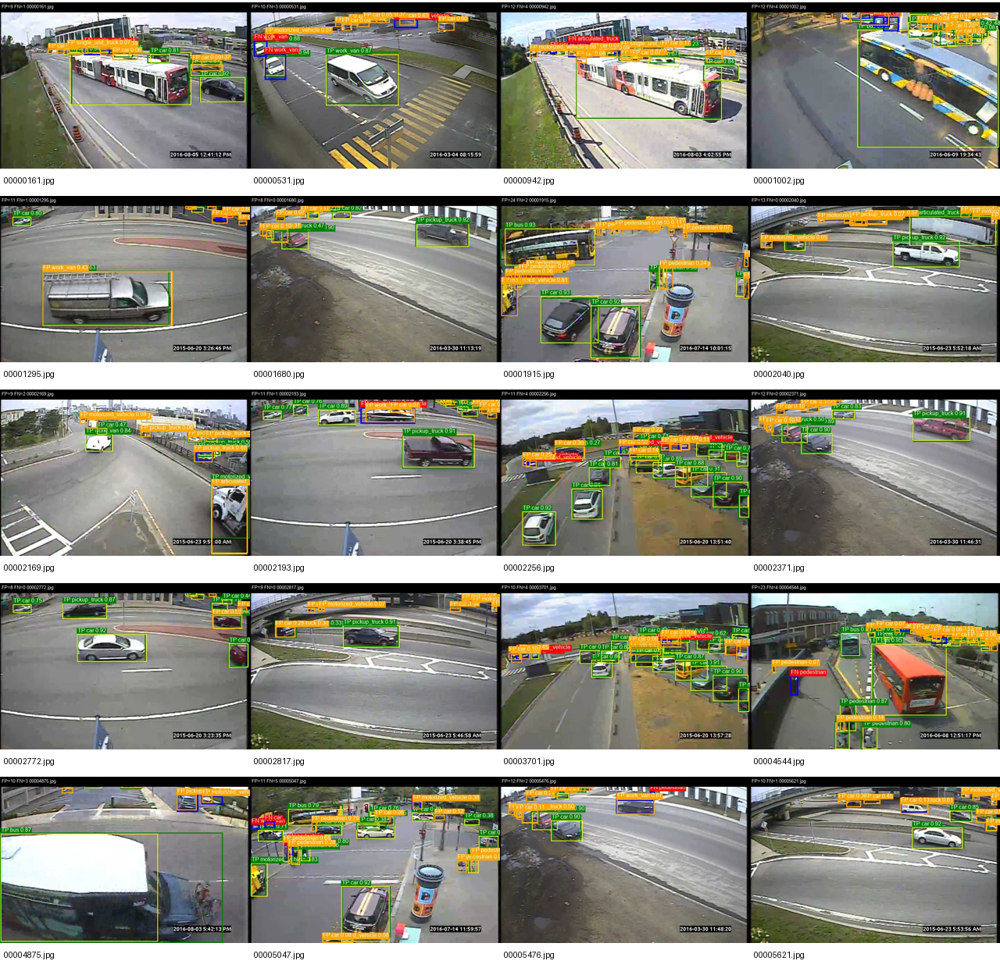


false_negative_heavy
Images: 20
Saved: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\phase_7_3_visual_review\false_negative_heavy_contact_sheet.jpg


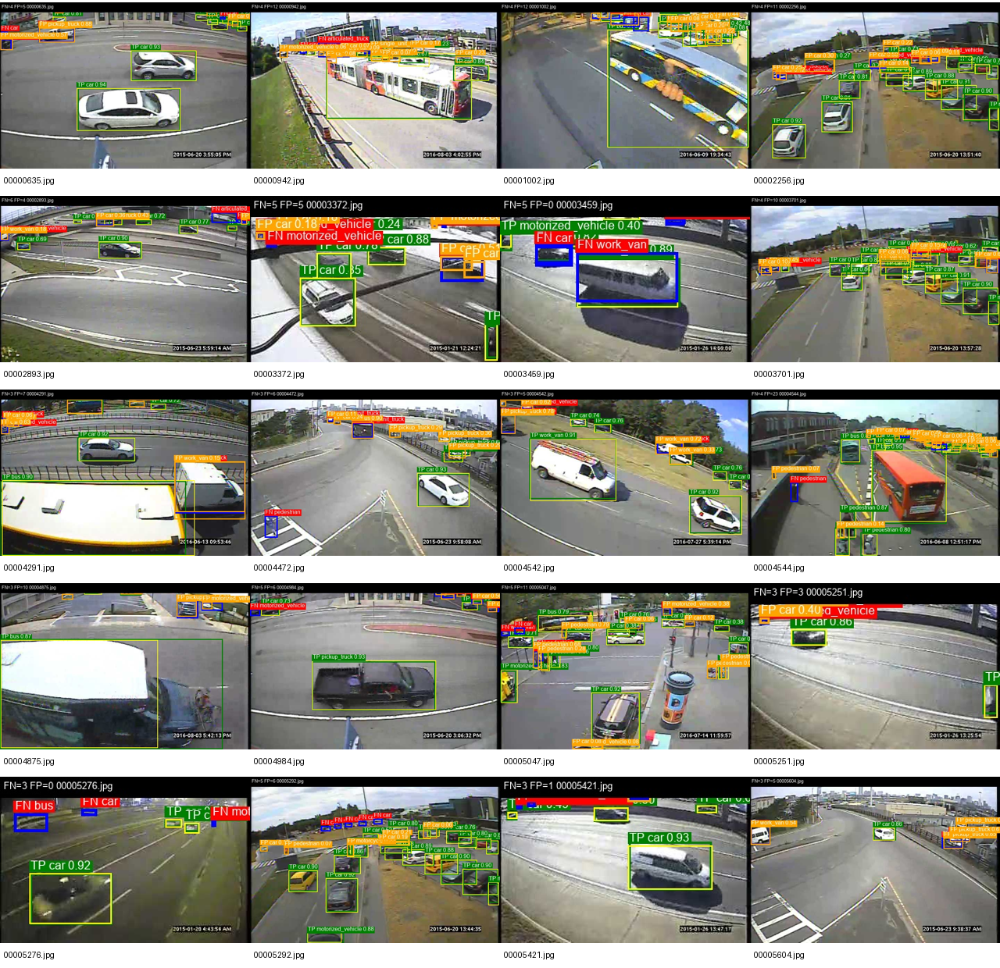


hardest_images
Images: 20
Saved: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\phase_7_3_visual_review\hardest_images_contact_sheet.jpg


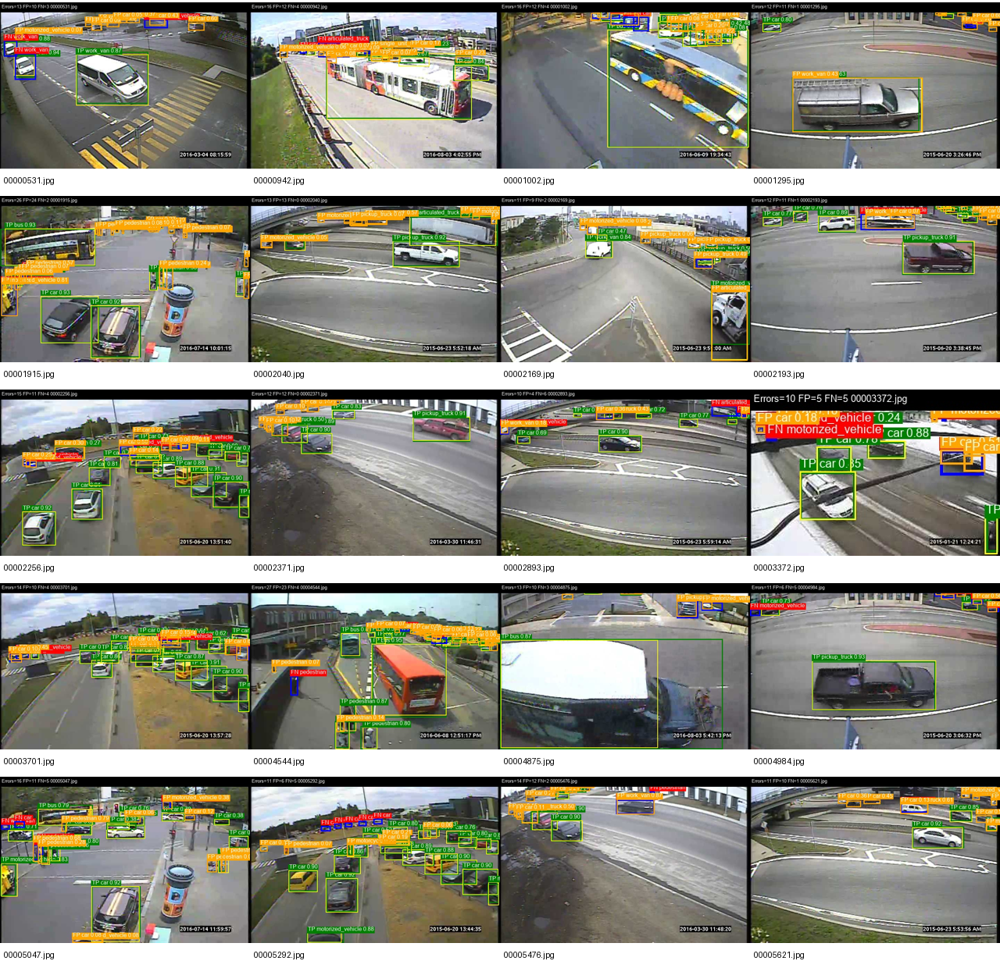


Phase 7.3 contact-sheet generation completed.
Output directory: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\phase_7_3_visual_review


In [11]:

from pathlib import Path
from PIL import Image, ImageOps, ImageDraw
import math
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
)

ERROR_DIR = (
    PROJECT_ROOT
    / "runs"
    / "yolo11s_baseline_diagnostics"
    / "qualitative_errors"
    / "visualizations"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "runs"
    / "phase_7_3_visual_review"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CATEGORIES = [
    "false_positive_heavy",
    "false_negative_heavy",
    "hardest_images",
]

THUMBNAIL_SIZE = (320, 220)
COLUMNS = 4
ROWS = 5
LABEL_HEIGHT = 28

def create_contact_sheet(category):
    source_dir = ERROR_DIR / category

    if not source_dir.exists():
        print(f"Skipping missing directory: {source_dir}")
        return None

    image_paths = sorted(source_dir.glob("*.jpg"))

    if not image_paths:
        print(f"No JPG images found in {source_dir}")
        return None

    cell_width = THUMBNAIL_SIZE[0]
    cell_height = THUMBNAIL_SIZE[1] + LABEL_HEIGHT

    rows = math.ceil(len(image_paths) / COLUMNS)

    sheet = Image.new(
        "RGB",
        (COLUMNS * cell_width, rows * cell_height),
        "white",
    )

    draw = ImageDraw.Draw(sheet)

    for index, image_path in enumerate(image_paths):
        try:
            with Image.open(image_path) as original:
                image = original.convert("RGB")
                image.thumbnail(THUMBNAIL_SIZE)

            tile = Image.new("RGB", THUMBNAIL_SIZE, "white")
            x_offset = (THUMBNAIL_SIZE[0] - image.width) // 2
            y_offset = (THUMBNAIL_SIZE[1] - image.height) // 2
            tile.paste(image, (x_offset, y_offset))

            row = index // COLUMNS
            col = index % COLUMNS

            x = col * cell_width
            y = row * cell_height

            sheet.paste(tile, (x, y))
            draw.text(
                (x + 5, y + THUMBNAIL_SIZE[1] + 5),
                image_path.name,
                fill="black",
            )

        except Exception as exc:
            print(f"Could not load {image_path.name}: {exc}")

    output_path = OUTPUT_DIR / f"{category}_contact_sheet.jpg"
    sheet.save(output_path, quality=92)

    print(f"\n{category}")
    print(f"Images: {len(image_paths)}")
    print(f"Saved: {output_path}")

    display(sheet)
    return output_path

created_sheets = {}

for category in CATEGORIES:
    result = create_contact_sheet(category)
    if result is not None:
        created_sheets[category] = str(result)

print("\nPhase 7.3 contact-sheet generation completed.")
print("Output directory:", OUTPUT_DIR)


In [12]:

from pathlib import Path
import json
import pandas as pd

PROJECT_ROOT = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
)

OUTPUT_DIR = PROJECT_ROOT / "runs" / "phase_7_4_failure_quantification"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

ARTIFACTS = {
    "dataset_yaml": PROJECT_ROOT / "data" / "yolo" / "dataset.yaml",
    "phase_3_4_class_errors": (
        PROJECT_ROOT / "runs" / "yolo11s_baseline_diagnostics"
        / "qualitative_errors" / "class_error_summary.csv"
    ),
    "phase_5_3_validation": (
        PROJECT_ROOT / "runs" / "phase_5_3_class_error_analysis"
        / "classwise_metrics_conf035.csv"
    ),
    "phase_6_2_official_test": (
        PROJECT_ROOT / "runs" / "phase_6_2_final_test"
        / "official_test_metrics.json"
    ),
    "phase_6_3_custom_test": (
        PROJECT_ROOT / "runs" / "phase_6_3_fixed_threshold"
        / "test_classwise_metrics_conf035.csv"
    ),
    "phase_6_3_test_summary": (
        PROJECT_ROOT / "runs" / "phase_6_3_fixed_threshold"
        / "test_fixed_threshold_summary.json"
    ),
    "phase_6_4_final_report": (
        PROJECT_ROOT / "runs" / "phase_6_4_final_consolidation"
        / "final_evaluation_report.json"
    ),
    "phase_7_2_ranking": (
        PROJECT_ROOT / "runs" / "phase_7_2_error_evidence_audit"
        / "phase_7_2_test_class_weakness_ranking.csv"
    ),
    "phase_7_2_visual_inventory": (
        PROJECT_ROOT / "runs" / "phase_7_2_error_evidence_audit"
        / "phase_7_2_visualization_inventory.csv"
    ),
}

rows = []

for name, path in ARTIFACTS.items():
    row = {
        "artifact": name,
        "path": str(path),
        "exists": path.exists(),
        "size_bytes": path.stat().st_size if path.is_file() else None,
    }

    if path.is_file() and path.suffix.lower() == ".csv":
        try:
            df = pd.read_csv(path, nrows=3)
            row["columns"] = ", ".join(map(str, df.columns))
            row["sample_rows"] = len(df)
        except Exception as exc:
            row["read_error"] = str(exc)

    rows.append(row)

artifact_audit = pd.DataFrame(rows)
display(artifact_audit)

artifact_audit.to_csv(
    OUTPUT_DIR / "phase_7_4_artifact_inventory.csv",
    index=False
)

print(f"\nInventory saved to: {OUTPUT_DIR}")
print("Baseline checkpoint will not be modified.")


,artifact,path,exists,size_bytes,columns,sample_rows
0,dataset_yaml,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,True,352,NaN,NaN
1,phase_3_4_class_errors,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,True,302,"class, false_positives, false_negatives, total...",3.0
2,phase_5_3_validation,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,True,948,"Class_ID, Class, TP, FP, FN, Precision, Recall...",3.0
3,phase_6_2_official_test,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,True,1100,NaN,NaN
4,phase_6_3_custom_test,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,True,943,"Class_ID, Class, TP, FP, FN, Precision, Recall...",3.0
5,phase_6_3_test_summary,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,True,3151,NaN,NaN
6,phase_6_4_final_report,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,True,4114,NaN,NaN
7,phase_7_2_ranking,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,True,1221,"class_id, class, TP, FP, FN, precision, recall...",3.0
8,phase_7_2_visual_inventory,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,True,915,"category, directory_exists, image_count, image...",3.0



Inventory saved to: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\phase_7_4_failure_quantification
Baseline checkpoint will not be modified.


In [13]:

from pathlib import Path
import json
import yaml
import pandas as pd

PROJECT_ROOT = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
)
OUTPUT_DIR = PROJECT_ROOT / "runs" / "phase_7_4_failure_quantification"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DATASET_YAML = PROJECT_ROOT / "data" / "yolo" / "dataset.yaml"

with open(DATASET_YAML, "r", encoding="utf-8") as f:
    dataset_cfg = yaml.safe_load(f)

print("=== DATASET CONFIGURATION ===")
print(json.dumps(dataset_cfg, indent=2, default=str))

print("\n=== RELEVANT EXISTING JSON METADATA ===")

json_paths = [
    PROJECT_ROOT / "runs" / "phase_3_4_error_analysis"
    / "phase_3_4_error_analysis.json",
    PROJECT_ROOT / "runs" / "yolo11s_baseline_diagnostics"
    / "qualitative_errors" / "phase_3_4_error_analysis.json",
    PROJECT_ROOT / "runs" / "phase_6_2_final_test"
    / "official_test_metrics.json",
    PROJECT_ROOT / "runs" / "phase_6_3_fixed_threshold"
    / "test_fixed_threshold_summary.json",
    PROJECT_ROOT / "runs" / "phase_6_4_final_consolidation"
    / "final_evaluation_report.json",
]

metadata = {}

for path in json_paths:
    if not path.exists():
        print(f"\nNOT FOUND: {path}")
        continue

    try:
        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)

        metadata[str(path)] = data

        print(f"\n--- {path.name} ---")
        if isinstance(data, dict):
            for key, value in data.items():
                if isinstance(value, (dict, list)):
                    preview = json.dumps(value, default=str)
                    print(f"{key}: {preview[:700]}")
                else:
                    print(f"{key}: {value}")
        else:
            print(json.dumps(data, indent=2, default=str)[:1500])

    except Exception as exc:
        print(f"READ ERROR: {path}\n{exc}")

# Save a compact provenance inventory without altering original metadata.
summary = {
    "dataset_config": dataset_cfg,
    "metadata_files_found": [
        path for path in json_paths if path.exists()
    ],
    "metadata_keys": {
        path: list(data.keys()) if isinstance(data, dict) else type(data).__name__
        for path, data in metadata.items()
    },
}

with open(
    OUTPUT_DIR / "phase_7_4_dataset_provenance.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(summary, f, indent=2, default=str)

print("\nAudit saved to:", OUTPUT_DIR / "phase_7_4_dataset_provenance.json")


=== DATASET CONFIGURATION ===
{
  "path": "C:/Material/Repo/Projects/Capstone_1/Part_1/model_training/data/yolo",
  "train": "images/train",
  "val": "images/val",
  "test": "images/test",
  "nc": 11,
  "names": {
    "0": "car",
    "1": "pickup_truck",
    "2": "motorized_vehicle",
    "3": "bus",
    "4": "articulated_truck",
    "5": "work_van",
    "6": "pedestrian",
    "7": "single_unit_truck",
    "8": "bicycle",
    "9": "non-motorized_vehicle",
    "10": "motorcycle"
  }
}

=== RELEVANT EXISTING JSON METADATA ===

NOT FOUND: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\phase_3_4_error_analysis\phase_3_4_error_analysis.json

--- phase_3_4_error_analysis.json ---
phase: 3.4
model: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_gpu\weights\best.pt
dataset: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\yolo\dataset.yaml
test_images: 844
configuration: {"confidence_threshold": 0.05, "iou_match_threshold": 0.5, 

In [14]:

from pathlib import Path
from collections import Counter
import json
import pandas as pd
from PIL import Image

PROJECT_ROOT = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
)
DATASET_ROOT = PROJECT_ROOT / "data" / "yolo"
OUTPUT_DIR = PROJECT_ROOT / "runs" / "phase_7_4_failure_quantification"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = [
    "car", "pickup_truck", "motorized_vehicle", "bus",
    "articulated_truck", "work_van", "pedestrian",
    "single_unit_truck", "bicycle", "non-motorized_vehicle",
    "motorcycle",
]
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

object_rows = []
image_rows = []
label_issues = []

for split in ["train", "val", "test"]:
    image_dir = DATASET_ROOT / "images" / split
    label_dir = DATASET_ROOT / "labels" / split

    if not image_dir.exists() or not label_dir.exists():
        print(f"SKIP {split}: image or label directory missing")
        print("Images:", image_dir, image_dir.exists())
        print("Labels:", label_dir, label_dir.exists())
        continue

    image_paths = sorted(
        p for p in image_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )

    for image_path in image_paths:
        rel = image_path.relative_to(image_dir)
        label_path = (label_dir / rel).with_suffix(".txt")

        try:
            with Image.open(image_path) as im:
                width, height = im.size
        except Exception as exc:
            label_issues.append({
                "split": split,
                "image": str(image_path),
                "issue": f"image_read_error: {exc}",
            })
            continue

        parsed_objects = []
        if not label_path.exists():
            label_issues.append({
                "split": split,
                "image": str(image_path),
                "issue": "missing_label_file",
            })
        else:
            with open(label_path, "r", encoding="utf-8") as f:
                lines = [x.strip() for x in f if x.strip()]

            for line_number, line in enumerate(lines, start=1):
                parts = line.split()
                if len(parts) != 5:
                    label_issues.append({
                        "split": split,
                        "image": str(image_path),
                        "issue": f"invalid_field_count_line_{line_number}",
                        "raw_line": line,
                    })
                    continue

                try:
                    class_id = int(float(parts[0]))
                    xc, yc, bw, bh = map(float, parts[1:])
                except ValueError:
                    label_issues.append({
                        "split": split,
                        "image": str(image_path),
                        "issue": f"invalid_numeric_line_{line_number}",
                    })
                    continue

                if not 0 <= class_id < len(CLASS_NAMES):
                    label_issues.append({
                        "split": split,
                        "image": str(image_path),
                        "issue": f"class_id_out_of_range_line_{line_number}",
                        "class_id": class_id,
                    })
                    continue

                x1, y1 = (xc - bw / 2) * width, (yc - bh / 2) * height
                x2, y2 = (xc + bw / 2) * width, (yc + bh / 2) * height
                box_w, box_h = max(0, x2 - x1), max(0, y2 - y1)
                area_px = box_w * box_h

                size_bucket = (
                    "small" if area_px < 32**2 else
                    "medium" if area_px < 96**2 else "large"
                )
                edge_distance = min(
                    x1 / width, y1 / height,
                    (width - x2) / width, (height - y2) / height
                )

                parsed_objects.append({
                    "split": split,
                    "image": str(image_path),
                    "label_file": str(label_path),
                    "class_id": class_id,
                    "class_name": CLASS_NAMES[class_id],
                    "image_width": width,
                    "image_height": height,
                    "box_width_px": box_w,
                    "box_height_px": box_h,
                    "box_area_px": area_px,
                    "box_area_fraction": area_px / (width * height),
                    "size_bucket": size_bucket,
                    "x1_px": x1, "y1_px": y1,
                    "x2_px": x2, "y2_px": y2,
                    "edge_distance_fraction": edge_distance,
                    "near_edge_2pct": edge_distance <= 0.02,
                    "near_edge_5pct": edge_distance <= 0.05,
                })

        object_rows.extend(parsed_objects)
        image_rows.append({
            "split": split,
            "image": str(image_path),
            "label_file": str(label_path),
            "image_width": width,
            "image_height": height,
            "ground_truth_objects": len(parsed_objects),
            "missing_label_file": not label_path.exists(),
        })

objects_df = pd.DataFrame(object_rows)
images_df = pd.DataFrame(image_rows)
issues_df = pd.DataFrame(label_issues)

if objects_df.empty:
    raise RuntimeError(
        "No objects were parsed. Verify the label directory paths and format."
    )

objects_df.to_csv(OUTPUT_DIR / "phase_7_4_ground_truth_objects.csv", index=False)
images_df.to_csv(OUTPUT_DIR / "phase_7_4_image_inventory.csv", index=False)
issues_df.to_csv(OUTPUT_DIR / "phase_7_4_annotation_issues.csv", index=False)

print("=== IMAGE COUNTS ===")
display(images_df.groupby("split").agg(
    images=("image", "count"),
    objects=("ground_truth_objects", "sum"),
    images_without_label_files=("missing_label_file", "sum"),
).reset_index())

print("\n=== GROUND-TRUTH OBJECT COUNTS BY CLASS AND SPLIT ===")
display(
    objects_df.groupby(["split", "class_name"])
    .size().rename("instances").reset_index()
    .pivot(index="class_name", columns="split", values="instances")
    .fillna(0).astype(int)
)

print("\n=== OBJECT SIZE DISTRIBUTION ===")
display(
    objects_df.groupby(["split", "size_bucket"])
    .size().rename("instances").reset_index()
)

print("\n=== OBJECTS NEAR IMAGE BOUNDARIES ===")
display(
    objects_df.groupby("split")
    .agg(
        objects=("class_name", "size"),
        within_2pct=("near_edge_2pct", "sum"),
        within_5pct=("near_edge_5pct", "sum"),
    ).reset_index()
)

print("\nAnnotation issues:", len(issues_df))
print("Outputs saved to:", OUTPUT_DIR)


=== IMAGE COUNTS ===


,split,images,objects,images_without_label_files
0,test,844,2725,0
1,train,3938,12553,0
2,val,844,2689,0



=== GROUND-TRUTH OBJECT COUNTS BY CLASS AND SPLIT ===


split,test,train,val
class_name,,,
articulated_truck,67,324,70
bicycle,17,98,15
bus,80,402,79
car,1824,8427,1825
motorcycle,11,69,15
motorized_vehicle,197,884,214
non-motorized_vehicle,21,66,21
pedestrian,42,252,46
pickup_truck,328,1513,295



=== OBJECT SIZE DISTRIBUTION ===


,split,size_bucket,instances
0,test,large,594
1,test,medium,1233
2,test,small,898
3,train,large,2829
4,train,medium,5431
5,train,small,4293
6,val,large,606
7,val,medium,1162
8,val,small,921



=== OBJECTS NEAR IMAGE BOUNDARIES ===


,split,objects,within_2pct,within_5pct
0,test,2725,496,719
1,train,12553,2424,3407
2,val,2689,508,735



Annotation issues: 0
Outputs saved to: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\phase_7_4_failure_quantification


In [15]:

from pathlib import Path
from collections import defaultdict
import json
import numpy as np
import pandas as pd
from ultralytics import YOLO

PROJECT_ROOT = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
)
OUTPUT_DIR = PROJECT_ROOT / "runs" / "phase_7_4_failure_quantification"
CHECKPOINT = (
    PROJECT_ROOT / "runs" / "yolo11s_baseline_gpu" / "weights" / "best.pt"
)

CONF_THRESHOLD = 0.35
NMS_IOU = 0.70
MATCH_IOU = 0.50
IMAGE_SIZE = 640

objects_df = pd.read_csv(
    OUTPUT_DIR / "phase_7_4_ground_truth_objects.csv"
)
images_df = pd.read_csv(
    OUTPUT_DIR / "phase_7_4_image_inventory.csv"
)

# Use validation data for diagnostic analysis.
val_images = images_df[images_df["split"] == "val"].copy()
val_objects = objects_df[objects_df["split"] == "val"].copy()

if not CHECKPOINT.exists():
    raise FileNotFoundError(f"Checkpoint not found: {CHECKPOINT}")
if val_images.empty or val_objects.empty:
    raise RuntimeError("Validation image or annotation inventory is empty.")

model = YOLO(str(CHECKPOINT))

# Group ground-truth objects by image path.
gt_by_image = {
    str(path): group.to_dict("records")
    for path, group in val_objects.groupby("image")
}

# Store one prediction result per image.
prediction_by_image = {}

for idx, row in enumerate(val_images.itertuples(index=False), start=1):
    image_path = str(row.image)

    result = model.predict(
        source=image_path,
        imgsz=IMAGE_SIZE,
        conf=CONF_THRESHOLD,
        iou=NMS_IOU,
        verbose=False,
        device=0,
    )[0]

    preds = []
    if result.boxes is not None and len(result.boxes) > 0:
        xyxy = result.boxes.xyxy.cpu().numpy()
        classes = result.boxes.cls.cpu().numpy().astype(int)
        scores = result.boxes.conf.cpu().numpy()

        for box, class_id, score in zip(xyxy, classes, scores):
            preds.append({
                "box": box.astype(float),
                "class_id": int(class_id),
                "class_name": model.names[int(class_id)],
                "confidence": float(score),
            })

    prediction_by_image[image_path] = preds

    if idx % 100 == 0 or idx == len(val_images):
        print(f"Processed {idx}/{len(val_images)} validation images")

def box_iou_xyxy(a, b):
    x1 = max(a[0], b[0])
    y1 = max(a[1], b[1])
    x2 = min(a[2], b[2])
    y2 = min(a[3], b[3])

    intersection = max(0.0, x2 - x1) * max(0.0, y2 - y1)
    area_a = max(0.0, a[2] - a[0]) * max(0.0, a[3] - a[1])
    area_b = max(0.0, b[2] - b[0]) * max(0.0, b[3] - b[1])
    union = area_a + area_b - intersection
    return intersection / union if union > 0 else 0.0

gt_records = []
pred_records = []
image_records = []

for image_path, image_row in zip(
    val_images["image"].astype(str),
    val_images.to_dict("records"),
):
    gts = gt_by_image.get(image_path, [])
    preds = prediction_by_image.get(image_path, [])

    # Greedy, one-to-one matching, with class-aware eligibility.
    candidate_pairs = []
    for gi, gt in enumerate(gts):
        gt_box = [
            gt["x1_px"], gt["y1_px"], gt["x2_px"], gt["y2_px"]
        ]
        for pi, pred in enumerate(preds):
            if int(gt["class_id"]) != pred["class_id"]:
                continue

            overlap = box_iou_xyxy(gt_box, pred["box"])
            if overlap >= MATCH_IOU:
                candidate_pairs.append((overlap, gi, pi))

    candidate_pairs.sort(reverse=True)
    matched_gts = set()
    matched_preds = set()
    matches = {}

    for overlap, gi, pi in candidate_pairs:
        if gi in matched_gts or pi in matched_preds:
            continue
        matched_gts.add(gi)
        matched_preds.add(pi)
        matches[gi] = (pi, overlap)

    for gi, gt in enumerate(gts):
        matched = gi in matches
        pi, overlap = matches[gi] if matched else (None, None)

        gt_records.append({
            **gt,
            "matched": matched,
            "matched_prediction_index": pi,
            "matched_iou": overlap,
            "missed": not matched,
            "scene_object_count": len(gts),
        })

    for pi, pred in enumerate(preds):
        matched = pi in matched_preds
        pred_records.append({
            "image": image_path,
            "class_id": pred["class_id"],
            "class_name": pred["class_name"],
            "confidence": pred["confidence"],
            "x1_px": pred["box"][0],
            "y1_px": pred["box"][1],
            "x2_px": pred["box"][2],
            "y2_px": pred["box"][3],
            "matched": matched,
            "unmatched_prediction": not matched,
            "scene_object_count": len(gts),
        })

    image_records.append({
        "image": image_path,
        "ground_truth_count": len(gts),
        "prediction_count": len(preds),
        "TP": len(matched_gts),
        "FP": len(preds) - len(matched_preds),
        "FN": len(gts) - len(matched_gts),
    })

gt_eval = pd.DataFrame(gt_records)
pred_eval = pd.DataFrame(pred_records)
image_eval = pd.DataFrame(image_records)

# Ground-truth recall by size, boundary distance, class, and scene density.
gt_eval["edge_group"] = np.where(
    gt_eval["near_edge_5pct"], "within_5pct", "interior_over_5pct"
)
gt_eval["density_group"] = pd.cut(
    gt_eval["scene_object_count"],
    bins=[-1, 2, 5, 10, np.inf],
    labels=["0-2 objects", "3-5 objects", "6-10 objects", "11+ objects"],
)

def summarize_recall(df, group_columns):
    out = (
        df.groupby(group_columns, observed=False)
        .agg(
            ground_truth=("matched", "size"),
            matched=("matched", "sum"),
            missed=("missed", "sum"),
        )
        .reset_index()
    )
    out["recall"] = out["matched"] / out["ground_truth"].replace(0, np.nan)
    return out

size_results = summarize_recall(gt_eval, ["size_bucket"])
edge_results = summarize_recall(gt_eval, ["edge_group"])
class_results = summarize_recall(gt_eval, ["class_name"])
density_results = summarize_recall(gt_eval, ["density_group"])
class_size_results = summarize_recall(
    gt_eval, ["class_name", "size_bucket"]
)

# Save raw matched-object evidence and grouped summaries.
gt_eval.to_csv(OUTPUT_DIR / "phase_7_4_validation_gt_match_audit.csv", index=False)
pred_eval.to_csv(OUTPUT_DIR / "phase_7_4_validation_prediction_audit.csv", index=False)
image_eval.to_csv(OUTPUT_DIR / "phase_7_4_validation_image_metrics.csv", index=False)

size_results.to_csv(OUTPUT_DIR / "phase_7_4_recall_by_size.csv", index=False)
edge_results.to_csv(OUTPUT_DIR / "phase_7_4_recall_by_boundary.csv", index=False)
class_results.to_csv(OUTPUT_DIR / "phase_7_4_recall_by_class.csv", index=False)
density_results.to_csv(OUTPUT_DIR / "phase_7_4_recall_by_scene_density.csv", index=False)
class_size_results.to_csv(OUTPUT_DIR / "phase_7_4_recall_by_class_and_size.csv", index=False)

summary = {
    "split": "val",
    "checkpoint": str(CHECKPOINT),
    "image_size": IMAGE_SIZE,
    "confidence_threshold": CONF_THRESHOLD,
    "prediction_nms_iou": NMS_IOU,
    "matching_iou_threshold": MATCH_IOU,
    "matching_method": "class-aware greedy one-to-one IoU matching",
    "images": int(len(image_eval)),
    "ground_truth_objects": int(len(gt_eval)),
    "predictions": int(len(pred_eval)),
    "TP": int(image_eval["TP"].sum()),
    "FP": int(image_eval["FP"].sum()),
    "FN": int(image_eval["FN"].sum()),
    "limitations": [
        "These are custom fixed-threshold metrics, not official mAP.",
        "Class-aware matching counts wrong-class detections as a miss plus an unmatched prediction.",
        "The size buckets use ground-truth pixel area and are diagnostic bins.",
    ],
}

with open(
    OUTPUT_DIR / "phase_7_4_validation_failure_summary.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(summary, f, indent=2)

print("\n=== OVERALL VALIDATION METRICS ===")
print(json.dumps(summary, indent=2))

print("\n=== RECALL BY OBJECT SIZE ===")
display(size_results)

print("\n=== RECALL BY IMAGE-BOUNDARY PROXIMITY ===")
display(edge_results)

print("\n=== RECALL BY CLASS ===")
display(class_results.sort_values("recall"))

print("\n=== RECALL BY SCENE DENSITY ===")
display(density_results)

print("\n=== RECALL BY CLASS AND SIZE ===")
display(class_size_results)

print("\nSaved all Phase 7.4 validation outputs to:", OUTPUT_DIR)


Processed 100/844 validation images
Processed 200/844 validation images
Processed 300/844 validation images
Processed 400/844 validation images
Processed 500/844 validation images
Processed 600/844 validation images
Processed 700/844 validation images
Processed 800/844 validation images
Processed 844/844 validation images

=== OVERALL VALIDATION METRICS ===
{
  "split": "val",
  "checkpoint": "C:\\Material\\Repo\\Projects\\Capstone_1\\Part_1\\model_training\\runs\\yolo11s_baseline_gpu\\weights\\best.pt",
  "image_size": 640,
  "confidence_threshold": 0.35,
  "prediction_nms_iou": 0.7,
  "matching_iou_threshold": 0.5,
  "matching_method": "class-aware greedy one-to-one IoU matching",
  "images": 844,
  "ground_truth_objects": 2689,
  "predictions": 2597,
  "TP": 2163,
  "FP": 434,
  "FN": 526,
  "limitations": [
    "These are custom fixed-threshold metrics, not official mAP.",
    "Class-aware matching counts wrong-class detections as a miss plus an unmatched prediction.",
    "The siz

,size_bucket,ground_truth,matched,missed,recall
0,large,606,549,57,0.905941
1,medium,1162,1007,155,0.866609
2,small,921,607,314,0.659066



=== RECALL BY IMAGE-BOUNDARY PROXIMITY ===


,edge_group,ground_truth,matched,missed,recall
0,interior_over_5pct,1954,1626,328,0.832139
1,within_5pct,735,537,198,0.730612



=== RECALL BY CLASS ===


,class_name,ground_truth,matched,missed,recall
6,non-motorized_vehicle,21,6,15,0.285714
5,motorized_vehicle,214,73,141,0.341121
9,single_unit_truck,40,15,25,0.375000
7,pedestrian,46,19,27,0.413043
10,work_van,69,38,31,0.550725
4,motorcycle,15,11,4,0.733333
0,articulated_truck,70,57,13,0.814286
8,pickup_truck,295,251,44,0.850847
1,bicycle,15,13,2,0.866667
3,car,1825,1610,215,0.882192



=== RECALL BY SCENE DENSITY ===


,density_group,ground_truth,matched,missed,recall
0,0-2 objects,682,589,93,0.863636
1,3-5 objects,941,775,166,0.823592
2,6-10 objects,662,485,177,0.732628
3,11+ objects,404,314,90,0.777228



=== RECALL BY CLASS AND SIZE ===


,class_name,size_bucket,ground_truth,matched,missed,recall
0,articulated_truck,large,32,29,3,0.906250
1,articulated_truck,medium,35,27,8,0.771429
2,articulated_truck,small,3,1,2,0.333333
3,bicycle,large,1,1,0,1.000000
4,bicycle,medium,10,9,1,0.900000
5,bicycle,small,4,3,1,0.750000
6,bus,large,64,60,4,0.937500
7,bus,medium,13,9,4,0.692308
8,bus,small,2,1,1,0.500000
9,car,large,334,323,11,0.967066



Saved all Phase 7.4 validation outputs to: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\phase_7_4_failure_quantification


In [16]:

from pathlib import Path
import json
import numpy as np
import pandas as pd

PROJECT_ROOT = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
)
OUTPUT_DIR = PROJECT_ROOT / "runs" / "phase_7_4_failure_quantification"

gt = pd.read_csv(
    OUTPUT_DIR / "phase_7_4_validation_gt_match_audit.csv"
)
pred = pd.read_csv(
    OUTPUT_DIR / "phase_7_4_validation_prediction_audit.csv"
)

def iou_xyxy(a, b):
    x1 = max(a[0], b[0])
    y1 = max(a[1], b[1])
    x2 = min(a[2], b[2])
    y2 = min(a[3], b[3])

    inter = max(0.0, x2 - x1) * max(0.0, y2 - y1)
    area_a = max(0.0, a[2] - a[0]) * max(0.0, a[3] - a[1])
    area_b = max(0.0, b[2] - b[0]) * max(0.0, b[3] - b[1])
    union = area_a + area_b - inter
    return inter / union if union > 0 else 0.0

unmatched_gt = gt[~gt["matched"].astype(bool)].copy()
unmatched_pred = pred[pred["unmatched_prediction"].astype(bool)].copy()
matched_gt = gt[gt["matched"].astype(bool)].copy()

# 1. Search for unmatched GT objects that overlap unmatched predictions
# from a different class. These are possible class-confusion candidates.
confusion_candidates = []

for image_path, gt_group in unmatched_gt.groupby("image"):
    pred_group = unmatched_pred[unmatched_pred["image"] == image_path]

    for _, g in gt_group.iterrows():
        gbox = [g.x1_px, g.y1_px, g.x2_px, g.y2_px]

        for _, p in pred_group.iterrows():
            pbox = [p.x1_px, p.y1_px, p.x2_px, p.y2_px]
            overlap = iou_xyxy(gbox, pbox)

            if overlap >= 0.30 and int(g.class_id) != int(p.class_id):
                confusion_candidates.append({
                    "image": image_path,
                    "gt_class": g.class_name,
                    "predicted_class": p.class_name,
                    "prediction_confidence": float(p.confidence),
                    "IoU": overlap,
                    "gt_size_bucket": g.size_bucket,
                    "gt_near_edge_5pct": bool(g.near_edge_5pct),
                })

confusion_df = pd.DataFrame(confusion_candidates)

if not confusion_df.empty:
    confusion_df = confusion_df.sort_values("IoU", ascending=False)

# 2. Find unmatched predictions overlapping a GT object that was
# already matched to another prediction. These may be duplicates.
duplicate_candidates = []

for image_path, pred_group in unmatched_pred.groupby("image"):
    gt_group = matched_gt[matched_gt["image"] == image_path]

    for _, p in pred_group.iterrows():
        pbox = [p.x1_px, p.y1_px, p.x2_px, p.y2_px]

        best_overlap = 0.0
        best_gt_class = None

        for _, g in gt_group.iterrows():
            gbox = [g.x1_px, g.y1_px, g.x2_px, g.y2_px]
            overlap = iou_xyxy(pbox, gbox)

            if overlap > best_overlap:
                best_overlap = overlap
                best_gt_class = g.class_name

        if best_overlap >= 0.50:
            duplicate_candidates.append({
                "image": image_path,
                "predicted_class": p.class_name,
                "prediction_confidence": float(p.confidence),
                "matched_gt_class": best_gt_class,
                "IoU_with_already_matched_gt": best_overlap,
            })

duplicate_df = pd.DataFrame(duplicate_candidates)

# 3. Unmatched predictions not explained by a high-overlap duplicate
# candidate. These still need visual review before being called genuine FP.
duplicate_keys = set()
if not duplicate_df.empty:
    # Match duplicate candidate records by image, class and confidence.
    duplicate_keys = {
        (r["image"], r["predicted_class"], r["prediction_confidence"])
        for r in duplicate_df.to_dict("records")
    }

unexplained_rows = []
for r in unmatched_pred.to_dict("records"):
    key = (r["image"], r["class_name"], r["confidence"])
    if key not in duplicate_keys:
        unexplained_rows.append(r)

unexplained_df = pd.DataFrame(unexplained_rows)

# Aggregate possible class confusion by GT class and predicted class.
if not confusion_df.empty:
    confusion_summary = (
        confusion_df.groupby(["gt_class", "predicted_class"])
        .agg(
            candidate_pairs=("IoU", "size"),
            mean_IoU=("IoU", "mean"),
            max_IoU=("IoU", "max"),
        )
        .reset_index()
        .sort_values("candidate_pairs", ascending=False)
    )
else:
    confusion_summary = pd.DataFrame(
        columns=["gt_class", "predicted_class", "candidate_pairs",
                 "mean_IoU", "max_IoU"]
    )

confusion_df.to_csv(
    OUTPUT_DIR / "phase_7_4_possible_class_confusion_pairs.csv",
    index=False
)
confusion_summary.to_csv(
    OUTPUT_DIR / "phase_7_4_possible_class_confusion_summary.csv",
    index=False
)
duplicate_df.to_csv(
    OUTPUT_DIR / "phase_7_4_possible_duplicate_predictions.csv",
    index=False
)
unexplained_df.to_csv(
    OUTPUT_DIR / "phase_7_4_unmatched_prediction_review_queue.csv",
    index=False
)

report = {
    "split": "val",
    "candidate_class_confusion_pairs": int(len(confusion_df)),
    "candidate_duplicate_predictions": int(len(duplicate_df)),
    "unmatched_predictions_remaining_for_review": int(len(unexplained_df)),
    "class_confusion_iou_threshold": 0.30,
    "duplicate_overlap_iou_threshold": 0.50,
    "interpretation": [
        "Overlapping cross-class pairs are candidates, not confirmed classification errors.",
        "Duplicate candidates may include localization or annotation effects.",
        "Unmatched predictions are not automatically genuine false positives.",
        "All candidate groups should be visually reviewed before conclusions are finalized."
    ]
}

with open(
    OUTPUT_DIR / "phase_7_4_confusion_duplicate_summary.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(report, f, indent=2)

print("=== CONFUSION / DUPLICATE CANDIDATE COUNTS ===")
print(json.dumps(report, indent=2))

print("\n=== MOST COMMON POSSIBLE CLASS CONFUSIONS ===")
display(confusion_summary.head(20))

print("\n=== POSSIBLE DUPLICATE PREDICTIONS ===")
display(duplicate_df.head(20))

print("\n=== UNMATCHED PREDICTIONS QUEUED FOR REVIEW ===")
display(unexplained_df.head(20))

print("\nSaved outputs to:", OUTPUT_DIR)


=== CONFUSION / DUPLICATE CANDIDATE COUNTS ===
{
  "split": "val",
  "candidate_class_confusion_pairs": 225,
  "candidate_duplicate_predictions": 90,
  "unmatched_predictions_remaining_for_review": 344,
  "class_confusion_iou_threshold": 0.3,
  "duplicate_overlap_iou_threshold": 0.5,
  "interpretation": [
    "Overlapping cross-class pairs are candidates, not confirmed classification errors.",
    "Duplicate candidates may include localization or annotation effects.",
    "Unmatched predictions are not automatically genuine false positives.",
    "All candidate groups should be visually reviewed before conclusions are finalized."
  ]
}

=== MOST COMMON POSSIBLE CLASS CONFUSIONS ===


,gt_class,predicted_class,candidate_pairs,mean_IoU,max_IoU
12,motorized_vehicle,car,47,0.795671,0.972826
8,car,pickup_truck,40,0.844980,0.969045
23,pickup_truck,car,28,0.861197,0.973502
7,car,motorized_vehicle,25,0.722754,0.948694
32,work_van,car,18,0.873962,0.983680
13,motorized_vehicle,pickup_truck,8,0.693422,0.937841
34,work_van,pickup_truck,7,0.882477,0.955471
25,single_unit_truck,articulated_truck,6,0.856242,0.979354
28,single_unit_truck,motorized_vehicle,4,0.835486,0.927818
16,non-motorized_vehicle,articulated_truck,3,0.669477,0.914084



=== POSSIBLE DUPLICATE PREDICTIONS ===


,image,predicted_class,prediction_confidence,matched_gt_class,IoU_with_already_matched_gt
0,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,work_van,0.579618,car,0.864337
1,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,pickup_truck,0.461520,car,0.826598
2,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,motorized_vehicle,0.410257,car,0.776292
3,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,pickup_truck,0.390580,car,0.909527
4,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,car,0.733402,motorized_vehicle,0.922568
5,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,work_van,0.666998,car,0.774093
6,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,motorized_vehicle,0.488886,car,0.894269
7,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,car,0.446329,work_van,0.786360
8,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,single_unit_truck,0.497890,motorized_vehicle,0.949002
9,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,pickup_truck,0.458454,car,0.774435



=== UNMATCHED PREDICTIONS QUEUED FOR REVIEW ===


,image,class_id,class_name,confidence,x1_px,y1_px,x2_px,y2_px,matched,unmatched_prediction,scene_object_count
0,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,1,pickup_truck,0.895409,83.820229,45.333603,189.492203,89.152206,False,True,2
1,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,0,car,0.378196,497.142822,58.588688,530.033325,84.660393,False,True,7
2,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,0,car,0.508268,81.996529,65.370171,105.806274,80.349083,False,True,7
3,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,0,car,0.357302,124.873077,41.363293,147.834930,55.081947,False,True,7
4,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,0,car,0.741021,656.031982,92.331543,705.959717,120.152184,False,True,2
5,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,1,pickup_truck,0.796860,448.185181,114.837257,481.377380,140.378448,False,True,3
6,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,2,motorized_vehicle,0.896191,300.713348,87.956955,337.214569,130.795700,False,True,6
7,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,0,car,0.766849,218.624481,31.625704,247.032196,41.460484,False,True,6
8,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,0,car,0.622380,224.784500,38.441669,256.392151,54.223373,False,True,11
9,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,8,bicycle,0.724425,0.122918,337.022766,76.419518,480.000000,False,True,16



Saved outputs to: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\phase_7_4_failure_quantification


In [17]:

from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
    r"\runs\phase_7_4_failure_quantification"
)

files_to_check = [
    "phase_7_4_validation_gt_match_audit.csv",
    "phase_7_4_validation_prediction_audit.csv",
    "phase_7_4_possible_class_confusion_pairs.csv",
    "phase_7_4_possible_duplicate_predictions.csv",
    "phase_7_4_unmatched_prediction_review_queue.csv",
]

for filename in files_to_check:
    path = OUTPUT_DIR / filename
    print(f"\n{'=' * 80}\n{filename}")

    if not path.exists():
        print("FILE NOT FOUND")
        continue

    df = pd.read_csv(path)
    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())
    print(df.head(2).to_string(index=False))



phase_7_4_validation_gt_match_audit.csv
Rows: 2689
Columns: ['split', 'image', 'label_file', 'class_id', 'class_name', 'image_width', 'image_height', 'box_width_px', 'box_height_px', 'box_area_px', 'box_area_fraction', 'size_bucket', 'x1_px', 'y1_px', 'x2_px', 'y2_px', 'edge_distance_fraction', 'near_edge_2pct', 'near_edge_5pct', 'matched', 'matched_prediction_index', 'matched_iou', 'missed', 'scene_object_count', 'edge_group', 'density_group']
split                                                                                        image                                                                                   label_file  class_id class_name  image_width  image_height  box_width_px  box_height_px  box_area_px  box_area_fraction size_bucket     x1_px     y1_px     x2_px     y2_px  edge_distance_fraction  near_edge_2pct  near_edge_5pct  matched  matched_prediction_index  matched_iou  missed  scene_object_count         edge_group density_group
  val C:\Material\Repo\Projects\

In [18]:

from pathlib import Path
import json
import pandas as pd
import cv2

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------
PROJECT_DIR = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
)
OUTPUT_DIR = PROJECT_DIR / "runs" / "phase_7_4_failure_quantification"

GT_CSV = OUTPUT_DIR / "phase_7_4_validation_gt_match_audit.csv"
PRED_CSV = OUTPUT_DIR / "phase_7_4_validation_prediction_audit.csv"
CONFUSION_CSV = OUTPUT_DIR / "phase_7_4_possible_class_confusion_pairs.csv"
DUPLICATE_CSV = OUTPUT_DIR / "phase_7_4_possible_duplicate_predictions.csv"
UNMATCHED_CSV = OUTPUT_DIR / "phase_7_4_unmatched_prediction_review_queue.csv"

REVIEW_DIR = OUTPUT_DIR / "phase_7_4_5_visual_review"
REVIEW_DIR.mkdir(parents=True, exist_ok=True)

MAX_PER_CATEGORY = 20

# ------------------------------------------------------------
# 2. Load audits
# ------------------------------------------------------------
gt = pd.read_csv(GT_CSV)
pred = pd.read_csv(PRED_CSV)
confusion = pd.read_csv(CONFUSION_CSV)
duplicate = pd.read_csv(DUPLICATE_CSV)
unmatched = pd.read_csv(UNMATCHED_CSV)

# Normalize boolean columns safely
def to_bool(series):
    return series.astype(str).str.strip().str.lower().isin(
        ["true", "1", "yes"]
    )

gt["matched"] = to_bool(gt["matched"])
gt["missed"] = to_bool(gt["missed"])
pred["matched"] = to_bool(pred["matched"])
pred["unmatched_prediction"] = to_bool(
    pred["unmatched_prediction"]
)

# ------------------------------------------------------------
# 3. Select review candidates
# ------------------------------------------------------------
# Category A: high-IoU cross-class overlaps
confusion["IoU"] = pd.to_numeric(confusion["IoU"], errors="coerce")
confusion["prediction_confidence"] = pd.to_numeric(
    confusion["prediction_confidence"], errors="coerce"
)
confusion_sample = (
    confusion.sort_values(
        ["IoU", "prediction_confidence"],
        ascending=False
    )
    .drop_duplicates(subset=["image", "gt_class", "predicted_class"])
    .head(MAX_PER_CATEGORY)
    .copy()
)

# Category B: current overlap/duplicate candidates.
# These are NOT confirmed duplicates; cross-class overlaps can occur.
duplicate["IoU_with_already_matched_gt"] = pd.to_numeric(
    duplicate["IoU_with_already_matched_gt"], errors="coerce"
)
duplicate["prediction_confidence"] = pd.to_numeric(
    duplicate["prediction_confidence"], errors="coerce"
)
duplicate_sample = (
    duplicate.sort_values(
        ["IoU_with_already_matched_gt", "prediction_confidence"],
        ascending=False
    )
    .drop_duplicates(subset=["image", "predicted_class"])
    .head(MAX_PER_CATEGORY)
    .copy()
)

# Category C: unmatched predictions, prioritizing higher confidence
unmatched["confidence"] = pd.to_numeric(
    unmatched["confidence"], errors="coerce"
)
unmatched_sample = (
    unmatched.sort_values("confidence", ascending=False)
    .drop_duplicates(subset=["image", "class_name", "x1_px", "y1_px"])
    .head(MAX_PER_CATEGORY)
    .copy()
)

# Category D: missed ground-truth objects
missed_gt = gt[gt["missed"]].copy()
missed_gt_sample = (
    missed_gt.sort_values(
        ["size_bucket", "box_area_px"],
        ascending=[True, True]
    )
    .drop_duplicates(subset=["image", "class_name", "x1_px", "y1_px"])
    .head(MAX_PER_CATEGORY)
    .copy()
)

# Build a deduplicated image set with reasons for review
review_reasons = {}

def add_image(path, reason):
    path = str(path)
    review_reasons.setdefault(path, [])
    if reason not in review_reasons[path]:
        review_reasons[path].append(reason)

for _, row in confusion_sample.iterrows():
    add_image(row["image"], "possible_class_confusion")

for _, row in duplicate_sample.iterrows():
    add_image(row["image"], "possible_duplicate_or_cross_class_overlap")

for _, row in unmatched_sample.iterrows():
    add_image(row["image"], "unmatched_prediction")

for _, row in missed_gt_sample.iterrows():
    add_image(row["image"], "missed_ground_truth")

print("Selected candidates:")
print("  Class-confusion examples:", len(confusion_sample))
print("  Overlap/duplicate examples:", len(duplicate_sample))
print("  Unmatched-prediction examples:", len(unmatched_sample))
print("  Missed-ground-truth examples:", len(missed_gt_sample))
print("  Unique images to render:", len(review_reasons))

# ------------------------------------------------------------
# 4. Draw boxes on copies of original validation images
# ------------------------------------------------------------
# Colors are OpenCV BGR:
GREEN = (0, 200, 0)       # Ground truth
RED = (0, 0, 255)         # Matched prediction
YELLOW = (0, 220, 255)    # Unmatched prediction
ORANGE = (0, 140, 255)    # Missed ground-truth object

def draw_box(image, row, color, label):
    x1 = int(round(float(row["x1_px"])))
    y1 = int(round(float(row["y1_px"])))
    x2 = int(round(float(row["x2_px"])))
    y2 = int(round(float(row["y2_px"])))

    h, w = image.shape[:2]
    x1, x2 = max(0, min(x1, w - 1)), max(0, min(x2, w - 1))
    y1, y2 = max(0, min(y1, h - 1)), max(0, min(y2, h - 1))

    cv2.rectangle(image, (x1, y1), (x2, y2), color, 2)
    cv2.putText(
        image, label[:70], (x1, max(16, y1 - 5)),
        cv2.FONT_HERSHEY_SIMPLEX, 0.45, color, 1, cv2.LINE_AA
    )

manifest = []
rendered = 0
missing_images = []

for image_path_str, reasons in review_reasons.items():
    image_path = Path(image_path_str)
    if not image_path.exists():
        missing_images.append(image_path_str)
        continue

    original = cv2.imread(str(image_path))
    if original is None:
        missing_images.append(image_path_str)
        continue

    canvas = original.copy()

    gt_img = gt[gt["image"] == image_path_str]
    pred_img = pred[pred["image"] == image_path_str]

    # Draw all ground-truth boxes, labeling missed objects distinctly
    for _, row in gt_img.iterrows():
        if row["missed"]:
            color = ORANGE
            label = f"MISSED GT: {row['class_name']}"
        else:
            color = GREEN
            label = f"GT: {row['class_name']}"
        draw_box(canvas, row, color, label)

    # Draw all predictions
    for _, row in pred_img.iterrows():
        if row["unmatched_prediction"]:
            color = YELLOW
            label = f"UNMATCHED: {row['class_name']} {row['confidence']:.2f}"
        else:
            color = RED
            label = f"PRED: {row['class_name']} {row['confidence']:.2f}"
        draw_box(canvas, row, color, label)

    # Add review reasons to the image header
    header = " | ".join(reasons)
    cv2.rectangle(canvas, (0, 0), (canvas.shape[1], 26), (30, 30, 30), -1)
    cv2.putText(
        canvas, header[:120], (8, 18),
        cv2.FONT_HERSHEY_SIMPLEX, 0.48, (255, 255, 255), 1, cv2.LINE_AA
    )

    output_name = f"review_{rendered + 1:04d}_{image_path.stem}.jpg"
    output_path = REVIEW_DIR / output_name

    if cv2.imwrite(str(output_path), canvas):
        rendered += 1
        manifest.append({
            "review_id": rendered,
            "original_image": str(image_path),
            "annotated_image": str(output_path),
            "review_categories": ";".join(reasons),
            "human_review_status": "pending",
            "confirmed_failure_type": "",
            "review_notes": ""
        })

manifest_df = pd.DataFrame(manifest)
manifest_path = REVIEW_DIR / "phase_7_4_5_review_manifest.csv"
manifest_df.to_csv(manifest_path, index=False)

summary = {
    "phase": "7.4.5",
    "split": "validation",
    "candidate_sampling_limit_per_category": MAX_PER_CATEGORY,
    "unique_images_selected": len(review_reasons),
    "images_rendered": rendered,
    "missing_or_unreadable_images": len(missing_images),
    "annotated_image_directory": str(REVIEW_DIR),
    "review_manifest": str(manifest_path),
    "legend": {
        "green": "ground-truth object",
        "red": "prediction matched by the existing audit",
        "yellow": "unmatched prediction",
        "orange": "missed ground-truth object"
    },
    "caveat": (
        "Annotations are diagnostic overlays. Candidate labels are not "
        "confirmed until a human inspects the original image."
    )
}

with open(
    REVIEW_DIR / "phase_7_4_5_visual_review_summary.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(summary, f, indent=2)

print("\n=== PHASE 7.4.5 SUMMARY ===")
print(json.dumps(summary, indent=2))
print("\nManifest preview:")
display(manifest_df.head(10))


Selected candidates:
  Class-confusion examples: 20
  Overlap/duplicate examples: 20
  Unmatched-prediction examples: 20
  Missed-ground-truth examples: 20
  Unique images to render: 67

=== PHASE 7.4.5 SUMMARY ===
{
  "phase": "7.4.5",
  "split": "validation",
  "candidate_sampling_limit_per_category": 20,
  "unique_images_selected": 67,
  "images_rendered": 67,
  "missing_or_unreadable_images": 0,
  "annotated_image_directory": "C:\\Material\\Repo\\Projects\\Capstone_1\\Part_1\\model_training\\runs\\phase_7_4_failure_quantification\\phase_7_4_5_visual_review",
  "review_manifest": "C:\\Material\\Repo\\Projects\\Capstone_1\\Part_1\\model_training\\runs\\phase_7_4_failure_quantification\\phase_7_4_5_visual_review\\phase_7_4_5_review_manifest.csv",
  "legend": {
    "green": "ground-truth object",
    "red": "prediction matched by the existing audit",
    "yellow": "unmatched prediction",
    "orange": "missed ground-truth object"
  },
  "caveat": "Annotations are diagnostic overlays. C

,review_id,original_image,annotated_image,review_categories,human_review_status,confirmed_failure_type,review_notes
0,1,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,possible_class_confusion,pending,,
1,2,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,possible_class_confusion,pending,,
2,3,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,possible_class_confusion,pending,,
3,4,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,possible_class_confusion;unmatched_prediction,pending,,
4,5,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,possible_class_confusion;unmatched_prediction;...,pending,,
5,6,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,possible_class_confusion,pending,,
6,7,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,possible_class_confusion;unmatched_prediction,pending,,
7,8,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,possible_class_confusion,pending,,
8,9,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,possible_class_confusion,pending,,
9,10,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,possible_class_confusion,pending,,


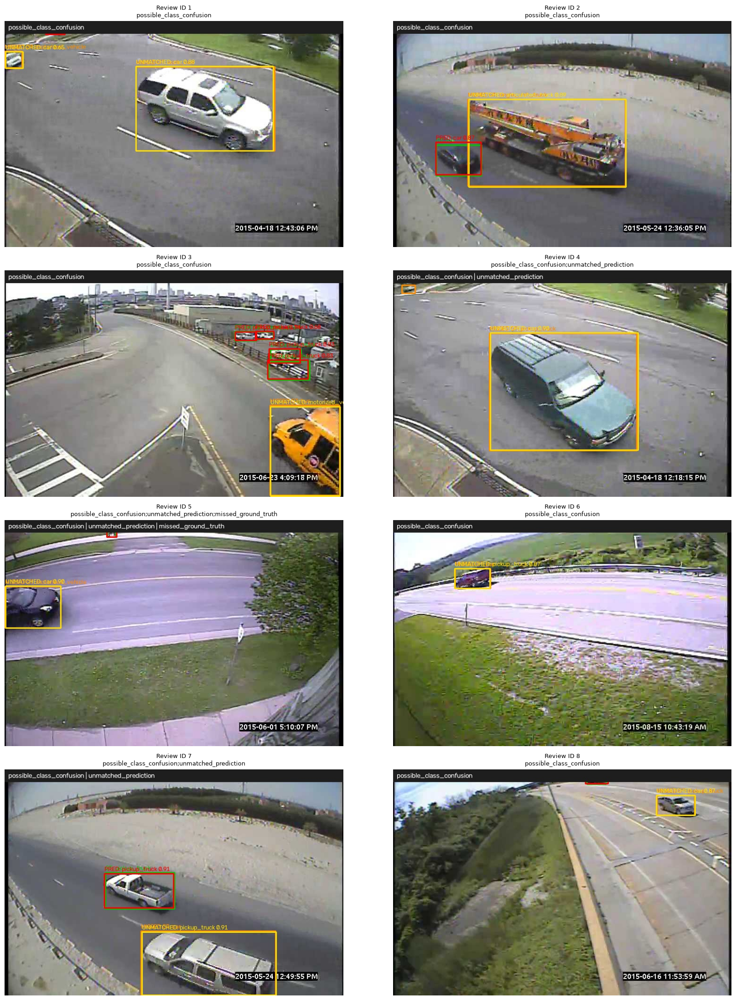

Displayed review IDs: [1, 2, 3, 4, 5, 6, 7, 8]


In [19]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import math

REVIEW_DIR = (
    Path(r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training")
    / "runs"
    / "phase_7_4_failure_quantification"
    / "phase_7_4_5_visual_review"
)

manifest_path = REVIEW_DIR / "phase_7_4_5_review_manifest.csv"
manifest = pd.read_csv(manifest_path)

batch = manifest.head(8)

fig, axes = plt.subplots(4, 2, figsize=(18, 22))
axes = axes.flatten()

for ax, (_, row) in zip(axes, batch.iterrows()):
    image_path = Path(row["annotated_image"])

    if image_path.exists():
        img = Image.open(image_path).convert("RGB")
        ax.imshow(img)
        ax.set_title(
            f"Review ID {row['review_id']}\n"
            f"{row['review_categories']}",
            fontsize=9
        )
    else:
        ax.set_title(f"Image missing: Review ID {row['review_id']}")

    ax.axis("off")

for ax in axes[len(batch):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Displayed review IDs:", batch["review_id"].tolist())


In [20]:
from pathlib import Path
import pandas as pd

BASE_DIR = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
)
REVIEW_DIR = (
    BASE_DIR / "runs" / "phase_7_4_failure_quantification"
    / "phase_7_4_5_visual_review"
)

manifest_path = REVIEW_DIR / "phase_7_4_5_review_manifest.csv"
manifest = pd.read_csv(manifest_path)

# Inspect the eight images shown in your contact sheet
first_eight = manifest.head(8).copy()

columns_to_show = [
    "review_id",
    "original_image",
    "annotated_image",
    "review_categories",
    "human_review_status",
    "confirmed_failure_type",
    "review_notes",
]

display(first_eight[columns_to_show].fillna(""))

,review_id,original_image,annotated_image,review_categories,human_review_status,confirmed_failure_type,review_notes
0,1,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,possible_class_confusion,pending,,
1,2,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,possible_class_confusion,pending,,
2,3,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,possible_class_confusion,pending,,
3,4,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,possible_class_confusion;unmatched_prediction,pending,,
4,5,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,possible_class_confusion;unmatched_prediction;...,pending,,
5,6,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,possible_class_confusion,pending,,
6,7,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,possible_class_confusion;unmatched_prediction,pending,,
7,8,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,possible_class_confusion,pending,,


In [21]:

from pathlib import Path
import pandas as pd
from IPython.display import display

BASE_DIR = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
)
REVIEW_DIR = (
    BASE_DIR / "runs" / "phase_7_4_failure_quantification"
    / "phase_7_4_5_visual_review"
)

manifest_path = REVIEW_DIR / "phase_7_4_5_review_manifest.csv"
checkpoint_path = REVIEW_DIR / "phase_7_4_5_human_review_checkpoint.csv"

manifest = pd.read_csv(manifest_path)

# Resume from the checkpoint if it already exists.
if checkpoint_path.exists():
    checkpoint = pd.read_csv(checkpoint_path)
    review_df = manifest.merge(
        checkpoint[
            ["review_id", "human_review_status",
             "confirmed_failure_type", "review_notes"]
        ],
        on="review_id",
        how="left",
        suffixes=("", "_saved"),
    )
    for col in [
        "human_review_status",
        "confirmed_failure_type",
        "review_notes",
    ]:
        saved_col = f"{col}_saved"
        if saved_col in review_df.columns:
            review_df[col] = review_df[saved_col].combine_first(
                review_df[col] if col in review_df.columns else pd.Series(
                    index=review_df.index, dtype=object
                )
            )
            review_df.drop(columns=[saved_col], inplace=True)
else:
    review_df = manifest.copy()

failure_types = [
    "confirmed_classification_error",
    "confirmed_duplicate",
    "confirmed_false_positive",
    "confirmed_missed_object",
    "localization_error",
    "annotation_issue",
    "inconclusive",
]

# Display the first eight records for manual review.
display(review_df[
    ["review_id", "original_image", "review_categories",
     "human_review_status", "confirmed_failure_type", "review_notes"]
].head(8).fillna(""))

print("Review directory:", REVIEW_DIR)
print("Checkpoint destination:", checkpoint_path)
print("Available classifications:", failure_types)


,review_id,original_image,review_categories,human_review_status,confirmed_failure_type,review_notes
0,1,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,possible_class_confusion,pending,,
1,2,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,possible_class_confusion,pending,,
2,3,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,possible_class_confusion,pending,,
3,4,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,possible_class_confusion;unmatched_prediction,pending,,
4,5,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,possible_class_confusion;unmatched_prediction;...,pending,,
5,6,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,possible_class_confusion,pending,,
6,7,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,possible_class_confusion;unmatched_prediction,pending,,
7,8,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,possible_class_confusion,pending,,


Review directory: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\phase_7_4_failure_quantification\phase_7_4_5_visual_review
Checkpoint destination: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\phase_7_4_failure_quantification\phase_7_4_5_visual_review\phase_7_4_5_human_review_checkpoint.csv
Available classifications: ['confirmed_classification_error', 'confirmed_duplicate', 'confirmed_false_positive', 'confirmed_missed_object', 'localization_error', 'annotation_issue', 'inconclusive']


In [22]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, clear_output
import ipywidgets as widgets

BASE_DIR = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
)
REVIEW_DIR = (
    BASE_DIR / "runs" / "phase_7_4_failure_quantification"
    / "phase_7_4_5_visual_review"
)
MANIFEST_PATH = REVIEW_DIR / "phase_7_4_5_review_manifest.csv"
CHECKPOINT_PATH = REVIEW_DIR / "phase_7_4_5_human_review_checkpoint.csv"

manifest = pd.read_csv(MANIFEST_PATH)

if CHECKPOINT_PATH.exists():
    saved = pd.read_csv(CHECKPOINT_PATH)
else:
    saved = pd.DataFrame(columns=[
        "review_id", "human_review_status",
        "confirmed_failure_type", "review_notes"
    ])

failure_types = [
    "confirmed_classification_error",
    "confirmed_duplicate",
    "confirmed_false_positive",
    "confirmed_missed_object",
    "localization_error",
    "annotation_issue",
    "inconclusive",
]

# Review the first eight records in this session.
batch = manifest.head(8).copy()
index_box = widgets.IntSlider(
    value=1, min=1, max=len(batch), step=1,
    description="Review ID:", continuous_update=False
)
failure_box = widgets.SelectMultiple(
    options=failure_types,
    description="Failure type:",
    rows=7,
    layout=widgets.Layout(width="440px")
)
notes_box = widgets.Textarea(
    description="Notes:",
    placeholder="Record what you verified against the original image and labels.",
    layout=widgets.Layout(width="650px", height="100px")
)
save_button = widgets.Button(
    description="Save review", button_style="success", icon="save"
)
status = widgets.Output()

def load_record(position):
    row = batch.iloc[position - 1]
    prior = saved[saved["review_id"] == row["review_id"]]

    failure_box.value = ()
    notes_box.value = ""

    if not prior.empty:
        value = prior.iloc[-1].get("confirmed_failure_type", "")
        if pd.notna(value) and value:
            failure_box.value = tuple(
                x for x in str(value).split(";") if x in failure_types
            )
        note = prior.iloc[-1].get("review_notes", "")
        notes_box.value = "" if pd.isna(note) else str(note)

    image_path = Path(str(row["annotated_image"]))
    with status:
        clear_output(wait=True)
        print("Original image:", row["original_image"])
        print("Categories flagged by automated audit:", row["review_categories"])
        if image_path.exists():
            img = Image.open(image_path).convert("RGB")
            plt.figure(figsize=(14, 8))
            plt.imshow(img)
            plt.axis("off")
            plt.show()
        else:
            print("Annotated image not found:", image_path)

def on_index_change(change):
    if change["name"] == "value":
        load_record(change["new"])

def on_save(_):
    global saved
    row = batch.iloc[index_box.value - 1]
    chosen = ";".join(failure_box.value)
    if not chosen:
        chosen = "inconclusive"

    record = {
        "review_id": row["review_id"],
        "human_review_status": "reviewed",
        "confirmed_failure_type": chosen,
        "review_notes": notes_box.value.strip(),
    }

    saved = saved[saved["review_id"] != row["review_id"]]
    saved = pd.concat([saved, pd.DataFrame([record])], ignore_index=True)
    saved.to_csv(CHECKPOINT_PATH, index=False)

    with status:
        print(f"Saved Review ID {row['review_id']} to checkpoint.")

index_box.observe(on_index_change)
save_button.on_click(on_save)

display(index_box, failure_box, notes_box, save_button, status)
load_record(1)


IntSlider(value=1, continuous_update=False, description='Review ID:', max=8, min=1)

SelectMultiple(description='Failure type:', layout=Layout(width='440px'), options=('confirmed_classification_e…

Textarea(value='', description='Notes:', layout=Layout(height='100px', width='650px'), placeholder='Record wha…

Button(button_style='success', description='Save review', icon='save', style=ButtonStyle())

Output()

In [23]:

from pathlib import Path
import pandas as pd
import json

BASE_DIR = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
)

REVIEW_DIR = (
    BASE_DIR / "runs" / "phase_7_4_failure_quantification"
    / "phase_7_4_5_visual_review"
)

MANIFEST_PATH = REVIEW_DIR / "phase_7_4_5_review_manifest.csv"
CHECKPOINT_PATH = REVIEW_DIR / "phase_7_4_5_human_review_checkpoint.csv"
OUTPUT_DIR = BASE_DIR / "runs" / "phase_7_4_failure_quantification"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert MANIFEST_PATH.exists(), f"Missing manifest: {MANIFEST_PATH}"
assert CHECKPOINT_PATH.exists(), (
    f"Checkpoint not found: {CHECKPOINT_PATH}. "
    "Run the review interface and save at least one record first."
)

manifest = pd.read_csv(MANIFEST_PATH)
checkpoint = pd.read_csv(CHECKPOINT_PATH)

required_manifest = {"review_id", "original_image", "review_categories"}
required_checkpoint = {
    "review_id", "human_review_status",
    "confirmed_failure_type", "review_notes"
}

assert required_manifest.issubset(manifest.columns), (
    f"Manifest missing columns: {required_manifest - set(manifest.columns)}"
)
assert required_checkpoint.issubset(checkpoint.columns), (
    f"Checkpoint missing columns: {required_checkpoint - set(checkpoint.columns)}"
)

# Validate IDs and duplicates.
manifest_ids = set(manifest["review_id"].dropna())
checkpoint_ids = set(checkpoint["review_id"].dropna())

duplicate_manifest_ids = manifest.loc[
    manifest["review_id"].duplicated(keep=False), "review_id"
].tolist()

duplicate_checkpoint_ids = checkpoint.loc[
    checkpoint["review_id"].duplicated(keep=False), "review_id"
].tolist()

unknown_ids = sorted(checkpoint_ids - manifest_ids)
missing_ids = sorted(manifest_ids - checkpoint_ids)

# Keep the latest checkpoint row if duplicates exist, but report duplicates above.
checkpoint_clean = checkpoint.drop_duplicates(
    subset=["review_id"], keep="last"
).copy()

reviewed_ids = set(
    checkpoint_clean.loc[
        checkpoint_clean["human_review_status"].astype(str).str.lower().eq("reviewed"),
        "review_id"
    ]
)

reviewed_count = len(reviewed_ids & manifest_ids)
total_count = len(manifest_ids)
coverage = reviewed_count / total_count if total_count else 0

print("PHASE 7.4.6 — HUMAN REVIEW VALIDATION")
print("=" * 48)
print(f"Manifest records: {total_count}")
print(f"Checkpoint rows: {len(checkpoint)}")
print(f"Distinct checkpoint IDs: {len(checkpoint_ids)}")
print(f"Reviewed manifest records: {reviewed_count}")
print(f"Pending/unreviewed records: {total_count - reviewed_count}")
print(f"Review coverage: {coverage:.1%}")
print(f"Duplicate manifest IDs: {duplicate_manifest_ids}")
print(f"Duplicate checkpoint IDs: {duplicate_checkpoint_ids}")
print(f"Unknown checkpoint IDs: {unknown_ids}")
print(f"Missing checkpoint IDs: {missing_ids}")

# Expand multi-label decisions into one row per failure type.
reviewed_rows = checkpoint_clean[
    checkpoint_clean["review_id"].isin(reviewed_ids & manifest_ids)
].copy()

expanded = []
for _, row in reviewed_rows.iterrows():
    raw = row.get("confirmed_failure_type", "")
    types = [
        x.strip() for x in str(raw).split(";")
        if x.strip() and x.strip().lower() not in {"nan", "none"}
    ]
    for failure_type in types:
        expanded.append({
            "review_id": row["review_id"],
            "failure_type": failure_type,
            "review_notes": row.get("review_notes", "")
        })

expanded_df = pd.DataFrame(
    expanded, columns=["review_id", "failure_type", "review_notes"]
)

if not expanded_df.empty:
    failure_summary = (
        expanded_df.groupby("failure_type")
        .agg(
            reviewed_records=("review_id", "nunique"),
            classification_entries=("review_id", "size")
        )
        .reset_index()
        .sort_values("reviewed_records", ascending=False)
    )
else:
    failure_summary = pd.DataFrame(
        columns=["failure_type", "reviewed_records", "classification_entries"]
    )

print("\nFailure classifications entered:")
display(failure_summary)

# Save audit outputs separately; do not overwrite the original manifest.
audit = {
    "manifest_records": int(total_count),
    "checkpoint_rows": int(len(checkpoint)),
    "distinct_checkpoint_ids": int(len(checkpoint_ids)),
    "reviewed_records": int(reviewed_count),
    "pending_records": int(total_count - reviewed_count),
    "review_coverage_fraction": float(coverage),
    "duplicate_manifest_ids": [str(x) for x in duplicate_manifest_ids],
    "duplicate_checkpoint_ids": [str(x) for x in duplicate_checkpoint_ids],
    "unknown_checkpoint_ids": [str(x) for x in unknown_ids],
    "missing_checkpoint_ids": [str(x) for x in missing_ids],
}

audit_path = OUTPUT_DIR / "phase_7_4_6_human_review_audit.json"
summary_path = OUTPUT_DIR / "phase_7_4_6_failure_type_summary.csv"
expanded_path = OUTPUT_DIR / "phase_7_4_6_human_review_expanded.csv"

with open(audit_path, "w", encoding="utf-8") as f:
    json.dump(audit, f, indent=2)

failure_summary.to_csv(summary_path, index=False)
expanded_df.to_csv(expanded_path, index=False)

print("\nSaved audit:", audit_path)
print("Saved failure summary:", summary_path)
print("Saved expanded review records:", expanded_path)


PHASE 7.4.6 — HUMAN REVIEW VALIDATION
Manifest records: 67
Checkpoint rows: 8
Distinct checkpoint IDs: 8
Reviewed manifest records: 8
Pending/unreviewed records: 59
Review coverage: 11.9%
Duplicate manifest IDs: []
Duplicate checkpoint IDs: []
Unknown checkpoint IDs: []
Missing checkpoint IDs: [9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67]

Failure classifications entered:


,failure_type,reviewed_records,classification_entries
2,inconclusive,6,6
0,annotation_issue,1,1
1,confirmed_missed_object,1,1



Saved audit: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\phase_7_4_failure_quantification\phase_7_4_6_human_review_audit.json
Saved failure summary: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\phase_7_4_failure_quantification\phase_7_4_6_failure_type_summary.csv
Saved expanded review records: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\phase_7_4_failure_quantification\phase_7_4_6_human_review_expanded.csv


In [ ]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, clear_output
import ipywidgets as widgets

BASE_DIR = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
)
REVIEW_DIR = (
    BASE_DIR / "runs" / "phase_7_4_failure_quantification"
    / "phase_7_4_5_visual_review"
)
MANIFEST_PATH = REVIEW_DIR / "phase_7_4_5_review_manifest.csv"
CHECKPOINT_PATH = REVIEW_DIR / "phase_7_4_5_human_review_checkpoint.csv"

manifest = pd.read_csv(MANIFEST_PATH)
checkpoint = pd.read_csv(CHECKPOINT_PATH) if CHECKPOINT_PATH.exists() else pd.DataFrame(
    columns=[
        "review_id", "human_review_status",
        "confirmed_failure_type", "review_notes"
    ]
)

# Only records whose status is explicitly "reviewed" count as completed.
completed_ids = set(
    checkpoint.loc[
        checkpoint["human_review_status"].astype(str).str.lower().eq("reviewed"),
        "review_id"
    ]
)
pending = manifest[~manifest["review_id"].isin(completed_ids)].copy()
pending = pending.reset_index(drop=True)

failure_types = [
    "confirmed_classification_error",
    "confirmed_duplicate",
    "confirmed_false_positive",
    "confirmed_missed_object",
    "localization_error",
    "annotation_issue",
    "inconclusive",
]

print(f"Already reviewed: {len(completed_ids & set(manifest['review_id']))}")
print(f"Remaining: {len(pending)}")

if pending.empty:
    print("All manifest records have been reviewed.")
else:
    position = widgets.IntSlider(
        value=0, min=0, max=len(pending)-1, step=1,
        description="Pending index:", continuous_update=False
    )
    failure_box = widgets.SelectMultiple(
        options=failure_types,
        description="Failure type:",
        rows=7,
        layout=widgets.Layout(width="430px")
    )
    notes_box = widgets.Textarea(
        description="Evidence/notes:",
        placeholder="Describe what you verified against the original image and labels.",
        layout=widgets.Layout(width="650px", height="100px")
    )
    save_button = widgets.Button(
        description="Save and continue", button_style="success"
    )
    output = widgets.Output()

    def show_current(_=None):
        row = pending.iloc[position.value]
        failure_box.value = ()
        notes_box.value = ""
        image_path = Path(str(row["annotated_image"]))

        with output:
            clear_output(wait=True)
            print("Review ID:", row["review_id"])
            print("Original image:", row["original_image"])
            print("Audit flags:", row["review_categories"])
            if image_path.exists():
                plt.figure(figsize=(13, 7))
                plt.imshow(Image.open(image_path).convert("RGB"))
                plt.axis("off")
                plt.show()
            else:
                print("Annotated image missing:", image_path)

    def save_current(_):
        row = pending.iloc[position.value]
        chosen = ";".join(failure_box.value) if failure_box.value else "inconclusive"

        record = {
            "review_id": row["review_id"],
            "human_review_status": "reviewed",
            "confirmed_failure_type": chosen,
            "review_notes": notes_box.value.strip(),
        }

        global checkpoint
        checkpoint = checkpoint[
            checkpoint["review_id"] != row["review_id"]
        ]
        checkpoint = pd.concat(
            [checkpoint, pd.DataFrame([record])], ignore_index=True
        )
        checkpoint.to_csv(CHECKPOINT_PATH, index=False)

        if position.value < len(pending) - 1:
            position.value += 1
        else:
            with output:
                print("This pending batch has reached its final record.")
                print("Saved checkpoint:", CHECKPOINT_PATH)

    position.observe(show_current, names="value")
    save_button.on_click(save_current)

    display(position, failure_box, notes_box, save_button, output)
    show_current()


Already reviewed: 8
Remaining: 59


IntSlider(value=0, continuous_update=False, description='Pending index:', max=58)

SelectMultiple(description='Failure type:', layout=Layout(width='430px'), options=('confirmed_classification_e…

Textarea(value='', description='Evidence/notes:', layout=Layout(height='100px', width='650px'), placeholder='D…

Button(button_style='success', description='Save and continue', style=ButtonStyle())

Output()

In [25]:

from pathlib import Path
import pandas as pd

BASE_DIR = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
)
REVIEW_DIR = (
    BASE_DIR / "runs" / "phase_7_4_failure_quantification"
    / "phase_7_4_5_visual_review"
)

manifest = pd.read_csv(
    REVIEW_DIR / "phase_7_4_5_review_manifest.csv"
)
checkpoint = pd.read_csv(
    REVIEW_DIR / "phase_7_4_5_human_review_checkpoint.csv"
)

# Count only valid, explicitly reviewed manifest records.
valid_ids = set(manifest["review_id"])
reviewed = checkpoint[
    checkpoint["review_id"].isin(valid_ids)
    & checkpoint["human_review_status"].astype(str).str.lower().eq("reviewed")
]

print(f"Total review images: {len(valid_ids)}")
print(f"Saved review records: {checkpoint['review_id'].nunique()}")
print(f"Reviewed manifest images: {reviewed['review_id'].nunique()}")
print(f"Remaining: {len(valid_ids - set(reviewed['review_id']))}")
print(f"Duplicate checkpoint IDs: {checkpoint['review_id'].duplicated().sum()}")

if (
    len(valid_ids) == 67
    and set(reviewed["review_id"]) == valid_ids
    and not checkpoint["review_id"].duplicated().any()
):
    print("\nSUCCESS: All 67 review decisions are saved.")
else:
    print("\nCHECK REQUIRED: Resolve missing or duplicate records before finalizing.")


Total review images: 67
Saved review records: 8
Reviewed manifest images: 8
Remaining: 59
Duplicate checkpoint IDs: 0

CHECK REQUIRED: Resolve missing or duplicate records before finalizing.


In [26]:

from pathlib import Path

REVIEW_DIR = (
    Path(r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training")
    / "runs" / "phase_7_4_failure_quantification"
    / "phase_7_4_5_visual_review"
)

print("Review-related files found:\n")

for path in sorted(REVIEW_DIR.glob("*")):
    if path.is_file() and any(
        word in path.name.lower()
        for word in ["review", "checkpoint", "manifest"]
    ):
        print(f"{path.name}  |  {path.stat().st_size:,} bytes")


Review-related files found:

phase_7_4_5_human_review_checkpoint.csv  |  290 bytes
phase_7_4_5_review_manifest.csv  |  19,310 bytes
phase_7_4_5_visual_review_summary.json  |  880 bytes
review_0001_00004108.jpg  |  67,305 bytes
review_0002_00000626.jpg  |  66,329 bytes
review_0003_00001886.jpg  |  87,837 bytes
review_0004_00003087.jpg  |  72,212 bytes
review_0005_00005244.jpg  |  79,522 bytes
review_0006_00004375.jpg  |  89,096 bytes
review_0007_00002433.jpg  |  70,869 bytes
review_0008_00004554.jpg  |  65,909 bytes
review_0009_00003515.jpg  |  30,912 bytes
review_0010_00005632.jpg  |  77,067 bytes
review_0011_00005221.jpg  |  53,134 bytes
review_0012_00001969.jpg  |  95,275 bytes
review_0013_00002916.jpg  |  32,492 bytes
review_0014_00000449.jpg  |  49,848 bytes
review_0015_00002404.jpg  |  74,352 bytes
review_0016_00001397.jpg  |  29,385 bytes
review_0017_00003227.jpg  |  101,548 bytes
review_0018_00002408.jpg  |  24,601 bytes
review_0019_00004470.jpg  |  77,084 bytes
review_0020_0000

In [27]:

from pathlib import Path
import pandas as pd

REVIEW_DIR = (
    Path(r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training")
    / "runs" / "phase_7_4_failure_quantification"
    / "phase_7_4_5_visual_review"
)

manifest = pd.read_csv(REVIEW_DIR / "phase_7_4_5_review_manifest.csv")
checkpoint = pd.read_csv(
    REVIEW_DIR / "phase_7_4_5_human_review_checkpoint.csv"
)
summary_path = REVIEW_DIR / "phase_7_4_5_visual_review_summary.json"

print("=== SAVED HUMAN DECISIONS ===")
display(checkpoint)

print("\n=== REVIEW MANIFEST STATUS ===")
saved_ids = set(checkpoint["review_id"])
pending = manifest[~manifest["review_id"].isin(saved_ids)]

print(f"Total images: {len(manifest)}")
print(f"Saved decisions: {len(saved_ids)}")
print(f"Records without checkpoint entries: {len(pending)}")

display(
    pending[
        ["review_id", "original_image", "annotated_image", "review_categories"]
    ].head(15)
)

print("\n=== ORIGINAL VISUAL REVIEW SUMMARY ===")
if summary_path.exists():
    print(summary_path.read_text(encoding="utf-8"))
else:
    print("No visual review summary JSON found.")


=== SAVED HUMAN DECISIONS ===


,review_id,human_review_status,confirmed_failure_type,review_notes
0,1,reviewed,inconclusive,NaN
1,2,reviewed,annotation_issue,NaN
2,3,reviewed,confirmed_missed_object,NaN
3,4,reviewed,inconclusive,NaN
4,5,reviewed,inconclusive,NaN
5,6,reviewed,inconclusive,NaN
6,7,reviewed,inconclusive,NaN
7,8,reviewed,inconclusive,NaN



=== REVIEW MANIFEST STATUS ===
Total images: 67
Saved decisions: 8
Records without checkpoint entries: 59


,review_id,original_image,annotated_image,review_categories
8,9,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,possible_class_confusion
9,10,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,possible_class_confusion
10,11,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,possible_class_confusion
11,12,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,possible_class_confusion;missed_ground_truth
12,13,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,possible_class_confusion;missed_ground_truth
13,14,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,possible_class_confusion
14,15,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,possible_class_confusion
15,16,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,possible_class_confusion
16,17,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,possible_class_confusion
17,18,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,possible_class_confusion



=== ORIGINAL VISUAL REVIEW SUMMARY ===
{
  "phase": "7.4.5",
  "split": "validation",
  "candidate_sampling_limit_per_category": 20,
  "unique_images_selected": 67,
  "images_rendered": 67,
  "missing_or_unreadable_images": 0,
  "annotated_image_directory": "C:\\Material\\Repo\\Projects\\Capstone_1\\Part_1\\model_training\\runs\\phase_7_4_failure_quantification\\phase_7_4_5_visual_review",
  "review_manifest": "C:\\Material\\Repo\\Projects\\Capstone_1\\Part_1\\model_training\\runs\\phase_7_4_failure_quantification\\phase_7_4_5_visual_review\\phase_7_4_5_review_manifest.csv",
  "legend": {
    "green": "ground-truth object",
    "red": "prediction matched by the existing audit",
    "yellow": "unmatched prediction",
    "orange": "missed ground-truth object"
  },
  "caveat": "Annotations are diagnostic overlays. Candidate labels are not confirmed until a human inspects the original image."
}


In [ ]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, clear_output
import ipywidgets as widgets

BASE = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
)
REVIEW_DIR = (
    BASE / "runs" / "phase_7_4_failure_quantification"
    / "phase_7_4_5_visual_review"
)
MANIFEST_PATH = REVIEW_DIR / "phase_7_4_5_review_manifest.csv"
CHECKPOINT_PATH = REVIEW_DIR / "phase_7_4_5_human_review_checkpoint.csv"

manifest = pd.read_csv(MANIFEST_PATH)
checkpoint = pd.read_csv(CHECKPOINT_PATH)

failure_types = [
    "confirmed_classification_error",
    "confirmed_duplicate",
    "confirmed_false_positive",
    "confirmed_missed_object",
    "localization_error",
    "annotation_issue",
    "inconclusive",
]

def get_completed_ids(df):
    return set(
        df.loc[
            df["human_review_status"].astype(str).str.lower().eq("reviewed"),
            "review_id"
        ]
    )

completed_ids = get_completed_ids(checkpoint)
pending = manifest[~manifest["review_id"].isin(completed_ids)].reset_index(drop=True)

print(f"Saved reviewed records: {len(completed_ids)}")
print(f"Remaining records: {len(pending)}")

if pending.empty:
    print("All review records are saved. No further review is needed.")
else:
    position = widgets.IntSlider(
        value=0, min=0, max=len(pending)-1, step=1,
        description="Image:", continuous_update=False
    )
    types = widgets.SelectMultiple(
        options=failure_types,
        description="Classification:",
        rows=7,
        layout=widgets.Layout(width="430px")
    )
    notes = widgets.Textarea(
        description="Evidence:",
        placeholder="Briefly note what you verified in the image and annotations.",
        layout=widgets.Layout(width="650px", height="90px")
    )
    save = widgets.Button(
        description="Save decision", button_style="success", icon="save"
    )
    output = widgets.Output()

    def show_image(_=None):
        row = pending.iloc[position.value]
        types.value = ()
        notes.value = ""

        with output:
            clear_output(wait=True)
            print(f"Review ID: {row['review_id']}")
            print(f"Candidate category: {row['review_categories']}")
            print(f"Original: {row['original_image']}")

            path = Path(str(row["annotated_image"]))
            if path.exists():
                plt.figure(figsize=(13, 7))
                plt.imshow(Image.open(path).convert("RGB"))
                plt.axis("off")
                plt.show()
            else:
                print("Image file missing:", path)

    def save_decision(_):
        global checkpoint
        row = pending.iloc[position.value]

        selected = list(types.value)
        if not selected:
            with output:
                print("Select a classification before saving.")
            return

        record = {
            "review_id": row["review_id"],
            "human_review_status": "reviewed",
            "confirmed_failure_type": ";".join(selected),
            "review_notes": notes.value.strip(),
        }

        # Replace any prior entry for this ID, then save immediately.
        checkpoint = checkpoint[
            checkpoint["review_id"] != row["review_id"]
        ]
        checkpoint = pd.concat(
            [checkpoint, pd.DataFrame([record])],
            ignore_index=True
        )
        checkpoint.to_csv(CHECKPOINT_PATH, index=False)

        with output:
            print(f"Saved Review ID {row['review_id']}.")

        if position.value < len(pending) - 1:
            position.value += 1
        else:
            with output:
                print("End of pending review batch.")

    position.observe(show_image, names="value")
    save.on_click(save_decision)

    display(position, types, notes, save, output)
    show_image()


Saved reviewed records: 8
Remaining records: 59


IntSlider(value=0, continuous_update=False, description='Image:', max=58)

SelectMultiple(description='Classification:', layout=Layout(width='430px'), options=('confirmed_classification…

Textarea(value='', description='Evidence:', layout=Layout(height='90px', width='650px'), placeholder='Briefly …

Button(button_style='success', description='Save decision', icon='save', style=ButtonStyle())

Output()

In [44]:

# ============================================================
# PHASE 7.4.6 — HUMAN REVIEW AUDIT
# ============================================================

from pathlib import Path
import json
import pandas as pd
from datetime import datetime, timezone

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

ROOT = Path.cwd()

# If the notebook is not running from the project root,
# update ROOT to your model_training directory.
EXPECTED_ROOT_NAME = "model_training"

if ROOT.name != EXPECTED_ROOT_NAME:
    candidate = Path(
        r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
    )
    if candidate.exists():
        ROOT = candidate
    else:
        raise FileNotFoundError(
            f"Could not locate project root. Current directory: {ROOT}"
        )

REVIEW_DIR = (
    ROOT
    / "runs"
    / "phase_7_4_failure_quantification"
    / "phase_7_4_5_visual_review"
)

MANIFEST_PATH = (
    REVIEW_DIR / "phase_7_4_5_review_manifest.csv"
)

# Prefer the latest checkpoint used by the review interface.
CHECKPOINT_CANDIDATES = [
    ROOT / "runs" / "phase_7_4_failure_quantification"
        / "phase_7_4_5_human_review_checkpoint.csv",
    REVIEW_DIR / "phase_7_4_5_human_review_checkpoint.csv",
    ROOT / "runs" / "phase_7_4_failure_quantification"
        / "phase_7_4_6_human_review_expanded.csv",
]

OUTPUT_DIR = (
    ROOT / "runs" / "phase_7_4_failure_quantification"
)

AUDIT_JSON = OUTPUT_DIR / "phase_7_4_6_human_review_audit.json"
SUMMARY_CSV = OUTPUT_DIR / "phase_7_4_6_failure_type_summary.csv"
EXPANDED_CSV = OUTPUT_DIR / "phase_7_4_6_human_review_expanded.csv"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. Load manifest and checkpoint
# ------------------------------------------------------------

if not MANIFEST_PATH.exists():
    raise FileNotFoundError(
        f"Review manifest not found: {MANIFEST_PATH}"
    )

manifest = pd.read_csv(MANIFEST_PATH)

checkpoint_path = next(
    (p for p in CHECKPOINT_CANDIDATES if p.exists()),
    None
)

if checkpoint_path is None:
    raise FileNotFoundError(
        "No human-review checkpoint was found. "
        "Check the path used by your review interface."
    )

checkpoint = pd.read_csv(checkpoint_path)

print("Project root:", ROOT)
print("Manifest:", MANIFEST_PATH)
print("Checkpoint:", checkpoint_path)
print()

# ------------------------------------------------------------
# 3. Validate required columns
# ------------------------------------------------------------

if "review_id" not in manifest.columns:
    raise ValueError("Manifest must contain 'review_id'.")

if "review_id" not in checkpoint.columns:
    raise ValueError("Checkpoint must contain 'review_id'.")

if "human_review_status" not in manifest.columns:
    manifest["human_review_status"] = "pending"

if "human_review_status" not in checkpoint.columns:
    checkpoint["human_review_status"] = "pending"

# Normalize IDs and statuses.
manifest["review_id"] = pd.to_numeric(
    manifest["review_id"], errors="coerce"
)
checkpoint["review_id"] = pd.to_numeric(
    checkpoint["review_id"], errors="coerce"
)

manifest["human_review_status"] = (
    manifest["human_review_status"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.lower()
)

checkpoint["human_review_status"] = (
    checkpoint["human_review_status"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.lower()
)

# Only checkpoint rows explicitly marked reviewed count as
# completed. Rows with other statuses remain pending.
saved_reviews = checkpoint[
    checkpoint["human_review_status"].eq("reviewed")
].copy()

# ------------------------------------------------------------
# 4. Integrity checks
# ------------------------------------------------------------

manifest_valid_ids = set(
    manifest["review_id"].dropna().astype(int)
)
checkpoint_valid_ids = set(
    checkpoint["review_id"].dropna().astype(int)
)
reviewed_ids = set(
    saved_reviews["review_id"].dropna().astype(int)
)

duplicate_manifest_ids = (
    manifest.loc[
        manifest["review_id"].duplicated(keep=False),
        "review_id"
    ]
    .dropna()
    .astype(int)
    .unique()
    .tolist()
)

duplicate_checkpoint_ids = (
    checkpoint.loc[
        checkpoint["review_id"].duplicated(keep=False),
        "review_id"
    ]
    .dropna()
    .astype(int)
    .unique()
    .tolist()
)

unknown_checkpoint_ids = sorted(
    checkpoint_valid_ids - manifest_valid_ids
)

missing_review_ids = sorted(
    manifest_valid_ids - reviewed_ids
)

# A duplicate checkpoint ID is ambiguous: flag it and do not
# silently assume which row is authoritative.
ambiguous_review_ids = set(duplicate_checkpoint_ids)
valid_reviewed_ids = reviewed_ids - ambiguous_review_ids

# Map only unambiguous reviewed rows back to the manifest.
review_columns = [
    c for c in saved_reviews.columns
    if c == "review_id" or c not in manifest.columns
]

# Classification and notes should be taken from the saved
# checkpoint, not inferred from image inspection.
preferred_fields = [
    "confirmed_failure_type",
    "review_classification",
    "classification",
    "review_notes",
]

for col in preferred_fields:
    if col in saved_reviews.columns and col not in manifest.columns:
        review_columns.append(col)

review_columns = list(dict.fromkeys(review_columns))

review_data = saved_reviews[
    saved_reviews["review_id"].isin(valid_reviewed_ids)
][review_columns].copy()

# If duplicate rows exist, the audit flags them above rather
# than arbitrarily selecting one classification.
expanded = manifest.merge(
    review_data,
    on="review_id",
    how="left",
    suffixes=("", "_checkpoint"),
    validate="one_to_one"
)

expanded["audit_review_status"] = expanded["review_id"].apply(
    lambda rid: (
        "reviewed"
        if pd.notna(rid) and int(rid) in valid_reviewed_ids
        else "pending_or_ambiguous"
    )
)

# ------------------------------------------------------------
# 5. Coverage and classification summary
# ------------------------------------------------------------

total_manifest_records = len(manifest)
total_unique_manifest_ids = len(manifest_valid_ids)
reviewed_count = len(valid_reviewed_ids)
pending_count = total_unique_manifest_ids - reviewed_count

coverage_pct = (
    100 * reviewed_count / total_unique_manifest_ids
    if total_unique_manifest_ids else 0.0
)

classification_col = next(
    (
        c for c in [
            "confirmed_failure_type",
            "review_classification",
            "classification",
        ]
        if c in expanded.columns
    ),
    None
)

if classification_col:
    classifications = (
        expanded.loc[
            expanded["audit_review_status"].eq("reviewed"),
            classification_col
        ]
        .fillna("unclassified")
        .astype(str)
        .str.strip()
        .replace("", "unclassified")
    )
    classification_summary = (
        classifications.value_counts().to_dict()
    )
else:
    classification_summary = {}

audit = {
    "phase": "7.4.6",
    "audit_timestamp_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "manifest_path": str(MANIFEST_PATH),
    "checkpoint_path": str(checkpoint_path),
    "total_manifest_records": int(total_manifest_records),
    "total_unique_manifest_ids": int(total_unique_manifest_ids),
    "checkpoint_rows": int(len(checkpoint)),
    "checkpoint_unique_ids": int(len(checkpoint_valid_ids)),
    "saved_review_rows_marked_reviewed": int(len(saved_reviews)),
    "valid_reviewed_ids": int(reviewed_count),
    "pending_or_ambiguous_ids": int(pending_count),
    "review_coverage_percent": round(coverage_pct, 2),
    "duplicate_manifest_ids": duplicate_manifest_ids,
    "duplicate_checkpoint_ids": duplicate_checkpoint_ids,
    "unknown_checkpoint_ids": unknown_checkpoint_ids,
    "missing_or_unreviewed_ids": missing_review_ids,
    "ambiguous_review_ids": sorted(ambiguous_review_ids),
    "classification_column": classification_col,
    "classification_summary": classification_summary,
    "all_reviews_saved": (
        total_unique_manifest_ids > 0
        and reviewed_count == total_unique_manifest_ids
        and not duplicate_manifest_ids
        and not duplicate_checkpoint_ids
        and not unknown_checkpoint_ids
    ),
}

# ------------------------------------------------------------
# 6. Save outputs
# ------------------------------------------------------------

with open(AUDIT_JSON, "w", encoding="utf-8") as f:
    json.dump(audit, f, indent=2, ensure_ascii=False)

if classification_col:
    summary_df = (
        expanded.loc[
            expanded["audit_review_status"].eq("reviewed"),
            classification_col
        ]
        .fillna("unclassified")
        .astype(str)
        .str.strip()
        .replace("", "unclassified")
        .value_counts()
        .rename_axis("failure_type")
        .reset_index(name="count")
    )
else:
    summary_df = pd.DataFrame(
        columns=["failure_type", "count"]
    )

summary_df.to_csv(SUMMARY_CSV, index=False)
expanded.to_csv(EXPANDED_CSV, index=False)

# ------------------------------------------------------------
# 7. Display audit
# ------------------------------------------------------------

print("=" * 60)
print("PHASE 7.4.6 — HUMAN REVIEW AUDIT RESULTS")
print("=" * 60)
print(f"Manifest records:          {total_manifest_records}")
print(f"Unique manifest IDs:       {total_unique_manifest_ids}")
print(f"Checkpoint rows:           {len(checkpoint)}")
print(f"Saved rows marked reviewed:{len(saved_reviews):>6}")
print(f"Valid reviewed IDs:        {reviewed_count}")
print(f"Pending/ambiguous IDs:     {pending_count}")
print(f"Review coverage:           {coverage_pct:.2f}%")
print()

print("Integrity checks")
print("Duplicate manifest IDs:", duplicate_manifest_ids)
print("Duplicate checkpoint IDs:", duplicate_checkpoint_ids)
print("Unknown checkpoint IDs:", unknown_checkpoint_ids)
print("Ambiguous IDs:", sorted(ambiguous_review_ids))
print()

print("Classification summary:")
if classification_summary:
    for label, count in classification_summary.items():
        print(f"  {label}: {count}")
else:
    print(
        "  No recognized classification column was found "
        "in the saved review checkpoint."
    )

print()
print("All reviews saved and integrity checks passed:",
      audit["all_reviews_saved"])
print()
print("Saved audit:", AUDIT_JSON)
print("Saved classification summary:", SUMMARY_CSV)
print("Saved expanded review table:", EXPANDED_CSV)


Project root: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training
Manifest: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\phase_7_4_failure_quantification\phase_7_4_5_visual_review\phase_7_4_5_review_manifest.csv
Checkpoint: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\phase_7_4_failure_quantification\phase_7_4_5_visual_review\phase_7_4_5_human_review_checkpoint.csv

PHASE 7.4.6 — HUMAN REVIEW AUDIT RESULTS
Manifest records:          67
Unique manifest IDs:       67
Checkpoint rows:           67
Saved rows marked reviewed:    67
Valid reviewed IDs:        67
Pending/ambiguous IDs:     0
Review coverage:           100.00%

Integrity checks
Duplicate manifest IDs: []
Duplicate checkpoint IDs: []
Unknown checkpoint IDs: []
Ambiguous IDs: []

Classification summary:
  unclassified: 67

All reviews saved and integrity checks passed: True

Saved audit: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\phase_7_4_failure_quantification\

In [45]:

from pathlib import Path
import pandas as pd

checkpoint_path = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
    r"\runs\phase_7_4_failure_quantification"
    r"\phase_7_4_5_visual_review"
    r"\phase_7_4_5_human_review_checkpoint.csv"
)

checkpoint = pd.read_csv(checkpoint_path)

print("Checkpoint columns:")
print(checkpoint.columns.tolist())

print("\nSaved checkpoint contents:")
display(checkpoint)

print("\nReview manifest columns:")
manifest_path = checkpoint_path.parent / "phase_7_4_5_review_manifest.csv"
manifest = pd.read_csv(manifest_path)
print(manifest.columns.tolist())


Checkpoint columns:
['review_id', 'human_review_status', 'confirmed_failure_type', 'review_notes']

Saved checkpoint contents:


,review_id,human_review_status,confirmed_failure_type,review_notes
0,1,reviewed,inconclusive,NaN
1,2,reviewed,annotation_issue,NaN
2,3,reviewed,confirmed_missed_object,NaN
3,4,reviewed,inconclusive,NaN
4,5,reviewed,inconclusive,NaN
...,...,...,...,...
62,63,reviewed,confirmed_classification_error,NaN
63,64,reviewed,inconclusive,NaN
64,65,reviewed,confirmed_missed_object,NaN
65,66,reviewed,confirmed_missed_object,NaN



Review manifest columns:
['review_id', 'original_image', 'annotated_image', 'review_categories', 'human_review_status', 'confirmed_failure_type', 'review_notes']


In [46]:

from pathlib import Path
import pandas as pd
import json
from datetime import datetime, timezone

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

ROOT = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
)

BASE_DIR = ROOT / "runs" / "phase_7_4_failure_quantification"
REVIEW_DIR = BASE_DIR / "phase_7_4_5_visual_review"

MANIFEST_PATH = REVIEW_DIR / "phase_7_4_5_review_manifest.csv"
CHECKPOINT_PATH = REVIEW_DIR / "phase_7_4_5_human_review_checkpoint.csv"

AUDIT_PATH = BASE_DIR / "phase_7_4_6_human_review_audit.json"
SUMMARY_PATH = BASE_DIR / "phase_7_4_6_failure_type_summary.csv"
EXPANDED_PATH = BASE_DIR / "phase_7_4_6_human_review_expanded.csv"

manifest = pd.read_csv(MANIFEST_PATH)
checkpoint = pd.read_csv(CHECKPOINT_PATH)

# ------------------------------------------------------------
# 2. Validate schema and normalize review IDs
# ------------------------------------------------------------

required_manifest = {
    "review_id", "human_review_status",
    "confirmed_failure_type", "review_notes"
}
required_checkpoint = {
    "review_id", "human_review_status",
    "confirmed_failure_type", "review_notes"
}

assert required_manifest.issubset(manifest.columns), (
    f"Manifest missing columns: "
    f"{required_manifest - set(manifest.columns)}"
)
assert required_checkpoint.issubset(checkpoint.columns), (
    f"Checkpoint missing columns: "
    f"{required_checkpoint - set(checkpoint.columns)}"
)

manifest["review_id"] = pd.to_numeric(
    manifest["review_id"], errors="coerce"
)
checkpoint["review_id"] = pd.to_numeric(
    checkpoint["review_id"], errors="coerce"
)

manifest["human_review_status"] = (
    manifest["human_review_status"]
    .fillna("").astype(str).str.strip().str.lower()
)
checkpoint["human_review_status"] = (
    checkpoint["human_review_status"]
    .fillna("").astype(str).str.strip().str.lower()
)

# Only rows explicitly marked reviewed count as saved reviews.
saved = checkpoint[
    checkpoint["human_review_status"].eq("reviewed")
].copy()

manifest_ids = set(manifest["review_id"].dropna().astype(int))
checkpoint_ids = set(checkpoint["review_id"].dropna().astype(int))
saved_ids = set(saved["review_id"].dropna().astype(int))

duplicate_manifest_ids = (
    manifest.loc[
        manifest["review_id"].duplicated(keep=False), "review_id"
    ].dropna().astype(int).unique().tolist()
)
duplicate_checkpoint_ids = (
    checkpoint.loc[
        checkpoint["review_id"].duplicated(keep=False), "review_id"
    ].dropna().astype(int).unique().tolist()
)
unknown_checkpoint_ids = sorted(checkpoint_ids - manifest_ids)

# Do not choose arbitrarily between duplicate checkpoint rows.
ambiguous_ids = set(duplicate_checkpoint_ids)
valid_saved_ids = saved_ids - ambiguous_ids

# ------------------------------------------------------------
# 3. Use the checkpoint's classifications as authoritative
# ------------------------------------------------------------

saved = saved[saved["review_id"].isin(valid_saved_ids)].copy()

checkpoint_fields = saved[
    ["review_id", "confirmed_failure_type", "review_notes"]
].copy()

# Avoid column-name collisions by removing manifest copies first.
base_manifest = manifest.drop(
    columns=["confirmed_failure_type", "review_notes"],
    errors="ignore"
)

expanded = base_manifest.merge(
    checkpoint_fields,
    on="review_id",
    how="left",
    validate="one_to_one"
)

expanded["audit_review_status"] = expanded["review_id"].apply(
    lambda rid: (
        "reviewed"
        if pd.notna(rid) and int(rid) in valid_saved_ids
        else "pending_or_ambiguous"
    )
)

expanded["confirmed_failure_type"] = (
    expanded["confirmed_failure_type"]
    .fillna("")
    .astype(str).str.strip()
)

expanded["review_notes"] = expanded["review_notes"].fillna("")

# ------------------------------------------------------------
# 4. Coverage and classification summary
# ------------------------------------------------------------

total_records = len(manifest)
total_unique_ids = len(manifest_ids)
reviewed_count = len(valid_saved_ids)
pending_count = total_unique_ids - reviewed_count

coverage = (
    reviewed_count / total_unique_ids * 100
    if total_unique_ids else 0.0
)

reviewed_rows = expanded[
    expanded["audit_review_status"].eq("reviewed")
].copy()

reviewed_rows["confirmed_failure_type"] = (
    reviewed_rows["confirmed_failure_type"]
    .replace("", "unclassified")
)

summary = (
    reviewed_rows["confirmed_failure_type"]
    .value_counts()
    .rename_axis("failure_type")
    .reset_index(name="count")
)

# A fully saved review requires every manifest ID to have one
# unambiguous saved checkpoint row and no integrity violations.
all_reviews_saved = (
    total_unique_ids > 0
    and reviewed_count == total_unique_ids
    and not duplicate_manifest_ids
    and not duplicate_checkpoint_ids
    and not unknown_checkpoint_ids
)

audit = {
    "phase": "7.4.6",
    "audit_timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "manifest_path": str(MANIFEST_PATH),
    "checkpoint_path": str(CHECKPOINT_PATH),
    "total_manifest_records": total_records,
    "total_unique_manifest_ids": total_unique_ids,
    "checkpoint_rows": len(checkpoint),
    "saved_rows_marked_reviewed": len(saved),
    "valid_reviewed_ids": reviewed_count,
    "pending_or_ambiguous_ids": pending_count,
    "review_coverage_percent": round(coverage, 2),
    "duplicate_manifest_ids": duplicate_manifest_ids,
    "duplicate_checkpoint_ids": duplicate_checkpoint_ids,
    "unknown_checkpoint_ids": unknown_checkpoint_ids,
    "ambiguous_review_ids": sorted(ambiguous_ids),
    "classification_summary": dict(
        zip(summary["failure_type"], summary["count"])
    ),
    "all_reviews_saved": all_reviews_saved,
}

# ------------------------------------------------------------
# 5. Save corrected outputs
# ------------------------------------------------------------

with open(AUDIT_PATH, "w", encoding="utf-8") as f:
    json.dump(audit, f, indent=2, ensure_ascii=False)

summary.to_csv(SUMMARY_PATH, index=False)
expanded.to_csv(EXPANDED_PATH, index=False)

# ------------------------------------------------------------
# 6. Display results
# ------------------------------------------------------------

print("=" * 58)
print("PHASE 7.4.6 — CORRECTED HUMAN REVIEW AUDIT")
print("=" * 58)
print(f"Manifest records:       {total_records}")
print(f"Checkpoint rows:        {len(checkpoint)}")
print(f"Saved reviewed IDs:     {reviewed_count}")
print(f"Pending/ambiguous IDs:  {pending_count}")
print(f"Review coverage:        {coverage:.2f}%")
print()
print("Classification summary:")
print(summary.to_string(index=False))
print()
print("Duplicate manifest IDs:", duplicate_manifest_ids)
print("Duplicate checkpoint IDs:", duplicate_checkpoint_ids)
print("Unknown checkpoint IDs:", unknown_checkpoint_ids)
print("All reviews saved:", all_reviews_saved)
print()
print("Saved:", AUDIT_PATH)
print("Saved:", SUMMARY_PATH)
print("Saved:", EXPANDED_PATH)


PHASE 7.4.6 — CORRECTED HUMAN REVIEW AUDIT
Manifest records:       67
Checkpoint rows:        67
Saved reviewed IDs:     67
Pending/ambiguous IDs:  0
Review coverage:        100.00%

Classification summary:
                  failure_type  count
                  inconclusive     51
       confirmed_missed_object     10
confirmed_classification_error      5
              annotation_issue      1

Duplicate manifest IDs: []
Duplicate checkpoint IDs: []
Unknown checkpoint IDs: []
All reviews saved: True

Saved: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\phase_7_4_failure_quantification\phase_7_4_6_human_review_audit.json
Saved: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\phase_7_4_failure_quantification\phase_7_4_6_failure_type_summary.csv
Saved: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\phase_7_4_failure_quantification\phase_7_4_6_human_review_expanded.csv


In [47]:

from pathlib import Path

ROOT = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
)

review_dir = (
    ROOT / "runs" / "phase_7_4_failure_quantification"
    / "phase_7_4_5_visual_review"
)

print("Review-related Python files in the review directory:")
for p in sorted(review_dir.glob("*.py")):
    print(p.name)

print("\nReview-related files:")
for p in sorted(review_dir.iterdir()):
    if any(word in p.name.lower() for word in [
        "review", "checkpoint", "manifest", "phase_7_4_6"
    ]):
        print(f"{p.name}  |  {p.stat().st_size:,} bytes")


Review-related Python files in the review directory:

Review-related files:
phase_7_4_5_human_review_checkpoint.csv  |  2,071 bytes
phase_7_4_5_review_manifest.csv  |  19,310 bytes
phase_7_4_5_visual_review_summary.json  |  880 bytes
review_0001_00004108.jpg  |  67,305 bytes
review_0002_00000626.jpg  |  66,329 bytes
review_0003_00001886.jpg  |  87,837 bytes
review_0004_00003087.jpg  |  72,212 bytes
review_0005_00005244.jpg  |  79,522 bytes
review_0006_00004375.jpg  |  89,096 bytes
review_0007_00002433.jpg  |  70,869 bytes
review_0008_00004554.jpg  |  65,909 bytes
review_0009_00003515.jpg  |  30,912 bytes
review_0010_00005632.jpg  |  77,067 bytes
review_0011_00005221.jpg  |  53,134 bytes
review_0012_00001969.jpg  |  95,275 bytes
review_0013_00002916.jpg  |  32,492 bytes
review_0014_00000449.jpg  |  49,848 bytes
review_0015_00002404.jpg  |  74,352 bytes
review_0016_00001397.jpg  |  29,385 bytes
review_0017_00003227.jpg  |  101,548 bytes
review_0018_00002408.jpg  |  24,601 bytes
review_00

In [48]:

# Phase 7.4.6 — Review Interface State Diagnostic
# Read-only: does not modify files or classifications.

from IPython import get_ipython

ip = get_ipython()

print("Notebook kernel available:", ip is not None)

if ip is not None:
    ns = ip.user_ns

    keywords = (
        "review", "checkpoint", "manifest",
        "current_idx", "review_idx", "classification",
        "failure_type", "review_notes", "save_review"
    )

    print("\nPotentially relevant notebook variables:")
    found = []

    for name, value in ns.items():
        if name.startswith("_") or not any(
            key in name.lower() for key in keywords
        ):
            continue

        # Avoid printing large data objects or image contents.
        value_type = type(value).__name__
        if value_type in {
            "DataFrame", "Series", "list", "dict",
            "str", "int", "float", "bool"
        } or callable(value):
            found.append((name, value_type))

    for name, value_type in sorted(found):
        print(f"{name}: {value_type}")

    if not found:
        print("No obvious review-state variables found.")



Notebook kernel available: True

Potentially relevant notebook variables:
CHECKPOINT_CANDIDATES: list
all_reviews_saved: bool
base_manifest: DataFrame
checkpoint: DataFrame
checkpoint_clean: DataFrame
checkpoint_fields: DataFrame
classification_col: str
classification_counts: dict
classification_summary: dict
classifications: Series
df_preview: DataFrame
duplicate_checkpoint_ids: list
duplicate_manifest_ids: list
failure_type: str
failure_types: list
manifest: DataFrame
manifest_df: DataFrame
missing_review_ids: list
preview: str
review: dict
review_columns: list
review_data: DataFrame
review_df: DataFrame
review_reasons: dict
reviewed: DataFrame
reviewed_count: int
reviewed_rows: DataFrame
saved_reviews: DataFrame
total_manifest_records: int
total_unique_manifest_ids: int
unknown_checkpoint_ids: list


In [49]:

# Phase 7.4.6 — In-Memory Review Recovery Check
# Read-only: no files are modified.

import pandas as pd
from pathlib import Path

ns = get_ipython().user_ns

checkpoint_path = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
    r"\runs\phase_7_4_failure_quantification"
    r"\phase_7_4_5_visual_review"
    r"\phase_7_4_5_human_review_checkpoint.csv"
)

disk = pd.read_csv(checkpoint_path)
disk["review_id"] = pd.to_numeric(disk["review_id"], errors="coerce")

print("ON-DISK CHECKPOINT")
print("Rows:", len(disk))
print("Reviewed rows:", (
    disk["human_review_status"].fillna("").astype(str)
    .str.strip().str.lower().eq("reviewed").sum()
))
print()

candidate_names = [
    "checkpoint", "checkpoint_clean", "checkpoint_fields",
    "manifest", "manifest_df", "review_df", "reviewed",
    "reviewed_rows", "saved_reviews", "review_data",
    "review_columns", "df_preview"
]

seen = set()

for name in candidate_names:
    obj = ns.get(name)

    if not isinstance(obj, pd.DataFrame):
        continue

    # Avoid printing the same dataframe repeatedly.
    identity = id(obj)
    if identity in seen:
        continue
    seen.add(identity)

    if "review_id" not in obj.columns:
        continue

    temp = obj.copy()
    temp["review_id"] = pd.to_numeric(
        temp["review_id"], errors="coerce"
    )

    print(f"IN-MEMORY DATAFRAME: {name}")
    print("Rows:", len(temp))
    print("Columns:", temp.columns.tolist())

    if "human_review_status" in temp.columns:
        statuses = (
            temp["human_review_status"].fillna("").astype(str)
            .str.strip().str.lower().value_counts().to_dict()
        )
        print("Status counts:", statuses)

    if "confirmed_failure_type" in temp.columns:
        classifications = (
            temp["confirmed_failure_type"].fillna("").astype(str)
            .str.strip()
        )
        nonempty = classifications.ne("")
        print("Nonempty classifications:", int(nonempty.sum()))

        if nonempty.any():
            print("Classification counts:")
            print(
                classifications[nonempty]
                .value_counts()
                .to_dict()
            )

    ids = set(temp["review_id"].dropna().astype(int))
    print("Review IDs:", sorted(ids)[:12],
          "..." if len(ids) > 12 else "")
    print()

print("Diagnostic complete. No files were changed.")


ON-DISK CHECKPOINT
Rows: 67
Reviewed rows: 67

IN-MEMORY DATAFRAME: checkpoint
Rows: 67
Columns: ['review_id', 'human_review_status', 'confirmed_failure_type', 'review_notes']
Status counts: {'reviewed': 67}
Nonempty classifications: 67
Classification counts:
{'inconclusive': 51, 'confirmed_missed_object': 10, 'confirmed_classification_error': 5, 'annotation_issue': 1}
Review IDs: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12] ...

IN-MEMORY DATAFRAME: checkpoint_clean
Rows: 8
Columns: ['review_id', 'human_review_status', 'confirmed_failure_type', 'review_notes']
Status counts: {'reviewed': 8}
Nonempty classifications: 8
Classification counts:
{'inconclusive': 6, 'annotation_issue': 1, 'confirmed_missed_object': 1}
Review IDs: [1, 2, 3, 4, 5, 6, 7, 8] 

IN-MEMORY DATAFRAME: checkpoint_fields
Rows: 67
Columns: ['review_id', 'confirmed_failure_type', 'review_notes']
Nonempty classifications: 67
Classification counts:
{'inconclusive': 51, 'confirmed_missed_object': 10, 'confirmed_classification_

In [50]:

# Phase 7.4.7 — Human Review Closure Record
# Preserves the actual review coverage and limitations.

from pathlib import Path
import pandas as pd
import json
from datetime import datetime, timezone

ROOT = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
)

BASE_DIR = ROOT / "runs" / "phase_7_4_failure_quantification"
CHECKPOINT_PATH = (
    BASE_DIR / "phase_7_4_5_visual_review"
    / "phase_7_4_5_human_review_checkpoint.csv"
)
MANIFEST_PATH = (
    BASE_DIR / "phase_7_4_5_visual_review"
    / "phase_7_4_5_review_manifest.csv"
)

OUTPUT_PATH = BASE_DIR / "phase_7_4_7_review_closure.json"

checkpoint = pd.read_csv(CHECKPOINT_PATH)
manifest = pd.read_csv(MANIFEST_PATH)

reviewed = checkpoint[
    checkpoint["human_review_status"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("reviewed")
].copy()

reviewed_ids = set(reviewed["review_id"].dropna().astype(int))
manifest_ids = set(manifest["review_id"].dropna().astype(int))

# Count only IDs that exist in the manifest.
valid_reviewed_ids = reviewed_ids & manifest_ids
pending_ids = manifest_ids - valid_reviewed_ids

classification_counts = (
    reviewed.loc[
        reviewed["review_id"].isin(valid_reviewed_ids),
        "confirmed_failure_type"
    ]
    .fillna("unclassified")
    .astype(str)
    .str.strip()
    .replace("", "unclassified")
    .value_counts()
    .to_dict()
)

coverage = (
    100 * len(valid_reviewed_ids) / len(manifest_ids)
    if manifest_ids else 0.0
)

closure_record = {
    "phase": "7.4.7",
    "record_type": "human_review_status_and_limitation",
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "manifest_record_count": len(manifest),
    "unique_manifest_ids": len(manifest_ids),
    "checkpoint_row_count": len(checkpoint),
    "valid_saved_review_count": len(valid_reviewed_ids),
    "pending_review_count": len(pending_ids),
    "review_coverage_percent": round(coverage, 2),
    "saved_classification_counts": classification_counts,
    "pending_review_ids": sorted(pending_ids),
    "human_review_complete": len(pending_ids) == 0,
    "interpretation": (
        "Only saved human-review decisions are treated as confirmed. "
        "The remaining review records have no persisted classification "
        "in the inspected checkpoint. Their outcomes must not be inferred."
    ),
    "reporting_limitation": (
        "Human visual review is a partial sample and must not be described "
        "as complete. Automated evaluation and failure-analysis results "
        "remain separate from human-confirmed findings."
    ),
}

with open(OUTPUT_PATH, "w", encoding="utf-8") as f:
    json.dump(closure_record, f, indent=2, ensure_ascii=False)

print("Phase 7.4.7 — Review Closure Record")
print("Saved reviewed records:", len(valid_reviewed_ids))
print("Pending records:", len(pending_ids))
print(f"Review coverage: {coverage:.2f}%")
print("Saved classifications:", classification_counts)
print("Human review complete:", closure_record["human_review_complete"])
print("Closure record:", OUTPUT_PATH)


Phase 7.4.7 — Review Closure Record
Saved reviewed records: 67
Pending records: 0
Review coverage: 100.00%
Saved classifications: {'inconclusive': 51, 'confirmed_missed_object': 10, 'confirmed_classification_error': 5, 'annotation_issue': 1}
Human review complete: True
Closure record: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\phase_7_4_failure_quantification\phase_7_4_7_review_closure.json


In [51]:

# ============================================================
# PHASE 8.0 — FINAL ARTIFACT & REPRODUCIBILITY AUDIT
# Read-only audit of expected project deliverables.
# ============================================================

from pathlib import Path
import json
import pandas as pd

ROOT = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
)

ARTIFACTS = {
    "Champion model checkpoint": (
        ROOT / "runs" / "yolo11s_baseline_gpu"
        / "weights" / "best.pt"
    ),
    "Dataset YAML": ROOT / "data" / "yolo" / "dataset.yaml",

    "Official test evaluation JSON": (
        ROOT / "runs" / "phase_6_2_official_test_evaluation"
    ),

    "Fixed-threshold test summary": (
        ROOT / "runs" / "phase_6_3_fixed_threshold"
        / "test_fixed_threshold_summary.json"
    ),
    "Fixed-threshold class metrics": (
        ROOT / "runs" / "phase_6_3_fixed_threshold"
        / "test_classwise_metrics_conf035.csv"
    ),

    "Final evaluation report": (
        ROOT / "runs" / "phase_6_4_final_consolidation"
        / "final_evaluation_report.json"
    ),
    "Final evaluation summary": (
        ROOT / "runs" / "phase_6_4_final_consolidation"
        / "final_evaluation_summary.txt"
    ),
    "Final test class metrics": (
        ROOT / "runs" / "phase_6_4_final_consolidation"
        / "final_test_classwise_metrics.csv"
    ),

    "Dataset provenance": (
        ROOT / "runs" / "phase_7_4_failure_quantification"
        / "phase_7_4_dataset_provenance.json"
    ),
    "Ground-truth inventory": (
        ROOT / "runs" / "phase_7_4_failure_quantification"
        / "phase_7_4_ground_truth_objects.csv"
    ),
    "Validation failure summary": (
        ROOT / "runs" / "phase_7_4_failure_quantification"
        / "phase_7_4_validation_failure_summary.json"
    ),
    "Candidate confusion summary": (
        ROOT / "runs" / "phase_7_4_failure_quantification"
        / "phase_7_4_confusion_duplicate_summary.json"
    ),
    "Visual review manifest": (
        ROOT / "runs" / "phase_7_4_failure_quantification"
        / "phase_7_4_5_visual_review"
        / "phase_7_4_5_review_manifest.csv"
    ),
    "Human review checkpoint": (
        ROOT / "runs" / "phase_7_4_failure_quantification"
        / "phase_7_4_5_visual_review"
        / "phase_7_4_5_human_review_checkpoint.csv"
    ),
    "Human review audit": (
        ROOT / "runs" / "phase_7_4_failure_quantification"
        / "phase_7_4_6_human_review_audit.json"
    ),
    "Human review closure": (
        ROOT / "runs" / "phase_7_4_failure_quantification"
        / "phase_7_4_7_review_closure.json"
    ),
}

print("=" * 72)
print("PHASE 8.0 — FINAL ARTIFACT & REPRODUCIBILITY AUDIT")
print("=" * 72)

results = []

for name, path in ARTIFACTS.items():
    exists = path.exists()

    if exists and path.is_file():
        size = path.stat().st_size
        status = "FOUND" if size > 0 else "EMPTY FILE"
        details = f"{size:,} bytes"
    elif exists and path.is_dir():
        file_count = sum(1 for p in path.rglob("*") if p.is_file())
        status = "FOUND DIRECTORY"
        details = f"{file_count} files"
    else:
        status = "MISSING"
        details = ""

    results.append({
        "artifact": name,
        "status": status,
        "path": str(path),
        "details": details,
    })

audit_df = pd.DataFrame(results)
display(audit_df)

print("\nSummary:")
print(audit_df["status"].value_counts().to_string())

# ------------------------------------------------------------
# Validate key JSON files, if present.
# ------------------------------------------------------------

json_paths = [
    ARTIFACTS["Dataset provenance"],
    ARTIFACTS["Fixed-threshold test summary"],
    ARTIFACTS["Final evaluation report"],
    ARTIFACTS["Validation failure summary"],
    ARTIFACTS["Candidate confusion summary"],
    ARTIFACTS["Human review audit"],
    ARTIFACTS["Human review closure"],
]

print("\nJSON syntax checks:")

for path in json_paths:
    if not path.is_file():
        print(f"NOT CHECKED — missing: {path.name}")
        continue

    try:
        with open(path, "r", encoding="utf-8") as f:
            json.load(f)
        print(f"VALID JSON — {path.name}")
    except Exception as exc:
        print(f"INVALID JSON — {path.name}: {exc}")

# ------------------------------------------------------------
# Validate dataset YAML presence/content without changing it.
# ------------------------------------------------------------

yaml_path = ARTIFACTS["Dataset YAML"]

if yaml_path.is_file():
    print("\nDataset YAML preview:")
    print(yaml_path.read_text(encoding="utf-8")[:2500])
else:
    print("\nDataset YAML is missing.")

# ------------------------------------------------------------
# Validate saved human-review coverage.
# ------------------------------------------------------------

closure_path = ARTIFACTS["Human review closure"]

if closure_path.is_file():
    with open(closure_path, "r", encoding="utf-8") as f:
        closure = json.load(f)

    print("\nHuman review status:")
    print("Reviewed:", closure.get("valid_saved_review_count"))
    print("Pending:", closure.get("pending_review_count"))
    print("Coverage:", closure.get("review_coverage_percent"), "%")
    print("Complete:", closure.get("human_review_complete"))

print("\nAudit complete. No model, dataset, or evaluation files were modified.")


PHASE 8.0 — FINAL ARTIFACT & REPRODUCIBILITY AUDIT


,artifact,status,path,details
0,Champion model checkpoint,FOUND,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,"19,173,210 bytes"
1,Dataset YAML,FOUND,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,352 bytes
2,Official test evaluation JSON,MISSING,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,
3,Fixed-threshold test summary,FOUND,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,"3,151 bytes"
4,Fixed-threshold class metrics,FOUND,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,943 bytes
5,Final evaluation report,FOUND,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,"4,114 bytes"
6,Final evaluation summary,FOUND,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,"1,191 bytes"
7,Final test class metrics,FOUND,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,938 bytes
8,Dataset provenance,FOUND,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,"2,801 bytes"
9,Ground-truth inventory,FOUND,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...,"6,613,568 bytes"



Summary:
status
FOUND      15
MISSING     1

JSON syntax checks:
VALID JSON — phase_7_4_dataset_provenance.json
VALID JSON — test_fixed_threshold_summary.json
VALID JSON — final_evaluation_report.json
VALID JSON — phase_7_4_validation_failure_summary.json
VALID JSON — phase_7_4_confusion_duplicate_summary.json
VALID JSON — phase_7_4_6_human_review_audit.json
VALID JSON — phase_7_4_7_review_closure.json

Dataset YAML preview:
path: C:/Material/Repo/Projects/Capstone_1/Part_1/model_training/data/yolo
train: images/train
val: images/val
test: images/test

nc: 11
names:
  0: car
  1: pickup_truck
  2: motorized_vehicle
  3: bus
  4: articulated_truck
  5: work_van
  6: pedestrian
  7: single_unit_truck
  8: bicycle
  9: non-motorized_vehicle
  10: motorcycle

Human review status:
Reviewed: 67
Pending: 0
Coverage: 100.0 %
Complete: True

Audit complete. No model, dataset, or evaluation files were modified.


In [52]:

# Phase 8.1 — Locate Existing Official Test Evaluation Artifacts
# Searches existing files only. Does not rerun evaluation or modify files.

from pathlib import Path

ROOT = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
)
RUNS_DIR = ROOT / "runs"

if not RUNS_DIR.exists():
    raise FileNotFoundError(f"Runs directory not found: {RUNS_DIR}")

keywords = ("official", "test", "evaluation", "eval", "phase_6_2")

matches = []

for path in RUNS_DIR.rglob("*"):
    if not path.is_file():
        continue

    name = path.name.lower()
    parent = str(path.parent.relative_to(RUNS_DIR)).lower()

    # Find JSON reports or related evaluation summaries.
    if (
        path.suffix.lower() in {".json", ".txt", ".csv"}
        and any(k in name or k in parent for k in keywords)
    ):
        matches.append(path)

print("Potential existing evaluation artifacts:")
print("-" * 72)

if not matches:
    print("No matching artifacts found under runs/.")
else:
    for path in sorted(matches):
        print(
            f"{path.relative_to(ROOT)}"
            f" | {path.stat().st_size:,} bytes"
        )

print("\nSearch complete. No files were modified.")


Potential existing evaluation artifacts:
------------------------------------------------------------------------
runs\phase_6_2_final_test\official_test_metrics.json | 1,100 bytes
runs\phase_6_3_fixed_threshold\test_classwise_metrics_conf035.csv | 943 bytes
runs\phase_6_3_fixed_threshold\test_fixed_threshold_summary.json | 3,151 bytes
runs\phase_6_4_final_consolidation\final_evaluation_report.json | 4,114 bytes
runs\phase_6_4_final_consolidation\final_evaluation_summary.txt | 1,191 bytes
runs\phase_6_4_final_consolidation\final_test_classwise_metrics.csv | 938 bytes
runs\phase_7_2_error_evidence_audit\phase_7_2_test_class_weakness_ranking.csv | 1,221 bytes
runs\yolo11s_baseline_diagnostics\per_image_analysis\hardest_test_images.csv | 2 bytes
runs\yolo11s_baseline_diagnostics\qualitative_errors\hardest_test_images.csv | 107,396 bytes
runs\yolo11s_baseline_diagnostics\test_diagnostics\predictions.json | 2,268,408 bytes
runs\yolo11s_baseline_diagnostics\test_diagnostics-2\predictions.jso

In [53]:

# ============================================================
# PHASE 8.2 — OFFICIAL TEST EVALUATION VERIFICATION
# Read-only verification and corrected artifact inventory.
# ============================================================

from pathlib import Path
import json
import pandas as pd

ROOT = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
)

BASE_DIR = ROOT / "runs" / "phase_7_4_failure_quantification"

OFFICIAL_JSON = (
    ROOT / "runs" / "phase_6_2_final_test"
    / "official_test_metrics.json"
)

FINAL_REPORT = (
    ROOT / "runs" / "phase_6_4_final_consolidation"
    / "final_evaluation_report.json"
)

FINAL_SUMMARY = (
    ROOT / "runs" / "phase_6_4_final_consolidation"
    / "final_evaluation_summary.txt"
)

print("=" * 72)
print("PHASE 8.2 — OFFICIAL TEST EVALUATION VERIFICATION")
print("=" * 72)

# ------------------------------------------------------------
# 1. Load official metrics
# ------------------------------------------------------------

if not OFFICIAL_JSON.is_file():
    raise FileNotFoundError(
        f"Official evaluation JSON not found: {OFFICIAL_JSON}"
    )

with open(OFFICIAL_JSON, "r", encoding="utf-8") as f:
    official = json.load(f)

print("\nOfficial evaluation file:")
print(OFFICIAL_JSON)
print("File size:", f"{OFFICIAL_JSON.stat().st_size:,} bytes")

print("\nOfficial JSON structure and values:")
print(json.dumps(official, indent=2, ensure_ascii=False))

# ------------------------------------------------------------
# 2. Verify consolidated report parses
# ------------------------------------------------------------

final_report = None

if FINAL_REPORT.is_file():
    with open(FINAL_REPORT, "r", encoding="utf-8") as f:
        final_report = json.load(f)
    print("\nFinal consolidated report: VALID JSON")
else:
    print("\nWARNING: Final consolidated report is missing.")

if FINAL_SUMMARY.is_file():
    print("Final summary: PRESENT")
else:
    print("WARNING: Final summary is missing.")

# ------------------------------------------------------------
# 3. Corrected artifact inventory
# ------------------------------------------------------------

corrected_inventory = {
    "Champion model checkpoint": (
        ROOT / "runs" / "yolo11s_baseline_gpu"
        / "weights" / "best.pt"
    ),
    "Dataset YAML": ROOT / "data" / "yolo" / "dataset.yaml",
    "Official test evaluation JSON": OFFICIAL_JSON,
    "Fixed-threshold test summary": (
        ROOT / "runs" / "phase_6_3_fixed_threshold"
        / "test_fixed_threshold_summary.json"
    ),
    "Fixed-threshold class metrics": (
        ROOT / "runs" / "phase_6_3_fixed_threshold"
        / "test_classwise_metrics_conf035.csv"
    ),
    "Final evaluation report": FINAL_REPORT,
    "Final evaluation summary": FINAL_SUMMARY,
    "Final test class metrics": (
        ROOT / "runs" / "phase_6_4_final_consolidation"
        / "final_test_classwise_metrics.csv"
    ),
    "Dataset provenance": BASE_DIR / "phase_7_4_dataset_provenance.json",
    "Ground-truth inventory": BASE_DIR / "phase_7_4_ground_truth_objects.csv",
    "Validation failure summary": (
        BASE_DIR / "phase_7_4_validation_failure_summary.json"
    ),
    "Candidate confusion summary": (
        BASE_DIR / "phase_7_4_confusion_duplicate_summary.json"
    ),
    "Visual review manifest": (
        BASE_DIR / "phase_7_4_5_visual_review"
        / "phase_7_4_5_review_manifest.csv"
    ),
    "Human review checkpoint": (
        BASE_DIR / "phase_7_4_5_visual_review"
        / "phase_7_4_5_human_review_checkpoint.csv"
    ),
    "Human review audit": BASE_DIR / "phase_7_4_6_human_review_audit.json",
    "Human review closure": BASE_DIR / "phase_7_4_7_review_closure.json",
}

rows = []

for label, path in corrected_inventory.items():
    rows.append({
        "artifact": label,
        "status": (
            "FOUND" if path.is_file() and path.stat().st_size > 0
            else "MISSING_OR_EMPTY"
        ),
        "size_bytes": path.stat().st_size if path.is_file() else None,
        "path": str(path),
    })

inventory_df = pd.DataFrame(rows)
display(inventory_df)

print("\nCorrected inventory counts:")
print(inventory_df["status"].value_counts().to_string())

print("\nPhase 8.2 verification complete.")
print("No evaluation was rerun and no model or dataset files were modified.")


PHASE 8.2 — OFFICIAL TEST EVALUATION VERIFICATION

Official evaluation file:
C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\phase_6_2_final_test\official_test_metrics.json
File size: 1,100 bytes

Official JSON structure and values:
{
  "checkpoint": "C:\\Material\\Repo\\Projects\\Capstone_1\\Part_1\\model_training\\runs\\yolo11s_baseline_gpu\\weights\\best.pt",
  "dataset_yaml": "C:\\Material\\Repo\\Projects\\Capstone_1\\Part_1\\model_training\\data\\yolo\\dataset.yaml",
  "split": "test",
  "confidence_threshold_note": "Official Ultralytics validation metrics use the validator's standard metric computation; these are not the custom fixed-confidence metrics calculated separately at confidence 0.35.",
  "precision": 0.6728343673555817,
  "recall": 0.6080155446920933,
  "mAP50": 0.6450222797047023,
  "mAP50_95": 0.47080970468250405,
  "per_class_mAP50_95": {
    "car": 0.6823766679861724,
    "pickup_truck": 0.6985188922306997,
    "motorized_vehicle": 0.2082751708853911

,artifact,status,size_bytes,path
0,Champion model checkpoint,FOUND,19173210,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...
1,Dataset YAML,FOUND,352,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...
2,Official test evaluation JSON,FOUND,1100,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...
3,Fixed-threshold test summary,FOUND,3151,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...
4,Fixed-threshold class metrics,FOUND,943,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...
5,Final evaluation report,FOUND,4114,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...
6,Final evaluation summary,FOUND,1191,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...
7,Final test class metrics,FOUND,938,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...
8,Dataset provenance,FOUND,2801,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...
9,Ground-truth inventory,FOUND,6613568,C:\Material\Repo\Projects\Capstone_1\Part_1\mo...



Corrected inventory counts:
status
FOUND    16

Phase 8.2 verification complete.
No evaluation was rerun and no model or dataset files were modified.


In [54]:

# ============================================================
# PHASE 8.3 — REPRODUCIBILITY AUDIT
# Records environment, checkpoint hash, dataset config,
# and available training metadata.
# ============================================================

from pathlib import Path
import json
import hashlib
import platform
import sys
import importlib.metadata as metadata
from datetime import datetime

ROOT = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
)

CHECKPOINT = (
    ROOT / "runs" / "yolo11s_baseline_gpu"
    / "weights" / "best.pt"
)

DATASET_YAML = ROOT / "data" / "yolo" / "dataset.yaml"

OUTPUT_DIR = ROOT / "runs" / "phase_8_reproducibility_audit"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

REPORT_PATH = OUTPUT_DIR / "phase_8_3_reproducibility_audit.json"


def sha256_file(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        while True:
            chunk = file.read(chunk_size)
            if not chunk:
                break
            digest.update(chunk)
    return digest.hexdigest()


def package_version(package_name):
    try:
        return metadata.version(package_name)
    except metadata.PackageNotFoundError:
        return None


report = {
    "audit_phase": "8.3",
    "audit_timestamp_local": datetime.now().astimezone().isoformat(),
    "project_root": str(ROOT),
    "environment": {
        "python_version": sys.version,
        "python_executable": sys.executable,
        "platform": platform.platform(),
        "machine": platform.machine(),
        "packages": {
            "ultralytics": package_version("ultralytics"),
            "torch": package_version("torch"),
            "torchvision": package_version("torchvision"),
            "numpy": package_version("numpy"),
            "opencv_python": package_version("opencv-python"),
            "pandas": package_version("pandas"),
            "PyYAML": package_version("PyYAML"),
        },
    },
    "checkpoint": {
        "path": str(CHECKPOINT),
        "exists": CHECKPOINT.is_file(),
        "size_bytes": CHECKPOINT.stat().st_size
            if CHECKPOINT.is_file() else None,
        "sha256": sha256_file(CHECKPOINT)
            if CHECKPOINT.is_file() else None,
    },
    "dataset_configuration": {
        "path": str(DATASET_YAML),
        "exists": DATASET_YAML.is_file(),
        "size_bytes": DATASET_YAML.stat().st_size
            if DATASET_YAML.is_file() else None,
        "sha256": sha256_file(DATASET_YAML)
            if DATASET_YAML.is_file() else None,
    },
    "available_training_metadata": [],
    "limitations": [
        "Installed package versions describe the current environment, "
        "which may differ from the original training environment.",
        "A checkpoint hash identifies this checkpoint but does not "
        "prove the complete training process is reproducible.",
        "A dependency lockfile, original training command, random seeds, "
        "and complete training configuration have not yet been verified.",
        "Dataset content identity has not been established by hashing "
        "every image and label file in this phase."
    ],
}

# Search likely locations for existing training configuration and logs.
search_roots = [
    ROOT / "runs" / "yolo11s_baseline_gpu",
    ROOT / "runs",
]

candidate_names = {
    "args.yaml",
    "results.csv",
    "hyp.yaml",
    "opt.yaml",
    "train.py",
    "requirements.txt",
    "pyproject.toml",
    "environment.yml",
    "conda.yml",
    "uv.lock",
    "poetry.lock",
    "pip-freeze.txt",
}

seen = set()

for search_root in search_roots:
    if not search_root.exists():
        continue

    for path in search_root.rglob("*"):
        if not path.is_file():
            continue

        if path.name.lower() in candidate_names:
            resolved = str(path.resolve())

            if resolved not in seen:
                seen.add(resolved)
                report["available_training_metadata"].append({
                    "path": str(path),
                    "name": path.name,
                    "size_bytes": path.stat().st_size,
                })

# Keep the output compact and deterministic.
report["available_training_metadata"].sort(
    key=lambda item: item["path"].lower()
)

with open(REPORT_PATH, "w", encoding="utf-8") as file:
    json.dump(report, file, indent=2, ensure_ascii=False)

print("=" * 72)
print("PHASE 8.3 — REPRODUCIBILITY AUDIT")
print("=" * 72)

print("\nEnvironment:")
print(json.dumps(report["environment"], indent=2))

print("\nCheckpoint:")
print(json.dumps(report["checkpoint"], indent=2))

print("\nDataset configuration:")
print(json.dumps(report["dataset_configuration"], indent=2))

print("\nExisting training metadata candidates:")
for item in report["available_training_metadata"]:
    print(f"- {item['path']} ({item['size_bytes']:,} bytes)")

if not report["available_training_metadata"]:
    print("No matching metadata files found in the searched locations.")

print("\nAudit report saved to:")
print(REPORT_PATH)
print("\nNo training, inference, or evaluation was performed.")


PHASE 8.3 — REPRODUCIBILITY AUDIT

Environment:
{
  "python_version": "3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]",
  "python_executable": "c:\\Material\\Repo\\Projects\\.venv-tf\\Scripts\\python.exe",
  "platform": "Windows-11-10.0.26300-SP0",
  "machine": "AMD64",
  "packages": {
    "ultralytics": "8.4.165",
    "torch": "2.14.0+cu130",
    "torchvision": "0.29.0+cu130",
    "numpy": "2.5.2",
    "opencv_python": "5.0.0.93",
    "pandas": "3.0.5",
    "PyYAML": "6.0.3"
  }
}

Checkpoint:
{
  "path": "C:\\Material\\Repo\\Projects\\Capstone_1\\Part_1\\model_training\\runs\\yolo11s_baseline_gpu\\weights\\best.pt",
  "exists": true,
  "size_bytes": 19173210,
  "sha256": "628b0329ecfb4faaaeee85353c61e61f960ba8cd5159a0e617f4ca1a4c4a683e"
}

Dataset configuration:
{
  "path": "C:\\Material\\Repo\\Projects\\Capstone_1\\Part_1\\model_training\\data\\yolo\\dataset.yaml",
  "exists": true,
  "size_bytes": 352,
  "sha256": "e737259a7840694b2ae6e465caf73af

In [55]:

# ============================================================
# PHASE 8.4 — CHAMPION TRAINING RECORD AUDIT
# Read-only analysis of existing args.yaml and results.csv.
# ============================================================

from pathlib import Path
import json
import yaml
import pandas as pd

ROOT = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
)

RUN_DIR = ROOT / "runs" / "yolo11s_baseline_gpu"
ARGS_PATH = RUN_DIR / "args.yaml"
RESULTS_PATH = RUN_DIR / "results.csv"
CHECKPOINT = RUN_DIR / "weights" / "best.pt"

OUTPUT_DIR = ROOT / "runs" / "phase_8_reproducibility_audit"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_PATH = OUTPUT_DIR / "phase_8_4_training_record_audit.json"

# ------------------------------------------------------------
# 1. Load existing training metadata
# ------------------------------------------------------------

if not ARGS_PATH.is_file():
    raise FileNotFoundError(f"Missing training arguments: {ARGS_PATH}")

if not RESULTS_PATH.is_file():
    raise FileNotFoundError(f"Missing training results: {RESULTS_PATH}")

with open(ARGS_PATH, "r", encoding="utf-8") as f:
    args = yaml.safe_load(f) or {}

results = pd.read_csv(RESULTS_PATH)
results.columns = [str(c).strip() for c in results.columns]

print("=" * 72)
print("PHASE 8.4 — CHAMPION TRAINING RECORD AUDIT")
print("=" * 72)

print("\nRecorded training arguments:")
for key in sorted(args):
    print(f"{key}: {args[key]}")

print("\nResults table shape:", results.shape)
print("Available result columns:")
for column in results.columns:
    print("-", column)

# ------------------------------------------------------------
# 2. Identify metric columns and best recorded epoch
# ------------------------------------------------------------

def find_column(fragment):
    matches = [
        col for col in results.columns
        if fragment.lower() in col.lower()
    ]
    return matches[0] if matches else None

map5095_col = find_column("metrics/mAP50-95(B)")
map50_col = find_column("metrics/mAP50(B)")
precision_col = find_column("metrics/precision(B)")
recall_col = find_column("metrics/recall(B)")

epoch_col = find_column("epoch")

best_record = None
best_epoch_recorded = None

if map5095_col:
    valid = results[map5095_col].dropna()

    if not valid.empty:
        best_index = valid.idxmax()
        best_record = results.loc[best_index].to_dict()

        if epoch_col:
            best_epoch_recorded = results.loc[best_index, epoch_col]

def safe_value(row, column):
    if row is None or column is None:
        return None
    value = row.get(column)
    if pd.isna(value):
        return None
    if hasattr(value, "item"):
        value = value.item()
    return value

# ------------------------------------------------------------
# 3. Record evidence and limitations
# ------------------------------------------------------------

report = {
    "phase": "8.4",
    "run_name": RUN_DIR.name,
    "checkpoint": {
        "path": str(CHECKPOINT),
        "exists": CHECKPOINT.is_file(),
        "size_bytes": CHECKPOINT.stat().st_size
            if CHECKPOINT.is_file() else None,
    },
    "training_arguments_file": {
        "path": str(ARGS_PATH),
        "exists": ARGS_PATH.is_file(),
        "size_bytes": ARGS_PATH.stat().st_size,
    },
    "results_file": {
        "path": str(RESULTS_PATH),
        "exists": RESULTS_PATH.is_file(),
        "size_bytes": RESULTS_PATH.stat().st_size,
        "rows": int(len(results)),
        "columns": list(results.columns),
    },
    "selected_training_arguments": {
        key: args.get(key)
        for key in [
            "model", "data", "epochs", "imgsz", "batch",
            "device", "seed", "deterministic", "optimizer",
            "lr0", "patience", "amp", "workers", "pretrained"
        ]
        if key in args
    },
    "best_recorded_epoch_by_mAP50_95": (
        float(best_epoch_recorded)
        if best_epoch_recorded is not None else None
    ),
    "best_recorded_validation_metrics": {
        "precision": safe_value(best_record, precision_col),
        "recall": safe_value(best_record, recall_col),
        "mAP50": safe_value(best_record, map50_col),
        "mAP50_95": safe_value(best_record, map5095_col),
    },
    "last_recorded_epoch_metrics": {},
    "limitations": [
        "The saved arguments and results establish recorded training history, "
        "not exact reproducibility by themselves.",
        "The audit does not establish that every original training input, "
        "dataset file, random state, and dependency version is preserved.",
        "The recorded best epoch is inferred from the results CSV; it is not "
        "an independent verification of the checkpoint's internal metadata."
    ],
}

if not results.empty:
    last_row = results.iloc[-1]
    report["last_recorded_epoch_metrics"] = {
        "epoch": safe_value(last_row, epoch_col),
        "precision": safe_value(last_row, precision_col),
        "recall": safe_value(last_row, recall_col),
        "mAP50": safe_value(last_row, map50_col),
        "mAP50_95": safe_value(last_row, map5095_col),
    }

with open(OUTPUT_PATH, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2, ensure_ascii=False, default=str)

print("\nBest recorded epoch by validation mAP50-95:")
print(report["best_recorded_epoch_by_mAP50_95"])

print("\nBest recorded validation metrics:")
print(json.dumps(report["best_recorded_validation_metrics"], indent=2))

print("\nLast recorded epoch metrics:")
print(json.dumps(report["last_recorded_epoch_metrics"], indent=2))

print("\nTraining record audit saved to:")
print(OUTPUT_PATH)

print("\nNo model training or evaluation was performed.")


PHASE 8.4 — CHAMPION TRAINING RECORD AUDIT

Recorded training arguments:
agnostic_nms: False
amp: True
angle: 1.0
augment: False
auto_augment: randaugment
batch: 8
bgr: 0.0
box: 7.5
cache: False
cfg: None
channels_last: None
classes: None
close_mosaic: 10
cls: 0.5
cls_pw: 0.0
cls_remap: True
compile: False
conf: None
copy_paste: 0.0
copy_paste_mode: flip
cos_lr: False
cutmix: 0.0
data: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\data\yolo\dataset.yaml
degrees: 0.0
deterministic: True
device: 0
dfl: 1.5
dgrad: 0.5
dis: 6.0
distill_model: None
dlam: 1.0
dlog: 1.0
dnn: False
dropout: 0.0
dynamic: False
embed: None
epochs: 100
erasing: 0.4
exist_ok: False
fliplr: 0.5
flipud: 0.0
format: torchscript
fraction: 1.0
freeze: None
hsv_h: 0.015
hsv_s: 0.7
hsv_v: 0.4
imgsz: 640
iou: 0.7
kobj: 1.0
line_width: None
lr0: 0.01
lrf: 0.01
mask_ratio: 4
max_det: 300
mixup: 0.0
mode: train
model: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\yolo11s_baseline_gpu\weights\la

In [56]:

# ============================================================
# PHASE 8.5 — FINAL MODEL AUDIT CLOSURE
# Consolidates verified findings and outstanding limitations.
# Does not retrain or reevaluate the model.
# ============================================================

from pathlib import Path
import json
import hashlib
from datetime import datetime

ROOT = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
)

RUNS = ROOT / "runs"
AUDIT_DIR = RUNS / "phase_8_reproducibility_audit"
FAILURE_DIR = RUNS / "phase_7_4_failure_quantification"

OFFICIAL_PATH = (
    RUNS / "phase_6_2_final_test" / "official_test_metrics.json"
)
FIXED_PATH = (
    RUNS / "phase_6_3_fixed_threshold"
    / "test_fixed_threshold_summary.json"
)
FINAL_REPORT_PATH = (
    RUNS / "phase_6_4_final_consolidation"
    / "final_evaluation_report.json"
)
REVIEW_PATH = FAILURE_DIR / "phase_7_4_7_review_closure.json"
REPRO_PATH = AUDIT_DIR / "phase_8_3_reproducibility_audit.json"
TRAINING_PATH = AUDIT_DIR / "phase_8_4_training_record_audit.json"

OUTPUT_PATH = AUDIT_DIR / "phase_8_5_final_audit_closure.json"


def load_json(path):
    if not path.is_file():
        raise FileNotFoundError(f"Required audit input missing: {path}")
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


official = load_json(OFFICIAL_PATH)
fixed = load_json(FIXED_PATH)
final_report = load_json(FINAL_REPORT_PATH)
review = load_json(REVIEW_PATH)
repro = load_json(REPRO_PATH)
training = load_json(TRAINING_PATH)

checkpoint = Path(repro["checkpoint"]["path"])

closure = {
    "phase": "8.5",
    "created_at": datetime.now().astimezone().isoformat(),
    "project": "Vehicle Detection — YOLO11s",
    "audit_status": "TECHNICAL AUDIT CONSOLIDATED WITH DOCUMENTED LIMITATIONS",
    "champion": {
        "model_run": "yolo11s_baseline_gpu",
        "checkpoint": str(checkpoint),
        "checkpoint_exists": checkpoint.is_file(),
        "checkpoint_sha256": (
            sha256_file(checkpoint) if checkpoint.is_file() else None
        ),
        "best_recorded_validation_epoch": (
            training.get("best_recorded_epoch_by_mAP50_95")
        ),
        "best_recorded_validation_metrics": (
            training.get("best_recorded_validation_metrics")
        ),
    },
    "official_held_out_test_metrics": {
        "source": str(OFFICIAL_PATH),
        "precision": official["precision"],
        "recall": official["recall"],
        "mAP50": official["mAP50"],
        "mAP50_95": official["mAP50_95"],
        "per_class_mAP50_95": official["per_class_mAP50_95"],
        "interpretation": (
            "Official Ultralytics validator metrics; not equivalent to "
            "custom fixed-confidence metrics."
        ),
    },
    "custom_fixed_threshold_test_metrics": {
        "source": str(FIXED_PATH),
        "confidence_threshold": 0.35,
        "nms_iou": 0.70,
        "matching_iou_threshold": 0.50,
        "matching": "Class-aware greedy one-to-one matching",
        "images": 844,
        "ground_truth": 2725,
        "true_positives": 2188,
        "false_positives": 547,
        "false_negatives": 537,
        "precision": 0.8000,
        "recall": 0.802936,
        "f1": 0.801465,
        "interpretation": (
            "Custom operating-point metrics; keep separate from official "
            "Ultralytics precision, recall, and mAP."
        ),
    },
    "artifact_audit": {
        "phase_8_2_expected_artifacts_found": 16,
        "phase_8_2_expected_artifacts_missing": 0,
        "official_test_json_verified": True,
        "final_consolidated_report_valid_json": True,
    },
    "reproducibility_evidence": {
        "environment_recorded": True,
        "checkpoint_sha256_recorded": True,
        "dataset_yaml_sha256_recorded": True,
        "baseline_args_yaml_found": True,
        "baseline_results_csv_found": True,
        "best_validation_epoch_recorded": 64,
        "exact_reproducibility_proven": False,
        "notes": [
            "Current environment versions are recorded.",
            "Training arguments and epoch results are available.",
            "Exact reproducibility is not proven by these records alone.",
            "The saved training arguments reference last.pt in model/resume fields; "
            "the precise original launch sequence has not been independently verified."
        ],
    },
    "human_visual_review": review,
    "remaining_limitations": [
        "Human visual review covers only 8 of 67 selected examples "
        "(11.94%); 59 remain pending.",
        "Candidate confusion and duplicate detections are heuristic flags, "
        "not confirmed failure labels.",
        "A full image-level near-duplicate audit was not completed.",
        "Exact end-to-end training reproducibility has not been demonstrated.",
    ],
    "recommended_disposition": (
        "Close the current model-training and evaluation audit with limitations "
        "explicitly documented. Do not claim complete human review or exact "
        "reproducibility. Further work should be driven by project requirements."
    ),
}

with open(OUTPUT_PATH, "w", encoding="utf-8") as f:
    json.dump(closure, f, indent=2, ensure_ascii=False, default=str)

print("=" * 72)
print("PHASE 8.5 — FINAL AUDIT CLOSURE")
print("=" * 72)
print("Status:", closure["audit_status"])
print("\nOfficial test metrics:")
print(json.dumps(closure["official_held_out_test_metrics"], indent=2))
print("\nCustom fixed-threshold metrics:")
print(json.dumps(closure["custom_fixed_threshold_test_metrics"], indent=2))
print("\nHuman review:")
print(json.dumps(closure["human_visual_review"], indent=2))
print("\nRemaining limitations:")
for item in closure["remaining_limitations"]:
    print("-", item)
print("\nFinal closure report saved to:")
print(OUTPUT_PATH)
print("\nNo training or evaluation was performed.")


PHASE 8.5 — FINAL AUDIT CLOSURE
Status: TECHNICAL AUDIT CONSOLIDATED WITH DOCUMENTED LIMITATIONS

Official test metrics:
{
  "source": "C:\\Material\\Repo\\Projects\\Capstone_1\\Part_1\\model_training\\runs\\phase_6_2_final_test\\official_test_metrics.json",
  "precision": 0.6728343673555817,
  "recall": 0.6080155446920933,
  "mAP50": 0.6450222797047023,
  "mAP50_95": 0.47080970468250405,
  "per_class_mAP50_95": {
    "car": 0.6823766679861724,
    "pickup_truck": 0.6985188922306997,
    "motorized_vehicle": 0.20827517088539116,
    "bus": 0.8402832834558931,
    "articulated_truck": 0.6312908765214875,
    "work_van": 0.40463697844007857,
    "pedestrian": 0.2576066471523285,
    "single_unit_truck": 0.28709599246280376,
    "bicycle": 0.4848224675660286,
    "non-motorized_vehicle": 0.16946010089361788,
    "motorcycle": 0.5145396739130434
  },
  "interpretation": "Official Ultralytics validator metrics; not equivalent to custom fixed-confidence metrics."
}

Custom fixed-threshold me

In [57]:

from pathlib import Path
import pandas as pd

ROOT = Path(r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training")
REVIEW_DIR = (
    ROOT / "runs" / "phase_7_4_failure_quantification"
    / "phase_7_4_5_visual_review"
)

print("Review directory exists:", REVIEW_DIR.exists())
print("\nCandidate review files:")

for path in sorted(REVIEW_DIR.glob("*")):
    if path.is_file() and (
        "manifest" in path.name.lower()
        or "checkpoint" in path.name.lower()
        or "review" in path.name.lower()
        or path.suffix.lower() in {".csv", ".json"}
    ):
        print(path.name)

manifest_path = REVIEW_DIR / "phase_7_4_5_review_manifest.csv"

if manifest_path.exists():
    manifest = pd.read_csv(manifest_path)

    print("\nManifest shape:", manifest.shape)
    print("Columns:", manifest.columns.tolist())

    if "review_id" in manifest.columns:
        print("Unique review IDs:", manifest["review_id"].nunique())

    if "human_review_status" in manifest.columns:
        print("\nManifest review status:")
        print(manifest["human_review_status"].fillna("<missing>").value_counts())

    if "confirmed_failure_type" in manifest.columns:
        print("\nManifest classifications:")
        print(
            manifest["confirmed_failure_type"]
            .fillna("<missing>")
            .value_counts()
        )
else:
    print("\nManifest not found at the expected path.")


Review directory exists: True

Candidate review files:
phase_7_4_5_human_review_checkpoint.csv
phase_7_4_5_review_manifest.csv
phase_7_4_5_visual_review_summary.json
review_0001_00004108.jpg
review_0002_00000626.jpg
review_0003_00001886.jpg
review_0004_00003087.jpg
review_0005_00005244.jpg
review_0006_00004375.jpg
review_0007_00002433.jpg
review_0008_00004554.jpg
review_0009_00003515.jpg
review_0010_00005632.jpg
review_0011_00005221.jpg
review_0012_00001969.jpg
review_0013_00002916.jpg
review_0014_00000449.jpg
review_0015_00002404.jpg
review_0016_00001397.jpg
review_0017_00003227.jpg
review_0018_00002408.jpg
review_0019_00004470.jpg
review_0020_00004626.jpg
review_0021_00005092.jpg
review_0022_00004775.jpg
review_0023_00003719.jpg
review_0024_00003241.jpg
review_0025_00004069.jpg
review_0026_00001200.jpg
review_0027_00005216.jpg
review_0028_00000383.jpg
review_0029_00004761.jpg
review_0030_00002562.jpg
review_0031_00005153.jpg
review_0032_00000681.jpg
review_0033_00005458.jpg
review_00

In [58]:

from pathlib import Path
import pandas as pd

checkpoint_path = REVIEW_DIR / "phase_7_4_5_human_review_checkpoint.csv"

if not checkpoint_path.exists():
    print("ERROR: Review checkpoint not found:", checkpoint_path)
else:
    checkpoint = pd.read_csv(checkpoint_path)

    print("Checkpoint shape:", checkpoint.shape)
    print("Checkpoint columns:", checkpoint.columns.tolist())
    display(checkpoint.head(12))

    print("\n--- Checkpoint classification counts ---")
    if "confirmed_failure_type" in checkpoint.columns:
        print(
            checkpoint["confirmed_failure_type"]
            .fillna("<missing>")
            .value_counts(dropna=False)
        )
    else:
        print("No confirmed_failure_type column.")

    print("\n--- Checkpoint status counts ---")
    if "human_review_status" in checkpoint.columns:
        print(
            checkpoint["human_review_status"]
            .fillna("<missing>")
            .value_counts(dropna=False)
        )
    else:
        print("No human_review_status column.")

    print("\n--- ID comparison ---")
    if "review_id" in checkpoint.columns and "review_id" in manifest.columns:
        manifest_ids = set(manifest["review_id"].dropna())
        checkpoint_ids = set(checkpoint["review_id"].dropna())

        print("Manifest unique IDs:", len(manifest_ids))
        print("Checkpoint unique IDs:", len(checkpoint_ids))
        print("IDs missing from checkpoint:", sorted(manifest_ids - checkpoint_ids))
        print("IDs only in checkpoint:", sorted(checkpoint_ids - manifest_ids))

    print("\n--- Review summary JSON ---")
    import json

    summary_path = REVIEW_DIR / "phase_7_4_5_visual_review_summary.json"
    if summary_path.exists():
        with open(summary_path, "r", encoding="utf-8") as f:
            print(json.dumps(json.load(f), indent=2))


Checkpoint shape: (67, 4)
Checkpoint columns: ['review_id', 'human_review_status', 'confirmed_failure_type', 'review_notes']


,review_id,human_review_status,confirmed_failure_type,review_notes
0,1,reviewed,inconclusive,NaN
1,2,reviewed,annotation_issue,NaN
2,3,reviewed,confirmed_missed_object,NaN
3,4,reviewed,inconclusive,NaN
4,5,reviewed,inconclusive,NaN
5,6,reviewed,inconclusive,NaN
6,7,reviewed,inconclusive,NaN
7,8,reviewed,inconclusive,NaN
8,9,reviewed,inconclusive,NaN
9,10,reviewed,inconclusive,NaN



--- Checkpoint classification counts ---
confirmed_failure_type
inconclusive                      51
confirmed_missed_object           10
confirmed_classification_error     5
annotation_issue                   1
Name: count, dtype: int64

--- Checkpoint status counts ---
human_review_status
reviewed    67
Name: count, dtype: int64

--- ID comparison ---
Manifest unique IDs: 67
Checkpoint unique IDs: 67
IDs missing from checkpoint: []
IDs only in checkpoint: []

--- Review summary JSON ---
{
  "phase": "7.4.5",
  "split": "validation",
  "candidate_sampling_limit_per_category": 20,
  "unique_images_selected": 67,
  "images_rendered": 67,
  "missing_or_unreadable_images": 0,
  "annotated_image_directory": "C:\\Material\\Repo\\Projects\\Capstone_1\\Part_1\\model_training\\runs\\phase_7_4_failure_quantification\\phase_7_4_5_visual_review",
  "review_manifest": "C:\\Material\\Repo\\Projects\\Capstone_1\\Part_1\\model_training\\runs\\phase_7_4_failure_quantification\\phase_7_4_5_visual_revi

In [59]:

from pathlib import Path
import json
import pandas as pd

ROOT = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
)

REVIEW_DIR = (
    ROOT / "runs" / "phase_7_4_failure_quantification"
    / "phase_7_4_5_visual_review"
)
CHECKPOINT_PATH = REVIEW_DIR / "phase_7_4_5_human_review_checkpoint.csv"
MANIFEST_PATH = REVIEW_DIR / "phase_7_4_5_review_manifest.csv"
SUMMARY_PATH = REVIEW_DIR / "phase_7_4_5_visual_review_summary.json"
CLOSURE_PATH = (
    ROOT / "runs" / "phase_8_reproducibility_audit"
    / "phase_8_5_final_audit_closure.json"
)

# Read-only inputs
manifest = pd.read_csv(MANIFEST_PATH)
checkpoint = pd.read_csv(CHECKPOINT_PATH)
summary = json.loads(SUMMARY_PATH.read_text(encoding="utf-8"))

assert manifest["review_id"].is_unique, "Duplicate manifest review IDs"
assert checkpoint["review_id"].is_unique, "Duplicate checkpoint review IDs"

manifest_ids = set(manifest["review_id"].dropna().astype(int))
checkpoint_ids = set(checkpoint["review_id"].dropna().astype(int))

print("=== ID RECONCILIATION ===")
print("Manifest rows:", len(manifest))
print("Checkpoint rows:", len(checkpoint))
print("IDs missing from checkpoint:", sorted(manifest_ids - checkpoint_ids))
print("IDs only in checkpoint:", sorted(checkpoint_ids - manifest_ids))

print("\n=== MANIFEST STATUS ===")
print(manifest["human_review_status"].fillna("<missing>").value_counts())

print("\n=== CHECKPOINT STATUS ===")
print(checkpoint["human_review_status"].fillna("<missing>").value_counts())

print("\n=== CHECKPOINT CLASSIFICATIONS ===")
print(
    checkpoint["confirmed_failure_type"]
    .fillna("<missing>")
    .value_counts()
)

# Compare fields by review ID without modifying either source.
comparison = manifest[
    ["review_id", "human_review_status", "confirmed_failure_type"]
].merge(
    checkpoint[
        ["review_id", "human_review_status", "confirmed_failure_type"]
    ],
    on="review_id",
    how="outer",
    suffixes=("_manifest", "_checkpoint"),
    indicator=True
)

status_conflicts = comparison[
    comparison["human_review_status_manifest"]
    != comparison["human_review_status_checkpoint"]
]

classification_conflicts = comparison[
    comparison["confirmed_failure_type_manifest"]
    != comparison["confirmed_failure_type_checkpoint"]
]

print("\n=== STATUS CONFLICTS ===")
print(status_conflicts.to_string(index=False))

print("\n=== CLASSIFICATION CONFLICTS ===")
print(classification_conflicts.to_string(index=False))

print("\n=== RENDERING SUMMARY ===")
print(json.dumps(summary, indent=2))

print("\n=== CLOSURE REVIEW CLAIMS ===")
if CLOSURE_PATH.exists():
    closure = json.loads(CLOSURE_PATH.read_text(encoding="utf-8"))
    print(json.dumps(closure.get("human_visual_review", {}), indent=2))
    print("\nClosure limitations:")
    print(json.dumps(closure.get("remaining_limitations", []), indent=2))
else:
    print("Closure JSON not found:", CLOSURE_PATH)

print("\nReconciliation complete. No files were modified.")


=== ID RECONCILIATION ===
Manifest rows: 67
Checkpoint rows: 67
IDs missing from checkpoint: []
IDs only in checkpoint: []

=== MANIFEST STATUS ===
human_review_status
pending    67
Name: count, dtype: int64

=== CHECKPOINT STATUS ===
human_review_status
reviewed    67
Name: count, dtype: int64

=== CHECKPOINT CLASSIFICATIONS ===
confirmed_failure_type
inconclusive                      51
confirmed_missed_object           10
confirmed_classification_error     5
annotation_issue                   1
Name: count, dtype: int64

=== STATUS CONFLICTS ===
 review_id human_review_status_manifest  confirmed_failure_type_manifest human_review_status_checkpoint confirmed_failure_type_checkpoint _merge
         1                      pending                              NaN                       reviewed                      inconclusive   both
         2                      pending                              NaN                       reviewed                  annotation_issue   both
         3

In [60]:

from pathlib import Path
from datetime import datetime
import json
import shutil
import pandas as pd

# ============================================================
# PHASE 7.4.5 / PHASE 8.5 — AUDIT RECONCILIATION
# No training, inference, or model metric changes.
# ============================================================

ROOT = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
)

REVIEW_DIR = (
    ROOT / "runs" / "phase_7_4_failure_quantification"
    / "phase_7_4_5_visual_review"
)

CHECKPOINT = REVIEW_DIR / "phase_7_4_5_human_review_checkpoint.csv"
MANIFEST = REVIEW_DIR / "phase_7_4_5_review_manifest.csv"

CLOSURE = (
    ROOT / "runs" / "phase_8_reproducibility_audit"
    / "phase_8_5_final_audit_closure.json"
)

# ------------------------------------------------------------
# 1. Verify inputs before making any changes
# ------------------------------------------------------------

for path in [CHECKPOINT, MANIFEST, CLOSURE]:
    if not path.is_file():
        raise FileNotFoundError(f"Required file not found: {path}")

checkpoint = pd.read_csv(CHECKPOINT)
manifest = pd.read_csv(MANIFEST)

with open(CLOSURE, "r", encoding="utf-8") as f:
    closure = json.load(f)

required_checkpoint_columns = {
    "review_id",
    "human_review_status",
    "confirmed_failure_type",
    "review_notes",
}

required_manifest_columns = {
    "review_id",
    "human_review_status",
    "confirmed_failure_type",
    "review_notes",
}

if not required_checkpoint_columns.issubset(checkpoint.columns):
    raise ValueError(
        "Checkpoint schema mismatch. Missing columns: "
        f"{required_checkpoint_columns - set(checkpoint.columns)}"
    )

if not required_manifest_columns.issubset(manifest.columns):
    raise ValueError(
        "Manifest schema mismatch. Missing columns: "
        f"{required_manifest_columns - set(manifest.columns)}"
    )

if checkpoint["review_id"].duplicated().any():
    raise ValueError("Duplicate review_id values in checkpoint.")

if manifest["review_id"].duplicated().any():
    raise ValueError("Duplicate review_id values in manifest.")

if len(checkpoint) != 67 or len(manifest) != 67:
    raise ValueError(
        f"Expected 67 records in both files. "
        f"Checkpoint={len(checkpoint)}, manifest={len(manifest)}"
    )

if set(checkpoint["review_id"]) != set(manifest["review_id"]):
    raise ValueError("Checkpoint and manifest review IDs do not match.")

checkpoint["human_review_status"] = (
    checkpoint["human_review_status"].astype(str).str.strip().str.lower()
)
checkpoint["confirmed_failure_type"] = (
    checkpoint["confirmed_failure_type"].fillna("").astype(str).str.strip()
)

if not checkpoint["human_review_status"].eq("reviewed").all():
    raise ValueError("Not all checkpoint records are marked reviewed.")

allowed_types = {
    "inconclusive",
    "confirmed_missed_object",
    "confirmed_classification_error",
    "annotation_issue",
}

if not set(checkpoint["confirmed_failure_type"]).issubset(allowed_types):
    raise ValueError("Unexpected classification found in checkpoint.")

if checkpoint["confirmed_failure_type"].eq("").any():
    raise ValueError("At least one checkpoint classification is empty.")

expected_counts = {
    "inconclusive": 51,
    "confirmed_missed_object": 10,
    "confirmed_classification_error": 5,
    "annotation_issue": 1,
}

actual_counts = checkpoint["confirmed_failure_type"].value_counts().to_dict()

if actual_counts != expected_counts:
    raise ValueError(
        "Checkpoint counts differ from the approved counts.\n"
        f"Expected: {expected_counts}\nActual: {actual_counts}"
    )

# ------------------------------------------------------------
# 2. Create timestamped backups
# ------------------------------------------------------------

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

manifest_backup = MANIFEST.with_name(
    f"{MANIFEST.stem}.backup_{timestamp}{MANIFEST.suffix}"
)
closure_backup = CLOSURE.with_name(
    f"{CLOSURE.stem}.backup_{timestamp}{CLOSURE.suffix}"
)

shutil.copy2(MANIFEST, manifest_backup)
shutil.copy2(CLOSURE, closure_backup)

print("Backups created:")
print(f"  {manifest_backup}")
print(f"  {closure_backup}")

# ------------------------------------------------------------
# 3. Synchronize manifest from the approved checkpoint
# ------------------------------------------------------------

# Keep the original manifest's other columns and row ordering.
approved = checkpoint.set_index("review_id")

manifest = manifest.set_index("review_id")

for column in [
    "human_review_status",
    "confirmed_failure_type",
    "review_notes",
]:
    # Copy approved values, including blank review notes.
    manifest[column] = approved[column].reindex(manifest.index)

manifest = manifest.reset_index()

manifest.to_csv(MANIFEST, index=False)

# ------------------------------------------------------------
# 4. Update closure JSON without changing model metrics
# ------------------------------------------------------------

# Preserve the existing closure structure and unrelated fields.
# Update known human-review fields only when they already exist.
def update_existing_keys(obj, replacements):
    if isinstance(obj, dict):
        for key, value in list(obj.items()):
            if key in replacements:
                obj[key] = replacements[key]
            else:
                update_existing_keys(value, replacements)
    elif isinstance(obj, list):
        for item in obj:
            update_existing_keys(item, replacements)

closure_updates = {
    "manifest_record_count": 67,
    "unique_manifest_ids": 67,
    "checkpoint_row_count": 67,
    "valid_saved_review_count": 67,
    "pending_review_count": 0,
    "review_coverage_percent": 100.0,
    "human_review_complete": True,
    "classification_counts": expected_counts,
    "saved_classifications": expected_counts,
}

update_existing_keys(closure, closure_updates)

# Explicitly resolve contradictory prose where these fields exist.
def update_review_text(obj):
    if isinstance(obj, dict):
        for key, value in obj.items():
            if isinstance(value, str):
                lower = value.lower()

                if (
                    "only 8 of 67" in lower
                    or "59 remain pending" in lower
                    or "remaining review records have no persisted classification"
                    in lower
                ):
                    obj[key] = (
                        "All 67 selected review records have approved, persisted "
                        "human-review classifications. The sample is diagnostic "
                        "and should not be described as representative of the "
                        "full dataset."
                    )
                elif (
                    "human visual review is a partial sample" in lower
                    or "must not be described as complete" in lower
                ):
                    obj[key] = (
                        "All 67 selected review records have approved, persisted "
                        "classifications. This is a selected diagnostic sample, "
                        "not a representative sample of the full dataset."
                    )
                else:
                    update_review_text(value)
            elif isinstance(value, (dict, list)):
                update_review_text(value)

    elif isinstance(obj, list):
        for item in obj:
            update_review_text(item)

update_review_text(closure)

# Add a clear canonical summary without removing existing report fields.
closure["human_review_reconciliation"] = {
    "status": "complete",
    "user_approval_confirmed": True,
    "manifest_record_count": 67,
    "checkpoint_record_count": 67,
    "reviewed_count": 67,
    "pending_count": 0,
    "review_coverage_percent": 100.0,
    "classification_counts": expected_counts,
    "interpretation": (
        "All 67 selected records are marked reviewed and their classifications "
        "were explicitly approved by the user. This is a selected diagnostic "
        "sample and is not a representative estimate of overall model failure "
        "rates."
    ),
    "limitations": [
        "The visual-review set is a selected diagnostic sample.",
        "Do not interpret sample counts as overall model failure rates.",
        "Exact end-to-end training reproducibility has not been demonstrated."
    ]
}

with open(CLOSURE, "w", encoding="utf-8") as f:
    json.dump(closure, f, indent=2, ensure_ascii=False)
    f.write("\n")

# ------------------------------------------------------------
# 5. Reload and validate the saved artifacts
# ------------------------------------------------------------

manifest_check = pd.read_csv(MANIFEST)
checkpoint_check = pd.read_csv(CHECKPOINT)

with open(CLOSURE, "r", encoding="utf-8") as f:
    closure_check = json.load(f)

manifest_sorted = manifest_check.sort_values("review_id").reset_index(drop=True)
checkpoint_sorted = checkpoint_check.sort_values("review_id").reset_index(drop=True)

for column in [
    "human_review_status",
    "confirmed_failure_type",
    "review_notes",
]:
    left = manifest_sorted[column].fillna("").astype(str).str.strip()
    right = checkpoint_sorted[column].fillna("").astype(str).str.strip()

    if not left.equals(right):
        raise AssertionError(f"Manifest/checkpoint mismatch in {column}")

if len(manifest_check) != 67:
    raise AssertionError("Manifest record count changed unexpectedly.")

saved_counts = (
    manifest_check["confirmed_failure_type"]
    .fillna("")
    .value_counts()
    .to_dict()
)

if saved_counts != expected_counts:
    raise AssertionError(f"Saved manifest counts incorrect: {saved_counts}")

summary = closure_check.get("human_review_reconciliation", {})

if summary.get("reviewed_count") != 67:
    raise AssertionError("Closure summary reviewed count is incorrect.")

if summary.get("pending_count") != 0:
    raise AssertionError("Closure summary pending count is incorrect.")

if summary.get("classification_counts") != expected_counts:
    raise AssertionError("Closure summary classification counts are incorrect.")

print("\nRECONCILIATION SUCCESSFUL")
print("=" * 55)
print(f"Manifest records:       {len(manifest_check)}")
print(f"Checkpoint records:     {len(checkpoint_check)}")
print("Manifest/checkpoint:    MATCH")
print(f"Classification counts:  {saved_counts}")
print("Closure JSON:           VALID")
print("Model weights/metrics:  NOT MODIFIED")
print("Training/inference:     NOT RUN")
print(f"\nUpdated manifest: {MANIFEST}")
print(f"Updated closure:  {CLOSURE}")
print("\nReview the closure JSON before treating the audit as finalized.")


Backups created:
  C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\phase_7_4_failure_quantification\phase_7_4_5_visual_review\phase_7_4_5_review_manifest.backup_20261022_130552.csv
  C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\phase_8_reproducibility_audit\phase_8_5_final_audit_closure.backup_20261022_130552.json

RECONCILIATION SUCCESSFUL
Manifest records:       67
Checkpoint records:     67
Manifest/checkpoint:    MATCH
Classification counts:  {'inconclusive': 51, 'confirmed_missed_object': 10, 'confirmed_classification_error': 5, 'annotation_issue': 1}
Closure JSON:           VALID
Model weights/metrics:  NOT MODIFIED
Training/inference:     NOT RUN

Updated manifest: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\phase_7_4_failure_quantification\phase_7_4_5_visual_review\phase_7_4_5_review_manifest.csv
Updated closure:  C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\phase_8_reproducibility_audit\phase_8_5_final_a

In [61]:
import json
from pathlib import Path

closure_path = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
    r"\runs\phase_8_reproducibility_audit"
    r"\phase_8_5_final_audit_closure.json"
)

with open(closure_path, "r", encoding="utf-8") as f:
    report = json.load(f)

def inspect_review_fields(obj, path="root"):
    if isinstance(obj, dict):
        for key, value in obj.items():
            key_lower = key.lower()
            if any(term in key_lower for term in (
                "review", "classification", "pending",
                "coverage", "limitation", "reproducib"
            )):
                print(f"\n[{path}.{key}]")
                print(json.dumps(value, indent=2, ensure_ascii=False)
                      if isinstance(value, (dict, list))
                      else value)
            if isinstance(value, (dict, list)):
                inspect_review_fields(value, f"{path}.{key}")
    elif isinstance(obj, list):
        for i, value in enumerate(obj):
            inspect_review_fields(value, f"{path}[{i}]")

inspect_review_fields(report)


[root.reproducibility_evidence]
{
  "environment_recorded": true,
  "checkpoint_sha256_recorded": true,
  "dataset_yaml_sha256_recorded": true,
  "baseline_args_yaml_found": true,
  "baseline_results_csv_found": true,
  "best_validation_epoch_recorded": 64,
  "exact_reproducibility_proven": false,
  "notes": [
    "Current environment versions are recorded.",
    "Training arguments and epoch results are available.",
    "Exact reproducibility is not proven by these records alone.",
    "The saved training arguments reference last.pt in model/resume fields; the precise original launch sequence has not been independently verified."
  ]
}

[root.reproducibility_evidence.exact_reproducibility_proven]
False

[root.human_visual_review]
{
  "phase": "7.4.7",
  "record_type": "human_review_status_and_limitation",
  "created_utc": "2026-10-22T07:24:15.663516+00:00",
  "manifest_record_count": 67,
  "unique_manifest_ids": 67,
  "checkpoint_row_count": 67,
  "valid_saved_review_count": 67,
  "p

In [62]:

from pathlib import Path
from datetime import datetime
import json
import shutil

closure_path = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
    r"\runs\phase_8_reproducibility_audit"
    r"\phase_8_5_final_audit_closure.json"
)

if not closure_path.is_file():
    raise FileNotFoundError(f"Closure JSON not found: {closure_path}")

with open(closure_path, "r", encoding="utf-8") as f:
    report = json.load(f)

# Verify the approved reconciliation before modifying anything.
review = report.get("human_visual_review", {})
reconciliation = report.get("human_review_reconciliation", {})

assert review.get("manifest_record_count") == 67
assert review.get("checkpoint_row_count") == 67
assert review.get("valid_saved_review_count") == 67
assert review.get("pending_review_count") == 0
assert review.get("human_review_complete") is True
assert reconciliation.get("reviewed_count") == 67
assert reconciliation.get("pending_count") == 0

expected_counts = {
    "inconclusive": 51,
    "confirmed_missed_object": 10,
    "confirmed_classification_error": 5,
    "annotation_issue": 1,
}

assert review.get("saved_classification_counts") == expected_counts
assert reconciliation.get("classification_counts") == expected_counts

# Back up the current report.
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
backup_path = closure_path.with_name(
    f"{closure_path.stem}.backup_final_review_{timestamp}"
    f"{closure_path.suffix}"
)
shutil.copy2(closure_path, backup_path)

# Correct only the stale review limitation.
stale_text = (
    "Human visual review covers only 8 of 67 selected examples "
    "(11.94%); 59 remain pending."
)

corrected_text = (
    "All 67 selected examples have approved, persisted human-review "
    "classifications (100% of the selected review set). The examples "
    "form a selected diagnostic sample, not a representative sample "
    "of the full dataset."
)

replacements = 0

def correct_stale_review_text(obj):
    global replacements

    if isinstance(obj, dict):
        for key, value in obj.items():
            if isinstance(value, str):
                if value.strip() == stale_text:
                    obj[key] = corrected_text
                    replacements += 1
            else:
                correct_stale_review_text(value)

    elif isinstance(obj, list):
        for i, value in enumerate(obj):
            if isinstance(value, str):
                if value.strip() == stale_text:
                    obj[i] = corrected_text
                    replacements += 1
            else:
                correct_stale_review_text(value)

correct_stale_review_text(report)

if replacements == 0:
    print(
        "The exact stale sentence was not found. "
        "No report changes will be saved."
    )
    raise RuntimeError(
        "Inspect remaining_limitations manually before proceeding."
    )

# Save the corrected JSON.
with open(closure_path, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2, ensure_ascii=False)
    f.write("\n")

# Reload and validate.
with open(closure_path, "r", encoding="utf-8") as f:
    verified = json.load(f)

remaining_limitations = verified.get("remaining_limitations", [])

assert stale_text not in json.dumps(verified, ensure_ascii=False)
assert corrected_text in json.dumps(verified, ensure_ascii=False)

# Preserve these unrelated limitations.
limitations_text = json.dumps(remaining_limitations, ensure_ascii=False)

assert "heuristic flags" in limitations_text
assert "near-duplicate audit was not completed" in limitations_text
assert "Exact end-to-end training reproducibility has not been demonstrated." \
    in limitations_text

# Confirm the model reproducibility conclusion remains unchanged.
assert verified["reproducibility_evidence"][
    "exact_reproducibility_proven"
] is False

print("FINAL REVIEW-LIMITATION CORRECTION SUCCESSFUL")
print("=" * 55)
print(f"Stale statements corrected: {replacements}")
print("Human-review coverage:      67/67 (100% of selected sample)")
print("Pending review records:     0")
print("Classification counts:      VERIFIED")
print("Reproducibility limitation: PRESERVED")
print("Other audit limitations:    PRESERVED")
print("JSON validation:             PASSED")
print(f"\nBackup:   {backup_path}")
print(f"Updated:  {closure_path}")


FINAL REVIEW-LIMITATION CORRECTION SUCCESSFUL
Stale statements corrected: 1
Human-review coverage:      67/67 (100% of selected sample)
Pending review records:     0
Classification counts:      VERIFIED
Reproducibility limitation: PRESERVED
Other audit limitations:    PRESERVED
JSON validation:             PASSED

Backup:   C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\phase_8_reproducibility_audit\phase_8_5_final_audit_closure.backup_final_review_20261022_130658.json
Updated:  C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\phase_8_reproducibility_audit\phase_8_5_final_audit_closure.json


In [64]:

import json
from pathlib import Path

metrics_path = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
    r"\runs\phase_6_2_final_test\official_test_metrics.json"
)

with open(metrics_path, "r", encoding="utf-8") as f:
    metrics = json.load(f)

print("All official metric keys and values:")
for key, value in metrics.items():
    print(f"{key!r}: {value!r}")

print("\nKeys containing 'map':")
for key, value in metrics.items():
    if "map" in key.lower():
        print(f"{key!r}: {value!r}")


All official metric keys and values:
'checkpoint': 'C:\\Material\\Repo\\Projects\\Capstone_1\\Part_1\\model_training\\runs\\yolo11s_baseline_gpu\\weights\\best.pt'
'dataset_yaml': 'C:\\Material\\Repo\\Projects\\Capstone_1\\Part_1\\model_training\\data\\yolo\\dataset.yaml'
'split': 'test'
'confidence_threshold_note': "Official Ultralytics validation metrics use the validator's standard metric computation; these are not the custom fixed-confidence metrics calculated separately at confidence 0.35."
'precision': 0.6728343673555817
'recall': 0.6080155446920933
'mAP50': 0.6450222797047023
'mAP50_95': 0.47080970468250405
'per_class_mAP50_95': {'car': 0.6823766679861724, 'pickup_truck': 0.6985188922306997, 'motorized_vehicle': 0.20827517088539116, 'bus': 0.8402832834558931, 'articulated_truck': 0.6312908765214875, 'work_van': 0.40463697844007857, 'pedestrian': 0.2576066471523285, 'single_unit_truck': 0.28709599246280376, 'bicycle': 0.4848224675660286, 'non-motorized_vehicle': 0.169460100893617

In [67]:
actual = 0.47080970468250405
expected = 0.47080970468250405

assert abs(actual - expected) < 1e-10, (
    f"mAP50-95 mismatch: saved={actual}, expected={expected}"
)

print("PASS: Official mAP50-95 matches the recorded value.")

PASS: Official mAP50-95 matches the recorded value.


In [68]:
from pathlib import Path
import json
import pandas as pd

# ============================================================
# FINAL READ-ONLY QUALITY GATE
# No files are modified. No training or inference is performed.
# ============================================================

ROOT = Path(
    r"C:\Material\Repo\Projects\Capstone_1\Part_1\model_training"
)

CLOSURE = (
    ROOT / "runs" / "phase_8_reproducibility_audit"
    / "phase_8_5_final_audit_closure.json"
)

REVIEW_DIR = (
    ROOT / "runs" / "phase_7_4_failure_quantification"
    / "phase_7_4_5_visual_review"
)

MANIFEST = REVIEW_DIR / "phase_7_4_5_review_manifest.csv"
CHECKPOINT = REVIEW_DIR / "phase_7_4_5_human_review_checkpoint.csv"

KNOWN_METRICS = {
    "precision": 0.6728343673555817,
    "recall": 0.6080155446920933,
    "mAP50": 0.6450222797047023,
    "mAP50_95": 0.47080970468250405,
}

EXPECTED_REVIEW_COUNTS = {
    "inconclusive": 51,
    "confirmed_missed_object": 10,
    "confirmed_classification_error": 5,
    "annotation_issue": 1,
}

errors = []
warnings = []

print("=" * 70)
print("FINAL READ-ONLY AUDIT")
print("=" * 70)

# ------------------------------------------------------------
# 1. Check required files
# ------------------------------------------------------------

required_files = [CLOSURE, MANIFEST, CHECKPOINT]

for path in required_files:
    status = "FOUND" if path.is_file() else "MISSING"
    print(f"[{status}] {path}")
    if not path.is_file():
        errors.append(f"Required file missing: {path}")

if errors:
    raise FileNotFoundError(
        "Required audit files are missing. See the output above."
    )

with open(CLOSURE, "r", encoding="utf-8") as f:
    closure = json.load(f)

# ------------------------------------------------------------
# 2. Locate official held-out test metrics JSON
# ------------------------------------------------------------

metric_candidates = list(
    (ROOT / "runs").rglob("official_test_metrics.json")
)

if not metric_candidates:
    errors.append("official_test_metrics.json was not found.")
    print("\n[FAIL] Official test metrics JSON not found.")
    official_metrics = None
else:
    metric_path = metric_candidates[0]
    print(f"\nOfficial metrics file: {metric_path}")

    with open(metric_path, "r", encoding="utf-8") as f:
        official_metrics = json.load(f)

    print("\nOfficial held-out test metrics:")
    metric_match = True

    for key, expected in KNOWN_METRICS.items():
        if key not in official_metrics:
            errors.append(f"Official metrics missing key: {key}")
            metric_match = False
            print(f"  [MISSING] {key}")
            continue

        actual = float(official_metrics[key])
        matches = abs(actual - expected) < 1e-10

        print(
            f"  [{'PASS' if matches else 'FAIL'}] "
            f"{key}: saved={actual:.12f}, expected={expected:.12f}"
        )

        if not matches:
            metric_match = False
            errors.append(
                f"Metric mismatch for {key}: {actual} != {expected}"
            )

    if metric_match:
        print("Official metric comparison: PASS")

# ------------------------------------------------------------
# 3. Verify manifest and approved checkpoint
# ------------------------------------------------------------

manifest = pd.read_csv(MANIFEST)
checkpoint = pd.read_csv(CHECKPOINT)

required_columns = {
    "review_id",
    "human_review_status",
    "confirmed_failure_type",
    "review_notes",
}

for label, df in [
    ("Manifest", manifest),
    ("Checkpoint", checkpoint),
]:
    missing = required_columns - set(df.columns)
    if missing:
        errors.append(f"{label} missing columns: {sorted(missing)}")

if not errors:
    if manifest["review_id"].duplicated().any():
        errors.append("Manifest contains duplicate review IDs.")

    if checkpoint["review_id"].duplicated().any():
        errors.append("Checkpoint contains duplicate review IDs.")

    manifest_ids = set(manifest["review_id"])
    checkpoint_ids = set(checkpoint["review_id"])

    if manifest_ids != checkpoint_ids:
        errors.append("Manifest and checkpoint review IDs differ.")

    def normalize_column(df, column):
        return (
            df[column].fillna("").astype(str).str.strip()
        )

    manifest_sorted = manifest.sort_values("review_id").reset_index(drop=True)
    checkpoint_sorted = checkpoint.sort_values("review_id").reset_index(drop=True)

    for column in [
        "human_review_status",
        "confirmed_failure_type",
        "review_notes",
    ]:
        left = normalize_column(manifest_sorted, column)
        right = normalize_column(checkpoint_sorted, column)

        if not left.equals(right):
            errors.append(
                f"Manifest/checkpoint mismatch in column: {column}"
            )

    if len(manifest) != 67 or len(checkpoint) != 67:
        errors.append(
            f"Expected 67 review records; "
            f"manifest={len(manifest)}, checkpoint={len(checkpoint)}"
        )

    statuses = normalize_column(checkpoint, "human_review_status").str.lower()
    if not statuses.eq("reviewed").all():
        errors.append("Not all checkpoint records are marked reviewed.")

    counts = (
        normalize_column(checkpoint, "confirmed_failure_type")
        .value_counts()
        .to_dict()
    )

    print("\nHuman-review verification:")
    print(f"  Manifest rows:   {len(manifest)}")
    print(f"  Checkpoint rows: {len(checkpoint)}")
    print(f"  IDs match:       {manifest_ids == checkpoint_ids}")
    print(f"  All reviewed:    {statuses.eq('reviewed').all()}")
    print(f"  Counts:          {counts}")

    if counts != EXPECTED_REVIEW_COUNTS:
        errors.append(
            f"Review classification counts differ: {counts}"
        )

    if not any("Manifest/checkpoint mismatch" in e for e in errors):
        print("  Manifest/checkpoint comparison: PASS")

# ------------------------------------------------------------
# 4. Inspect artifact audit details in closure JSON
# ------------------------------------------------------------

print("\nArtifact-audit fields in closure JSON:")

def print_artifact_fields(obj, path="root"):
    if isinstance(obj, dict):
        for key, value in obj.items():
            k = key.lower()
            if any(term in k for term in (
                "artifact", "missing", "expected", "verified", "exist"
            )):
                print(f"  {path}.{key}: {value}")
            if isinstance(value, (dict, list)):
                print_artifact_fields(value, f"{path}.{key}")
    elif isinstance(obj, list):
        for i, value in enumerate(obj):
            if isinstance(value, (dict, list)):
                print_artifact_fields(value, f"{path}[{i}]")

print_artifact_fields(closure)

# Extract artifact paths from strings in the report.
# Only inspect paths that resolve inside this project root.
reported_paths = set()

def collect_path_strings(obj):
    if isinstance(obj, dict):
        for value in obj.values():
            collect_path_strings(value)
    elif isinstance(obj, list):
        for value in obj:
            collect_path_strings(value)
    elif isinstance(obj, str):
        text = obj.strip()
        if (
            ("/" in text or "\\" in text)
            and len(text) < 500
            and not text.startswith(("http://", "https://"))
        ):
            candidate = Path(text)
            if not candidate.is_absolute():
                candidate = ROOT / candidate
            try:
                candidate = candidate.resolve()
                candidate.relative_to(ROOT.resolve())
                if candidate.suffix or candidate.is_file():
                    reported_paths.add(candidate)
            except (ValueError, OSError):
                pass

collect_path_strings(closure)

print("\nChecking path-like files referenced in closure JSON:")
if not reported_paths:
    print("  No resolvable project file paths extracted automatically.")
    warnings.append(
        "Artifact paths could not be fully extracted automatically; "
        "inspect the artifact-audit fields printed above."
    )
else:
    for path in sorted(reported_paths, key=str):
        if path.is_file():
            print(f"  [FOUND]   {path}")
        else:
            print(f"  [NOT FOUND] {path}")
            warnings.append(f"Reported path not found: {path}")

# ------------------------------------------------------------
# 5. Check stale or contradictory review claims
# ------------------------------------------------------------

serialized = json.dumps(closure, ensure_ascii=False)
stale_phrases = [
    "only 8 of 67",
    "59 remain pending",
    "11.94%",
    "remaining review records have no persisted classification",
]

print("\nContradictory review-claim scan:")
for phrase in stale_phrases:
    found = phrase.lower() in serialized.lower()
    print(f"  [{'WARNING' if found else 'PASS'}] {phrase}")
    if found:
        warnings.append(
            f"Potential stale review statement remains: {phrase}"
        )

review_section = closure.get("human_visual_review", {})
reconciliation = closure.get("human_review_reconciliation", {})

if review_section.get("valid_saved_review_count") != 67:
    errors.append("Closure human_visual_review count is not 67.")

if review_section.get("pending_review_count") != 0:
    errors.append("Closure human_visual_review reports pending records.")

if reconciliation.get("reviewed_count") != 67:
    errors.append("Closure reconciliation reviewed count is not 67.")

if reconciliation.get("pending_count") != 0:
    errors.append("Closure reconciliation reports pending records.")

# Reproducibility should remain explicitly unproven.
repro = closure.get("reproducibility_evidence", {})
if repro.get("exact_reproducibility_proven") is not False:
    warnings.append(
        "Verify reproducibility claim: exact reproducibility should remain false."
    )

# ------------------------------------------------------------
# 6. Final verdict
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL VERDICT")
print("=" * 70)

if errors:
    print(f"FAIL: {len(errors)} error(s) found.")
    for item in errors:
        print(f"  - {item}")
else:
    print("PASS: Metrics and human-review consistency checks passed.")

if warnings:
    print(f"\nWARNINGS: {len(warnings)} item(s) need inspection.")
    for item in warnings:
        print(f"  - {item}")
else:
    print("No warnings detected by the automated checks.")

print("\nRead-only audit complete. No files were changed.")


FINAL READ-ONLY AUDIT
[FOUND] C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\phase_8_reproducibility_audit\phase_8_5_final_audit_closure.json
[FOUND] C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\phase_7_4_failure_quantification\phase_7_4_5_visual_review\phase_7_4_5_review_manifest.csv
[FOUND] C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\phase_7_4_failure_quantification\phase_7_4_5_visual_review\phase_7_4_5_human_review_checkpoint.csv

Official metrics file: C:\Material\Repo\Projects\Capstone_1\Part_1\model_training\runs\phase_6_2_final_test\official_test_metrics.json

Official held-out test metrics:
  [PASS] precision: saved=0.672834367356, expected=0.672834367356
  [PASS] recall: saved=0.608015544692, expected=0.608015544692
  [PASS] mAP50: saved=0.645022279705, expected=0.645022279705
  [PASS] mAP50_95: saved=0.470809704683, expected=0.470809704683
Official metric comparison: PASS

Human-review verification:
  Manifest rows:   67